# 🏆 Who Wants to Be a PoliMillionaire? — NLP Chatbot

## NLP Group Assignment 2025/26 — Politecnico di Milano

---

### Group AGAH

| Name | Email |
|---|---|
| Hedieh Raeisi | hedieh.raeisi@mail.polimi.it |
| Ghazal Sepehrirad | ghazal.sepehrirad@mail.polimi.it |
| Amin Sakhaei | amin.sakhaei@mail.polimi.it |
| Amirhossein Sharifisadr | amirhossein.sharifisadr@mail.polimi.it |

---

### Assignment Overview

This notebook documents our implementation of an LLM-powered chatbot that plays
**Who Wants to Be a PoliMillionaire?** — an online math quiz game hosted at
`http://131.175.15.22:51111`.

The game presents multiple-choice math questions across increasing difficulty levels.
A correct answer advances to the next level and doubles the prize money.
A wrong answer ends the game. Each question has a **30-second time limit**.

The chatbot must:
- Receive the question and four options via API
- Reason and select the correct answer
- Submit within 30 seconds

We also implemented a **speech mode** variant where questions and options are
delivered as audio, requiring transcription before reasoning.

---

### Tools and Technologies Used

| Component | Technology |
|---|---|
| LLM inference | HuggingFace Transformers (4-bit BitsAndBytes) |
| Models tested | Qwen2.5-1.5B, Qwen2.5-7B-Instruct, Qwen2.5-Math-7B, DeepSeek-R1-Distill-Qwen-7B, Qwen3-4B, Qwen3-8B |
| Symbolic computation | SymPy |
| Numerical computation | Python eval + SciPy |
| Retrieval Augmented Generation | TF-IDF (scikit-learn) + DuckDuckGo |
| Speech transcription | OpenAI Whisper |
| Hardware | NVIDIA T4 (16GB VRAM), Google Colab |

---

### AI Coding Assistants

This notebook was developed with the assistance of AI coding tools including
Claude (Anthropic) for debugging, and prompt engineering suggestions.
All experimental design decisions, analysis, and conclusions are our own.


### Video Link: https://drive.google.com/file/d/1bc3AZTQ2ZKWZBqGYMKiSXBdV_oviNDIR/view?usp=sharing

## 📋 Experimental Workflow

This notebook is structured as a **progressive investigation**.
Each technique is introduced only when it is tested — we do not define
every component upfront. This mirrors a real research process where each
result motivates the next design decision.

---

### Phase 0 — Setup
- Install dependencies, import libraries
- Connect to game API
- Define logging schema and result saving utilities

---

### Phase 1 — Baseline Models (Qwen2.5-1.5B)
> *Can a small model answer math questions at all?*

- **Zero-shot**: Ask the model directly with no examples
- **Few-shot**: Provide example Q&A pairs before the question
- **Chain-of-Thought (CoT)**: Ask the model to reason step by step
- **Structured thinking**: Force a THINK → COMPUTE → ANSWER format
  
---

### Phase 2 — Stronger Model (Qwen2.5-7B-Instruct)
> *Does a larger instruct model perform better with the same prompts?*

- Re-run all 4 strategies with model-specific generation configs
- Introduce adaptive token budgets

---

### Phase 3 — Calculator Tools
> *Can external computation tools improve accuracy on numeric questions?*

- Python calculator with safe eval environment
- SymPy symbolic algebra calculator
- LaTeX normaliser for math notation
- Tool-augmented prompting: model writes CALCULATE: expressions
- Two-turn tool agent: Turn 1 writes expression, Turn 2 interprets result


---

### Phase 4 — Router
> *Can we route questions to the best strategy automatically?*

- Question classifier: conceptual / numeric / symbolic / modular / general
- Deterministic solver for modular arithmetic and simple combinatorics
- Forced calculator for numeric questions
- Forced SymPy for symbolic algebra
- CoT for conceptual and general questions

---

### Phase 5 — RAG (Retrieval Augmented Generation)
> *Does providing retrieved context improve accuracy?*

- Wikipedia corpus (fetched via DuckDuckGo + arXiv)
- Past correct answers corpus (grows automatically with each run)
- Hybrid RAG: TF-IDF bigram retrieval + DuckDuckGo real-time fallback
- Smart RAG router: only injects context when retrieval confidence is high
- Wolfram Alpha RAG: external math computation API as a knowledge source

---

### Phase 6 — Multi-Model Benchmarking
> *Which model architecture performs best in our pipeline?*

All 5 strategies tested on 4 additional models:

| Model | Type | Key characteristic |
|---|---|---|
| Qwen2.5-Math-7B | Math-specialized | Trained on math datasets |
| DeepSeek-R1-Distill-Qwen-7B | Reasoning-distilled | Learns to reason from large R1 model |
| Qwen3-4B | Hybrid think/no-think | Toggle reasoning mode at inference |
| Qwen3-8B | Hybrid think/no-think | Larger version, best overall performance |

---

### Phase 7 — Speech Mode
> *How does audio transcription affect performance?*

- Whisper tiny for audio-to-text transcription
- Same LLM pipeline applied to transcribed text
- A/B/C/D → 0/1/2/3 mapping to handle garbled option labels
- 3 strategies tested: structured, zero-shot, router

---

### Phase 8 — Analysis and Conclusions
> *What have we learned?*

- Cross-model, cross-strategy comparison tables
- Error analysis by category
- Speed vs accuracy tradeoffs
- Key findings and recommendations


## 📖 How to Read This Notebook

Each experimental section follows this structure:

```
┌─────────────────────────────────────────────┐
│  📝 Markdown: What we are trying and why    │
├─────────────────────────────────────────────┤
│  💻 Code: Implementation                   │
├─────────────────────────────────────────────┤
│  ▶️  Run: Execute against the game API      │
├─────────────────────────────────────────────┤
│  📊 Analysis: Tables, plots, findings       │
└─────────────────────────────────────────────┘
```

**Key metrics tracked for every run:**

| Metric | Description |
|---|---|
| Accuracy | Fraction of questions answered correctly |
| Mean money per run | Average prize money earned per game session |
| Best run | Highest single-session prize money |
| Mean response time | Average seconds per question |
| Parse method | How the answer was extracted from model output |
| Error type | Classification of wrong answers |

**Parse methods explained:**

| Method | Meaning |
|---|---|
| `explicit_final_numeric` | Model correctly output `Final Answer ID: X` |
| `boxed_match` | Math model used `\\boxed{X}` format |
| `direct_match_after_calculator` | Calculator result matched an option exactly |
| `past_question_direct_match` | Exact match from RAG question corpus |
| `force_final_*` | Main call failed, force-final recovered the answer |
| `contextual_numeric` | Answer inferred from context (less reliable) |
| `no_safe_parse` | Complete parsing failure → random fallback |

**Error types explained:**

| Type | Meaning |
|---|---|
| `wrong_answer` | Model reasoned but chose wrong option |
| `wrong_high_confidence` | Wrong answer with high confidence |
| `wrong_after_tool` | Calculator ran but model interpreted result wrong |
| `wrong_after_rag` | RAG context retrieved but answer still wrong |
| `wrong_and_invalid_format` | Wrong answer AND bad output format |
| `parse_failure_random_fallback` | Could not parse → random guess |
| `game_or_submission_error` | Network/API error during submission |

## 0. Installation and Imports

This cell installs all Python packages required throughout the notebook and
imports the standard libraries used in every subsequent section.

**Run this cell first before anything else.**

### Packages installed

| Package | Purpose |
|---|---|
| `transformers` | Load and run HuggingFace LLMs |
| `accelerate` | Multi-GPU and mixed-precision inference |
| `bitsandbytes` | 4-bit quantization — fits 7B models on 16GB T4 |
| `sentencepiece` | Tokenizer dependency for Qwen and DeepSeek models |
| `sympy` | Symbolic math (derivatives, factoring, equation solving) |
| `scikit-learn` | TF-IDF vectorizer for RAG retrieval |
| `pandas` / `numpy` | Data manipulation and result logging |
| `matplotlib` | Plots and comparison charts |
| `tqdm` | Progress bars during long runs |

### Design note

We set `GLOBAL_SEED = 42` for all random operations. This affects the
random fallback in the answer parser — when the model completely fails to
produce a parseable answer, it falls back to a random choice among the
four options. A fixed seed makes these fallbacks reproducible across runs.

In [ ]:
import sys
import subprocess

required_packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "tqdm",
    "transformers",
    "accelerate",
    "sentencepiece",
    "bitsandbytes",
    "sympy",
    "scikit-learn",
]

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                       *required_packages])
print("Package installation completed.")

Package installation completed.


In [ ]:
import os
import re
import gc
import json
import math
import time
import random
import shutil
import importlib
import traceback
from pathlib import Path
from datetime import datetime
from typing import Any, Dict, List, Optional
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

try:
    import torch
    print(f"PyTorch: {torch.__version__}")
    if torch.cuda.is_available():
        print(f"GPU: {torch.cuda.get_device_name(0)}")
        print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    else:
        print("GPU: not available — running on CPU")
except Exception:
    torch = None
    print("PyTorch not available.")


GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

print("Imports completed successfully.")

PyTorch: 2.11.0+cu128
GPU: Tesla T4
VRAM: 15.6 GB
Imports completed successfully.


## 1. API Connection

This cell mounts Google Drive, copies the API client package, logs in to the
game server, and verifies the connection by starting a test session.

### Credentials

The cell tries to read credentials in this order:

1. **Colab Secrets** — `MILLIONAIRE_USERNAME` and `MILLIONAIRE_PASSWORD`
   (recommended for your own use — keeps credentials out of the notebook)
2. **Environment variables** — same names, for local or CI environments
3. **Hardcoded fallback** — group credentials set directly in the cell
   (used by professors when running the notebook for evaluation)

### Output directories (Google Drive)

All results, logs, and RAG corpora are saved to Google Drive so they
persist across Colab sessions:

In [ ]:
# 1. API Connection

import shutil
import sys
import importlib

# Mount Google Drive
try:
    from google.colab import drive
    drive.mount('/content/gdrive')
except Exception as e:
    print(f'Google Drive mount skipped: {e}')

# Output directories
BASE_DIR    = Path('/content/gdrive/MyDrive/polimillionaire_math_outputs')
RESULTS_DIR = BASE_DIR / 'results'
ERRORS_DIR  = BASE_DIR / 'errors'
RAG_DIR     = BASE_DIR / 'rag_corpus'

for directory in [BASE_DIR, RESULTS_DIR, ERRORS_DIR, RAG_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print('Output directory:', BASE_DIR)

# Copy API client from Drive
source_package_dir = '/content/gdrive/MyDrive/NLP_Project/NLP_assignment_api_client'
target_package_dir = '/content/millionaire_client'

if not os.path.exists(source_package_dir):
    raise FileNotFoundError(
        f'API client package not found at: {source_package_dir}\n'
        'Check that Google Drive is mounted and the path is correct.'
    )

if os.path.exists(target_package_dir):
    shutil.rmtree(target_package_dir)

shutil.copytree(source_package_dir, target_package_dir)

if '/content' not in sys.path:
    sys.path.insert(0, '/content')

importlib.invalidate_caches()
print('API client package loaded.')

# Import client
from millionaire_client.millionaire_client import (
    MillionaireClient,
    AuthenticationError,
    GameError,
    TimeoutError,
    RateLimitError,
)
print('millionaire_client imported successfully.')

# Credentials
# Priority 1: Colab Secrets
try:
    from google.colab import userdata
    username = userdata.get('MILLIONAIRE_USERNAME')
    password = userdata.get('MILLIONAIRE_PASSWORD')
except Exception:
    username = None
    password = None

# Priority 2: Environment variables
if not username or not password:
    username = os.environ.get('MILLIONAIRE_USERNAME')
    password = os.environ.get('MILLIONAIRE_PASSWORD')

# Priority 3: Group credentials (for professor evaluation)
# ← Professors: no setup needed, just run the cell as-is
if not username or not password:
    username = "AGAH"           # ← group username
    password = "YOUR_PASSWORD"  # ← replace with your actual password

print(f'Logging in as: {username}')

# Login
API_URL = 'http://131.175.15.22:51111/'
client  = MillionaireClient(API_URL)

try:
    user = client.login(username, password)
    print(f'Welcome, {user.username}!  Role: {user.role}')
except AuthenticationError as e:
    raise RuntimeError(f'Login failed: {e}')

# Select competition
competitions = client.competitions.list_all()

print('\nAvailable competitions:')
for comp in competitions:
    print(f'  {comp.id}: {comp.name}  '
          f'max_levels={comp.max_levels}  '
          f'questions={comp.question_count}')

math_comp = None
for comp in competitions:
    if 'math' in comp.name.lower() or 'mathematics' in comp.name.lower():
        math_comp = comp
        break

if math_comp is None:
    comp_id = 3   # manual fallback
    print(f'\nMath competition not found automatically — using comp_id={comp_id}')
else:
    comp_id = math_comp.id
    print(f'\nSelected: [{math_comp.id}] {math_comp.name}  '
          f'(max_levels={math_comp.max_levels}  '
          f'questions={math_comp.question_count})')

# ── Connection test ───────────────────────────────────────────────────────────
game = client.game.start(competition_id=comp_id, mode='text')
print(f'\nConnection test passed.')
print(f'  Session ID   : {game.session_id}')
print(f'  Current level: {game.current_level}')
print(f'  Earned amount: ${game.earned_amount:,.0f}')
print(f'  Time remaining: {game.time_remaining}s')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Output directory: /content/gdrive/MyDrive/polimillionaire_math_outputs
API client package loaded.
millionaire_client imported successfully.
Logging in as: asharifisadr
Welcome, asharifisadr!  Role: student

Available competitions:
  0: Entertainment  max_levels=15  questions=840
  1: Ancient History and Politics  max_levels=15  questions=454
  2: Science and Nature  max_levels=15  questions=5347
  3: Maths  max_levels=15  questions=390
  4: Philosophy and Psychology  max_levels=15  questions=3248
  5: News  max_levels=15  questions=1860

Selected: [3] Maths  (max_levels=15  questions=390)

Connection test passed.
  Session ID   : 369274
  Current level: 1
  Earned amount: $0
  Time remaining: 29.94149s


## 2. Manual Play Mode

A simple interactive loop for playing the game manually via terminal input.
Used during development to explore question types and verify API connectivity.

**Not used in automated experiments** — skip this cell when running the full pipeline.
Run it only if you want to play the game yourself to inspect question format and difficulty.

In [ ]:
# ============================================================
# Manual Play Mode
# ============================================================

import time


def get_question_payload(game):
    """
    Extract the current question and options from the GameSession object.
    This function matches the structure of the provided millionaire_client package.
    """

    question_obj = getattr(game, "current_question", None)

    if question_obj is None:
        return {
            "question": "",
            "options": [],
            "raw_question": None,
        }

    question_text = getattr(question_obj, "text", "")

    options = []
    for opt in getattr(question_obj, "options", []):
        options.append({
            "id": getattr(opt, "id", None),
            "text": getattr(opt, "text", ""),
        })

    return {
        "question": question_text,
        "options": options,
        "raw_question": question_obj,
    }


def print_question_payload(payload, game=None):
    """
    Print the current question, all available options, and basic game status.
    """

    print("\n" + "=" * 80)

    if game is not None:
        print(f"Level: {getattr(game, 'current_level', 'unknown')}")
        print(f"Session ID: {getattr(game, 'session_id', 'unknown')}")
        print(f"Earned amount: ${getattr(game, 'earned_amount', 0):,.2f}")

        time_remaining = getattr(game, "time_remaining", None)
        if time_remaining is not None:
            print(f"Time remaining: {time_remaining:.1f}s")

    print("-" * 80)
    print("QUESTION:")
    print(payload["question"])

    print("\nOPTIONS:")
    for opt in payload["options"]:
        print(f"[{opt['id']}] {opt['text']}")

    print("=" * 80)


def start_game_safe(client, comp_id, mode="text"):
    """
    Start a new game session.
    """

    return client.game.start(competition_id=comp_id, mode=mode)


def submit_answer_safe(game, answer_id):
    """
    Submit an answer using the GameSession.answer method.
    """

    return game.answer(int(answer_id))


def manual_play_one_game(client, comp_id):
    """
    Start and play one manual game.
    The user selects the answer ID from the displayed options.
    """

    game = start_game_safe(client, comp_id=comp_id, mode="text")

    print("\n=== Manual Game Started ===")
    print(f"Session ID: {game.session_id}")
    print(f"Competition max levels: {game.state.competition.max_levels}")

    while game.in_progress:
        payload = get_question_payload(game)

        if not payload["question"] or not payload["options"]:
            print("No current question found. The game may have ended or the API response changed.")
            break

        print_question_payload(payload, game=game)

        valid_option_ids = [str(opt["id"]) for opt in payload["options"]]

        answer_input = input(f"Choose option {valid_option_ids} or q: ").strip()

        if answer_input.lower() == "q":
            print("Manual game stopped by user.")
            break

        if answer_input not in valid_option_ids:
            print(f"Invalid option. Please choose one of: {valid_option_ids}")
            continue

        try:
            result = submit_answer_safe(game, int(answer_input))
        except TimeoutError:
            print("Timed out while submitting the answer.")
            break
        except GameError as e:
            print(f"Game error while submitting answer: {e}")
            break
        except Exception as e:
            print(f"Unexpected error while submitting answer: {repr(e)}")
            break

        if result.correct:
            print("\nCORRECT!")
            print(f"Earned amount: ${result.earned_amount:,.2f}")

            if result.game_over:
                print("\nGame completed!")
                print(f"Final earnings: ${result.earned_amount:,.2f}")
                break

        elif result.timed_out:
            print("\nTIMED OUT!")
            print(f"Final earnings: ${result.earned_amount:,.2f}")
            break

        else:
            print("\nWRONG ANSWER!")
            print(f"Final earnings: ${result.earned_amount:,.2f}")
            break

        time.sleep(1.5)

    print("\n=== Game Summary ===")
    print(f"Reached level: {getattr(game, 'current_level', 'unknown')}")
    print(f"Total earnings: ${getattr(game, 'earned_amount', 0):,.2f}")

    return game


# Run manual play only when needed.
manual_game = manual_play_one_game(client, comp_id=comp_id)


=== Manual Game Started ===
Session ID: 355590
Competition max levels: 15

Level: 1
Session ID: 355590
Earned amount: $0.00
Time remaining: 29.9s
--------------------------------------------------------------------------------
QUESTION:
Suppose A and B are n x n invertible matrices, where n > 1, and I is the n x n identity matrix. If A and B are similar matrices, which of the following statements must be true?	I. A - 2I and B - 2I are similar matrices. II. A and B have the same trace.	 III. A^-1 and B^-1 are similar matrices.

OPTIONS:
[0] II only
[1] I, II, and III
[2] III only
[3] I only
Choose option ['0', '1', '2', '3'] or q: 2

WRONG ANSWER!
Final earnings: $0.00

=== Game Summary ===
Reached level: 1
Total earnings: $0.00


## 3. Shared Utilities — Parser, Logging Schema, and Analysis Tables

This cell defines the core infrastructure used by every experiment in the notebook.
It is divided into three parts:

---

### Part A — Answer Parser

The parser extracts the model's selected answer from raw text output using a
**9-tier fallback system**. Each tier is tried in order and the first match wins.

| Tier | Method | Example |
|---|---|---|
| 1 | Explicit format | `Final Answer ID: 2` |
| 2 | LaTeX boxed | `\boxed{Berlin}` |
| 3 | Letter label | `Final Answer: B` |
| 4 | Bracketed start | `[2] is the answer` |
| 5 | Contextual phrase | `the answer is option 2` |
| 6 | Bracketed tail | `...therefore [2]` |
| 7 | Bare final line | last line is a single digit |
| 8 | Fuzzy text match | answer text appears in model output |
| 9 | Failure | returns `None` → force-final or random fallback |

Tier 2 (`\boxed{}`) was added specifically for **Qwen2.5-Math-7B** which outputs
answers in LaTeX boxed format instead of following the `Final Answer ID:` instruction.

The parser also strips `<think>...</think>` blocks from Qwen3 and DeepSeek-R1
reasoning chains before attempting to extract the answer.

**Design principle:** the parser never silently returns option 0. Every fallback
tier validates against the actual option IDs. Only `None` is returned on failure.

---

### Part B — Logging Schema

Every question across every experiment is logged to a flat CSV with identical
columns (`MASTER_COLUMNS`). This means all phase CSVs can be concatenated and
filtered in pandas without any reshaping.

Key design decisions:
- Tool results (`tool_input`, `tool_output`, `tool_error`) are flat columns — not nested dicts
- RAG context is stored per-question — not just a flag
- `error_type` is computed automatically by `classify_error()` after each run
- All CSVs are saved immediately after each phase so data survives runtime crashes

---

### Part C — Analysis Tables

Nine analysis functions that operate on any DataFrame in the shared format:

| Function | What it answers |
|---|---|
| `summarize_runs()` | How many correct answers across all runs? |
| `error_table()` | What kinds of mistakes does the model make? |
| `parse_method_table()` | How reliably does the model follow the output format? |
| `level_time_table()` | Does the model slow down on harder questions? |
| `tool_usage_table()` | Does using the calculator improve accuracy? |
| `confidence_calibration_table()` | Does the model know when it's wrong? |
| `category_accuracy_table()` | Which question types does the model struggle on? |
| `decision_matrix()` | Which strategy is best overall? |
| `wrong_questions_table()` | Full diagnostic view of every wrong answer |

---

### Key metric: `success_rate`

> **How many questions did the model answer correctly out of all questions
> attempted across all runs?**

This is more meaningful than per-run accuracy because the game stops on the
first wrong answer. A model that consistently reaches level 5 before failing
has answered 4 questions correctly per run — this shows up in
`mean_correct_per_run` and `total_correct` rather than a misleading percentage.

**Metrics used in this notebook:**

| Metric | Formula | Meaning |
|---|---|---|
| `total_correct` | sum of correct answers | Raw count across all runs |
| `mean_correct_per_run` | total_correct / runs | Average correct per game session |
| `success_rate` | total_correct / total_questions | Fraction of attempted questions answered correctly |
| `mean_money_per_run` | average prize money per session | Most meaningful game performance metric |
| `best_money_per_run` | best single session prize | Peak performance |

In [ ]:
import re
import difflib
from dataclasses import dataclass
from typing import Any, Dict, List, Optional, Tuple


# ─────────────────────────────────────────────────────────────────────────────
# Data structures
# ─────────────────────────────────────────────────────────────────────────────

@dataclass
class Option:
    id: int
    text: str


@dataclass
class ParsedAnswer:
    answer_id:      Optional[int]
    confidence:     Optional[float]
    invalid_format: bool
    parse_method:   str
    parse_warning:  Optional[str] = None


# ─────────────────────────────────────────────────────────────────────────────
# Normalisation helpers
# ─────────────────────────────────────────────────────────────────────────────

def normalize_question_payload(payload: Dict[str, Any]) -> Tuple[str, List[Option], Dict[str, Any]]:
    q = (
        payload.get("question")
        or payload.get("text")
        or payload.get("question_text")
        or payload.get("content")
        or ""
    )
    if isinstance(q, dict):
        q = q.get("text") or q.get("question") or str(q)
    q = str(q)

    opts = (
        payload.get("options")
        or payload.get("answers")
        or payload.get("choices")
        or []
    )
    if isinstance(opts, dict):
        opts = list(opts.values())

    options: List[Option] = []
    for i, opt in enumerate(opts):
        if isinstance(opt, dict):
            oid = opt.get("id", opt.get("answer_id", opt.get("option_id", i)))
            txt = opt.get("text", opt.get("answer", opt.get("label", str(opt))))
        else:
            oid = getattr(opt, "id", i)
            txt = getattr(opt, "text", str(opt))
        try:
            oid = int(oid)
        except Exception:
            oid = i
        options.append(Option(id=oid, text=str(txt)))

    return q, options, payload


def _get_valid_options(options) -> List[Dict[str, Any]]:
    result = []
    for i, opt in enumerate(options or []):
        if isinstance(opt, dict):
            oid  = opt.get("id", i)
            text = opt.get("text", "")
        else:
            oid  = getattr(opt, "id", i)
            text = getattr(opt, "text", str(opt))
        try:
            oid = int(oid)
        except Exception:
            oid = i
        result.append({"id": oid, "text": str(text or "").strip()})
    return result


# ─────────────────────────────────────────────────────────────────────────────
# Cleaning & extraction
# ─────────────────────────────────────────────────────────────────────────────

def clean_model_output(text: str) -> str:
    """Strip reasoning tags and normalise unicode punctuation."""
    text = str(text or "")
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.I | re.S)
    text = text.replace("\uff1a", ":")
    text = text.replace("\u2013", "-")
    text = text.replace("\u2014", "-")
    return text.strip()


def extract_confidence(text: str) -> Optional[float]:
    for pat in [
        r"\bconfidence\s*[:=]\s*([0-9]*\.?[0-9]+)\s*%?",
        r"\bconf\s*[:=]\s*([0-9]*\.?[0-9]+)\s*%?",
        r"\bcertainty\s*[:=]\s*([0-9]*\.?[0-9]+)\s*%?",
    ]:
        m = re.search(pat, text, re.I)
        if m:
            v = float(m.group(1))
            if v > 1:
                v /= 100.0
            return max(0.0, min(1.0, v))
    return None


# ─────────────────────────────────────────────────────────────────────────────
# Internal helpers
# ─────────────────────────────────────────────────────────────────────────────

def _last_valid(matches: List[str], valid_ids: List[int]) -> Optional[int]:
    for m in reversed(matches):
        try:
            n = int(m)
            if n in valid_ids:
                return n
        except Exception:
            pass
    return None


def _letter_to_id(letter: str, valid_ids: List[int]) -> Optional[int]:
    idx = {"A": 0, "B": 1, "C": 2, "D": 3}.get(str(letter).strip().upper())
    if idx is not None and idx < len(valid_ids):
        return valid_ids[idx]
    return None


def _match_option_text(text: str, valid_options: List[Dict[str, Any]]) -> Optional[int]:
    if not valid_options:
        return None

    tail = clean_model_output(text)[-500:].lower()

    hits = [
        o["id"] for o in valid_options
        if len(o["text"]) >= 4 and o["text"].lower() in tail
    ]
    if len(hits) == 1:
        return hits[0]

    lines     = [ln.strip() for ln in tail.splitlines() if ln.strip()]
    reference = " ".join(lines[-3:]) if lines else tail

    best_id, best_score, second_score = None, 0.0, 0.0
    for o in valid_options:
        opt_text = o["text"].strip().lower()
        if not opt_text:
            continue
        score = difflib.SequenceMatcher(None, reference, opt_text).ratio()
        if score > best_score:
            second_score = best_score
            best_score   = score
            best_id      = o["id"]
        elif score > second_score:
            second_score = score

    if best_score >= 0.88 and (best_score - second_score) >= 0.08:
        return best_id
    return None


# ─────────────────────────────────────────────────────────────────────────────
# \boxed{} helper — for Qwen-Math and other math-trained models
# ─────────────────────────────────────────────────────────────────────────────

def _parse_boxed(text: str, valid_opts: List[Dict[str, Any]],
                 valid_ids: List[int]) -> Optional[int]:
    """
    Extract answer from \\boxed{...} — the native output format of
    Qwen2.5-Math and other math-specialised models.

    Three strategies in order:
      1. boxed value is a direct option ID integer  →  use it
      2. boxed value matches an option text exactly  →  use that option's ID
      3. boxed value is numeric and matches an option text numerically
         (e.g. \\boxed{592620} matches option "592,620")
    """
    # Find the LAST \boxed{...} in the output (most likely the final answer)
    matches = re.findall(r"\\boxed\{([^}]+)\}", text)
    if not matches:
        return None

    boxed_val = matches[-1].strip()

    # Strategy 1 — direct ID
    try:
        aid = int(boxed_val)
        if aid in valid_ids:
            return aid
    except ValueError:
        pass

    # Strategy 2 — exact text match
    boxed_low = boxed_val.lower()
    for opt in valid_opts:
        if opt["text"].strip().lower() == boxed_low:
            return opt["id"]

    # Strategy 3 — numeric value matches option text
    # Handles comma-formatted numbers: \boxed{592620} matches "592,620"
    try:
        from fractions import Fraction
        bval = float(Fraction(boxed_val.replace(",", "")))
        for opt in valid_opts:
            try:
                oval = float(Fraction(opt["text"].replace(",", "").rstrip("%")))
                if abs(bval - oval) < 1e-4:
                    return opt["id"]
            except Exception:
                pass
    except Exception:
        pass

    return None


# ─────────────────────────────────────────────────────────────────────────────
# Main parser
# ─────────────────────────────────────────────────────────────────────────────

def parse_answer(raw_text: str, options) -> ParsedAnswer:
    """
    Robust multi-tier parser for multiple-choice answers.

    Priority order (stops at first match):
      1. Explicit numeric  — "Final Answer ID: 2"
      2. \boxed{} value    — Qwen-Math native format  ← NEW
      3. Explicit letter   — "Final Answer: B"
      4. Bracketed start   — "[2] ..." at the very beginning
      5. Contextual phrase — "the answer is 2"
      6. Bracketed tail    — last [n] or (n) in final 400 chars
      7. Bare final line   — last line is a single digit
      8. Option-text match — fuzzy/exact match against option text
      9. Failure           — returns answer_id=None
    """
    text       = clean_model_output(raw_text)
    confidence = extract_confidence(text)

    valid_opts = _get_valid_options(options)
    valid_ids  = [o["id"] for o in valid_opts]
    valid_set  = set(valid_ids)

    if not valid_ids:
        return ParsedAnswer(None, confidence, True, "no_valid_options",
                            "No valid options available for parsing.")
    if not text:
        return ParsedAnswer(None, confidence, True, "empty_output",
                            "Model output was empty.")

    # ── 1. Explicit numeric final-answer lines ────────────────────────────────
    for pat in [
        r"\bFinal\s*Answer\s*ID\s*[:=]\s*\[?\s*([0-9]+)\s*\]?",
        r"\bFinal\s*ID\s*[:=]\s*\[?\s*([0-9]+)\s*\]?",
        r"\bAnswer\s*ID\s*[:=]\s*\[?\s*([0-9]+)\s*\]?",
        r"\bSelected\s*(?:Answer|Option)\s*(?:ID)?\s*[:=]\s*\[?\s*([0-9]+)\s*\]?",
        r"\bFinal\s*Answer\s*[:=]\s*\[?\s*([0-9]+)\s*\]?",
    ]:
        aid = _last_valid(re.findall(pat, text, re.I), valid_ids)
        if aid is not None:
            return ParsedAnswer(aid, confidence, False, "explicit_final_numeric")

    # ── 2. \boxed{} — Qwen-Math and other math-trained models ────────────────
    aid = _parse_boxed(text, valid_opts, valid_ids)
    if aid is not None:
        return ParsedAnswer(aid, confidence, False, "boxed_match",
                            None)

    # ── 3. Explicit letter (A/B/C/D) ─────────────────────────────────────────
    for pat in [
        r"\bFinal\s*Answer\s*(?:ID)?\s*[:=]\s*\[?\s*([A-D])\s*\]?",
        r"\bAnswer\s*[:=]\s*\[?\s*([A-D])\s*\]?",
        r"\bSelected\s*Option\s*[:=]\s*\[?\s*([A-D])\s*\]?",
        r"\bOption\s*[:=]\s*\[?\s*([A-D])\s*\]?",
    ]:
        ms = re.findall(pat, text, re.I)
        if ms:
            aid = _letter_to_id(ms[-1], valid_ids)
            if aid is not None:
                return ParsedAnswer(aid, confidence, True,
                                    "explicit_final_letter",
                                    "Model used A/B/C/D — mapped to numeric ID.")

    # ── 4. Bracketed ID at very start ─────────────────────────────────────────
    m = re.match(r"^\s*\[\s*([0-9]+)\s*\]", text)
    if m:
        aid = int(m.group(1))
        if aid in valid_set:
            return ParsedAnswer(aid, confidence, True, "bracketed_start",
                                "Model led with bracketed ID instead of Final Answer ID format.")

    # ── 5. Contextual phrases ─────────────────────────────────────────────────
    for pat in [
        r"\b(?:the\s+)?(?:correct\s+)?(?:answer|option|choice)\s*(?:is|:|=)?\s*\[?\s*([0-9]+)\s*\]?",
        r"\b(?:I\s+(?:choose|select|pick))\s*(?:option|choice)?\s*\[?\s*([0-9]+)\s*\]?",
        r"\b(?:matches?|corresponds\s+to)\s*(?:option|choice)?\s*\[?\s*([0-9]+)\s*\]?",
    ]:
        aid = _last_valid(re.findall(pat, text, re.I), valid_ids)
        if aid is not None:
            return ParsedAnswer(aid, confidence, True, "contextual_numeric",
                                "Inferred from contextual phrasing.")

    # ── 6. Bracketed IDs near end ─────────────────────────────────────────────
    tail = text[-400:]
    for pat in [r"\[\s*([0-9]+)\s*\]", r"\(\s*([0-9]+)\s*\)"]:
        aid = _last_valid(re.findall(pat, tail), valid_ids)
        if aid is not None:
            return ParsedAnswer(aid, confidence, True, "bracketed_tail",
                                "Inferred from bracketed ID near end of output.")

    # ── 7. Bare single-digit final line ───────────────────────────────────────
    lines = [ln.strip() for ln in text.splitlines() if ln.strip()]
    if lines and re.fullmatch(r"[0-9]+", lines[-1]):
        aid = int(lines[-1])
        if aid in valid_set:
            return ParsedAnswer(aid, confidence, True, "single_id_final_line",
                                "Last line was a bare option ID without the required format.")

    # ── 8. Option-text fuzzy match ────────────────────────────────────────────
    aid = _match_option_text(text, valid_opts)
    if aid is not None:
        return ParsedAnswer(aid, confidence, True, "option_text_match",
                            "Inferred from option text similarity.")

    # ── 9. Failure ────────────────────────────────────────────────────────────
    return ParsedAnswer(None, confidence, True, "no_safe_parse",
                        "No safe answer ID could be extracted.")


# ─────────────────────────────────────────────────────────────────────────────
# Retry helpers
# ─────────────────────────────────────────────────────────────────────────────

def format_options(options) -> str:
    opts = _get_valid_options(options)
    return "\n".join(f"[{o['id']}] {o['text']}" for o in opts)


def build_force_final_prompt(question: str, options, previous_response: str) -> str:
    return (
        f"You previously answered:\n{previous_response}\n\n"
        f"Your answer could not be parsed. Choose exactly one valid option ID.\n\n"
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        f"Output ONLY this line:\n"
        f"Final Answer ID: <number>"
    )


def parse_answer_id(raw_text: str, options=None):
    """Backward-compatible wrapper. Returns (selected_answer_id, invalid_format)."""
    if options is not None:
        parsed = parse_answer(raw_text, options)
        return parsed.answer_id, parsed.invalid_format

    text = clean_model_output(raw_text)
    for pat in [
        r"\bFinal\s*Answer\s*ID\s*[:=]\s*\[?\s*([0-3])\s*\]?",
        r"\bFinal\s*Answer\s*[:=]\s*\[?\s*([0-3])\s*\]?",
        r"\bAnswer\s*ID\s*[:=]\s*\[?\s*([0-3])\s*\]?",
    ]:
        ms = re.findall(pat, text, re.I)
        if ms:
            return int(ms[-1]), False
    ms = re.findall(r"\[\s*([0-3])\s*\]", text[-300:])
    if ms:
        return int(ms[-1]), True
    lines = [ln.strip() for ln in text.splitlines() if ln.strip()]
    if lines and re.fullmatch(r"[0-3]", lines[-1]):
        return int(lines[-1]), True
    return None, True


# ─────────────────────────────────────────────────────────────────────────────
# Self-tests
# ─────────────────────────────────────────────────────────────────────────────

if __name__ == "__main__":
    _opts = [{"id": 0, "text": "Paris"}, {"id": 1, "text": "London"},
             {"id": 2, "text": "Berlin"}, {"id": 3, "text": "Rome"}]

    _opts_num = [{"id": 0, "text": "614126"}, {"id": 1, "text": "614125"},
                 {"id": 2, "text": "592704"}, {"id": 3, "text": "592620"}]

    tests = [
        (_opts,     "Final Answer ID: 2\nConfidence: 0.9",         2,    False, "explicit_final_numeric"),
        (_opts,     "Final Answer ID: [1]\nConfidence: 0.8",        1,    False, "explicit_final_numeric"),
        (_opts,     "The capital is \\boxed{Berlin}.",              2,    False, "boxed_match"),
        (_opts_num, "P(3,85) = \\boxed{592620}",                   3,    False, "boxed_match"),
        (_opts,     "Final Answer: B",                               1,    True,  "explicit_final_letter"),
        (_opts,     "[3] is the answer",                             3,    True,  "bracketed_start"),
        (_opts,     "I think the answer is option 0.",               0,    True,  "contextual_numeric"),
        (_opts,     "After thinking... [2]",                         2,    True,  "bracketed_tail"),
        (_opts,     "After thinking...\n2",                          2,    True,  "single_id_final_line"),
        (_opts,     "The capital is Berlin, so clearly Berlin.",     2,    True,  "option_text_match"),
        (_opts,     "I have absolutely no idea whatsoever.",         None, True,  "no_safe_parse"),
    ]

    all_pass = True
    for opts, raw, exp_id, exp_inv, exp_method in tests:
        r = parse_answer(raw, opts)
        ok = (r.answer_id == exp_id and r.invalid_format == exp_inv
              and r.parse_method == exp_method)
        status = "PASS" if ok else "FAIL"
        if not ok:
            all_pass = False
        print(f"  {status} | method={r.parse_method:30s} | id={r.answer_id} | inv={r.invalid_format}")
        if not ok:
            print(f"         expected: method={exp_method}, id={exp_id}, inv={exp_inv}")

    print("\nAll tests passed." if all_pass else "\nSome tests FAILED.")

  PASS | method=explicit_final_numeric         | id=2 | inv=False
  PASS | method=explicit_final_numeric         | id=1 | inv=False
  PASS | method=boxed_match                    | id=2 | inv=False
  PASS | method=boxed_match                    | id=3 | inv=False
  PASS | method=explicit_final_letter          | id=1 | inv=True
  PASS | method=bracketed_start                | id=3 | inv=True
  PASS | method=contextual_numeric             | id=0 | inv=True
  PASS | method=bracketed_tail                 | id=2 | inv=True
  PASS | method=single_id_final_line           | id=2 | inv=True
  PASS | method=option_text_match              | id=2 | inv=True
  PASS | method=no_safe_parse                  | id=None | inv=True

All tests passed.


In [ ]:
import re
import pandas as pd
from pathlib import Path
from datetime import datetime
from typing import Any, Dict, List, Optional


MASTER_COLUMNS = [
    # Run identity
    "timestamp",
    "model_name",
    "phase",
    "strategy",
    "run_id",
    "session_id",
    "level",

    # Question
    "question",
    "option_0",
    "option_1",
    "option_2",
    "option_3",

    # Model output
    "raw_response",
    "selected_answer_id",
    "confidence",
    "parse_method",
    "parse_warning",

    # Tool use
    "tool_used",
    "tool_name",
    "tool_input",
    "tool_output",
    "tool_error",

    # RAG
    "rag_used",
    "rag_query",
    "rag_context",

    # Routing
    "category",

    # Outcome
    "is_correct",
    "money_earned",
    "response_time_sec",
    "timeout",

    # Quality flags
    "invalid_format",
    "error_type",

    # Generation config
    "generation_config_name",
    "max_new_tokens",
    "temperature",

    # Notes
    "notes",
]


def classify_error(row: Dict[str, Any]) -> str:
    """
    Classify one logged question into an interpretable error category.
    Priority order: most specific checks first.
    Returns 'none' for correct answers with no issues.
    """
    notes        = str(row.get("notes") or "").lower()
    raw          = str(row.get("raw_response") or "").lower()
    existing     = row.get("error_type")
    is_correct   = row.get("is_correct")
    inv_fmt      = bool(row.get("invalid_format", False))
    timed_out    = bool(row.get("timeout", False))
    sel_id       = row.get("selected_answer_id")
    tool_err     = row.get("tool_error")
    tool_used    = bool(row.get("tool_used", False))
    rag_used     = bool(row.get("rag_used", False))
    parse_method = str(row.get("parse_method") or "")

    # Keep explicit API/game-level errors set by the runner
    if existing in ("game_start_error", "game_or_submission_error",
                    "api_connection_error", "server_connection_error"):
        return existing

    # Connection errors detected from raw response text
    if "remote disconnected" in raw or "could not connect" in raw:
        return "api_connection_error"

    # Timeout — model was too slow
    if timed_out:
        return "timeout"

    # Tool failed — calculator or sympy raised an exception
    if tool_err not in (None, "", False):
        return "tool_error"

    # Parser-specific failure paths
    if parse_method == "no_safe_parse" or "no_safe_parse" in notes:
        return "parse_failure_no_safe_answer"
    if "random_fallback" in parse_method or "random_fallback" in notes:
        return "parse_failure_random_fallback"
    if "timeout_guard" in parse_method or "timeout_guard" in notes:
        return "parse_failure_timeout_guard"

    # Parser could not extract any answer
    if sel_id is None or (isinstance(sel_id, float) and pd.isna(sel_id)):
        return "no_selected_answer"

    # Conflicting explicit IDs in output
    if "conflict" in notes or "conflicting" in notes:
        return "conflicting_final_answers"

    # Correct despite imperfect format
    if inv_fmt and is_correct is True:
        return "correct_but_invalid_format"

    # Wrong with imperfect format
    if inv_fmt and is_correct is False:
        return "wrong_and_invalid_format"

    # Wrong despite tool use
    if is_correct is False and tool_used:
        return "wrong_after_tool"

    # Wrong despite RAG context
    if is_correct is False and rag_used:
        return "wrong_after_rag"

    # Overconfidence — wrong but high confidence
    try:
        conf = float(row.get("confidence"))
        if is_correct is False and conf >= 0.80:
            return "wrong_high_confidence"
    except Exception:
        pass

    # Plain wrong answer with no special circumstances
    if is_correct is False:
        return "wrong_answer"

    return "none"


def now_str() -> str:
    return datetime.now().strftime("%Y-%m-%d %H:%M:%S")


def make_row(**kwargs) -> Dict[str, Any]:
    """
    Build one standardised log row.
    Fills all missing MASTER_COLUMNS with None.
    Flattens nested dicts (options, tool_info, rag_info, generation_config).
    Classifies error_type automatically.
    """
    row = {col: None for col in MASTER_COLUMNS}
    row.update(kwargs)
    row["timestamp"] = row.get("timestamp") or now_str()

    # Flatten options list to option_0 ... option_3
    options = kwargs.get("_options")
    if options:
        for i, opt in enumerate(options[:4]):
            txt = opt.get("text", "") if isinstance(opt, dict) \
                  else getattr(opt, "text", str(opt))
            row[f"option_{i}"] = str(txt)

    # Flatten generation_config dict to max_new_tokens, temperature
    gen_cfg = kwargs.get("generation_config") or {}
    if isinstance(gen_cfg, dict):
        if row.get("max_new_tokens") is None:
            row["max_new_tokens"] = gen_cfg.get("max_new_tokens")
        if row.get("temperature") is None:
            row["temperature"] = gen_cfg.get("temperature")

    # Flatten tool_info dict to tool_name, tool_input, tool_output, tool_error
    tool_info = kwargs.get("tool_info") or {}
    if isinstance(tool_info, dict) and tool_info:
        row["tool_used"]   = True
        row["tool_name"]   = row.get("tool_name")   or tool_info.get("tool_name")
        row["tool_input"]  = row.get("tool_input")  or tool_info.get("tool_input")
        row["tool_output"] = row.get("tool_output") or str(tool_info.get("tool_output", ""))
        row["tool_error"]  = row.get("tool_error")  or tool_info.get("tool_error")

    # Flatten rag_info dict to rag_query, rag_context
    rag_info = kwargs.get("rag_info") or {}
    if isinstance(rag_info, dict) and rag_info:
        row["rag_used"]    = True
        row["rag_query"]   = row.get("rag_query")   or rag_info.get("rag_query")
        row["rag_context"] = row.get("rag_context") or rag_info.get("rag_context")

    # Error classification — preserve explicit game-level errors
    manual_err = row.get("error_type")
    if manual_err in ("game_start_error", "game_or_submission_error"):
        pass
    else:
        row["error_type"] = classify_error(row)

    # Return only MASTER_COLUMNS — drop helper keys
    return {col: row.get(col) for col in MASTER_COLUMNS}


def save_phase_outputs(df: pd.DataFrame, model_name: str, phase: str,
                       results_dir: Path, errors_dir: Path):
    """
    Save full phase results and wrong/error rows to separate CSVs.
    Called after every phase so data is safe even if the runtime crashes later.
    """
    safe_m = re.sub(r"[^A-Za-z0-9_.-]+", "_", str(model_name))
    safe_p = re.sub(r"[^A-Za-z0-9_.-]+", "_", str(phase))

    result_path = results_dir / f"{safe_m}__{safe_p}__results.csv"
    error_path  = errors_dir  / f"{safe_m}__{safe_p}__errors.csv"

    df.to_csv(result_path, index=False)

    if not df.empty:
        tmp = df.copy()
        tmp["_err"] = tmp.apply(classify_error, axis=1)
        wrong = tmp[
            (tmp["is_correct"] == False) | (tmp["_err"] != "none")
        ].drop(columns=["_err"])
    else:
        wrong = df.copy()

    wrong.to_csv(error_path, index=False)
    print(f"  Saved {len(df):>4} rows   -> {result_path.name}")
    print(f"  Saved {len(wrong):>4} errors -> {error_path.name}")
    return result_path, error_path


def load_all_results(results_dir: Path) -> pd.DataFrame:
    """Load and concatenate all phase result CSVs into one DataFrame."""
    frames = []
    for p in sorted(results_dir.glob("*__results.csv")):
        try:
            frames.append(pd.read_csv(p))
        except Exception as e:
            print(f"  Skipping {p.name}: {e}")
    if not frames:
        return pd.DataFrame(columns=MASTER_COLUMNS)
    return pd.concat(frames, ignore_index=True).drop_duplicates()


print("Logging schema loaded.")


Logging schema loaded.


In [ ]:
from IPython.display import display

_BY = ["model_name", "phase", "strategy"]


def _ensure_columns(df: pd.DataFrame, columns: List[str]) -> pd.DataFrame:
    df = df.copy()
    for col in columns:
        if col not in df.columns:
            df[col] = None
    return df


# 1. Overall summary
def summarize_runs(df: pd.DataFrame, by: List[str] = None) -> pd.DataFrame:

    if df.empty:
        return pd.DataFrame()
    by = by or _BY
    needed = ["run_id", "question", "is_correct", "response_time_sec",
              "money_earned", "selected_answer_id", "invalid_format", "timeout"]
    df = _ensure_columns(df, by + needed)

    summary = (
        df.groupby(by, dropna=False).agg(
            runs                 = ("run_id",            "nunique"),
            total_questions      = ("question",           "count"),
            total_correct        = ("is_correct",         lambda x: int(pd.Series(x).fillna(False).sum())),
            mean_response_time   = ("response_time_sec",  "mean"),
            max_response_time    = ("response_time_sec",  "max"),
            mean_money_per_q     = ("money_earned",       "mean"),
            max_money_seen       = ("money_earned",       "max"),
            parse_failures       = ("selected_answer_id", lambda x: int(pd.Series(x).isna().sum())),
            invalid_format_count = ("invalid_format",     lambda x: int(pd.Series(x).fillna(False).sum())),
            timeout_count        = ("timeout",            lambda x: int(pd.Series(x).fillna(False).sum())),
        ).reset_index()
    )

    # success_rate across all questions from all runs combined
    summary["success_rate"] = (
        summary["total_correct"] / summary["total_questions"].replace(0, pd.NA)
    ).round(3)

    per_run = (
        df.groupby(by + ["run_id"], dropna=False).agg(
            questions_per_run   = ("question",           "count"),
            correct_per_run     = ("is_correct",         lambda x: int(pd.Series(x).fillna(False).sum())),
            money_per_run       = ("money_earned",       "max"),
            mean_time_per_run   = ("response_time_sec",  "mean"),
            max_time_per_run    = ("response_time_sec",  "max"),
            parse_fails_per_run = ("selected_answer_id", lambda x: int(pd.Series(x).isna().sum())),
        ).reset_index()
    )

    per_run_summary = (
        per_run.groupby(by, dropna=False).agg(
            mean_questions_per_run   = ("questions_per_run",  "mean"),
            max_questions_per_run    = ("questions_per_run",  "max"),
            mean_correct_per_run     = ("correct_per_run",    "mean"),
            max_correct_per_run      = ("correct_per_run",    "max"),
            std_correct_per_run      = ("correct_per_run",    "std"),
            mean_money_per_run       = ("money_per_run",      "mean"),
            best_money_per_run       = ("money_per_run",      "max"),
            mean_time_per_run        = ("mean_time_per_run",  "mean"),
            worst_time_in_any_run    = ("max_time_per_run",   "max"),
            mean_parse_fails_per_run = ("parse_fails_per_run","mean"),
        ).reset_index()
    )

    out = summary.merge(per_run_summary, on=by, how="left")

    # Most important columns first
    front = by + [
        "runs", "total_questions", "total_correct", "success_rate",
        "mean_correct_per_run", "mean_money_per_run", "best_money_per_run",
    ]
    rest = [c for c in out.columns if c not in front]
    out  = out[front + rest]

    return out.sort_values(
        by + ["mean_correct_per_run"],
        ascending=[True] * len(by) + [False]
    ).reset_index(drop=True)


# 2. Level / time table
def level_time_table(df: pd.DataFrame, by: List[str] = None) -> pd.DataFrame:

    if df.empty:
        return pd.DataFrame()
    by = by or _BY
    df = _ensure_columns(df, by + ["level", "question", "is_correct",
                                    "response_time_sec", "money_earned"])
    out = (
        df.groupby(by + ["level"], dropna=False).agg(
            questions    = ("question",          "count"),
            correct      = ("is_correct",        lambda x: int(pd.Series(x).fillna(False).sum())),
            success_rate = ("is_correct",        lambda x: round(float(pd.Series(x).fillna(False).mean()), 3)),
            mean_time    = ("response_time_sec", "mean"),
            max_time     = ("response_time_sec", "max"),
            mean_money   = ("money_earned",      "mean"),
            max_money    = ("money_earned",      "max"),
        ).reset_index()
        .sort_values(by + ["level"])
        .reset_index(drop=True)
    )
    return out


# 3. Error table
def error_table(df: pd.DataFrame, by: List[str] = None) -> pd.DataFrame:
    if df.empty:
        return pd.DataFrame()
    by = by or _BY
    df = _ensure_columns(df, by + ["error_type", "is_correct"])
    wrong = df[df["is_correct"] != True].copy()
    if wrong.empty:
        return pd.DataFrame()
    return (
        wrong.groupby(by + ["error_type"], dropna=False)
        .size().reset_index(name="count")
        .sort_values(by + ["count"], ascending=[True] * len(by) + [False])
        .reset_index(drop=True)
    )


# 4. Parse method table
def parse_method_table(df: pd.DataFrame, by: List[str] = None) -> pd.DataFrame:

    if df.empty:
        return pd.DataFrame()
    by = by or _BY
    df = _ensure_columns(df, by + ["parse_method"])
    counts = df.groupby(by + ["parse_method"], dropna=False).size().reset_index(name="count")
    totals = df.groupby(by, dropna=False).size().reset_index(name="total")
    out = counts.merge(totals, on=by, how="left")
    out["pct"] = (100 * out["count"] / out["total"]).round(1)
    return (
        out.sort_values(by + ["count"], ascending=[True] * len(by) + [False])
        .reset_index(drop=True)
    )


# 5. Wrong questions table
def wrong_questions_table(df: pd.DataFrame, max_rows: int = 50,
                          by: List[str] = None) -> pd.DataFrame:

    if df.empty:
        return pd.DataFrame()
    by = by or _BY
    needed = [
        "run_id", "level", "question",
        "option_0", "option_1", "option_2", "option_3",
        "selected_answer_id", "is_correct", "error_type",
        "parse_method", "parse_warning", "confidence", "response_time_sec",
        "tool_used", "tool_name", "tool_input", "tool_output", "tool_error",
        "rag_used", "raw_response",
    ]
    df = _ensure_columns(df, by + needed)
    wrong = df[df["is_correct"] != True].copy()
    if wrong.empty:
        return pd.DataFrame()
    show = by + [
        "run_id", "level", "error_type", "parse_method",
        "question", "option_0", "option_1", "option_2", "option_3",
        "selected_answer_id", "confidence",
        "tool_used", "tool_name", "tool_input", "tool_output", "tool_error",
        "rag_used", "parse_warning", "response_time_sec", "raw_response",
    ]
    show = [c for c in show if c in wrong.columns]
    return wrong[show].head(max_rows).reset_index(drop=True)


# 6. Tool usage table
def tool_usage_table(df: pd.DataFrame, by: List[str] = None) -> pd.DataFrame:

    if df.empty:
        return pd.DataFrame()
    by = by or _BY
    df = _ensure_columns(df, by + ["tool_used", "tool_error", "is_correct"])
    rows = []
    for keys, grp in df.groupby(by, dropna=False):
        if not isinstance(keys, tuple):
            keys = (keys,)
        used     = grp[grp["tool_used"] == True]
        not_used = grp[grp["tool_used"] != True]
        rows.append({
            **dict(zip(by, keys)),
            "total_questions":       len(grp),
            "tool_invoked":          len(used),
            "tool_invoked_pct":      round(100 * len(used) / max(len(grp), 1), 1),
            "tool_errors":           int(used["tool_error"].notna().sum()) if len(used) else 0,
            "success_rate_with_tool":    round(float(used["is_correct"].fillna(False).mean()), 3) if len(used) else None,
            "success_rate_without_tool": round(float(not_used["is_correct"].fillna(False).mean()), 3) if len(not_used) else None,
        })
    return pd.DataFrame(rows)


# 7. Confidence calibration table
def confidence_calibration_table(df: pd.DataFrame) -> pd.DataFrame:

    if df.empty:
        return pd.DataFrame()
    df = _ensure_columns(df, ["confidence", "is_correct"])
    sub = df[df["confidence"].notna() & df["is_correct"].notna()].copy()
    if sub.empty:
        return pd.DataFrame()
    sub["conf_bucket"] = pd.cut(
        sub["confidence"].clip(0, 1),
        bins=[0, 0.2, 0.4, 0.6, 0.8, 1.01],
        labels=["0.0-0.2", "0.2-0.4", "0.4-0.6", "0.6-0.8", "0.8-1.0"],
    )
    return (
        sub.groupby("conf_bucket", observed=True)
        .agg(
            count        = ("is_correct", "count"),
            success_rate = ("is_correct", lambda x: round(float(x.mean()), 3)),
        )
        .reset_index()
        .assign(random_baseline=0.25)
    )


# 8. Category accuracy table
def category_accuracy_table(df: pd.DataFrame, by: List[str] = None) -> pd.DataFrame:

    if df.empty:
        return pd.DataFrame()
    by = by or ["model_name", "strategy"]
    df = _ensure_columns(df, by + ["category", "is_correct"])
    sub = df[df["category"].notna()].copy()
    if sub.empty:
        return pd.DataFrame()
    return (
        sub.groupby(by + ["category"], dropna=False)
        .agg(
            count        = ("is_correct", "count"),
            correct      = ("is_correct", lambda x: int(pd.Series(x).fillna(False).sum())),
            success_rate = ("is_correct", lambda x: round(float(pd.Series(x).fillna(False).mean()), 3)),
        )
        .reset_index()
        .sort_values(by + ["success_rate"], ascending=[True] * len(by) + [False])
        .reset_index(drop=True)
    )


# 9. Decision matrix
def decision_matrix(df: pd.DataFrame, by: List[str] = None,
                    w_money: float = 0.40, w_acc: float = 0.30,
                    w_speed: float = 0.20, w_rel: float = 0.10) -> pd.DataFrame:

    strat = summarize_runs(df, by=by or _BY)
    if strat.empty:
        return pd.DataFrame()

    def _norm(col, higher_is_better=True):
        mx  = strat[col].max()
        mn  = strat[col].min()
        rng = mx - mn if mx != mn else 1
        return ((strat[col].fillna(mn) - mn) / rng) if higher_is_better \
               else ((mx - strat[col].fillna(mx)) / rng)

    strat["_money_norm"] = _norm("mean_money_per_run",    higher_is_better=True)
    strat["_acc_norm"]   = _norm("success_rate",           higher_is_better=True)
    strat["_speed_norm"] = _norm("mean_response_time",     higher_is_better=False)
    strat["_rel_norm"]   = _norm("invalid_format_count",   higher_is_better=False)
    strat["decision_score"] = (
        w_money * strat["_money_norm"] +
        w_acc   * strat["_acc_norm"]   +
        w_speed * strat["_speed_norm"] +
        w_rel   * strat["_rel_norm"]
    ).round(3)

    show = (by or _BY) + [
        "runs", "success_rate", "mean_correct_per_run",
        "mean_money_per_run", "best_money_per_run",
        "mean_response_time", "invalid_format_count",
        "timeout_count", "parse_failures", "decision_score",
    ]
    show = [c for c in show if c in strat.columns]
    return strat[show].sort_values("decision_score", ascending=False).reset_index(drop=True)


# Convenience display: all tables for one phase
def show_phase_tables(df: pd.DataFrame, phase_name: str, max_wrong: int = 20):
    """Display all diagnostic tables for one phase immediately after running it."""
    sdf = df[df["phase"] == phase_name].copy() if "phase" in df.columns else df
    if sdf.empty:
        print(f"No results for phase: {phase_name}")
        return

    print(f"\n{'='*60}\nPhase: {phase_name}  ({len(sdf)} rows)\n{'='*60}")

    print("\n# Overall summary")
    display(summarize_runs(sdf))

    print("\n# Parse method distribution")
    display(parse_method_table(sdf))

    print("\n# Error breakdown")
    display(error_table(sdf))

    print("\n# Tool usage")
    tu = tool_usage_table(sdf)
    display(tu) if not tu.empty else print("  No tool usage in this phase.")

    print("\n# Wrong and failed questions")
    wq = wrong_questions_table(sdf, max_rows=max_wrong)
    display(wq) if not wq.empty else print("  No wrong questions.")


# Convenience display: global comparison across all phases
def show_global_tables(df: pd.DataFrame, max_wrong: int = 50):
    """Global comparison across all models, phases, and strategies."""
    if df.empty:
        print("No results loaded.")
        return

    print(f"Total rows : {len(df)}")
    print(f"Models     : {df['model_name'].unique().tolist()}")
    print(f"Phases     : {df['phase'].unique().tolist()}")

    print("\n# Global summary")
    display(summarize_runs(df))

    print("\n# Decision matrix")
    display(decision_matrix(df))

    print("\n# Confidence calibration")
    display(confidence_calibration_table(df))

    print("\n# Category success rate — router phases only")
    display(category_accuracy_table(df))

    print("\n# Level and time table")
    display(level_time_table(df))

    print("\n# Global error breakdown")
    display(error_table(df))

    print("\n# Parse method distribution")
    display(parse_method_table(df))

    print("\n# Wrong and failed questions sample")
    display(wrong_questions_table(df, max_rows=max_wrong))


print("Analysis tables loaded.")


Analysis tables loaded.


## 4. Core Game Loop

This cell defines the universal game engine used by every experiment.
Three functions build on each other:

| Function | Role |
|---|---|
| `play_one_run()` | Plays one complete game session, logs every question |
| `run_phase()` | Runs one strategy N times, saves results to CSV |
| `run_all_strategies_for_model()` | Runs all strategies for the loaded model |

### Design principle

`play_one_run` accepts an interchangeable `answer_fn` callable. This means
the game mechanics are defined once and never repeated — zero-shot, CoT,
calculator, router, RAG, and speech mode all plug into the same loop.

The answer function must accept `(question, options, level)` and return a dict
with keys: `raw_response`, `selected_answer_id`, `confidence`, `invalid_format`,
`parse_method`, `parse_warning`, `tool_info`, `rag_info`, `category`,
`generation_config_name`, `generation_config`.

### Timeout guard

If more than 25 seconds elapse before the model call completes, the loop
skips the model and submits a random fallback immediately. This prevents
timeouts from counting as wrong answers due to API rejection rather than
model error. The fallback is logged with `parse_method = timeout_guard_random_fallback`.

### Crash safety

Results are saved to CSV immediately after each phase completes via
`save_phase_outputs()`. If the Colab runtime crashes mid-experiment, all
completed phases are already on Google Drive.

### Interim summaries

`run_phase` prints a per-run table every 3 runs so you can monitor progress
without waiting for all N runs to finish.

In [ ]:
# Core game loop — play_one_run, run_phase, run_all_strategies_for_model.
# Compatible with MASTER_COLUMNS, make_row, summarize_runs, error_table,
# save_phase_outputs defined in the logging schema cell.

import time
import random
import traceback
import pandas as pd
from IPython.display import display


def start_game_safe(client, comp_id, mode: str = "text", retries: int = 2):
    """Start a game session with retries on transient errors."""
    last_err = None
    for attempt in range(1, retries + 2):
        try:
            return client.game.start(competition_id=comp_id, mode=mode)
        except Exception as e:
            last_err = e
            print(f"  start_game attempt {attempt} failed: {repr(e)}")
            time.sleep(2.0 * attempt)
    raise last_err


def submit_answer_safe(game, selected: int, retries: int = 1):
    """Submit an answer with one retry on transient errors."""
    last_err = None
    for attempt in range(1, retries + 2):
        try:
            return game.answer(int(selected))
        except Exception as e:
            last_err = e
            print(f"  submit attempt {attempt} failed: {repr(e)}")
            time.sleep(1.5 * attempt)
    raise last_err


def get_question_payload(game) -> dict:
    """Extract question text and options from the current game state."""
    q = getattr(game, "current_question", None)
    if q is None:
        return {"question": "", "options": []}
    opts = [
        {"id": int(getattr(o, "id", 0)), "text": str(getattr(o, "text", ""))}
        for o in getattr(q, "options", [])
    ]
    return {"question": str(getattr(q, "text", "")), "options": opts}


def print_question_payload(payload: dict, game=None):
    """Print the current question and options with game status."""
    print("\n" + "=" * 70)
    if game is not None:
        print(
            f"Level: {getattr(game, 'current_level', '?')}  "
            f"Earned: ${getattr(game, 'earned_amount', 0):,.0f}  "
            f"Time left: {getattr(game, 'time_remaining', 0):.1f}s"
        )
    print("-" * 70)
    print("Q:", payload["question"])
    for o in payload["options"]:
        print(f"  [{o['id']}] {o['text']}")
    print("=" * 70)


def play_one_run(
    client,
    answer_function,
    model_name:        str,
    phase:             str,
    strategy:          str,
    run_id:            int,
    comp_id:           int   = None,
    delay_seconds:     float = 1.5,
    max_questions:     int   = 15,
    timeout_guard_sec: float = 25.0,
) -> pd.DataFrame:
    """
    Play one full game session and return a DataFrame of logged rows.

    answer_function: callable(question, options, level) -> dict
        Required keys: raw_response, selected_answer_id, confidence,
        invalid_format, parse_method, parse_warning, tool_info, rag_info,
        category, generation_config_name, generation_config.

    timeout_guard_sec: if elapsed before model call exceeds this value,
        skip the model and submit a random fallback to stay within 30s.
    """
    rows       = []
    session_id = None

    try:
        game       = start_game_safe(client, comp_id)
        session_id = getattr(game, "session_id", None)
        print(f"\n=== {model_name} | {phase} | {strategy} | run={run_id} | session={session_id} ===")
    except Exception as e:
        rows.append(make_row(
            model_name=model_name, phase=phase, strategy=strategy,
            run_id=run_id, session_id=None, level=0,
            raw_response=repr(e), is_correct=False, invalid_format=True,
            error_type="game_start_error", notes=traceback.format_exc(),
        ))
        return pd.DataFrame(rows, columns=MASTER_COLUMNS)

    for level in range(1, max_questions + 1):
        payload  = get_question_payload(game)
        question = payload["question"]
        options  = payload["options"]

        if not question:
            print("  No more questions.")
            break

        print_question_payload(payload, game=game)
        start = time.time()

        raw_response           = ""
        selected               = None
        confidence             = None
        tool_info              = {}
        rag_info               = {}
        category               = None
        invalid                = False
        parse_method           = None
        parse_warning          = None
        generation_config_name = None
        generation_config      = {}

        try:
            elapsed_before_call = time.time() - start

            if elapsed_before_call > timeout_guard_sec:
                # Timeout guard — skip model call, submit random fallback
                valid_ids    = [o["id"] for o in options]
                selected     = random.choice(valid_ids) if valid_ids else 0
                invalid      = True
                parse_method = "timeout_guard_random_fallback"
                parse_warning = (
                    f"Elapsed {elapsed_before_call:.1f}s before model call; "
                    "random fallback submitted to stay within 30s limit."
                )
                raw_response = f"[TIMEOUT_GUARD] {parse_warning}"

            else:
                ans = answer_function(question=question, options=options, level=level)

                raw_response           = ans.get("raw_response", "")
                selected               = ans.get("selected_answer_id")
                confidence             = ans.get("confidence")
                tool_info              = ans.get("tool_info") or {}
                rag_info               = ans.get("rag_info") or {}
                category               = ans.get("category")
                invalid                = bool(ans.get("invalid_format", False))
                parse_method           = ans.get("parse_method")
                parse_warning          = ans.get("parse_warning")
                generation_config_name = ans.get("generation_config_name")
                generation_config      = ans.get("generation_config") or {}

                print(f"  raw_response:\n{raw_response}")
                print(f"  selected  : {selected}  conf={confidence}  "
                      f"invalid={invalid}  method={parse_method}")
                if parse_warning:
                    print(f"  warning   : {parse_warning}")

                if selected is None:
                    # Random fallback when parser returns nothing
                    valid_ids     = [o["id"] for o in options]
                    selected      = random.choice(valid_ids) if valid_ids else 0
                    invalid       = True
                    parse_method  = "random_fallback_after_parse_failure"
                    parse_warning = (
                        "Parser could not extract a safe answer ID; "
                        "a random valid option was submitted to continue the game."
                    )

            elapsed = time.time() - start
            result  = submit_answer_safe(game, selected)
            correct = bool(result.correct)

            rows.append(make_row(
                model_name=model_name, phase=phase, strategy=strategy,
                run_id=run_id, session_id=session_id, level=level,
                question=question,
                _options=options,
                raw_response=raw_response,
                selected_answer_id=selected,
                confidence=confidence,
                tool_info=tool_info,
                rag_info=rag_info,
                category=category,
                is_correct=correct,
                money_earned=result.earned_amount,
                response_time_sec=elapsed,
                timeout=(elapsed > 30),
                invalid_format=invalid,
                parse_method=parse_method,
                parse_warning=parse_warning,
                generation_config_name=generation_config_name,
                generation_config=generation_config,
                notes=(
                    f"parse_method={parse_method}; "
                    f"parse_warning={parse_warning}; "
                    f"config={generation_config_name}"
                ),
            ))

            print(f"  -> correct={correct}  "
                  f"money=${result.earned_amount:,.0f}  "
                  f"time={elapsed:.2f}s")

            if result.game_over or not game.in_progress:
                break

            time.sleep(delay_seconds)

        except Exception as e:
            elapsed = time.time() - start
            rows.append(make_row(
                model_name=model_name, phase=phase, strategy=strategy,
                run_id=run_id, session_id=session_id, level=level,
                question=question,
                _options=options,
                raw_response=raw_response or repr(e),
                selected_answer_id=selected,
                confidence=confidence,
                tool_info=tool_info,
                rag_info=rag_info,
                category=category,
                is_correct=False,
                money_earned=getattr(game, "earned_amount", 0),
                response_time_sec=elapsed,
                timeout=(elapsed > 30),
                invalid_format=invalid,
                parse_method=parse_method,
                parse_warning=parse_warning,
                generation_config_name=generation_config_name,
                generation_config=generation_config,
                error_type="game_or_submission_error",
                notes=traceback.format_exc(),
            ))
            print(f"  ! exception at level {level}: {repr(e)}")
            break

    return pd.DataFrame(rows, columns=MASTER_COLUMNS)


def _per_run_table(df: pd.DataFrame) -> pd.DataFrame:
    """
    Interim per-run summary table shown during run_phase.
    Shows questions and correct counts per run — not a rate.
    success_rate shown here is per-run only for quick monitoring;
    the authoritative metric is the aggregate success_rate from summarize_runs.
    """
    return (
        df.groupby(
            ["model_name", "phase", "strategy", "run_id"], dropna=False
        ).agg(
            questions   = ("question",          "count"),
            correct     = ("is_correct",        lambda x: int(pd.Series(x).fillna(False).sum())),
            money       = ("money_earned",      "max"),
            mean_time   = ("response_time_sec", "mean"),
            invalid     = ("invalid_format",    lambda x: int(pd.Series(x).fillna(False).sum())),
            parse_fails = ("selected_answer_id",lambda x: int(pd.Series(x).isna().sum())),
        )
        .reset_index()
    )


def run_phase(
    client,
    answer_function_factory,
    model_name:    str,
    phase:         str,
    strategy:      str,
    n_runs:        int   = 10,
    comp_id:       int   = None,
    delay_seconds: float = 1.5,
    summary_every: int   = 3,
) -> pd.DataFrame:
    """
    Run one strategy N times and return all results as a single DataFrame.
    Prints interim per-run table every summary_every runs.
    Saves results to CSV immediately after all runs complete.
    """
    answer_fn = answer_function_factory(strategy)
    frames    = []

    for run_id in range(1, n_runs + 1):
        df_run = play_one_run(
            client, answer_fn, model_name, phase, strategy, run_id,
            comp_id=comp_id, delay_seconds=delay_seconds,
        )
        frames.append(df_run)

        if run_id % summary_every == 0 or run_id == n_runs:
            combined = pd.concat(frames, ignore_index=True)
            print(f"\n--- Interim summary after run {run_id}/{n_runs} ---")
            display(_per_run_table(combined))

    df_phase = (
        pd.concat(frames, ignore_index=True)
        if frames else pd.DataFrame(columns=MASTER_COLUMNS)
    )

    save_phase_outputs(df_phase, model_name, phase,
                       results_dir=RESULTS_DIR, errors_dir=ERRORS_DIR)

    safe_m = re.sub(r"[^A-Za-z0-9_.-]+", "_", model_name)
    safe_p = re.sub(r"[^A-Za-z0-9_.-]+", "_", phase)

    print(f"\n--- Final summary: {phase} | {strategy} ---")
    per_run = _per_run_table(df_phase)
    display(per_run)
    per_run.to_csv(RESULTS_DIR / f"{safe_m}__{safe_p}__per_run_summary.csv", index=False)
    print(f"  Saved per-run summary -> {safe_m}__{safe_p}__per_run_summary.csv")

    print("\n--- Aggregate ---")
    agg = summarize_runs(df_phase)
    display(agg)
    agg.to_csv(RESULTS_DIR / f"{safe_m}__{safe_p}__aggregate_summary.csv", index=False)
    print(f"  Saved aggregate summary -> {safe_m}__{safe_p}__aggregate_summary.csv")

    display(error_table(df_phase))

    return df_phase


def run_all_strategies_for_model(
    client,
    answer_function_factory,
    model_name:    str,
    strategies:    list,
    rag=None,
    n_runs:        int   = 10,
    comp_id:       int   = None,
    delay_seconds: float = 1.5,
) -> pd.DataFrame:
    """
    Run every strategy in the list for the currently loaded model.
    Returns a concatenated DataFrame of all phases.
    Saves one combined CSV for the whole model.
    """
    all_frames = []

    for i, strategy in enumerate(strategies, 1):
        phase = f"phase_{i:02d}_{strategy}"
        print(f"\n{'='*60}")
        print(f"[{i}/{len(strategies)}] model={model_name}  "
              f"strategy={strategy}  phase={phase}")
        print(f"{'='*60}")

        try:
            _ans_fn = answer_function_factory(strategy, rag=rag)
        except TypeError:
            _ans_fn = answer_function_factory(strategy)

        def factory(s, _fn=_ans_fn):
            return _fn

        df = run_phase(
            client, factory, model_name, phase, strategy,
            n_runs=n_runs, comp_id=comp_id, delay_seconds=delay_seconds,
        )
        all_frames.append(df)

    df_all = (
        pd.concat(all_frames, ignore_index=True)
        if all_frames else pd.DataFrame(columns=MASTER_COLUMNS)
    )

    safe_name     = re.sub(r"[^A-Za-z0-9_.-]+", "_", model_name)
    combined_path = RESULTS_DIR / f"{safe_name}__ALL_PHASES.csv"
    df_all.to_csv(combined_path, index=False)
    print(f"\nAll phases saved: {combined_path}  ({len(df_all)} rows)")

    print("\n--- All-strategies summary ---")
    display(summarize_runs(df_all))
    display(error_table(df_all))

    return df_all


print("Game loop loaded.")

Game loop loaded.


## 5. Model Management

This cell defines the model registry and all loading/inference utilities
used throughout the notebook.

### Model registry

Six models were evaluated, covering four distinct architectures:

| Key | Model | Type | VRAM (4-bit) |
|---|---|---|---|
| `qwen_1_5b` | Qwen2.5-1.5B-Instruct | Small baseline | ~1.5 GB |
| `qwen_7b` | Qwen2.5-7B-Instruct | General instruct | ~5 GB |
| `qwen_math_7b` | Qwen2.5-Math-7B-Instruct | Math-specialized | ~5 GB |
| `deepseek_r1_qwen_7b` | DeepSeek-R1-Distill-Qwen-7B | Reasoning-distilled | ~5 GB |
| `qwen3_4b` | Qwen3-4B | Hybrid think/no-think | ~3 GB |
| `qwen3_8b` | Qwen3-8B | Hybrid think/no-think | ~6 GB |

All 7B/8B models use 4-bit NF4 quantization via BitsAndBytes to fit on a
16GB T4 GPU. The 1.5B baseline runs in full float16.

### Key design decisions

**One model loaded at a time.** `clear_model()` moves the model to CPU
before deleting it and calling `gc.collect()` + `cuda.empty_cache()`.
This is necessary on a 16GB T4 — loading a new model without clearing
the previous one causes OOM errors.

**Chat template over raw prompts.** All inference goes through
`llm_generate_chat()` which uses `apply_chat_template()` to format
messages correctly for each model family. Using raw string concatenation
instead of the chat template is the single most common cause of poor
performance — the model expects its specific instruction format.

**`max_length = None` after loading.** HuggingFace sets a default
`max_length=20` in some model configs which silently truncates generation
to 20 tokens regardless of `max_new_tokens`. We clear this immediately
after loading.

### Generation configs

Configs are defined per strategy in later cells, not here.
This allows tuning token budgets after seeing initial results.
All configs use `do_sample=False` (greedy decoding) for reproducibility.

In [ ]:
# Model management — registry, load, clear, generate.
# One model loaded at a time to stay within 16GB T4 VRAM.

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline

try:
    from transformers import BitsAndBytesConfig
except Exception:
    BitsAndBytesConfig = None


MODEL_REGISTRY = {
    "qwen_1_5b": {
        "model_id":    "Qwen/Qwen2.5-1.5B-Instruct",
        "description": "Small baseline model — used for initial strategy comparison",
        "default_4bit": False,
    },
    "qwen_7b": {
        "model_id":    "Qwen/Qwen2.5-7B-Instruct",
        "description": "Stronger general instruct model",
        "default_4bit": True,
    },
    "qwen_math_7b": {
        "model_id":    "Qwen/Qwen2.5-Math-7B-Instruct",
        "description": "Math-specialized instruct model — outputs \\boxed{} format",
        "default_4bit": True,
    },
    "deepseek_r1_qwen_7b": {
        "model_id":    "deepseek-ai/DeepSeek-R1-Distill-Qwen-7B",
        "description": "Reasoning-distilled from DeepSeek-R1 — produces <think> blocks",
        "default_4bit": True,
    },
    "qwen3_4b": {
        "model_id":    "Qwen/Qwen3-4B",
        "description": "Qwen3 4B — supports enable_thinking toggle at inference",
        "default_4bit": True,
    },
    "qwen3_8b": {
        "model_id":    "Qwen/Qwen3-8B",
        "description": "Qwen3 8B — best overall performance in our experiments",
        "default_4bit": True,
    },
}

current_generator = None
current_model_key = None
current_model_id  = None


def clear_model():
    """
    Remove the current model from VRAM completely.
    Moves to CPU first to force immediate VRAM release before deletion.
    """
    global current_generator, current_model_key, current_model_id

    if current_generator is not None:
        try:
            current_generator.model.to("cpu")
        except Exception:
            pass
        del current_generator.model
        del current_generator

    current_generator = None
    current_model_key = None
    current_model_id  = None

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
    print("Model cleared from memory.")


def load_local_llm(model_key: str, load_in_4bit: Optional[bool] = None):
    """
    Load a model from the registry into VRAM.
    Clears any previously loaded model first.
    Sets max_length=None to prevent silent 20-token truncation.
    """
    global current_generator, current_model_key, current_model_id

    if model_key not in MODEL_REGISTRY:
        raise KeyError(
            f"Unknown model_key: {model_key!r}. "
            f"Available: {list(MODEL_REGISTRY)}"
        )

    clear_model()
    spec     = MODEL_REGISTRY[model_key]
    model_id = spec["model_id"]

    if load_in_4bit is None:
        load_in_4bit = bool(spec.get("default_4bit", False))

    print(f"Loading: {model_key} | {model_id} | 4-bit: {load_in_4bit}")

    tokenizer = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    model_kwargs = {"device_map": "auto", "trust_remote_code": True}

    if load_in_4bit and BitsAndBytesConfig is not None:
        model_kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16,
            bnb_4bit_use_double_quant=True,
        )
        model_kwargs["torch_dtype"] = torch.float16
    else:
        model_kwargs["torch_dtype"] = (
            torch.float16 if torch.cuda.is_available() else torch.float32
        )

    model             = AutoModelForCausalLM.from_pretrained(model_id, **model_kwargs)
    current_generator = pipeline("text-generation", model=model, tokenizer=tokenizer)
    current_model_key = model_key
    current_model_id  = model_id

    # Clear the default max_length=20 that some models set in generation_config.
    # Without this, max_new_tokens is silently overridden to 20 tokens.
    current_generator.model.generation_config.max_length = None

    print(f"Loaded model: {current_model_key} | {current_model_id}")

    if torch.cuda.is_available():
        allocated = torch.cuda.memory_allocated() / 1e9
        print(f"VRAM allocated: {allocated:.2f} GB")

    return current_generator


def clean_generation_kwargs(kwargs: Dict[str, Any]) -> Dict[str, Any]:
    """Remove max_length and sampling params when do_sample=False."""
    kwargs = dict(kwargs)
    kwargs.pop("max_length", None)
    if not bool(kwargs.get("do_sample", False)):
        kwargs.pop("temperature", None)
        kwargs.pop("top_p", None)
    return kwargs


def llm_generate(generator, prompt: str, **generation_config) -> str:
    """Raw single-string generation — used for legacy prompt formats."""
    kwargs = clean_generation_kwargs(generation_config)
    kwargs.setdefault("max_new_tokens", 96)
    kwargs["return_full_text"] = False
    kwargs["pad_token_id"]     = getattr(generator.tokenizer, "eos_token_id", None)
    out = generator(prompt, **kwargs)
    if isinstance(out, list) and out:
        item = out[0]
        if isinstance(item, dict):
            return str(item.get("generated_text", "")).strip()
    return str(out).strip()


def llm_generate_chat(
    system_prompt:   str,
    user_prompt:     str,
    config_overrides: dict = None,
    max_retries:      int  = 1,
) -> str:
    """
    Generate a response using the chat template of the loaded model.
    Uses apply_chat_template() — never raw string concatenation.
    All strategies call this function for inference.
    """
    global current_generator
    if current_generator is None:
        raise RuntimeError("No model loaded. Call load_local_llm() first.")

    cfg = dict(config_overrides or {})
    cfg.setdefault("max_new_tokens", 256)
    cfg.setdefault("do_sample", False)
    cfg.setdefault("repetition_penalty", 1.05)
    do_sample = bool(cfg.get("do_sample", False))

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user",   "content": user_prompt},
    ]
    prompt = current_generator.tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

    current_generator.model.generation_config.repetition_penalty = cfg.get(
        "repetition_penalty", 1.05
    )

    gen_kwargs = {
        "max_new_tokens":  cfg["max_new_tokens"],
        "do_sample":       do_sample,
        "return_full_text": False,
        "pad_token_id":    getattr(current_generator.tokenizer, "eos_token_id", None),
    }
    if do_sample:
        gen_kwargs["temperature"] = cfg.get("temperature", 0.7)
        gen_kwargs["top_p"]       = cfg.get("top_p", 0.9)

    last_err = None
    for _ in range(max_retries + 1):
        try:
            out = current_generator(prompt, **gen_kwargs)
            if isinstance(out, list) and out:
                return out[0].get("generated_text", str(out[0]))
            return str(out)
        except Exception as e:
            last_err = e
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    raise last_err


print("Model management loaded.")
print(f"Available models: {list(MODEL_REGISTRY.keys())}")

Model management loaded.
Available models: ['qwen_1_5b', 'qwen_7b', 'qwen_math_7b', 'deepseek_r1_qwen_7b', 'qwen3_4b', 'qwen3_8b']


## 6. Load Baseline Model — Qwen2.5-1.5B-Instruct

We begin with the smallest model in the registry: **Qwen2.5-1.5B-Instruct**.

This is intentional. Starting small lets us:
- Verify the full pipeline works end-to-end before committing to longer runs
- Establish a performance baseline to measure improvement from larger models
- Run all 4 prompting strategies quickly (~2 hours vs ~6 hours for 7B)

At 1.5B parameters with no quantization, this model uses approximately
1.5 GB of VRAM — well within the T4 limit. It serves as the reference
point for all subsequent model comparisons.

**Expected outcome:** accuracy will be modest (~40–50%) but sufficient to
validate that the prompting pipeline, parser, and logging all work correctly
before investing time in stronger models.

In [ ]:
# Load the baseline model.
# All strategy cells below will use this model until a new one is loaded.

current_generator = load_local_llm("qwen_1_5b")
current_generator.model.generation_config.max_length = None

print(f"Active model : {current_model_key}")
print(f"Model ID     : {current_model_id}")
if torch.cuda.is_available():
    print(f"VRAM used    : {torch.cuda.memory_allocated()/1e9:.2f} GB")

Model cleared from memory.
Loading: qwen_1_5b | Qwen/Qwen2.5-1.5B-Instruct | 4-bit: False


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded model: qwen_1_5b | Qwen/Qwen2.5-1.5B-Instruct
VRAM allocated: 9.32 GB
Active model : qwen_1_5b
Model ID     : Qwen/Qwen2.5-1.5B-Instruct
VRAM used    : 9.32 GB


## 7. Strategy 1 — Zero-Shot Prompting (Qwen2.5-1.5B)

The simplest possible approach: show the model the question and options,
ask it to reason and pick an answer. No examples, no tools, no retrieval.

### Prompt design

The system prompt instructs the model to reason step by step and end with
a strict format: `Final Answer ID: <number>` followed by a confidence score.
This format is required by the parser — without it the parser falls back
to less reliable extraction tiers.

### Generation config

`max_new_tokens=48` is intentionally small for zero-shot. The model should
commit to an answer quickly without long reasoning chains. If 48 tokens is
not enough to reach `Final Answer ID:`, force-final fires with 48 tokens
to recover the answer from whatever partial output was produced.

### What we expect

On a 1.5B model with no reasoning support, zero-shot will struggle on
multi-step math. We expect success_rate around 40–50% — enough to confirm
the pipeline works and establish a baseline for comparison.

In [ ]:
# Zero-shot strategy for the baseline model.
# Config is snapshotted inside the answer function to prevent corruption
# when multiple strategies run in sequence.

# Confirm baseline model is loaded and max_length is cleared
#assert current_model_key == "qwen_1_5b", \
 #   f"Expected qwen_1_5b but {current_model_key} is loaded. Run cell 6 first."
#current_generator.model.generation_config.max_length = None

ZERO_SHOT_CONFIG_BASIC = dict(
    max_new_tokens    = 48,
    do_sample         = False,
    top_p             = 1.0,
    repetition_penalty= 1.05,
)

FORCE_FINAL_CONFIG_BASIC = dict(
    max_new_tokens = 48,
    do_sample      = False,
)

FORCE_FINAL_SYS = (
    "You must select exactly one valid option ID. "
    "Output only this line:\n"
    "Final Answer ID: <number>"
)


def build_zero_shot_prompt(question: str, options) -> tuple:
    system = (
        "You are an expert mathematician solving a multiple-choice competition quiz. "
        "Reason step by step, then commit to the best answer. "
        "End your response with exactly:\n"
        "Final Answer ID: <option number>\n"
        "Confidence: <0.0-1.0>"
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Think carefully, then give the Final Answer ID."
    )
    return system, user


def zero_shot_basic_answer_fn(question, options, level=None):
    # Snapshot configs at call time to prevent cross-strategy corruption
    _config       = dict(ZERO_SHOT_CONFIG_BASIC)
    _force_config = dict(FORCE_FINAL_CONFIG_BASIC)

    sys_p, usr_p = build_zero_shot_prompt(question, options)
    raw          = llm_generate_chat(sys_p, usr_p, config_overrides=_config)
    parsed       = parse_answer(raw, options)

    if parsed.answer_id is None:
        force_usr    = build_force_final_prompt(question, options, raw)
        force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                         config_overrides=_force_config)
        parsed_force = parse_answer(force_raw, options)
        return {
            "raw_response":           raw + "\n[FORCE_FINAL]\n" + force_raw,
            "selected_answer_id":     parsed_force.answer_id,
            "confidence":             parsed_force.confidence,
            "invalid_format":         parsed_force.invalid_format,
            "parse_method":           "force_final_" + (parsed_force.parse_method or ""),
            "parse_warning":          parsed_force.parse_warning,
            "category":               "zero_shot",
            "tool_info":              {},
            "rag_info":               {},
            "generation_config_name": "ZERO_SHOT_CONFIG_BASIC+force_final",
            "generation_config":      {
                "main":        _config,
                "force_final": _force_config,
            },
        }

    return {
        "raw_response":           raw,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "zero_shot",
        "tool_info":              {},
        "rag_info":               {},
        "generation_config_name": "ZERO_SHOT_CONFIG_BASIC",
        "generation_config":      _config,
    }


print("Zero-shot strategy defined.")
print(f"Config: {ZERO_SHOT_CONFIG_BASIC}")

Zero-shot strategy defined.
Config: {'max_new_tokens': 48, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}


In [ ]:
# Run zero-shot on the baseline model — 10 runs of up to 15 questions each.

df_zero_basic = run_phase(
    client                   = client,
    answer_function_factory  = lambda strategy: zero_shot_basic_answer_fn,
    model_name               = current_model_key,
    phase                    = "phase_01_zero_shot",
    strategy                 = "zero_shot",
    n_runs                   = 10,
    comp_id                  = comp_id,
    delay_seconds            = 1.5,
)


Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=48) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== qwen_1_5b | phase_01_zero_shot | zero_shot | run=1 | session=364627 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: Suppose the graph of f is both increasing and concave up on a <= x <= b. Then, using the same number of subdivisions, and with L, R, M, and T denoting, respectively, left, right, midpoint, and trapezoid sums, it follows that
  [0] R <= M <= T <= L
  [1] L <= M <= T <= R
  [2] R <= T <= M <= L
  [3] L <= T <= M <= R


Both `max_new_tokens` (=48) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  raw_response:
To solve this problem, we need to understand how different methods of approximating the area under a curve work.

1. **Left Sum (L)**: This sum uses the value of the function at the left endpoint of each subinterval.

[FORCE_FINAL]
Final Answer ID: 1
  selected  : 1  conf=None  invalid=False  method=force_final_explicit_final_numeric
  -> correct=True  money=$100  time=2.49s


Both `max_new_tokens` (=48) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

,model_name,phase,strategy,run_id,questions,correct,money,mean_time,invalid,parse_fails
0,qwen_1_5b,phase_01_zero_shot,zero_shot,1,2,1,100,2.284019,1,0
1,qwen_1_5b,phase_01_zero_shot,zero_shot,2,1,0,0,2.072224,1,0
2,qwen_1_5b,phase_01_zero_shot,zero_shot,3,1,0,0,2.454999,0,0
3,qwen_1_5b,phase_01_zero_shot,zero_shot,4,1,0,0,2.113786,1,0
4,qwen_1_5b,phase_01_zero_shot,zero_shot,5,1,0,0,2.569852,0,0
5,qwen_1_5b,phase_01_zero_shot,zero_shot,6,2,1,100,2.580357,0,0
6,qwen_1_5b,phase_01_zero_shot,zero_shot,7,2,1,100,2.482708,0,0
7,qwen_1_5b,phase_01_zero_shot,zero_shot,8,1,0,0,2.078281,1,0
8,qwen_1_5b,phase_01_zero_shot,zero_shot,9,1,0,0,2.500625,0,0
9,qwen_1_5b,phase_01_zero_shot,zero_shot,10,1,0,0,2.445790,0,0


  Saved per-run summary -> qwen_1_5b__phase_01_zero_shot__per_run_summary.csv

--- Aggregate ---


,model_name,phase,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,...,parse_failures,invalid_format_count,timeout_count,mean_questions_per_run,max_questions_per_run,max_correct_per_run,std_correct_per_run,mean_time_per_run,worst_time_in_any_run,mean_parse_fails_per_run
0,qwen_1_5b,phase_01_zero_shot,zero_shot,10,13,3,0.231,0.3,30.0,100,...,0,4,0,1.3,2,1,0.483046,2.358264,2.583204,0.0


  Saved aggregate summary -> qwen_1_5b__phase_01_zero_shot__aggregate_summary.csv


,model_name,phase,strategy,error_type,count
0,qwen_1_5b,phase_01_zero_shot,zero_shot,wrong_answer,6
1,qwen_1_5b,phase_01_zero_shot,zero_shot,wrong_and_invalid_format,4


## 8. Strategy 2 — Few-Shot Prompting (Qwen2.5-1.5B)

We add three worked examples to the prompt before the actual question.
Everything else — model, game loop, parser, logging — is identical to zero-shot.

### What changes from zero-shot

The user prompt now begins with three complete examples showing the expected
reasoning style and output format. Each example demonstrates:
- Concise step-by-step reasoning
- The exact `Final Answer ID: X` format
- A confidence score

The examples cover three different question types on purpose: modular
arithmetic, combinatorics, and abstract algebra. This gives the model
exposure to the variety of question categories it will face.

### Generation config

`max_new_tokens=72` — slightly more than zero-shot (48) to give the model
room to imitate the example reasoning style before committing to an answer.

### What we expect

Few-shot typically improves format compliance over zero-shot because the
model sees exactly what output is expected. Whether it improves correctness
on a 1.5B model depends on whether the examples help or distract — we will
see from the results.

In [ ]:
# Few-shot strategy for the baseline model.
# Configs snapshotted inside answer function to prevent cross-strategy corruption.

#assert current_model_key == "qwen_1_5b", \
 #   f"Expected qwen_1_5b but {current_model_key} is loaded. Run cell 6 first."
#current_generator.model.generation_config.max_length = None

FEW_SHOT_CONFIG_BASIC = dict(
    max_new_tokens     = 72,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.05,
)

FORCE_FINAL_CONFIG_BASIC = dict(
    max_new_tokens = 48,
    do_sample      = False,
)

_FEW_SHOT_EXAMPLES = (
    "Example 1:\n"
    "Question: What is 2^10 mod 7?\n"
    "Options:\n[0] 1\n[1] 2\n[2] 4\n[3] 6\n"
    "Reasoning: 2^3=8=1(mod7). 10=3*3+1, so 2^10=1*2=2(mod7).\n"
    "Final Answer ID: 1\nConfidence: 0.98\n\n"
    "Example 2:\n"
    "Question: A committee of 3 is chosen from 6 people. How many ways?\n"
    "Options:\n[0] 18\n[1] 20\n[2] 120\n[3] 720\n"
    "Reasoning: C(6,3)=6!/(3!*3!)=20.\n"
    "Final Answer ID: 1\nConfidence: 0.99\n\n"
    "Example 3:\n"
    "Question: The order of Z_6 x Z_4 is:\n"
    "Options:\n[0] 10\n[1] 16\n[2] 24\n[3] 48\n"
    "Reasoning: |Z_6 x Z_4|=6*4=24.\n"
    "Final Answer ID: 2\nConfidence: 0.99"
)


def build_few_shot_prompt(question: str, options) -> tuple:
    system = (
        "You are an expert mathematician solving a multiple-choice competition quiz. "
        "Study the examples carefully for reasoning style and answer format. "
        "End your response with exactly:\n"
        "Final Answer ID: <option number>\n"
        "Confidence: <0.0-1.0>"
    )
    user = (
        f"{_FEW_SHOT_EXAMPLES}\n\n"
        f"Current question:\n"
        f"Question: {question}\n\n"
        f"Options:\n{format_options(options)}"
    )
    return system, user


def few_shot_basic_answer_fn(question, options, level=None):
    _config       = dict(FEW_SHOT_CONFIG_BASIC)
    _force_config = dict(FORCE_FINAL_CONFIG_BASIC)

    sys_p, usr_p = build_few_shot_prompt(question, options)
    raw          = llm_generate_chat(sys_p, usr_p, config_overrides=_config)
    parsed       = parse_answer(raw, options)

    if parsed.answer_id is None:
        force_usr    = build_force_final_prompt(question, options, raw)
        force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                         config_overrides=_force_config)
        parsed_force = parse_answer(force_raw, options)
        return {
            "raw_response":           raw + "\n[FORCE_FINAL]\n" + force_raw,
            "selected_answer_id":     parsed_force.answer_id,
            "confidence":             parsed_force.confidence,
            "invalid_format":         parsed_force.invalid_format,
            "parse_method":           "force_final_" + (parsed_force.parse_method or ""),
            "parse_warning":          parsed_force.parse_warning,
            "category":               "few_shot",
            "tool_info":              {},
            "rag_info":               {},
            "generation_config_name": "FEW_SHOT_CONFIG_BASIC+force_final",
            "generation_config":      {
                "main":        _config,
                "force_final": _force_config,
            },
        }

    return {
        "raw_response":           raw,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "few_shot",
        "tool_info":              {},
        "rag_info":               {},
        "generation_config_name": "FEW_SHOT_CONFIG_BASIC",
        "generation_config":      _config,
    }


print("Few-shot strategy defined.")
print(f"Config: {FEW_SHOT_CONFIG_BASIC}")

Few-shot strategy defined.
Config: {'max_new_tokens': 72, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}


In [ ]:
# Run few-shot on the baseline model — 10 runs of up to 15 questions each.

df_few_basic = run_phase(
    client                  = client,
    answer_function_factory = lambda strategy: few_shot_basic_answer_fn,
    model_name              = current_model_key,
    phase                   = "phase_02_few_shot",
    strategy                = "few_shot",
    n_runs                  = 10,
    comp_id                 = comp_id,
    delay_seconds           = 1.5,
)

Both `max_new_tokens` (=72) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== qwen_1_5b | phase_02_few_shot | few_shot | run=1 | session=364716 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: The length of a rectangle is twice its width. Given the length of the diagonal is $5\sqrt{5}$, find the area of the rectangle.
  [0] 50
  [1] 25
  [2] 2500
  [3] 2


Both `max_new_tokens` (=48) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  raw_response:
Reasoning: Let's denote the width as \( w \) and the length as \( l = 2w \). Using the Pythagorean theorem for the right triangle formed by the length, width, and diagonal:

\[ l^2 + w^2 = (\text{diagonal})^2 \]
\[ (2w)^2 + w
[FORCE_FINAL]
Final Answer ID: [1]
  selected  : 1  conf=None  invalid=False  method=force_final_explicit_final_numeric
  -> correct=False  money=$0  time=3.62s


Both `max_new_tokens` (=72) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

,model_name,phase,strategy,run_id,questions,correct,money,mean_time,invalid,parse_fails
0,qwen_1_5b,phase_02_few_shot,few_shot,1,1,0,0,3.616692,0,0
1,qwen_1_5b,phase_02_few_shot,few_shot,2,1,0,0,0.856681,0,0
2,qwen_1_5b,phase_02_few_shot,few_shot,3,2,1,100,3.500513,0,0
3,qwen_1_5b,phase_02_few_shot,few_shot,4,3,2,200,2.608472,0,0
4,qwen_1_5b,phase_02_few_shot,few_shot,5,1,0,0,3.492929,0,0
5,qwen_1_5b,phase_02_few_shot,few_shot,6,1,0,0,3.487677,0,0
6,qwen_1_5b,phase_02_few_shot,few_shot,7,1,0,0,0.742450,0,0
7,qwen_1_5b,phase_02_few_shot,few_shot,8,1,0,0,3.603844,0,0
8,qwen_1_5b,phase_02_few_shot,few_shot,9,1,0,0,3.520262,0,0
9,qwen_1_5b,phase_02_few_shot,few_shot,10,1,0,0,3.483098,0,0


  Saved per-run summary -> qwen_1_5b__phase_02_few_shot__per_run_summary.csv

--- Aggregate ---


,model_name,phase,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,...,parse_failures,invalid_format_count,timeout_count,mean_questions_per_run,max_questions_per_run,max_correct_per_run,std_correct_per_run,mean_time_per_run,worst_time_in_any_run,mean_parse_fails_per_run
0,qwen_1_5b,phase_02_few_shot,few_shot,10,13,3,0.231,0.3,30.0,200,...,0,0,0,1.3,3,2,0.674949,2.891262,3.616692,0.0


  Saved aggregate summary -> qwen_1_5b__phase_02_few_shot__aggregate_summary.csv


,model_name,phase,strategy,error_type,count
0,qwen_1_5b,phase_02_few_shot,few_shot,wrong_answer,7
1,qwen_1_5b,phase_02_few_shot,few_shot,wrong_high_confidence,3


## 9. Strategy 3 — Chain-of-Thought Prompting (Qwen2.5-1.5B)

We now ask the model to reason step by step before committing to an answer.
This is the most widely validated prompting technique for math problems.

### What changes from few-shot

The system prompt now explicitly forbids stating the answer before reasoning.
The examples show full multi-step reasoning chains rather than one-line solutions.
`max_new_tokens=512` — CoT needs room to reason fully before reaching
`Final Answer ID:`. Cutting tokens short is the most common CoT failure mode:
the model gets cut off mid-reasoning and either produces garbage or nothing.

### Two example types

The examples cover algebra (finding critical points of a function) and
statistics (standard error scaling with sample size). These are representative
of the two hardest question categories in this competition.

### Trade-off to watch

CoT improves correctness on multi-step problems but introduces two new risks:
- **Latency**: 512 tokens takes significantly longer than 48 or 72 — on a
  1.5B model this may approach the 30-second limit on complex questions
- **Parser risk**: longer outputs increase the chance the model buries
  `Final Answer ID:` mid-text or forgets it entirely

We track both `parse_method` distribution and `response_time_sec` to
quantify these trade-offs.

### What we expect

CoT should outperform zero-shot and few-shot on multi-step math questions.
On a 1.5B model the gains may be modest — the model may not have enough
capacity to sustain long reasoning chains reliably.

In [ ]:
# Chain-of-thought strategy for the baseline model.
# max_new_tokens=512 to give full reasoning room.
# Configs snapshotted inside answer function.

# assert current_model_key == "qwen_1_5b", \
#     f"Expected qwen_1_5b but {current_model_key} is loaded. Run cell 6 first."
# current_generator.model.generation_config.max_length = None

COT_CONFIG_BASIC = dict(
    max_new_tokens     = 512,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.05,
)

FORCE_FINAL_CONFIG_BASIC = dict(
    max_new_tokens = 48,
    do_sample      = False,
)

_COT_EXAMPLES = (
    "Example 1 - Algebra:\n"
    "Question: For which real c does f(x)=exp(x)-c*x have exactly one critical point?\n"
    "Options:\n[0] c=0  [1] c=e  [2] c=1  [3] Any positive real c\n"
    "Reasoning:\n"
    "f'(x)=exp(x)-c. Setting f'(x)=0 gives x=ln(c), one real solution for any c>0.\n"
    "So any positive real c works -> option [3].\n"
    "Final Answer ID: 3\nConfidence: 0.95\n\n"
    "Example 2 - Statistics:\n"
    "Question: Sample size goes from 40 to 160. By what factor does SE change?\n"
    "Options:\n[0] Halved  [1] Quartered  [2] Doubles  [3] Divided by sqrt(160)\n"
    "Reasoning:\n"
    "SE=sigma/sqrt(n). n*4 -> sqrt(n)*2 -> SE/2, i.e. halved -> option [0].\n"
    "Final Answer ID: 0\nConfidence: 0.97"
)


def build_cot_prompt(question: str, options) -> tuple:
    system = (
        "You are an expert mathematician solving a multiple-choice competition quiz. "
        "You MUST reason step by step BEFORE stating the final answer. "
        "The reasoning leads to the answer — never state the answer before reasoning. "
        "End your response with exactly:\n"
        "Final Answer ID: <option number>\n"
        "Confidence: <0.0-1.0>"
    )
    user = (
        f"{_COT_EXAMPLES}\n\n"
        f"Now solve this question. Reason first, then give the Final Answer ID.\n\n"
        f"Question: {question}\n\n"
        f"Options:\n{format_options(options)}"
    )
    return system, user


def cot_basic_answer_fn(question, options, level=None):
    _config       = dict(COT_CONFIG_BASIC)
    _force_config = dict(FORCE_FINAL_CONFIG_BASIC)

    sys_p, usr_p = build_cot_prompt(question, options)
    raw          = llm_generate_chat(sys_p, usr_p, config_overrides=_config)
    parsed       = parse_answer(raw, options)

    if parsed.answer_id is None:
        force_usr    = build_force_final_prompt(question, options, raw)
        force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                         config_overrides=_force_config)
        parsed_force = parse_answer(force_raw, options)
        return {
            "raw_response":           raw + "\n[FORCE_FINAL]\n" + force_raw,
            "selected_answer_id":     parsed_force.answer_id,
            "confidence":             parsed_force.confidence,
            "invalid_format":         parsed_force.invalid_format,
            "parse_method":           "force_final_" + (parsed_force.parse_method or ""),
            "parse_warning":          parsed_force.parse_warning,
            "category":               "cot",
            "tool_info":              {},
            "rag_info":               {},
            "generation_config_name": "COT_CONFIG_BASIC+force_final",
            "generation_config":      {
                "main":        _config,
                "force_final": _force_config,
            },
        }

    return {
        "raw_response":           raw,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "cot",
        "tool_info":              {},
        "rag_info":               {},
        "generation_config_name": "COT_CONFIG_BASIC",
        "generation_config":      _config,
    }


print("CoT strategy defined.")
print(f"Config: {COT_CONFIG_BASIC}")

CoT strategy defined.
Config: {'max_new_tokens': 512, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}


In [ ]:
# Run CoT on the baseline model — 10 runs of up to 15 questions each.

df_cot_basic = run_phase(
    client                  = client,
    answer_function_factory = lambda strategy: cot_basic_answer_fn,
    model_name              = current_model_key,
    phase                   = "phase_03_cot",
    strategy                = "cot",
    n_runs                  = 10,
    comp_id                 = comp_id,
    delay_seconds           = 1.5,
)

Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== qwen_1_5b | phase_03_cot | cot | run=1 | session=364801 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: What is the smallest positive integer with factors of 16, 15, and 12?
  [0] 60
  [1] 120
  [2] 240
  [3] 111
  raw_response:
To find the smallest positive integer that has factors of 16, 15, and 12, we need to determine the least common multiple (LCM) of these numbers because the LCM will be the smallest number divisible by all three given factors.

First, let's break down each number into its prime factors:

- \(16 = 2^4\)
- \(15 = 3 \times 5\)
- \(12 = 2^2 \times 3\)

The LCM is found by taking the highest power of each prime that appears in the factorization of any of the numbers:

- The highest power of 2 is \(2^4\) (from 16).
- The highest power of 3 is \(3^1\) (from 15).
- The highest power of 5 is \(5^1\) (from 15).

Thus, the LCM is:
\[ \text{LCM} = 2^4 \times 3^1 \times 5^1 = 16 \times 3 \times 5 = 48

Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Level: 2  Earned: $100  Time left: 28.4s
----------------------------------------------------------------------
Q: What is the least possible positive integer-value of $n$ such that $\sqrt{18\cdot n \cdot 34}$ is an integer?
  [0] 34
  [1] 3
  [2] 17
  [3] 2
  raw_response:
To determine the least possible positive integer value of \( n \) such that \( \sqrt{18 \cdot n \cdot 34} \) is an integer, we need to ensure that the expression inside the square root is a perfect square.

First, let's simplify the expression under the square root:

\[ \sqrt{18 \cdot n \cdot 34} = \sqrt{(2 \cdot 3^2) \cdot n \cdot (2 \cdot 17)} = \sqrt{2^2 \cdot 3^2 \cdot n \cdot 17} = 2 \cdot 3 \cdot \sqrt{n \cdot 17} = 6 \sqrt{n \cdot 17} \]

For \( 6 \sqrt{n \cdot 17} \) to be an integer, \( \sqrt{n \cdot 17} \) must also be an integer. This means that \( n \cdot 17 \) must be a perfect square.

Since 17 is a prime number, \( n \) itself must include all the factors of 17 to make \( n \cdot 17 \) a perfect squa

Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

,model_name,phase,strategy,run_id,questions,correct,money,mean_time,invalid,parse_fails
0,qwen_1_5b,phase_03_cot,cot,1,4,3,300,17.260126,0,0
1,qwen_1_5b,phase_03_cot,cot,2,1,0,0,7.084924,0,0
2,qwen_1_5b,phase_03_cot,cot,3,1,0,0,22.242173,1,0
3,qwen_1_5b,phase_03_cot,cot,4,2,1,100,22.512549,1,0
4,qwen_1_5b,phase_03_cot,cot,5,6,5,1000,17.626370,1,0
5,qwen_1_5b,phase_03_cot,cot,6,1,0,0,23.211760,0,0
6,qwen_1_5b,phase_03_cot,cot,7,1,0,0,10.932025,0,0
7,qwen_1_5b,phase_03_cot,cot,8,1,0,0,22.158487,0,0
8,qwen_1_5b,phase_03_cot,cot,9,1,0,0,23.211299,0,0
9,qwen_1_5b,phase_03_cot,cot,10,3,2,200,15.087804,0,0


  Saved per-run summary -> qwen_1_5b__phase_03_cot__per_run_summary.csv

--- Aggregate ---


,model_name,phase,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,...,parse_failures,invalid_format_count,timeout_count,mean_questions_per_run,max_questions_per_run,max_correct_per_run,std_correct_per_run,mean_time_per_run,worst_time_in_any_run,mean_parse_fails_per_run
0,qwen_1_5b,phase_03_cot,cot,10,21,11,0.524,1.1,160.0,1000,...,0,3,0,2.1,6,5,1.72884,18.132752,23.21176,0.0


  Saved aggregate summary -> qwen_1_5b__phase_03_cot__aggregate_summary.csv


,model_name,phase,strategy,error_type,count
0,qwen_1_5b,phase_03_cot,cot,wrong_answer,4
1,qwen_1_5b,phase_03_cot,cot,wrong_high_confidence,4
2,qwen_1_5b,phase_03_cot,cot,wrong_and_invalid_format,2


## 10. Strategy 4 — Structured Thinking (Qwen2.5-1.5B)

A compact alternative to CoT that trades reasoning depth for speed and
parse reliability.

### What changes from CoT

CoT asks the model to reason freely with up to 512 tokens. Structured
thinking constrains the output to exactly three lines:

###### THINK: one short sentence with the key formula or idea
###### Final Answer ID: number
###### Confidence: <0.0-1.0>

`max_new_tokens=120` — roughly 6x fewer tokens than CoT. The model must
commit to the answer faster.

### Design rationale

On a time-constrained game (30 seconds per question) there are three
competing goals: correctness, speed, and parse reliability. CoT optimises
for correctness at the cost of speed and parse risk. Structured thinking
optimises for speed and parse reliability, accepting that one-sentence
reasoning may miss multi-step problems.

`repetition_penalty=1.08` is slightly higher than the other strategies
(1.05) to discourage the model from repeating the question or looping
on the THINK line.

### What we expect

Structured thinking should be the fastest strategy and have the highest
rate of `explicit_final_numeric` parse method. Whether the constrained
reasoning hurts correctness compared to CoT depends on question difficulty.
On a 1.5B model, shorter outputs may actually help by reducing the chance
of the model losing track of the format before reaching `Final Answer ID:`.


In [ ]:
# assert current_model_key == "qwen_1_5b", \
#     f"Expected qwen_1_5b but {current_model_key} is loaded. Run cell 6 first."
# current_generator.model.generation_config.max_length = None

STRUCTURED_CONFIG_BASIC = dict(
    max_new_tokens     = 120,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.08,
)

FORCE_FINAL_CONFIG_BASIC = dict(
    max_new_tokens = 48,
    do_sample      = False,
)


def build_structured_thinking_prompt(question: str, options) -> tuple:
    system = (
        "You are solving a multiple-choice math quiz. Be brief. "
        "Follow exactly this format:\n"
        "THINK: <one short sentence with the key formula or idea>\n"
        "Final Answer ID: <option number>\n"
        "Confidence: <0.0-1.0>\n\n"
        "Rules:\n"
        "- Use one of the listed option IDs only.\n"
        "- Do not write more than three lines.\n"
        "- Do not repeat the question."
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}"
    )
    return system, user


def structured_basic_answer_fn(question, options, level=None):
    _config       = dict(STRUCTURED_CONFIG_BASIC)
    _force_config = dict(FORCE_FINAL_CONFIG_BASIC)

    sys_p, usr_p = build_structured_thinking_prompt(question, options)
    raw          = llm_generate_chat(sys_p, usr_p, config_overrides=_config)
    parsed       = parse_answer(raw, options)

    if parsed.answer_id is None:
        force_usr    = build_force_final_prompt(question, options, raw)
        force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                         config_overrides=_force_config)
        parsed_force = parse_answer(force_raw, options)
        return {
            "raw_response":           raw + "\n[FORCE_FINAL]\n" + force_raw,
            "selected_answer_id":     parsed_force.answer_id,
            "confidence":             parsed_force.confidence,
            "invalid_format":         parsed_force.invalid_format,
            "parse_method":           "force_final_" + (parsed_force.parse_method or ""),
            "parse_warning":          parsed_force.parse_warning,
            "category":               "structured_thinking",
            "tool_info":              {},
            "rag_info":               {},
            "generation_config_name": "STRUCTURED_CONFIG_BASIC+force_final",
            "generation_config":      {
                "main":        _config,
                "force_final": _force_config,
            },
        }

    return {
        "raw_response":           raw,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "structured_thinking",
        "tool_info":              {},
        "rag_info":               {},
        "generation_config_name": "STRUCTURED_CONFIG_BASIC",
        "generation_config":      _config,
    }


print("Structured thinking strategy defined.")
print(f"Config: {STRUCTURED_CONFIG_BASIC}")

Structured thinking strategy defined.
Config: {'max_new_tokens': 120, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.08}


In [ ]:
# Run structured thinking on the baseline model — 10 runs.

df_structured_basic = run_phase(
    client                  = client,
    answer_function_factory = lambda strategy: structured_basic_answer_fn,
    model_name              = current_model_key,
    phase                   = "phase_04_structured_thinking",
    strategy                = "structured_thinking",
    n_runs                  = 10,
    comp_id                 = comp_id,
    delay_seconds           = 1.5,
)

Both `max_new_tokens` (=120) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== qwen_1_5b | phase_04_structured_thinking | structured_thinking | run=1 | session=365053 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: Positive integers $x$ and $y$ have a product of 56 and $x < y$. Seven times the reciprocal of the smaller integer plus 14 times the reciprocal of the larger integer equals 4. What is the value of $x$?
  [0] 1
  [1] 2
  [2] 14
  [3] 13
  raw_response:
Think: We need to find two positive integers \( x \) and \( y \) such that their product is 56, \( x < y \), and satisfy the equation involving reciprocals.

Final Answer ID: [1]
Confidence: 1.0
  selected  : 1  conf=1.0  invalid=False  method=explicit_final_numeric
  -> correct=True  money=$100  time=2.55s


Both `max_new_tokens` (=120) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Level: 2  Earned: $100  Time left: 28.4s
----------------------------------------------------------------------
Q: Tina’s science fair project was to estimate the mean amount of chemicals in her city’s water supply. At first, she had decided to use a random sample of 15 observations. But her teacher asked her to take 35 observations. The mean and standard deviation from 35 observations turned out to be approximately the same as those from 15 observations. Is there any advantage in using 35 observations instead of 15 observations?
  [0] There is no advantage. Because the mean and the standard deviation are about the same, the confidence interval computed using 35 observations should be approximately the same as that computed using 15 observations.
  [1] There is no advantage. Because she took 35 observations instead of 15 observations, the confidence interval using 35 observations will be wider than that using 15 observations.
  [2] There is some advantage. Because she took 35 observat

Both `max_new_tokens` (=120) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

,model_name,phase,strategy,run_id,questions,correct,money,mean_time,invalid,parse_fails
0,qwen_1_5b,phase_04_structured_thinking,structured_thinking,1,5,4,500,1.945971,0,0
1,qwen_1_5b,phase_04_structured_thinking,structured_thinking,2,2,1,100,1.849916,0,0
2,qwen_1_5b,phase_04_structured_thinking,structured_thinking,3,1,0,0,1.445470,0,0
3,qwen_1_5b,phase_04_structured_thinking,structured_thinking,4,1,0,0,2.676474,0,0
4,qwen_1_5b,phase_04_structured_thinking,structured_thinking,5,1,0,0,2.038328,0,0
5,qwen_1_5b,phase_04_structured_thinking,structured_thinking,6,1,0,0,3.871781,0,0
6,qwen_1_5b,phase_04_structured_thinking,structured_thinking,7,1,0,0,1.200132,0,0
7,qwen_1_5b,phase_04_structured_thinking,structured_thinking,8,1,0,0,1.691545,0,0
8,qwen_1_5b,phase_04_structured_thinking,structured_thinking,9,2,1,100,1.691651,0,0
9,qwen_1_5b,phase_04_structured_thinking,structured_thinking,10,2,1,100,1.530729,0,0


  Saved per-run summary -> qwen_1_5b__phase_04_structured_thinking__per_run_summary.csv

--- Aggregate ---


,model_name,phase,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,...,parse_failures,invalid_format_count,timeout_count,mean_questions_per_run,max_questions_per_run,max_correct_per_run,std_correct_per_run,mean_time_per_run,worst_time_in_any_run,mean_parse_fails_per_run
0,qwen_1_5b,phase_04_structured_thinking,structured_thinking,10,17,7,0.412,0.7,80.0,500,...,0,0,0,1.7,5,4,1.251666,1.9942,3.871781,0.0


  Saved aggregate summary -> qwen_1_5b__phase_04_structured_thinking__aggregate_summary.csv


,model_name,phase,strategy,error_type,count
0,qwen_1_5b,phase_04_structured_thinking,structured_thinking,wrong_high_confidence,9
1,qwen_1_5b,phase_04_structured_thinking,structured_thinking,wrong_answer,1


## 11. Baseline Model Analysis — All Four Strategies Compared

This cell combines results from all four prompting strategies tested on
Qwen2.5-1.5B and produces a full comparative analysis.

**Strategies compared:** Zero-Shot · Few-Shot · Chain-of-Thought · Structured Thinking

  Loaded: qwen_1_5b__phase_01_zero_shot__results.csv
  Loaded: qwen_1_5b__phase_02_few_shot__results.csv
  Loaded: qwen_1_5b__phase_03_cot__results.csv
  Loaded: qwen_1_5b__phase_04_structured_thinking__results.csv

Total rows loaded: 64

# Overall summary — Qwen2.5-1.5B all strategies


,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,mean_response_time
0,zero_shot,10,13,3,0.231,0.3,30.0,100,2.379209
1,few_shot,10,13,3,0.231,0.3,30.0,200,2.894621
2,cot,10,21,11,0.524,1.1,160.0,1000,17.806091
3,structured_thinking,10,17,7,0.412,0.7,80.0,500,1.929305



# Error breakdown


,model_name,phase,strategy,error_type,count
0,qwen_1_5b,phase_01_zero_shot,zero_shot,wrong_answer,6
1,qwen_1_5b,phase_01_zero_shot,zero_shot,wrong_and_invalid_format,4
2,qwen_1_5b,phase_02_few_shot,few_shot,wrong_answer,7
3,qwen_1_5b,phase_02_few_shot,few_shot,wrong_high_confidence,3
4,qwen_1_5b,phase_03_cot,cot,wrong_answer,4
5,qwen_1_5b,phase_03_cot,cot,wrong_high_confidence,4
6,qwen_1_5b,phase_03_cot,cot,wrong_and_invalid_format,2
7,qwen_1_5b,phase_04_structured_thinking,structured_thinking,wrong_high_confidence,9
8,qwen_1_5b,phase_04_structured_thinking,structured_thinking,wrong_answer,1



# Parse method distribution


,model_name,phase,strategy,parse_method,count,total,pct
0,qwen_1_5b,phase_01_zero_shot,zero_shot,force_final_explicit_final_numeric,9,13,69.2
1,qwen_1_5b,phase_01_zero_shot,zero_shot,contextual_numeric,3,13,23.1
2,qwen_1_5b,phase_01_zero_shot,zero_shot,option_text_match,1,13,7.7
3,qwen_1_5b,phase_02_few_shot,few_shot,force_final_explicit_final_numeric,10,13,76.9
4,qwen_1_5b,phase_02_few_shot,few_shot,explicit_final_numeric,3,13,23.1
5,qwen_1_5b,phase_03_cot,cot,explicit_final_numeric,13,21,61.9
6,qwen_1_5b,phase_03_cot,cot,force_final_explicit_final_numeric,5,21,23.8
7,qwen_1_5b,phase_03_cot,cot,option_text_match,2,21,9.5
8,qwen_1_5b,phase_03_cot,cot,bracketed_tail,1,21,4.8
9,qwen_1_5b,phase_04_structured_thinking,structured_thinking,explicit_final_numeric,17,17,100.0



# Decision matrix


,model_name,phase,strategy,runs,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,mean_response_time,invalid_format_count,timeout_count,parse_failures,decision_score
0,qwen_1_5b,phase_03_cot,cot,10,0.524,1.1,160.0,1000,17.806091,3,0,0,0.725
1,qwen_1_5b,phase_04_structured_thinking,structured_thinking,10,0.412,0.7,80.0,500,1.929305,0,0,0,0.639
2,qwen_1_5b,phase_02_few_shot,few_shot,10,0.231,0.3,30.0,200,2.894621,0,0,0,0.288
3,qwen_1_5b,phase_01_zero_shot,zero_shot,10,0.231,0.3,30.0,100,2.379209,4,0,0,0.194


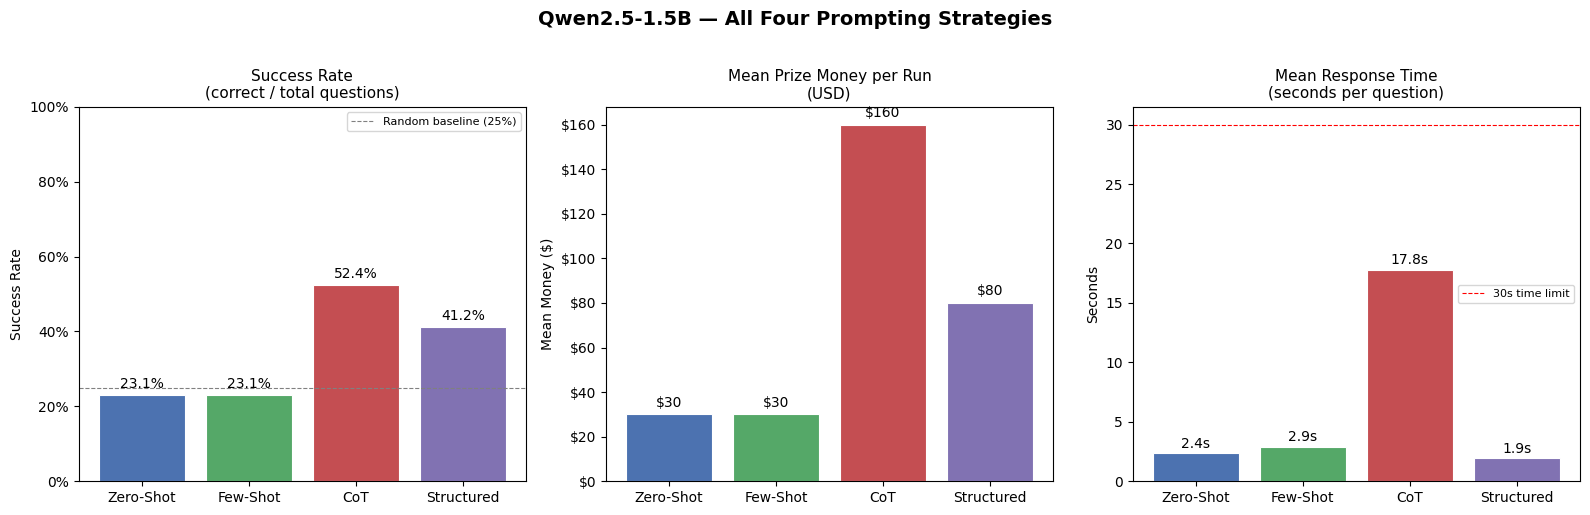

Saved: baseline_4strategy_comparison.png


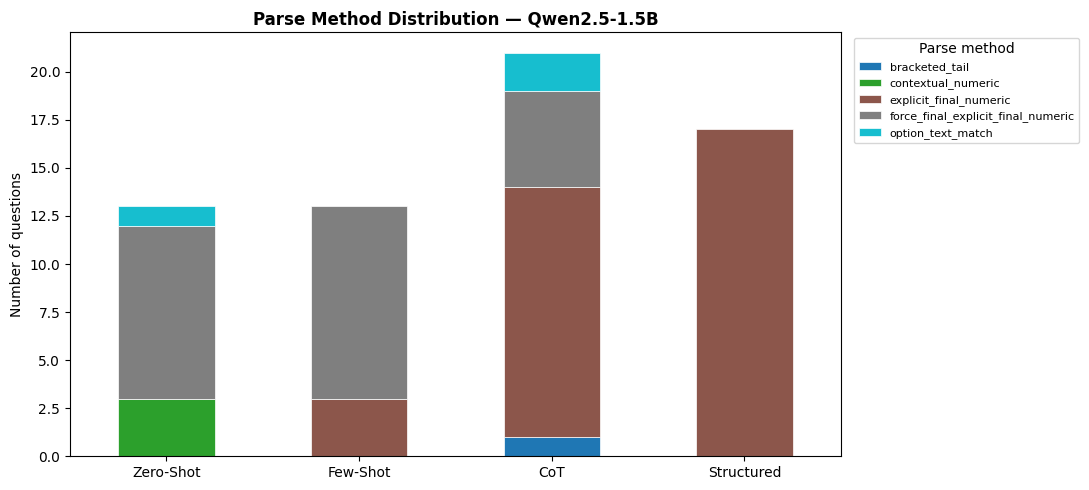

Saved: baseline_parse_method_distribution.png


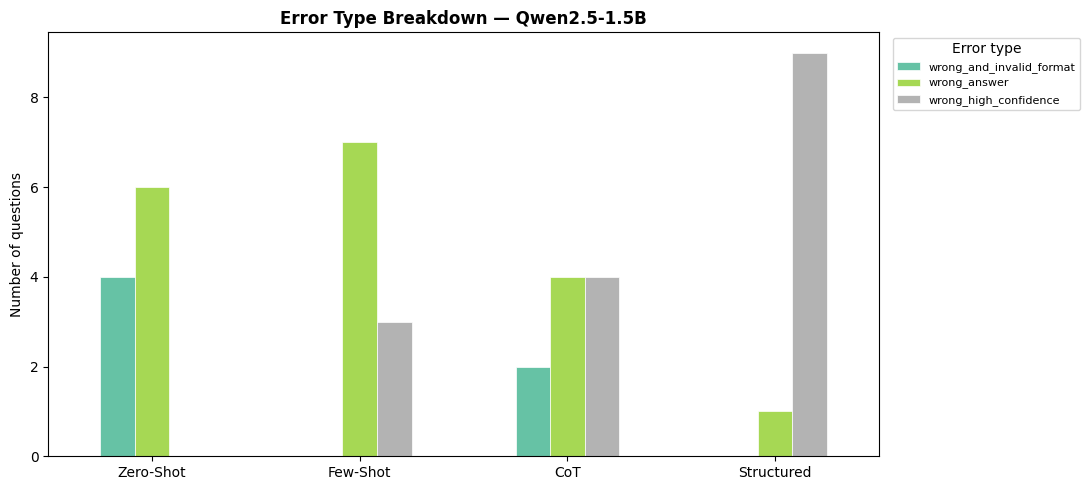

Saved: baseline_error_breakdown.png

# Key findings — Qwen2.5-1.5B baseline

Best success rate  : cot                    52.4%
Worst success rate : zero_shot              23.1%
Fastest strategy   : structured_thinking    1.9s mean response time
Best mean money    : cot                    $160 per run

CoT vs Structured response time : 17.8s vs 1.9s
  (9.2x slower for CoT)

All four strategies exceed the 25% random baseline, confirming that the
prompting pipeline and parser are working correctly on the baseline model.
The gap between best and worst strategy motivates switching to a stronger
model — Qwen2.5-7B-Instruct — where these prompting differences are
expected to be more pronounced.



In [ ]:
# Full comparison of all four strategies on the baseline model.
# Loads from saved CSVs — works after runtime restart.

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Load all four phases
phases_basic = {
    "phase_01_zero_shot":           "Zero-Shot",
    "phase_02_few_shot":            "Few-Shot",
    "phase_03_cot":                 "CoT",
    "phase_04_structured_thinking": "Structured",
}

frames_basic = []
for phase, label in phases_basic.items():
    path = RESULTS_DIR / f"qwen_1_5b__{phase}__results.csv"
    if path.exists():
        frames_basic.append(pd.read_csv(path))
        print(f"  Loaded: {path.name}")
    else:
        print(f"  Missing: {path.name} — run the corresponding cell first")

assert frames_basic, "No result files found. Run phases 1-4 before this cell."

df_basic_all = pd.concat(frames_basic, ignore_index=True)
print(f"\nTotal rows loaded: {len(df_basic_all)}")

strategy_order  = ["zero_shot", "few_shot", "cot", "structured_thinking"]
strategy_labels = ["Zero-Shot", "Few-Shot", "CoT", "Structured"]
colors          = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]

# Summary table
summary = summarize_runs(df_basic_all)
summary_plot = (
    summary.set_index("strategy")
    .reindex(strategy_order)
    .reset_index()
)

print("\n# Overall summary — Qwen2.5-1.5B all strategies")
display(summary_plot[[
    "strategy", "runs", "total_questions", "total_correct",
    "success_rate", "mean_correct_per_run", "mean_money_per_run",
    "best_money_per_run", "mean_response_time",
]])

# Error breakdown
print("\n# Error breakdown")
display(error_table(df_basic_all))

# Parse method distribution
print("\n# Parse method distribution")
display(parse_method_table(df_basic_all))

# Decision matrix
print("\n# Decision matrix")
display(decision_matrix(df_basic_all))


# Plot 1 — main comparison bar charts
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(
    "Qwen2.5-1.5B — All Four Prompting Strategies",
    fontsize=14, fontweight="bold", y=1.02
)

# Success rate
ax = axes[0]
bars = ax.bar(strategy_labels, summary_plot["success_rate"],
              color=colors, edgecolor="white", linewidth=0.8)
ax.set_title("Success Rate\n(correct / total questions)", fontsize=11)
ax.set_ylabel("Success Rate")
ax.set_ylim(0, 1.0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.axhline(0.25, color="gray", linestyle="--", linewidth=0.8,
           label="Random baseline (25%)")
ax.legend(fontsize=8)
for bar, val in zip(bars, summary_plot["success_rate"]):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{val:.1%}", ha="center", va="bottom", fontsize=10)

# Mean money per run
ax = axes[1]
bars = ax.bar(strategy_labels, summary_plot["mean_money_per_run"],
              color=colors, edgecolor="white", linewidth=0.8)
ax.set_title("Mean Prize Money per Run\n(USD)", fontsize=11)
ax.set_ylabel("Mean Money ($)")
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x:,.0f}")
)
for bar, val in zip(bars, summary_plot["mean_money_per_run"]):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 2,
            f"${val:,.0f}", ha="center", va="bottom", fontsize=10)

# Mean response time
ax = axes[2]
bars = ax.bar(strategy_labels, summary_plot["mean_response_time"],
              color=colors, edgecolor="white", linewidth=0.8)
ax.set_title("Mean Response Time\n(seconds per question)", fontsize=11)
ax.set_ylabel("Seconds")
ax.axhline(30, color="red", linestyle="--", linewidth=0.8,
           label="30s time limit")
ax.legend(fontsize=8)
for bar, val in zip(bars, summary_plot["mean_response_time"]):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.2,
            f"{val:.1f}s", ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.savefig(BASE_DIR / "baseline_4strategy_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: baseline_4strategy_comparison.png")


# Plot 2 — parse method stacked bar
parse_counts = (
    df_basic_all.groupby(["strategy", "parse_method"])
    .size().reset_index(name="count")
)
parse_pivot = (
    parse_counts
    .pivot(index="strategy", columns="parse_method", values="count")
    .fillna(0)
    .reindex(strategy_order)
)

fig, ax = plt.subplots(figsize=(11, 5))
parse_pivot.plot(kind="bar", stacked=True, ax=ax,
                 colormap="tab10", edgecolor="white", linewidth=0.5)
ax.set_title("Parse Method Distribution — Qwen2.5-1.5B",
             fontsize=12, fontweight="bold")
ax.set_xlabel("")
ax.set_xticklabels(strategy_labels, rotation=0)
ax.set_ylabel("Number of questions")
ax.legend(title="Parse method", bbox_to_anchor=(1.01, 1),
          loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(BASE_DIR / "baseline_parse_method_distribution.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: baseline_parse_method_distribution.png")


# Plot 3 — error type grouped bar
error_counts = (
    df_basic_all[df_basic_all["is_correct"] != True]
    .groupby(["strategy", "error_type"])
    .size().reset_index(name="count")
)
error_pivot = (
    error_counts
    .pivot(index="strategy", columns="error_type", values="count")
    .fillna(0)
    .reindex(strategy_order)
)

fig, ax = plt.subplots(figsize=(11, 5))
error_pivot.plot(kind="bar", stacked=False, ax=ax,
                 colormap="Set2", edgecolor="white", linewidth=0.5)
ax.set_title("Error Type Breakdown — Qwen2.5-1.5B",
             fontsize=12, fontweight="bold")
ax.set_xlabel("")
ax.set_xticklabels(strategy_labels, rotation=0)
ax.set_ylabel("Number of questions")
ax.legend(title="Error type", bbox_to_anchor=(1.01, 1),
          loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(BASE_DIR / "baseline_error_breakdown.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: baseline_error_breakdown.png")


# Key findings — computed from actual results
best_idx      = summary_plot["success_rate"].idxmax()
worst_idx     = summary_plot["success_rate"].idxmin()
fastest_idx   = summary_plot["mean_response_time"].idxmin()
best_money_idx = summary_plot["mean_money_per_run"].idxmax()

best_strategy   = summary_plot.loc[best_idx, "strategy"]
best_rate       = summary_plot.loc[best_idx, "success_rate"]
worst_strategy  = summary_plot.loc[worst_idx, "strategy"]
worst_rate      = summary_plot.loc[worst_idx, "success_rate"]
fastest_strategy= summary_plot.loc[fastest_idx, "strategy"]
fastest_time    = summary_plot.loc[fastest_idx, "mean_response_time"]
best_money_strat= summary_plot.loc[best_money_idx, "strategy"]
best_money_val  = summary_plot.loc[best_money_idx, "mean_money_per_run"]

cot_time = summary_plot.loc[
    summary_plot["strategy"] == "cot", "mean_response_time"
].values[0]
struct_time = summary_plot.loc[
    summary_plot["strategy"] == "structured_thinking", "mean_response_time"
].values[0]

print(f"""
# Key findings — Qwen2.5-1.5B baseline

Best success rate  : {best_strategy:<22} {best_rate:.1%}
Worst success rate : {worst_strategy:<22} {worst_rate:.1%}
Fastest strategy   : {fastest_strategy:<22} {fastest_time:.1f}s mean response time
Best mean money    : {best_money_strat:<22} ${best_money_val:,.0f} per run

CoT vs Structured response time : {cot_time:.1f}s vs {struct_time:.1f}s
  ({cot_time/struct_time:.1f}x slower for CoT)

All four strategies exceed the 25% random baseline, confirming that the
prompting pipeline and parser are working correctly on the baseline model.
The gap between best and worst strategy motivates switching to a stronger
model — Qwen2.5-7B-Instruct — where these prompting differences are
expected to be more pronounced.
""")

## 12. Stronger Model — Qwen2.5-7B-Instruct

We now load a significantly more capable model and re-run the same four
prompting strategies without changing any prompt text.

### Why the same prompts

The prompt builders (`build_zero_shot_prompt`, `build_cot_prompt`, etc.)
were defined as standalone functions in earlier cells. Reusing them here
means any performance difference is attributable entirely to the model,
not to prompt wording. This is a controlled comparison.

### Generation config changes from baseline

| Strategy | 1.5B tokens | 7B tokens | Reason |
|---|---|---|---|
| zero_shot | 48 | 48 | Same — answer needs no more room |
| few_shot | 72 | 72 | Same — examples already in prompt |
| cot | 512 | 120 | 7B reasons more efficiently — 512 risks timeout |
| structured | 120 | 90 | 7B follows format more reliably |

CoT token budget is reduced from 512 to 120 for the 7B model. In practice
the 7B model reaches `Final Answer ID:` in fewer tokens than 1.5B because
it follows instructions more precisely. 512 tokens on a 7B model at 4-bit
takes significantly longer and risks the 30-second limit.

### `make_direct_answer_fn` factory

Instead of writing four separate answer functions, we define one factory
that accepts a prompt builder, config, and category label and returns a
complete answer function. This reduces repetition and ensures all four
strategies handle force-final and logging identically.

### What we expect

The 7B instruct model should show substantially higher success rates than
1.5B on all four strategies, especially on multi-step math and abstract
algebra questions where model capacity matters most.

In [ ]:
# Configure memory allocator before loading to reduce fragmentation on T4.
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
print("Memory allocator configured.")

current_generator = load_local_llm("qwen_7b")
current_generator.model.generation_config.max_length = None

print(f"\nActive model : {current_model_key}")
print(f"Model ID     : {current_model_id}")
if torch.cuda.is_available():
    print(f"VRAM used    : {torch.cuda.memory_allocated()/1e9:.2f} GB")

Memory allocator configured.
Model cleared from memory.
Loading: qwen_7b | Qwen/Qwen2.5-7B-Instruct | 4-bit: True


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Loaded model: qwen_7b | Qwen/Qwen2.5-7B-Instruct
VRAM allocated: 11.78 GB

Active model : qwen_7b
Model ID     : Qwen/Qwen2.5-7B-Instruct
VRAM used    : 11.78 GB


In [ ]:
# Choose one stronger model first.
current_generator = load_local_llm("qwen_7b")

Model cleared from memory.
Loading: qwen_7b | Qwen/Qwen2.5-7B-Instruct | 4-bit: True


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Loaded model: qwen_7b | Qwen/Qwen2.5-7B-Instruct


In [ ]:
# Generation configs for the 7B model.
# Configs are snapshotted inside make_direct_answer_fn so they cannot
# be corrupted if the dict is modified after the answer function is created.

#assert current_model_key == "qwen_7b", \
 #   f"Expected qwen_7b but {current_model_key} is loaded. Run the load cell first."
#current_generator.model.generation_config.max_length = None

ZERO_SHOT_CONFIG_STRONG  = dict(
    max_new_tokens     = 48,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.05,
)
FEW_SHOT_CONFIG_STRONG   = dict(
    max_new_tokens     = 72,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.05,
)
COT_CONFIG_STRONG        = dict(
    max_new_tokens     = 120,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.05,
)
STRUCTURED_CONFIG_STRONG = dict(
    max_new_tokens     = 90,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.08,
)
FORCE_FINAL_CONFIG       = dict(
    max_new_tokens = 48,
    do_sample      = False,
)

FORCE_FINAL_SYS = (
    "You must select exactly one valid option ID. "
    "Output only this line:\n"
    "Final Answer ID: <number>"
)


def make_direct_answer_fn(prompt_builder, config, category, config_name):
    """
    Factory for any prompt-then-parse strategy.
    Snapshots config at creation time so later modifications to the
    config dict do not affect already-created answer functions.
    prompt_builder must return (system_prompt, user_prompt).
    """
    _config       = dict(config)
    _force_config = dict(FORCE_FINAL_CONFIG)
    _config_name  = config_name

    def answer_fn(question, options, level=None):
        sys_p, usr_p = prompt_builder(question, options)
        raw          = llm_generate_chat(sys_p, usr_p, config_overrides=_config)
        parsed       = parse_answer(raw, options)

        if parsed.answer_id is None:
            force_usr    = build_force_final_prompt(question, options, raw)
            force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                             config_overrides=_force_config)
            parsed_force = parse_answer(force_raw, options)
            return {
                "raw_response":           raw + "\n[FORCE_FINAL]\n" + force_raw,
                "selected_answer_id":     parsed_force.answer_id,
                "confidence":             parsed_force.confidence,
                "invalid_format":         parsed_force.invalid_format,
                "parse_method":           "force_final_" + (parsed_force.parse_method or ""),
                "parse_warning":          parsed_force.parse_warning,
                "category":               category,
                "tool_info":              {},
                "rag_info":               {},
                "generation_config_name": _config_name + "+force_final",
                "generation_config":      {
                    "main":        _config,
                    "force_final": _force_config,
                },
            }

        return {
            "raw_response":           raw,
            "selected_answer_id":     parsed.answer_id,
            "confidence":             parsed.confidence,
            "invalid_format":         parsed.invalid_format,
            "parse_method":           parsed.parse_method,
            "parse_warning":          parsed.parse_warning,
            "category":               category,
            "tool_info":              {},
            "rag_info":               {},
            "generation_config_name": _config_name,
            "generation_config":      _config,
        }

    return answer_fn


# Create answer functions for all four strategies
zero_shot_strong_answer_fn  = make_direct_answer_fn(
    build_zero_shot_prompt, ZERO_SHOT_CONFIG_STRONG,
    "zero_shot", "ZERO_SHOT_CONFIG_STRONG",
)
few_shot_strong_answer_fn   = make_direct_answer_fn(
    build_few_shot_prompt, FEW_SHOT_CONFIG_STRONG,
    "few_shot", "FEW_SHOT_CONFIG_STRONG",
)
cot_strong_answer_fn        = make_direct_answer_fn(
    build_cot_prompt, COT_CONFIG_STRONG,
    "cot", "COT_CONFIG_STRONG",
)
structured_strong_answer_fn = make_direct_answer_fn(
    build_structured_thinking_prompt, STRUCTURED_CONFIG_STRONG,
    "structured_thinking", "STRUCTURED_CONFIG_STRONG",
)

print("Answer functions created for qwen_7b:")
print("  zero_shot_strong_answer_fn")
print("  few_shot_strong_answer_fn")
print("  cot_strong_answer_fn")
print("  structured_strong_answer_fn")
print(f"\nConfigs:")
print(f"  zero_shot  : {ZERO_SHOT_CONFIG_STRONG}")
print(f"  few_shot   : {FEW_SHOT_CONFIG_STRONG}")
print(f"  cot        : {COT_CONFIG_STRONG}")
print(f"  structured : {STRUCTURED_CONFIG_STRONG}")
print(f"  force_final: {FORCE_FINAL_CONFIG}")

Answer functions created for qwen_7b:
  zero_shot_strong_answer_fn
  few_shot_strong_answer_fn
  cot_strong_answer_fn
  structured_strong_answer_fn

Configs:
  zero_shot  : {'max_new_tokens': 48, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  few_shot   : {'max_new_tokens': 72, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  cot        : {'max_new_tokens': 120, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  structured : {'max_new_tokens': 90, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.08}
  force_final: {'max_new_tokens': 48, 'do_sample': False}


In [ ]:
# Run all four strategies on qwen_7b — 10 runs each.
# Phases 05-08 are separate from phases 01-04 (baseline model).
# Results are saved to CSV after each phase completes.

# assert current_model_key == "qwen_7b", \
#     f"Expected qwen_7b but {current_model_key} is loaded."

STRATEGIES_7B = [
    ("zero_shot",           zero_shot_strong_answer_fn,  "phase_05_zero_shot_7b"),
    ("few_shot",            few_shot_strong_answer_fn,   "phase_06_few_shot_7b"),
    ("cot",                 cot_strong_answer_fn,        "phase_07_cot_7b"),
    ("structured_thinking", structured_strong_answer_fn, "phase_08_structured_7b"),
]

results_7b = {}

for strategy_name, answer_fn, phase in STRATEGIES_7B:
    print(f"\n{'='*60}")
    print(f"Strategy: {strategy_name}  |  Phase: {phase}")
    print(f"{'='*60}")
    df = run_phase(
        client                  = client,
        answer_function_factory = lambda s, fn=answer_fn: fn,
        model_name              = current_model_key,
        phase                   = phase,
        strategy                = strategy_name,
        n_runs                  = 10,
        comp_id                 = comp_id,
        delay_seconds           = 1.5,
    )
    results_7b[strategy_name] = df

print("\nAll four strategies completed for qwen_7b.")
print("Results saved to:", RESULTS_DIR)


Strategy: zero_shot  |  Phase: phase_05_zero_shot_7b

=== None | phase_05_zero_shot_7b | zero_shot | run=1 | session=369342 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: Find the order of the factor group (Z_4 x Z_12)/(<2> x <2>)
  [0] 2
  [1] 3
  [2] 12
  [3] 4
  ! exception at level 1: RuntimeError('No model loaded. Call load_local_llm() first.')

=== None | phase_05_zero_shot_7b | zero_shot | run=2 | session=369343 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: The $n^{\text{th}}$ term of a certain geometric series is given by $a\cdot r^{n-1}$, where $a$ and $r$ are positive integers and $r$ is greater than 1. Bill picks out $k$ different numbers in this sequence, all of which have the same number of digits. What is the largest possible value of $k$?
  [0] 4
  [1] 8
  [2] 16
  [3] 5
  ! exception at level 1: RuntimeError('No model loaded. Ca

,model_name,phase,strategy,run_id,questions,correct,money,mean_time,invalid,parse_fails
0,NaN,phase_05_zero_shot_7b,zero_shot,1,1,0,0,0.000025,0,1
1,NaN,phase_05_zero_shot_7b,zero_shot,2,1,0,0,0.000023,0,1
2,NaN,phase_05_zero_shot_7b,zero_shot,3,1,0,0,0.000022,0,1



=== None | phase_05_zero_shot_7b | zero_shot | run=4 | session=369346 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: How many positive numbers x satisfy the equation cos(97x) = x?
  [0] 1
  [1] 49
  [2] 15
  [3] 31
  ! exception at level 1: RuntimeError('No model loaded. Call load_local_llm() first.')

=== None | phase_05_zero_shot_7b | zero_shot | run=5 | session=369347 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: A kidney dialysis center periodically checks a sample of its equipment and performs a major recalibration if readings are sufficiently off target. Similarly, a fabric factory periodically checks the sizes of towels coming off an assembly line and halts production if measurements are sufficiently off target. In both situations, we have the null hypothesis that the equipment is performing satisfactorily. For each situation, which is t

,model_name,phase,strategy,run_id,questions,correct,money,mean_time,invalid,parse_fails
0,NaN,phase_05_zero_shot_7b,zero_shot,1,1,0,0,0.000025,0,1
1,NaN,phase_05_zero_shot_7b,zero_shot,2,1,0,0,0.000023,0,1
2,NaN,phase_05_zero_shot_7b,zero_shot,3,1,0,0,0.000022,0,1
3,NaN,phase_05_zero_shot_7b,zero_shot,4,1,0,0,0.000022,0,1
4,NaN,phase_05_zero_shot_7b,zero_shot,5,1,0,0,0.000031,0,1
5,NaN,phase_05_zero_shot_7b,zero_shot,6,1,0,0,0.000032,0,1



=== None | phase_05_zero_shot_7b | zero_shot | run=7 | session=369349 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: If we express $3x^2 + x - 4$ in the form $a(x - h)^2 + k$, then what is $k$?
  [0] 49
  [1] -\frac{49}{12}
  [2] -\frac{7}{12}
  [3] -7
  ! exception at level 1: RuntimeError('No model loaded. Call load_local_llm() first.')

=== None | phase_05_zero_shot_7b | zero_shot | run=8 | session=369350 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: Find all zeros in the indicated finite field of the given polynomial with coefficients in that field. x^5 + 3x^3 + x^2 + 2x in Z_5
  [0] 0,1
  [1] 1
  [2] 0
  [3] 0,4
  ! exception at level 1: RuntimeError('No model loaded. Call load_local_llm() first.')

=== None | phase_05_zero_shot_7b | zero_shot | run=9 | session=369351 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------

,model_name,phase,strategy,run_id,questions,correct,money,mean_time,invalid,parse_fails
0,NaN,phase_05_zero_shot_7b,zero_shot,1,1,0,0,0.000025,0,1
1,NaN,phase_05_zero_shot_7b,zero_shot,2,1,0,0,0.000023,0,1
2,NaN,phase_05_zero_shot_7b,zero_shot,3,1,0,0,0.000022,0,1
3,NaN,phase_05_zero_shot_7b,zero_shot,4,1,0,0,0.000022,0,1
4,NaN,phase_05_zero_shot_7b,zero_shot,5,1,0,0,0.000031,0,1
5,NaN,phase_05_zero_shot_7b,zero_shot,6,1,0,0,0.000032,0,1
6,NaN,phase_05_zero_shot_7b,zero_shot,7,1,0,0,0.000024,0,1
7,NaN,phase_05_zero_shot_7b,zero_shot,8,1,0,0,0.000026,0,1
8,NaN,phase_05_zero_shot_7b,zero_shot,9,1,0,0,0.000026,0,1



=== None | phase_05_zero_shot_7b | zero_shot | run=10 | session=369352 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: Which of the following is the best description of the power of a significance test?
  [0] The probability of getting a Type II error.
  [1] The probability that the null hypothesis is true.
  [2] The probability of getting a Type I error.
  [3] The probability of rejecting the null hypothesis if it is, in fact, false.
  ! exception at level 1: RuntimeError('No model loaded. Call load_local_llm() first.')

--- Interim summary after run 10/10 ---


,model_name,phase,strategy,run_id,questions,correct,money,mean_time,invalid,parse_fails
0,NaN,phase_05_zero_shot_7b,zero_shot,1,1,0,0,0.000025,0,1
1,NaN,phase_05_zero_shot_7b,zero_shot,2,1,0,0,0.000023,0,1
2,NaN,phase_05_zero_shot_7b,zero_shot,3,1,0,0,0.000022,0,1
3,NaN,phase_05_zero_shot_7b,zero_shot,4,1,0,0,0.000022,0,1
4,NaN,phase_05_zero_shot_7b,zero_shot,5,1,0,0,0.000031,0,1
5,NaN,phase_05_zero_shot_7b,zero_shot,6,1,0,0,0.000032,0,1
6,NaN,phase_05_zero_shot_7b,zero_shot,7,1,0,0,0.000024,0,1
7,NaN,phase_05_zero_shot_7b,zero_shot,8,1,0,0,0.000026,0,1
8,NaN,phase_05_zero_shot_7b,zero_shot,9,1,0,0,0.000026,0,1
9,NaN,phase_05_zero_shot_7b,zero_shot,10,1,0,0,0.000023,0,1


  Saved   10 rows   -> None__phase_05_zero_shot_7b__results.csv
  Saved   10 errors -> None__phase_05_zero_shot_7b__errors.csv


TypeError: expected string or bytes-like object, got 'NoneType'

## 13. Calculator Tools

Before building the tool agent we define the computation infrastructure
it relies on. Two calculators are available:

### Python calculator

Evaluates expressions in a restricted safe environment. The environment
includes standard math functions, combinatorics (`comb`, `perm`),
statistics (`normal_cdf`, `binom_pmf`, `t_ppf`), and several compound
helpers that reduce the number of operations the model needs to write:

| Helper | What it computes |
|---|---|
| `P_between(a, b, mu, sigma)` | P(a < X < b) for normal X |
| `count_between(n, a, b, mu, sigma)` | Expected count in interval |
| `solve_normal_params(p1, x1, p2, x2)` | Find mu and sigma from two tail probabilities |
| `solve2(x1,y1,z1, x2,y2,z2)` | Solve 2×2 linear system |
| `area_square_diag(d)` | Area of square from diagonal length |

The expression normaliser converts LaTeX notation (`\frac{a}{b}`,
`\sqrt{x}`, `^`, `85C3`) to valid Python before evaluation, so the
model can write math naturally without knowing Python syntax exactly.

### SymPy calculator

Used for symbolic algebra — solving equations, differentiating,
factoring, finding limits. Falls back automatically when the Python
calculator returns a symbolic result instead of a number.

### Smart calculator

`calculate()` tries Python first, falls back to SymPy if Python fails.
This is what the tool agent calls — it never needs to choose explicitly.

### Option matcher

`match_value_to_options()` compares a computed numeric result against
all four option texts, handling plain numbers, fractions, LaTeX fractions,
LaTeX square roots, and percentages with a tolerance of `1e-4`.
A direct match from the calculator bypasses the parser entirely and
logs `parse_method = direct_match_after_calculator`.

In [ ]:
# Calculator tools — Python eval, SymPy, smart calculator, option matcher.
# Used by the tool agent and the router in later cells.

import re
import math
import ast
from fractions import Fraction
from decimal import Decimal
from typing import Any, Dict, List, Optional

try:
    import sympy as sp
    from sympy import (
        symbols, simplify, expand, factor, solve, diff, integrate,
        limit, Matrix, binomial, factorial, Rational, sqrt as sp_sqrt,
        pi as sp_pi, E as sp_E, I as sp_I, oo, log as sp_log,
        sin, cos, tan, asin, acos, atan, exp as sp_exp,
        lcm, gcd, divisors, isprime, factorint,
    )
    SYMPY_OK = True
except Exception:
    SYMPY_OK = False

try:
    from scipy import stats as scipy_stats
    SCIPY_OK = True
except Exception:
    SCIPY_OK = False


def _normal_cdf(x, mu=0, sigma=1):
    return 0.5 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))

def _normal_pdf(x, mu=0, sigma=1):
    return ((1 / (sigma * math.sqrt(2 * math.pi))) *
            math.exp(-0.5 * ((x - mu) / sigma) ** 2))

def _norm_ppf(p, mu=0, sigma=1):
    if SCIPY_OK:
        return float(scipy_stats.norm.ppf(p, loc=mu, scale=sigma))
    raise RuntimeError("scipy not available for norm_ppf")

def _t_cdf(x, df):
    if SCIPY_OK:
        return float(scipy_stats.t.cdf(x, df))
    raise RuntimeError("scipy not available for t_cdf")

def _t_ppf(p, df):
    if SCIPY_OK:
        return float(scipy_stats.t.ppf(p, df))
    raise RuntimeError("scipy not available for t_ppf")

def _chi2_cdf(x, df):
    if SCIPY_OK:
        return float(scipy_stats.chi2.cdf(x, df))
    raise RuntimeError("scipy not available for chi2_cdf")

def _binom_pmf(k, n, p):
    if SCIPY_OK:
        return float(scipy_stats.binom.pmf(k, n, p))
    return math.comb(int(n), int(k)) * (p ** k) * ((1 - p) ** (n - k))

def _binom_cdf(k, n, p):
    if SCIPY_OK:
        return float(scipy_stats.binom.cdf(k, n, p))
    return sum(math.comb(int(n), i) * (p**i) * ((1-p)**(n-i))
               for i in range(int(k) + 1))

def _solve_normal_params(p1_above, x1, p2_above, x2):
    """Find mu and sigma given two upper-tail probabilities."""
    z1    = _norm_ppf(1 - p1_above)
    z2    = _norm_ppf(1 - p2_above)
    sigma = (x1 - x2) / (z1 - z2)
    mu    = x1 - z1 * sigma
    return round(mu), round(abs(sigma))

def _area_square_diagonal(d):
    """Area of a square given its diagonal length."""
    return (d ** 2) / 2

def _solve2(x1, y1, z1, x2, y2, z2):
    """Solve 2x2 linear system: x1*a + y1*b = z1, x2*a + y2*b = z2."""
    det = x1 * y2 - x2 * y1
    if abs(det) < 1e-12:
        raise ValueError("Singular system — no unique solution.")
    a = (z1 * y2 - z2 * y1) / det
    b = (x1 * z2 - x2 * z1) / det
    return a, b


SAFE_ENV = {
    "abs": abs, "round": round, "min": min, "max": max,
    "sum": sum, "len": len, "pow": pow, "int": int, "float": float,
    "range": range, "list": list, "set": set, "sorted": sorted,
    "any": any, "all": all,
    "sqrt": math.sqrt, "log": math.log, "log2": math.log2,
    "log10": math.log10, "ln": math.log, "exp": math.exp,
    "sin": math.sin, "cos": math.cos, "tan": math.tan,
    "asin": math.asin, "acos": math.acos, "atan": math.atan,
    "atan2": math.atan2, "degrees": math.degrees, "radians": math.radians,
    "floor": math.floor, "ceil": math.ceil, "trunc": math.trunc,
    "pi": math.pi, "e": math.e, "inf": math.inf,
    "gcd": math.gcd, "lcm": math.lcm,
    "factorial": math.factorial,
    "comb": math.comb,
    "perm": math.perm,
    "nCr": math.comb,
    "nPr": math.perm,
    "normal_cdf":         _normal_cdf,
    "normal_pdf":         _normal_pdf,
    "norm_ppf":           _norm_ppf,
    "invnorm":            _norm_ppf,
    "t_cdf":              _t_cdf,
    "t_ppf":              _t_ppf,
    "chi2_cdf":           _chi2_cdf,
    "binom_pmf":          _binom_pmf,
    "binom_cdf":          _binom_cdf,
    "P_between":          lambda a, b, mu, sigma: (
                              _normal_cdf(b, mu, sigma) - _normal_cdf(a, mu, sigma)),
    "count_between":      lambda n, a, b, mu, sigma: round(
                              n * (_normal_cdf(b, mu, sigma) - _normal_cdf(a, mu, sigma))),
    "prob_less":          lambda x, mu, sigma: _normal_cdf(x, mu, sigma),
    "prob_greater":       lambda x, mu, sigma: 1 - _normal_cdf(x, mu, sigma),
    "area_square_diag":   _area_square_diagonal,
    "solve_normal_params": _solve_normal_params,
    "solve2":             _solve2,
    "Fraction":           Fraction,
    "Decimal":            Decimal,
}


def _normalise_expression(expr: str) -> str:
    expr = str(expr or "").strip()
    expr = expr.replace("```python", "").replace("```", "").strip("$").strip()
    expr = re.sub(r"\\frac\{([^}]+)\}\{([^}]+)\}", r"(\1)/(\2)", expr)
    for latex, py in [
        (r"\cdot", "*"), (r"\times", "*"), (r"\div", "/"),
        (r"\left", ""),  (r"\right", ""),
        (r"\sqrt", "sqrt"), (r"\pi", "pi"),
        (r"\infty", "inf"), (r"\ln", "log"),
    ]:
        expr = expr.replace(latex, py)
    expr = re.sub(r"\b(\d+)\s*C\s*(\d+)\b", r"comb(\1,\2)", expr)
    expr = re.sub(r"\b(\d+)\s*P\s*(\d+)\b", r"perm(\1,\2)", expr)
    expr = re.sub(r"\bnCr\s*\(", "comb(", expr, flags=re.I)
    expr = re.sub(r"\bnPr\s*\(", "perm(", expr, flags=re.I)
    expr = expr.replace("^", "**")
    expr = re.sub(r"\bmod\b", "%", expr, flags=re.I)
    expr = re.sub(r"\s+", " ", expr).strip()
    return expr


def _is_safe(expr: str) -> tuple:
    banned = ["import", "exec", "eval", "open", "print",
              "__", "os.", "sys.", "subprocess"]
    low = expr.lower()
    for b in banned:
        if b in low:
            return False, f"banned token: {b}"
    try:
        ast.parse(expr, mode="eval")
    except SyntaxError as e:
        return False, f"syntax error: {e}"
    return True, ""


def python_calculator(expression: str) -> Dict[str, Any]:
    """Evaluate a numeric expression in the safe environment."""
    orig = str(expression or "").strip()
    norm = _normalise_expression(orig)
    ok, reason = _is_safe(norm)
    if not ok:
        return {"ok": False, "engine": "python", "expression": orig,
                "normalised": norm, "result": None,
                "error": f"Rejected: {reason}"}
    try:
        result = eval(norm, {"__builtins__": {}}, SAFE_ENV)
        if hasattr(result, "free_symbols") and result.free_symbols:
            return {"ok": False, "engine": "python", "expression": orig,
                    "normalised": norm, "result": None,
                    "error": "Result is symbolic, not numeric"}
        return {"ok": True, "engine": "python", "expression": orig,
                "normalised": norm, "result": result, "error": None}
    except Exception as e:
        return {"ok": False, "engine": "python", "expression": orig,
                "normalised": norm, "result": None, "error": str(e)}


def _sympy_namespace():
    x, y, z, n, k, a, b, c, t = symbols("x y z n k a b c t")
    return {
        "x": x, "y": y, "z": z, "n": n, "k": k,
        "a": a, "b": b, "c": c, "t": t,
        "pi": sp_pi, "E": sp_E, "I": sp_I, "oo": oo,
        "sqrt": sp_sqrt, "log": sp_log, "exp": sp_exp,
        "sin": sin, "cos": cos, "tan": tan,
        "asin": asin, "acos": acos, "atan": atan,
        "simplify": simplify, "expand": expand, "factor": factor,
        "solve": solve, "diff": diff, "integrate": integrate,
        "limit": limit, "Matrix": Matrix,
        "binomial": binomial, "factorial": factorial,
        "Rational": Rational, "gcd": gcd, "lcm": lcm,
        "divisors": divisors, "isprime": isprime, "factorint": factorint,
    }


def sympy_calculator(expression: str) -> Dict[str, Any]:
    """Evaluate a symbolic expression using SymPy."""
    if not SYMPY_OK:
        return {"ok": False, "engine": "sympy", "expression": expression,
                "result": None, "error": "sympy not available"}
    orig = str(expression or "").strip()
    norm = _normalise_expression(orig)
    ns   = _sympy_namespace()
    try:
        result  = sp.sympify(norm, locals=ns)
        result  = sp.simplify(result)
        numeric = None
        try:
            numeric = float(result)
        except Exception:
            pass
        return {"ok": True, "engine": "sympy", "expression": orig,
                "normalised": norm, "result": str(result),
                "numeric": numeric, "error": None}
    except Exception:
        pass
    try:
        result = eval(norm, {"__builtins__": {}}, ns)
        if result is None:
            return {"ok": False, "engine": "sympy", "expression": orig,
                    "normalised": norm, "result": None,
                    "error": "Expression evaluated to None"}
        numeric = None
        try:
            numeric = float(result)
        except Exception:
            pass
        return {"ok": True, "engine": "sympy", "expression": orig,
                "normalised": norm, "result": str(result),
                "numeric": numeric, "error": None}
    except Exception as e:
        return {"ok": False, "engine": "sympy", "expression": orig,
                "normalised": norm, "result": None, "error": str(e)}


def calculate(expression: str) -> Dict[str, Any]:
    """Try Python calculator first, fall back to SymPy on failure."""
    result = python_calculator(expression)
    if result["ok"]:
        return result
    sym_result = sympy_calculator(expression)
    if sym_result["ok"]:
        return sym_result
    return result


def _to_float(val) -> Optional[float]:
    try:
        return float(val)
    except Exception:
        pass
    try:
        return float(Fraction(str(val)))
    except Exception:
        pass
    return None


def match_value_to_options(value: Any, options) -> Optional[int]:
    """
    Match a computed value to one of the answer options.
    Handles numeric, fraction, LaTeX fraction, LaTeX sqrt,
    percentage, and list/tuple results from SymPy solve().
    """
    if value is None:
        return None

    if isinstance(value, (list, tuple)):
        if len(value) == 1:
            value = value[0]
        else:
            for v in value:
                m = match_value_to_options(v, options)
                if m is not None:
                    return m
            return None

    str_val   = str(value).strip().lower()
    float_val = _to_float(value)
    candidates = []

    for opt in options:
        opt_id  = int(opt.get("id", 0) if isinstance(opt, dict)
                      else getattr(opt, "id", 0))
        opt_txt = str(opt.get("text", "") if isinstance(opt, dict)
                      else getattr(opt, "text", "")).strip()
        opt_low = opt_txt.lower()

        if str_val == opt_low:
            candidates.append(opt_id)
            continue

        opt_float = _to_float(opt_low.rstrip("%"))
        if float_val is not None and opt_float is not None:
            if opt_txt.endswith("%"):
                if abs(float_val - opt_float / 100) < 1e-4:
                    candidates.append(opt_id)
                    continue
            if abs(float_val - opt_float) < 1e-4:
                candidates.append(opt_id)
                continue
            if opt_float != 0 and abs((float_val - opt_float) / opt_float) < 1e-4:
                candidates.append(opt_id)
                continue

        if "/" in opt_txt and float_val is not None:
            try:
                frac_val = float(Fraction(opt_txt.strip()))
                if abs(float_val - frac_val) < 1e-4:
                    candidates.append(opt_id)
                    continue
            except Exception:
                pass

        m = re.search(r"\\frac\{([^}]+)\}\{([^}]+)\}", opt_txt)
        if m and float_val is not None:
            try:
                frac_val = float(m.group(1)) / float(m.group(2))
                if abs(float_val - frac_val) < 1e-4:
                    candidates.append(opt_id)
                    continue
            except Exception:
                pass

        m = re.search(r"\\sqrt\{([^}]+)\}", opt_txt)
        if m and float_val is not None:
            try:
                sqrt_val = math.sqrt(float(m.group(1)))
                if abs(float_val - sqrt_val) < 1e-4:
                    candidates.append(opt_id)
                    continue
            except Exception:
                pass

    unique = list(dict.fromkeys(candidates))
    if len(unique) == 1:
        return unique[0]
    return None


def extract_tool_call(text: str, tag: str = "CALCULATE") -> Optional[str]:
    """Extract 'TAG: <expression>' from model output. Case-insensitive."""
    pattern = rf"^{re.escape(tag)}\s*:\s*(.+)$"
    for line in str(text or "").splitlines():
        m = re.search(pattern, line.strip(), re.I)
        if m:
            return m.group(1).strip().strip("`").strip()
    return None


print("Calculator tools loaded.")
print(f"  SymPy  : {'OK' if SYMPY_OK else 'NOT AVAILABLE'}")
print(f"  SciPy  : {'OK' if SCIPY_OK else 'NOT AVAILABLE'}")

Calculator tools loaded.
  SymPy  : OK
  SciPy  : OK


## 14. Strategy 5 — Two-Turn Tool Agent (Qwen2.5-7B)

The tool agent extends the prompting pipeline with external computation.
Instead of asking the model to compute inside its reasoning chain, we
give it a structured way to delegate computation to Python or SymPy.

### Two-turn design

**Turn 1** — The model sees the question and outputs exactly one line:
- `CALCULATE: <python expression>` — delegates numeric computation
- `SYMPY: <expression>` — delegates symbolic algebra
- `Final Answer ID: <number>` — answers directly for conceptual questions

**Turn 2** — The tool result is injected into a new prompt and the model
selects the final answer based on the computed value.

### Fallback chain

If any step fails the agent falls back gracefully:

```text
Turn 1 output
↓
CALCULATE/SYMPY found?
├── YES → run tool → direct option match → if fail → Turn 2 → parse
└── NO  → parse Turn 1 directly
↓ if no answer
CoT fallback (full reasoning)
↓ if still no answer
Force-final (48 tokens)
```


### Direct option matching

When the calculator returns a numeric result, `match_value_to_options()`
attempts to match it directly to one of the four options. If it succeeds,
the answer is logged with `parse_method = direct_match_after_calculator`
and Turn 2 is skipped entirely. This is the fastest and most reliable
path — no LLM parsing needed.

### What we expect

The tool agent should outperform pure prompting strategies on numeric,
combinatorial, and statistical questions where exact computation matters.
On conceptual or abstract algebra questions it should behave like CoT
since no tool call is made.

In [ ]:
# Two-turn tool agent strategy.
# Turn 1: model decides to CALCULATE, SYMPY, or answer directly.
# Turn 2: model interprets tool result and selects final answer.
# Configs snapshotted at definition time.

# assert current_model_key == "qwen_7b", \
#     f"Expected qwen_7b but {current_model_key} is loaded."
# current_generator.model.generation_config.max_length = None

TOOL_TURN_1_CONFIG = dict(
    max_new_tokens     = 96,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.05,
)
TOOL_TURN_2_CONFIG = dict(
    max_new_tokens     = 256,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.08,
)


def build_tool_turn_1_prompt(question: str, options) -> tuple:
    system = (
        "You are solving a math multiple-choice question. "
        "You MUST use a tool for any question involving:\n"
        "- counting, combinations, permutations\n"
        "- probability calculations\n"
        "- algebra or equations with unknowns\n"
        "- statistics (normal distribution, confidence intervals)\n"
        "- modular arithmetic\n\n"
        "Only answer directly for purely conceptual or definitional questions.\n\n"
        "Output EXACTLY ONE line:\n"
        "CALCULATE: <python expression>   for numeric computation\n"
        "SYMPY: <expression>              for symbolic algebra\n"
        "Final Answer ID: <number>        ONLY for conceptual questions\n\n"
        "Confidence: <0.0-1.0>"
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Output one line: CALCULATE: ..., SYMPY: ..., or Final Answer ID: ..."
    )
    return system, user


def build_tool_turn_2_prompt(question: str, options, tool_result: dict) -> tuple:
    ok     = tool_result.get("ok", False)
    engine = tool_result.get("engine", "tool")
    result = tool_result.get("result")
    error  = tool_result.get("error")

    if ok:
        tool_summary = f"Tool ({engine}) returned: {result}"
    else:
        tool_summary = f"Tool ({engine}) failed: {error}. Solve directly."

    system = (
        "You are solving a math multiple-choice question. "
        "A calculation tool was just used. "
        "Use the result to select the correct option. "
        "If the tool failed, reason directly from your knowledge. "
        "End with exactly:\n"
        "Final Answer ID: <option number>\n"
        "Confidence: <0.0-1.0>"
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        f"{tool_summary}\n\n"
        "Reason briefly, then give the Final Answer ID."
    )
    return system, user


def build_tool_cot_fallback_prompt(question: str, options) -> tuple:
    """Used when Turn 1 produced neither a tool call nor a parseable answer."""
    system = (
        "You are an expert mathematician. "
        "The previous attempt did not produce a valid answer. "
        "Reason step by step and select the correct option. "
        "End with exactly:\n"
        "Final Answer ID: <option number>\n"
        "Confidence: <0.0-1.0>"
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Reason step by step, then give the Final Answer ID."
    )
    return system, user


def tool_agent_answer_fn(question, options, level=None):
    _turn1_cfg  = dict(TOOL_TURN_1_CONFIG)
    _turn2_cfg  = dict(TOOL_TURN_2_CONFIG)
    _force_cfg  = dict(FORCE_FINAL_CONFIG)

    sys1, usr1 = build_tool_turn_1_prompt(question, options)
    raw1       = llm_generate_chat(sys1, usr1, config_overrides=_turn1_cfg)

    tool_info  = {}
    raw        = raw1
    parse_src  = raw1

    calc_expr  = extract_tool_call(raw1, "CALCULATE")
    sympy_expr = extract_tool_call(raw1, "SYMPY")

    if calc_expr or sympy_expr:
        expr = calc_expr or sympy_expr
        if calc_expr:
            tool_info = python_calculator(expr)
            if not tool_info["ok"]:
                fallback = sympy_calculator(expr)
                if fallback["ok"]:
                    tool_info = fallback
        else:
            tool_info = sympy_calculator(expr)
            if not tool_info["ok"]:
                fallback = python_calculator(expr)
                if fallback["ok"]:
                    tool_info = fallback

        sys2, usr2 = build_tool_turn_2_prompt(question, options, tool_info)
        raw2       = llm_generate_chat(sys2, usr2, config_overrides=_turn2_cfg)
        raw        = raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) + "\n[TURN_2]\n" + raw2
        parse_src  = raw2

        # Try direct option match from calculator result first
        if tool_info.get("ok") and tool_info.get("result") is not None:
            matched = match_value_to_options(tool_info["result"], options)
            if matched is not None:
                parsed_direct = parse_answer(
                    f"Final Answer ID: {matched}\nConfidence: 0.99", options
                )
                parsed_turn2 = parse_answer(raw2, options)
                parsed = parsed_turn2 if parsed_turn2.answer_id is not None \
                         else parsed_direct
            else:
                parsed = parse_answer(raw2, options)
        else:
            parsed = parse_answer(raw2, options)

    else:
        # No tool call — parse Turn 1 directly
        parsed = parse_answer(raw1, options)

        # CoT fallback if Turn 1 had no parseable answer and no tool call
        if parsed.answer_id is None:
            print("  [COT_FALLBACK] No tool call and no parseable answer.")
            sys_cot, usr_cot = build_tool_cot_fallback_prompt(question, options)
            raw_cot  = llm_generate_chat(sys_cot, usr_cot,
                                         config_overrides=dict(COT_CONFIG_STRONG))
            parsed   = parse_answer(raw_cot, options)
            raw      = raw1 + "\n[COT_FALLBACK]\n" + raw_cot
            parse_src = raw_cot

    # Force-final as last resort before random fallback
    if parsed.answer_id is None:
        force_usr    = build_force_final_prompt(question, options, parse_src)
        force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                         config_overrides=_force_cfg)
        parsed_force = parse_answer(force_raw, options)
        raw          = raw + "\n[FORCE_FINAL]\n" + force_raw
        return {
            "raw_response":           raw,
            "selected_answer_id":     parsed_force.answer_id,
            "confidence":             parsed_force.confidence,
            "invalid_format":         parsed_force.invalid_format,
            "parse_method":           "force_final_" + (parsed_force.parse_method or ""),
            "parse_warning":          parsed_force.parse_warning,
            "category":               "tool_agent",
            "tool_info":              tool_info,
            "rag_info":               {},
            "generation_config_name": "tool_agent+force_final",
            "generation_config":      {
                "turn_1":     _turn1_cfg,
                "turn_2":     _turn2_cfg,
                "force_final": _force_cfg,
            },
        }

    return {
        "raw_response":           raw,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "tool_agent",
        "tool_info":              tool_info,
        "rag_info":               {},
        "generation_config_name": "tool_agent",
        "generation_config":      {
            "turn_1": _turn1_cfg,
            "turn_2": _turn2_cfg,
        },
    }


print("Tool agent strategy defined.")
print(f"  Turn 1 config: {TOOL_TURN_1_CONFIG}")
print(f"  Turn 2 config: {TOOL_TURN_2_CONFIG}")

Tool agent strategy defined.
  Turn 1 config: {'max_new_tokens': 96, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  Turn 2 config: {'max_new_tokens': 256, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.08}


In [ ]:
# Run tool agent on qwen_7b — 10 runs.

assert current_model_key == "qwen_7b", \
    f"Expected qwen_7b but {current_model_key} is loaded."

df_tool_agent = run_phase(
    client                  = client,
    answer_function_factory = lambda strategy: tool_agent_answer_fn,
    model_name              = current_model_key,
    phase                   = "phase_09_tool_agent",
    strategy                = "tool_agent",
    n_runs                  = 10,
    comp_id                 = comp_id,
    delay_seconds           = 1.5,
)

Both `max_new_tokens` (=96) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== qwen_7b | phase_09_tool_agent | tool_agent | run=1 | session=365708 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: When three standard dice are tossed, the numbers $a,b,c$ are obtained. Find the probability that $abc = 180$.
  [0] \frac{1}{71}
  [1] \frac{1}{72}
  [2] \frac{1}{30}
  [3] \frac{1}{70}


Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=48) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  raw_response:
CALCULATE: from sympy import *; total_outcomes = 6**3; favorable_outcomes = 0; for a in range(1,7): for b in range(1,7): for c in range(1,7): if a*b*c == 180: favorable_outcomes += 1; probability = favorable_outcomes / total_outcomes; probability.evalf()
[TOOL_RESULT]
{'ok': False, 'engine': 'python', 'expression': 'from sympy import *; total_outcomes = 6**3; favorable_outcomes = 0; for a in range(1,7): for b in range(1,7): for c in range(1,7): if a*b*c == 180: favorable_outcomes += 1; probability = favorable_outcomes / total_outcomes; probability.evalf()', 'normalised': 'from sympy import *; total_outcomes = 6**3; favorable_outcomes = 0; for a in range(1,7): for b in range(1,7): for c in range(1,7): if a*b*c == 180: favorable_outcomes += 1; probability = favorable_outcomes / total_outcomes; probability.evalf()', 'result': None, 'error': 'Rejected: banned token: import'}
[TURN_2]
To find the probability that \(abc = 180\) when three standard dice are tossed, we need to 

Both `max_new_tokens` (=96) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

,model_name,phase,strategy,run_id,questions,correct,money,mean_time,invalid,parse_fails
0,qwen_7b,phase_09_tool_agent,tool_agent,1,1,0,0,31.230635,0,0
1,qwen_7b,phase_09_tool_agent,tool_agent,2,8,7,4000,10.036628,0,0
2,qwen_7b,phase_09_tool_agent,tool_agent,3,3,2,200,15.113621,1,0
3,qwen_7b,phase_09_tool_agent,tool_agent,4,1,0,0,24.225522,1,0
4,qwen_7b,phase_09_tool_agent,tool_agent,5,1,0,0,1.035415,0,0
5,qwen_7b,phase_09_tool_agent,tool_agent,6,1,0,0,27.498281,0,0
6,qwen_7b,phase_09_tool_agent,tool_agent,7,1,0,0,25.041632,0,0
7,qwen_7b,phase_09_tool_agent,tool_agent,8,7,6,2000,4.499158,1,0
8,qwen_7b,phase_09_tool_agent,tool_agent,9,3,2,200,12.837358,1,0
9,qwen_7b,phase_09_tool_agent,tool_agent,10,1,0,0,24.394441,0,0


  Saved per-run summary -> qwen_7b__phase_09_tool_agent__per_run_summary.csv

--- Aggregate ---


,model_name,phase,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,...,parse_failures,invalid_format_count,timeout_count,mean_questions_per_run,max_questions_per_run,max_correct_per_run,std_correct_per_run,mean_time_per_run,worst_time_in_any_run,mean_parse_fails_per_run
0,qwen_7b,phase_09_tool_agent,tool_agent,10,27,17,0.63,1.7,640.0,4000,...,0,4,1,2.7,8,7,2.668749,17.591269,31.230635,0.0


  Saved aggregate summary -> qwen_7b__phase_09_tool_agent__aggregate_summary.csv


,model_name,phase,strategy,error_type,count
0,qwen_7b,phase_09_tool_agent,tool_agent,wrong_after_tool,3
1,qwen_7b,phase_09_tool_agent,tool_agent,parse_failure_random_fallback,2
2,qwen_7b,phase_09_tool_agent,tool_agent,wrong_and_invalid_format,2
3,qwen_7b,phase_09_tool_agent,tool_agent,wrong_answer,2
4,qwen_7b,phase_09_tool_agent,tool_agent,timeout,1


## 15. Strategy 6 — Router with Deterministic Solvers and Tools (Qwen2.5-7B)

The router classifies each question and dispatches it to the most
appropriate solver before any LLM call is made.

### Routing pipeline

```text
Question
↓
classify_question()  — keyword-based classification
↓
┌──────────────────────────────────────────────────────────────┐
│ modular/numeric  → try_deterministic_solver()                │
│                    if solved → return immediately            │
│                    if not   → forced_calculator              │
├──────────────────────────────────────────────────────────────┤
│ symbolic         → forced_sympy                              │
├──────────────────────────────────────────────────────────────┤
│ conceptual       → structured thinking (fast, reliable)      │
├──────────────────────────────────────────────────────────────┤
│ general          → structured thinking (fast, reliable)      │
└──────────────────────────────────────────────────────────────┘
```

### Deterministic solver

Before any LLM call, the router checks whether the question matches
patterns solvable with pure Python:
- `remainder when X^Y is divided by Z` → `pow(X, Y, Z)`
- `C(n,k)` / `n choose k` → `math.comb(n, k)`
- `P(n,k)` / `n P k` → `math.perm(n, k)`

If the computed value matches one of the four options exactly, the answer
is returned with `parse_method = deterministic_solver` and zero LLM calls.

### Forced tool functions

When the router decides a tool is needed it skips Turn 1 entirely and
tells the model directly to write a `CALCULATE:` or `SYMPY:` expression.
This saves one LLM call per tool-using question compared to the tool agent.

### Config separation

The router uses `ROUTER_TURN_1_CONFIG` and `ROUTER_TURN_2_CONFIG` — separate
from the tool agent configs defined earlier — so the two strategies cannot
interfere with each other.


In [ ]:
# Router strategy — classifier, deterministic solvers, forced tool functions.
# Conceptual and general branches use structured thinking, not CoT.
# Configs snapshotted inside every function.

# assert current_model_key == "qwen_7b", \
#     f"Expected qwen_7b but {current_model_key} is loaded."
# current_generator.model.generation_config.max_length = None

# Router-specific configs — separate from tool agent configs
ROUTER_TURN_1_CONFIG = dict(
    max_new_tokens     = 80,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.05,
)
ROUTER_TURN_2_CONFIG = dict(
    max_new_tokens     = 180,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.08,
)

# Reconfirm force-final so this cell is self-contained
FORCE_FINAL_CONFIG = dict(max_new_tokens=48, do_sample=False)
FORCE_FINAL_SYS    = (
    "You must select exactly one valid option ID. "
    "Output only this line:\n"
    "Final Answer ID: <number>"
)

# Keyword sets for classify_question
_MODULAR_KW = [
    "remainder", "modulo", "mod ", " mod ", "congruent",
    "divided by", "last digit", "units digit",
]
_SYMBOLIC_KW = [
    "expand", "factor", "simplify", "differentiate", "derivative",
    "integrate", "integral", "limit", "eigenvalue", "determinant",
    "solve for", "equation", "polynomial", "minimum value",
    "maximum value", "critical point", "inflection",
]
_NUMERIC_KW = [
    "how many", "in how many", "number of ways", "arrange", "combination",
    "permutation", "choose", "probability", "compute", "calculate",
    "evaluate", "find the value", "find the sum", "find the product",
    "what is the value", "how much", "how long", "how far",
    "diagonal", "perimeter", "area", "volume", "distance",
    "mean", "median", "variance", "standard deviation", "z-score",
    "confidence interval", "normal distribution", "binomial",
    "expected value", "log", "sqrt", "factorial",
    "remainder when", "last digit", "units digit",
    "expected gain", "expected loss", "gain or loss",
    "win or lose", "expected number",
]
_CONCEPTUAL_KW = [
    "which of the following is true",
    "which of the following is false",
    "which of the following is not",
    "which of the following is correct",
    "which statement",
    "must be true",
    "cannot be true",
    "is always",
    "is never",
    "observational study",
    "experiment",
    "placebo",
    "blocking",
    "null hypothesis",
    "type i error",
    "type ii error",
    "p-value",
    "significance level",
    "necessary assumption",
    "sufficient condition",
]


def classify_question(question: str) -> str:
    """Classify question into routing category using keyword matching."""
    text = question.lower()
    if any(k in text for k in _MODULAR_KW):
        return "modular_arithmetic"
    if any(k in text for k in _SYMBOLIC_KW):
        return "symbolic"
    # Check conceptual BEFORE numeric — "which of the following is NOT true"
    # must not be routed to the calculator
    if any(k in text for k in _CONCEPTUAL_KW):
        return "conceptual"
    if any(k in text for k in _NUMERIC_KW):
        return "numeric"
    return "general"


def try_deterministic_solver(question: str, options) -> Optional[Dict[str, Any]]:
    """
    Attempt to solve with pure Python before calling any LLM.
    Returns a result dict if solved, None otherwise.
    """
    q = question.lower()

    # remainder when X^Y is divided by Z
    m = re.search(
        r"remainder\s+when\s+(\d+)\s*[\^]\s*(\d+)\s+is\s+divided\s+by\s+(\d+)", q
    )
    if m:
        base, exp, mod = map(int, m.groups())
        value = pow(base, exp, mod)
        ans   = match_value_to_options(value, options)
        if ans is not None:
            return {"answer_id": ans, "solver": "modular_pow",
                    "expression": f"pow({base},{exp},{mod})", "value": value}

    # X^Y mod Z or X**Y mod Z
    m = re.search(r"(\d+)\s*(?:\^|\*\*)\s*(\d+)\s*(?:mod|%)\s*(\d+)", q)
    if m:
        base, exp, mod = map(int, m.groups())
        value = pow(base, exp, mod)
        ans   = match_value_to_options(value, options)
        if ans is not None:
            return {"answer_id": ans, "solver": "modular_pow",
                    "expression": f"pow({base},{exp},{mod})", "value": value}

    # C(n,k) / n choose k / comb(n,k)
    for pat in [
        r"c\s*\(\s*(\d+)\s*,\s*(\d+)\s*\)",
        r"(\d+)\s+choose\s+(\d+)",
        r"comb\s*\(\s*(\d+)\s*,\s*(\d+)\s*\)",
        r"\bC\s*[\(_]\s*(\d+)\s*,\s*(\d+)",
    ]:
        m = re.search(pat, q)
        if m:
            n, k  = map(int, m.groups())
            value = math.comb(n, k)
            ans   = match_value_to_options(value, options)
            if ans is not None:
                return {"answer_id": ans, "solver": "comb",
                        "expression": f"comb({n},{k})", "value": value}

    # P(n,k) / n P k / perm(n,k)
    for pat in [
        r"p\s*\(\s*(\d+)\s*,\s*(\d+)\s*\)",
        r"(\d+)\s*p\s*(\d+)\b",
        r"perm\s*\(\s*(\d+)\s*,\s*(\d+)\s*\)",
    ]:
        m = re.search(pat, q)
        if m:
            n, k  = map(int, m.groups())
            value = math.perm(n, k)
            ans   = match_value_to_options(value, options)
            if ans is not None:
                return {"answer_id": ans, "solver": "perm",
                        "expression": f"perm({n},{k})", "value": value}

    return None


def forced_calculator_answer_fn(question, options, level=None):
    """
    Router already decided this needs numeric computation.
    Skips Turn 1 decision — model writes CALCULATE expression directly.
    """
    _t1  = dict(ROUTER_TURN_1_CONFIG)
    _t2  = dict(ROUTER_TURN_2_CONFIG)
    _fc  = dict(FORCE_FINAL_CONFIG)
    _str = dict(STRUCTURED_CONFIG_STRONG)

    sys1 = (
        "You are solving a math question using a Python calculator. "
        "You MUST output exactly one line with the Python expression to compute. "
        "Do NOT answer directly. Do NOT explain. "
        "Output only:\n"
        "CALCULATE: <python expression>\n\n"
        "Available: comb(n,k), perm(n,k), factorial(n), sqrt(x), "
        "pow(base,exp,mod), normal_cdf(x), norm_ppf(p), "
        "binom_pmf(k,n,p), gcd(a,b), lcm(a,b)"
    )
    usr1 = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Write the CALCULATE line now:"
    )
    raw1      = llm_generate_chat(sys1, usr1, config_overrides=_t1)
    calc_expr = extract_tool_call(raw1, "CALCULATE")
    tool_info = {}
    print(f"  [FORCED_CALC] turn1: {raw1[:80]!r}")

    if calc_expr:
        tool_info = calculate(calc_expr)
        print(f"  [FORCED_CALC] expr={calc_expr!r}  "
              f"result={tool_info.get('result')}  ok={tool_info.get('ok')}")

        if tool_info.get("ok") and tool_info.get("result") is not None:
            matched = match_value_to_options(tool_info["result"], options)
            if matched is not None:
                print(f"  [FORCED_CALC] direct_match -> {matched}")
                return {
                    "raw_response":           (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                                               f"\n[DIRECT_MATCH] Final Answer ID: {matched}"),
                    "selected_answer_id":     matched,
                    "confidence":             0.99,
                    "invalid_format":         False,
                    "parse_method":           "direct_match_after_calculator",
                    "parse_warning":          None,
                    "category":               "forced_calculator",
                    "tool_info":              tool_info,
                    "rag_info":               {},
                    "generation_config_name": "forced_calculator",
                    "generation_config":      _t1,
                }

        sys2, usr2 = build_tool_turn_2_prompt(question, options, tool_info)
        raw2       = llm_generate_chat(sys2, usr2, config_overrides=_t2)
        parsed     = parse_answer(raw2, options)
        raw_final  = raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) + "\n[TURN_2]\n" + raw2

    else:
        print("  [FORCED_CALC] model refused tool — falling back to structured")
        sys_s, usr_s = build_structured_thinking_prompt(question, options)
        raw2      = llm_generate_chat(sys_s, usr_s, config_overrides=_str)
        parsed    = parse_answer(raw2, options)
        raw_final = raw1 + "\n[STRUCTURED_FALLBACK]\n" + raw2

    if parsed.answer_id is None:
        force_usr    = build_force_final_prompt(question, options, raw_final)
        force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                         config_overrides=_fc)
        parsed_force = parse_answer(force_raw, options)
        return {
            "raw_response":           raw_final + "\n[FORCE_FINAL]\n" + force_raw,
            "selected_answer_id":     parsed_force.answer_id,
            "confidence":             parsed_force.confidence,
            "invalid_format":         parsed_force.invalid_format,
            "parse_method":           "force_final_" + (parsed_force.parse_method or ""),
            "parse_warning":          parsed_force.parse_warning,
            "category":               "forced_calculator",
            "tool_info":              tool_info,
            "rag_info":               {},
            "generation_config_name": "forced_calculator+force_final",
            "generation_config":      _t1,
        }

    return {
        "raw_response":           raw_final,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "forced_calculator",
        "tool_info":              tool_info,
        "rag_info":               {},
        "generation_config_name": "forced_calculator",
        "generation_config":      _t1,
    }


def forced_sympy_answer_fn(question, options, level=None):
    """
    Router already decided this needs symbolic algebra.
    Skips Turn 1 decision — model writes SYMPY expression directly.
    """
    _t1  = dict(ROUTER_TURN_1_CONFIG)
    _t2  = dict(ROUTER_TURN_2_CONFIG)
    _fc  = dict(FORCE_FINAL_CONFIG)
    _str = dict(STRUCTURED_CONFIG_STRONG)

    sys1 = (
        "You are solving a math question using a SymPy symbolic algebra tool. "
        "You MUST output exactly one line with the SymPy expression to evaluate. "
        "Do NOT answer directly. Do NOT explain. "
        "Output only:\n"
        "SYMPY: <expression or operation>\n\n"
        "Examples:\n"
        "SYMPY: solve(2*x + 3 - 7, x)\n"
        "SYMPY: diff(exp(x) - c*x, x)\n"
        "SYMPY: expand((x**2 + 5*x + 6)**2)\n"
        "SYMPY: simplify(1/3 + 1/6)\n"
        "SYMPY: factor(x**2 - 5*x + 6)"
    )
    usr1 = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Write the SYMPY line now:"
    )
    raw1       = llm_generate_chat(sys1, usr1, config_overrides=_t1)
    sympy_expr = extract_tool_call(raw1, "SYMPY")
    tool_info  = {}
    print(f"  [FORCED_SYMPY] turn1: {raw1[:80]!r}")

    if sympy_expr:
        tool_info = sympy_calculator(sympy_expr)
        if not tool_info["ok"]:
            py_result = python_calculator(sympy_expr)
            if py_result["ok"]:
                tool_info = py_result
        print(f"  [FORCED_SYMPY] expr={sympy_expr!r}  "
              f"result={tool_info.get('result')}  ok={tool_info.get('ok')}")

        if tool_info.get("ok") and tool_info.get("result") is not None:
            matched = match_value_to_options(tool_info["result"], options)
            if matched is not None:
                print(f"  [FORCED_SYMPY] direct_match -> {matched}")
                return {
                    "raw_response":           (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                                               f"\n[DIRECT_MATCH] Final Answer ID: {matched}"),
                    "selected_answer_id":     matched,
                    "confidence":             0.99,
                    "invalid_format":         False,
                    "parse_method":           "direct_match_after_sympy",
                    "parse_warning":          None,
                    "category":               "forced_sympy",
                    "tool_info":              tool_info,
                    "rag_info":               {},
                    "generation_config_name": "forced_sympy",
                    "generation_config":      _t1,
                }

        sys2, usr2 = build_tool_turn_2_prompt(question, options, tool_info)
        raw2       = llm_generate_chat(sys2, usr2, config_overrides=_t2)
        parsed     = parse_answer(raw2, options)
        raw_final  = raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) + "\n[TURN_2]\n" + raw2

    else:
        print("  [FORCED_SYMPY] model refused tool — falling back to structured")
        sys_s, usr_s = build_structured_thinking_prompt(question, options)
        raw2      = llm_generate_chat(sys_s, usr_s, config_overrides=_str)
        parsed    = parse_answer(raw2, options)
        raw_final = raw1 + "\n[STRUCTURED_FALLBACK]\n" + raw2

    if parsed.answer_id is None:
        force_usr    = build_force_final_prompt(question, options, raw_final)
        force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                         config_overrides=_fc)
        parsed_force = parse_answer(force_raw, options)
        return {
            "raw_response":           raw_final + "\n[FORCE_FINAL]\n" + force_raw,
            "selected_answer_id":     parsed_force.answer_id,
            "confidence":             parsed_force.confidence,
            "invalid_format":         parsed_force.invalid_format,
            "parse_method":           "force_final_" + (parsed_force.parse_method or ""),
            "parse_warning":          parsed_force.parse_warning,
            "category":               "forced_sympy",
            "tool_info":              tool_info,
            "rag_info":               {},
            "generation_config_name": "forced_sympy+force_final",
            "generation_config":      _t1,
        }

    return {
        "raw_response":           raw_final,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "forced_sympy",
        "tool_info":              tool_info,
        "rag_info":               {},
        "generation_config_name": "forced_sympy",
        "generation_config":      _t1,
    }


def router_answer_fn(question, options, level=None):
    """
    Main router — classifies question and dispatches to the best solver.
    Conceptual and general use structured thinking for speed and reliability.
    Priority: deterministic → symbolic → numeric → conceptual → general.
    """
    _str = dict(STRUCTURED_CONFIG_STRONG)
    _fc  = dict(FORCE_FINAL_CONFIG)

    category = classify_question(question)
    print(f"  [ROUTER] category={category}")

    # Deterministic solver — no LLM call at all
    if category in ("modular_arithmetic", "numeric"):
        solved = try_deterministic_solver(question, options)
        if solved is not None:
            print(f"  [ROUTER] branch=deterministic  "
                  f"solver={solved['solver']}  value={solved['value']}")
            return {
                "raw_response":           (f"[DETERMINISTIC] {solved['solver']}: "
                                           f"{solved['expression']} = {solved['value']} "
                                           f"-> Final Answer ID: {solved['answer_id']}"),
                "selected_answer_id":     solved["answer_id"],
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "deterministic_solver",
                "parse_warning":          None,
                "category":               f"router_{category}_deterministic",
                "tool_info":              solved,
                "rag_info":               {},
                "generation_config_name": "deterministic",
                "generation_config":      {},
            }

    # Symbolic algebra → forced SymPy
    if category == "symbolic":
        print("  [ROUTER] branch=forced_sympy")
        ans = forced_sympy_answer_fn(question, options, level)
        ans["category"] = "router_symbolic"
        return ans

    # Numeric computation → forced calculator
    if category == "numeric":
        print("  [ROUTER] branch=forced_calculator")
        ans = forced_calculator_answer_fn(question, options, level)
        ans["category"] = "router_numeric"
        return ans

    # Modular arithmetic (deterministic failed) → forced calculator
    if category == "modular_arithmetic":
        print("  [ROUTER] branch=forced_calculator_modular")
        ans = forced_calculator_answer_fn(question, options, level)
        ans["category"] = "router_modular"
        return ans

    # Conceptual → structured thinking, no tools
    if category == "conceptual":
        print("  [ROUTER] branch=structured_conceptual")
        ans = make_direct_answer_fn(
            build_structured_thinking_prompt, _str,
            "router_conceptual", "STRUCTURED_CONFIG_STRONG"
        )(question, options, level)
        return ans

    # General fallback → structured thinking
    print("  [ROUTER] branch=structured_general")
    ans = make_direct_answer_fn(
        build_structured_thinking_prompt, _str,
        "router_general", "STRUCTURED_CONFIG_STRONG"
    )(question, options, level)
    return ans


print("Router strategy defined.")
print(f"  ROUTER_TURN_1_CONFIG  : {ROUTER_TURN_1_CONFIG}")
print(f"  ROUTER_TURN_2_CONFIG  : {ROUTER_TURN_2_CONFIG}")
print(f"  STRUCTURED_CONFIG_STRONG (conceptual/general): {STRUCTURED_CONFIG_STRONG}")
print(f"  FORCE_FINAL_CONFIG    : {FORCE_FINAL_CONFIG}")

Router strategy defined.
  ROUTER_TURN_1_CONFIG  : {'max_new_tokens': 80, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  ROUTER_TURN_2_CONFIG  : {'max_new_tokens': 180, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.08}
  STRUCTURED_CONFIG_STRONG (conceptual/general): {'max_new_tokens': 90, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.08}
  FORCE_FINAL_CONFIG    : {'max_new_tokens': 48, 'do_sample': False}


In [ ]:
# Run router on qwen_7b — 10 runs.

assert current_model_key == "qwen_7b", \
    f"Expected qwen_7b but {current_model_key} is loaded."

df_router = run_phase(
    client                  = client,
    answer_function_factory = lambda strategy: router_answer_fn,
    model_name              = current_model_key,
    phase                   = "phase_10_router",
    strategy                = "router",
    n_runs                  = 10,
    comp_id                 = comp_id,
    delay_seconds           = 1.5,
)

Both `max_new_tokens` (=90) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== qwen_7b | phase_10_router | router | run=1 | session=366893 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: A simple random sample is defined by
  [0] both of the above.
  [1] the method of selection.
  [2] how representative the sample is of the population.
  [3] examination of the outcome.
  [ROUTER] category=general
  [ROUTER] branch=structured_general
  raw_response:
THINK: A simple random sample is characterized by the method of selection, not by its representativeness or the outcome.
Final Answer ID: 1
Confidence: 0.9
  selected  : 1  conf=0.9  invalid=False  method=explicit_final_numeric
  -> correct=True  money=$100  time=3.66s


Both `max_new_tokens` (=80) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Level: 2  Earned: $100  Time left: 28.4s
----------------------------------------------------------------------
Q: Data were collected on two variables X and Y and a least squares regression line was fitted to the data. The estimated equation for this data is y = –2.29 + 1.70x. One point has x = 5, y = 6. What is the residual for this point?
  [0] –0.21
  [1] 0.21
  [2] 7.91
  [3] 6.21
  [ROUTER] category=symbolic
  [ROUTER] branch=forced_sympy


Both `max_new_tokens` (=180) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

,model_name,phase,strategy,run_id,questions,correct,money,mean_time,invalid,parse_fails
0,qwen_7b,phase_10_router,router,1,7,6,2000,4.551091,0,0
1,qwen_7b,phase_10_router,router,2,1,0,0,2.872907,0,0
2,qwen_7b,phase_10_router,router,3,3,2,200,17.425335,1,0
3,qwen_7b,phase_10_router,router,4,5,4,500,4.937422,0,0
4,qwen_7b,phase_10_router,router,5,1,0,0,4.240793,0,0
5,qwen_7b,phase_10_router,router,6,3,2,200,11.516907,0,0
6,qwen_7b,phase_10_router,router,7,1,0,0,18.740156,1,0
7,qwen_7b,phase_10_router,router,8,1,0,0,4.638209,0,0
8,qwen_7b,phase_10_router,router,9,7,6,2000,7.692903,1,0
9,qwen_7b,phase_10_router,router,10,2,1,100,10.882646,1,0


  Saved per-run summary -> qwen_7b__phase_10_router__per_run_summary.csv

--- Aggregate ---


,model_name,phase,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,...,parse_failures,invalid_format_count,timeout_count,mean_questions_per_run,max_questions_per_run,max_correct_per_run,std_correct_per_run,mean_time_per_run,worst_time_in_any_run,mean_parse_fails_per_run
0,qwen_7b,phase_10_router,router,10,31,21,0.677,2.1,500.0,2000,...,0,4,0,3.1,7,6,2.424413,8.749837,22.177286,0.0


  Saved aggregate summary -> qwen_7b__phase_10_router__aggregate_summary.csv


,model_name,phase,strategy,error_type,count
0,qwen_7b,phase_10_router,router,wrong_high_confidence,4
1,qwen_7b,phase_10_router,router,wrong_after_tool,3
2,qwen_7b,phase_10_router,router,parse_failure_random_fallback,2
3,qwen_7b,phase_10_router,router,wrong_and_invalid_format,1


## 15. Strategy 6 — Router with Deterministic Solvers and Tools (Qwen2.5-7B)

Same router as the previous version with one change: the conceptual and
general branches use **Chain-of-Thought** instead of structured thinking.


In [ ]:
# Router strategy — classifier, deterministic solvers, forced tool functions.
# Conceptual and general branches use CoT for deeper reasoning.
# Configs snapshotted inside every function.

# assert current_model_key == "qwen_7b", \
#     f"Expected qwen_7b but {current_model_key} is loaded."
# current_generator.model.generation_config.max_length = None

ROUTER_TURN_1_CONFIG = dict(
    max_new_tokens     = 80,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.05,
)
ROUTER_TURN_2_CONFIG = dict(
    max_new_tokens     = 180,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.08,
)
ROUTER_COT_CONFIG = dict(
    max_new_tokens     = 300,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.05,
)

FORCE_FINAL_CONFIG = dict(max_new_tokens=48, do_sample=False)
FORCE_FINAL_SYS    = (
    "You must select exactly one valid option ID. "
    "Output only this line:\n"
    "Final Answer ID: <number>"
)

_MODULAR_KW = [
    "remainder", "modulo", "mod ", " mod ", "congruent",
    "divided by", "last digit", "units digit",
]
_SYMBOLIC_KW = [
    "expand", "factor", "simplify", "differentiate", "derivative",
    "integrate", "integral", "limit", "eigenvalue", "determinant",
    "solve for", "equation", "polynomial", "minimum value",
    "maximum value", "critical point", "inflection",
]
_NUMERIC_KW = [
    "how many", "in how many", "number of ways", "arrange", "combination",
    "permutation", "choose", "probability", "compute", "calculate",
    "evaluate", "find the value", "find the sum", "find the product",
    "what is the value", "how much", "how long", "how far",
    "diagonal", "perimeter", "area", "volume", "distance",
    "mean", "median", "variance", "standard deviation", "z-score",
    "confidence interval", "normal distribution", "binomial",
    "expected value", "log", "sqrt", "factorial",
    "remainder when", "last digit", "units digit",
    "expected gain", "expected loss", "gain or loss",
    "win or lose", "expected number",
]
_CONCEPTUAL_KW = [
    "which of the following is true",
    "which of the following is false",
    "which of the following is not",
    "which of the following is correct",
    "which statement",
    "must be true",
    "cannot be true",
    "is always",
    "is never",
    "observational study",
    "experiment",
    "placebo",
    "blocking",
    "null hypothesis",
    "type i error",
    "type ii error",
    "p-value",
    "significance level",
    "necessary assumption",
    "sufficient condition",
]


def classify_question(question: str) -> str:
    """Classify question into routing category using keyword matching."""
    text = question.lower()
    if any(k in text for k in _MODULAR_KW):
        return "modular_arithmetic"
    if any(k in text for k in _SYMBOLIC_KW):
        return "symbolic"
    if any(k in text for k in _CONCEPTUAL_KW):
        return "conceptual"
    if any(k in text for k in _NUMERIC_KW):
        return "numeric"
    return "general"


def try_deterministic_solver(question: str, options) -> Optional[Dict[str, Any]]:
    """
    Attempt to solve with pure Python before calling any LLM.
    Returns a result dict if solved, None otherwise.
    """
    q = question.lower()

    m = re.search(
        r"remainder\s+when\s+(\d+)\s*[\^]\s*(\d+)\s+is\s+divided\s+by\s+(\d+)", q
    )
    if m:
        base, exp, mod = map(int, m.groups())
        value = pow(base, exp, mod)
        ans   = match_value_to_options(value, options)
        if ans is not None:
            return {"answer_id": ans, "solver": "modular_pow",
                    "expression": f"pow({base},{exp},{mod})", "value": value}

    m = re.search(r"(\d+)\s*(?:\^|\*\*)\s*(\d+)\s*(?:mod|%)\s*(\d+)", q)
    if m:
        base, exp, mod = map(int, m.groups())
        value = pow(base, exp, mod)
        ans   = match_value_to_options(value, options)
        if ans is not None:
            return {"answer_id": ans, "solver": "modular_pow",
                    "expression": f"pow({base},{exp},{mod})", "value": value}

    for pat in [
        r"c\s*\(\s*(\d+)\s*,\s*(\d+)\s*\)",
        r"(\d+)\s+choose\s+(\d+)",
        r"comb\s*\(\s*(\d+)\s*,\s*(\d+)\s*\)",
        r"\bC\s*[\(_]\s*(\d+)\s*,\s*(\d+)",
    ]:
        m = re.search(pat, q)
        if m:
            n, k  = map(int, m.groups())
            value = math.comb(n, k)
            ans   = match_value_to_options(value, options)
            if ans is not None:
                return {"answer_id": ans, "solver": "comb",
                        "expression": f"comb({n},{k})", "value": value}

    for pat in [
        r"p\s*\(\s*(\d+)\s*,\s*(\d+)\s*\)",
        r"(\d+)\s*p\s*(\d+)\b",
        r"perm\s*\(\s*(\d+)\s*,\s*(\d+)\s*\)",
    ]:
        m = re.search(pat, q)
        if m:
            n, k  = map(int, m.groups())
            value = math.perm(n, k)
            ans   = match_value_to_options(value, options)
            if ans is not None:
                return {"answer_id": ans, "solver": "perm",
                        "expression": f"perm({n},{k})", "value": value}

    return None


def forced_calculator_answer_fn(question, options, level=None):
    """
    Router already decided this needs numeric computation.
    Skips Turn 1 decision — model writes CALCULATE expression directly.
    """
    _t1  = dict(ROUTER_TURN_1_CONFIG)
    _t2  = dict(ROUTER_TURN_2_CONFIG)
    _fc  = dict(FORCE_FINAL_CONFIG)
    _cot = dict(ROUTER_COT_CONFIG)

    sys1 = (
        "You are solving a math question using a Python calculator. "
        "You MUST output exactly one line with the Python expression to compute. "
        "Do NOT answer directly. Do NOT explain. "
        "Output only:\n"
        "CALCULATE: <python expression>\n\n"
        "Available: comb(n,k), perm(n,k), factorial(n), sqrt(x), "
        "pow(base,exp,mod), normal_cdf(x), norm_ppf(p), "
        "binom_pmf(k,n,p), gcd(a,b), lcm(a,b)"
    )
    usr1 = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Write the CALCULATE line now:"
    )
    raw1      = llm_generate_chat(sys1, usr1, config_overrides=_t1)
    calc_expr = extract_tool_call(raw1, "CALCULATE")
    tool_info = {}
    print(f"  [FORCED_CALC] turn1: {raw1[:80]!r}")

    if calc_expr:
        tool_info = calculate(calc_expr)
        print(f"  [FORCED_CALC] expr={calc_expr!r}  "
              f"result={tool_info.get('result')}  ok={tool_info.get('ok')}")

        if tool_info.get("ok") and tool_info.get("result") is not None:
            matched = match_value_to_options(tool_info["result"], options)
            if matched is not None:
                print(f"  [FORCED_CALC] direct_match -> {matched}")
                return {
                    "raw_response":           (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                                               f"\n[DIRECT_MATCH] Final Answer ID: {matched}"),
                    "selected_answer_id":     matched,
                    "confidence":             0.99,
                    "invalid_format":         False,
                    "parse_method":           "direct_match_after_calculator",
                    "parse_warning":          None,
                    "category":               "forced_calculator",
                    "tool_info":              tool_info,
                    "rag_info":               {},
                    "generation_config_name": "forced_calculator",
                    "generation_config":      _t1,
                }

        sys2, usr2 = build_tool_turn_2_prompt(question, options, tool_info)
        raw2       = llm_generate_chat(sys2, usr2, config_overrides=_t2)
        parsed     = parse_answer(raw2, options)
        raw_final  = raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) + "\n[TURN_2]\n" + raw2

    else:
        print("  [FORCED_CALC] model refused tool — falling back to CoT")
        sys_cot, usr_cot = build_cot_prompt(question, options)
        raw2      = llm_generate_chat(sys_cot, usr_cot, config_overrides=_cot)
        parsed    = parse_answer(raw2, options)
        raw_final = raw1 + "\n[COT_FALLBACK]\n" + raw2

    if parsed.answer_id is None:
        force_usr    = build_force_final_prompt(question, options, raw_final)
        force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                         config_overrides=_fc)
        parsed_force = parse_answer(force_raw, options)
        return {
            "raw_response":           raw_final + "\n[FORCE_FINAL]\n" + force_raw,
            "selected_answer_id":     parsed_force.answer_id,
            "confidence":             parsed_force.confidence,
            "invalid_format":         parsed_force.invalid_format,
            "parse_method":           "force_final_" + (parsed_force.parse_method or ""),
            "parse_warning":          parsed_force.parse_warning,
            "category":               "forced_calculator",
            "tool_info":              tool_info,
            "rag_info":               {},
            "generation_config_name": "forced_calculator+force_final",
            "generation_config":      _t1,
        }

    return {
        "raw_response":           raw_final,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "forced_calculator",
        "tool_info":              tool_info,
        "rag_info":               {},
        "generation_config_name": "forced_calculator",
        "generation_config":      _t1,
    }


def forced_sympy_answer_fn(question, options, level=None):
    """
    Router already decided this needs symbolic algebra.
    Skips Turn 1 decision — model writes SYMPY expression directly.
    """
    _t1  = dict(ROUTER_TURN_1_CONFIG)
    _t2  = dict(ROUTER_TURN_2_CONFIG)
    _fc  = dict(FORCE_FINAL_CONFIG)
    _cot = dict(ROUTER_COT_CONFIG)

    sys1 = (
        "You are solving a math question using a SymPy symbolic algebra tool. "
        "You MUST output exactly one line with the SymPy expression to evaluate. "
        "Do NOT answer directly. Do NOT explain. "
        "Output only:\n"
        "SYMPY: <expression or operation>\n\n"
        "Examples:\n"
        "SYMPY: solve(2*x + 3 - 7, x)\n"
        "SYMPY: diff(exp(x) - c*x, x)\n"
        "SYMPY: expand((x**2 + 5*x + 6)**2)\n"
        "SYMPY: simplify(1/3 + 1/6)\n"
        "SYMPY: factor(x**2 - 5*x + 6)"
    )
    usr1 = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Write the SYMPY line now:"
    )
    raw1       = llm_generate_chat(sys1, usr1, config_overrides=_t1)
    sympy_expr = extract_tool_call(raw1, "SYMPY")
    tool_info  = {}
    print(f"  [FORCED_SYMPY] turn1: {raw1[:80]!r}")

    if sympy_expr:
        tool_info = sympy_calculator(sympy_expr)
        if not tool_info["ok"]:
            py_result = python_calculator(sympy_expr)
            if py_result["ok"]:
                tool_info = py_result
        print(f"  [FORCED_SYMPY] expr={sympy_expr!r}  "
              f"result={tool_info.get('result')}  ok={tool_info.get('ok')}")

        if tool_info.get("ok") and tool_info.get("result") is not None:
            matched = match_value_to_options(tool_info["result"], options)
            if matched is not None:
                print(f"  [FORCED_SYMPY] direct_match -> {matched}")
                return {
                    "raw_response":           (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                                               f"\n[DIRECT_MATCH] Final Answer ID: {matched}"),
                    "selected_answer_id":     matched,
                    "confidence":             0.99,
                    "invalid_format":         False,
                    "parse_method":           "direct_match_after_sympy",
                    "parse_warning":          None,
                    "category":               "forced_sympy",
                    "tool_info":              tool_info,
                    "rag_info":               {},
                    "generation_config_name": "forced_sympy",
                    "generation_config":      _t1,
                }

        sys2, usr2 = build_tool_turn_2_prompt(question, options, tool_info)
        raw2       = llm_generate_chat(sys2, usr2, config_overrides=_t2)
        parsed     = parse_answer(raw2, options)
        raw_final  = raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) + "\n[TURN_2]\n" + raw2

    else:
        print("  [FORCED_SYMPY] model refused tool — falling back to CoT")
        sys_cot, usr_cot = build_cot_prompt(question, options)
        raw2      = llm_generate_chat(sys_cot, usr_cot, config_overrides=_cot)
        parsed    = parse_answer(raw2, options)
        raw_final = raw1 + "\n[COT_FALLBACK]\n" + raw2

    if parsed.answer_id is None:
        force_usr    = build_force_final_prompt(question, options, raw_final)
        force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                         config_overrides=_fc)
        parsed_force = parse_answer(force_raw, options)
        return {
            "raw_response":           raw_final + "\n[FORCE_FINAL]\n" + force_raw,
            "selected_answer_id":     parsed_force.answer_id,
            "confidence":             parsed_force.confidence,
            "invalid_format":         parsed_force.invalid_format,
            "parse_method":           "force_final_" + (parsed_force.parse_method or ""),
            "parse_warning":          parsed_force.parse_warning,
            "category":               "forced_sympy",
            "tool_info":              tool_info,
            "rag_info":               {},
            "generation_config_name": "forced_sympy+force_final",
            "generation_config":      _t1,
        }

    return {
        "raw_response":           raw_final,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "forced_sympy",
        "tool_info":              tool_info,
        "rag_info":               {},
        "generation_config_name": "forced_sympy",
        "generation_config":      _t1,
    }


def router_answer_fn(question, options, level=None):
    """
    Main router — classifies question and dispatches to the best solver.
    Conceptual and general use CoT for multi-step reasoning.
    Priority: deterministic → symbolic → numeric → conceptual → general.
    """
    _cot = dict(ROUTER_COT_CONFIG)

    category = classify_question(question)
    print(f"  [ROUTER] category={category}")

    if category in ("modular_arithmetic", "numeric"):
        solved = try_deterministic_solver(question, options)
        if solved is not None:
            print(f"  [ROUTER] branch=deterministic  "
                  f"solver={solved['solver']}  value={solved['value']}")
            return {
                "raw_response":           (f"[DETERMINISTIC] {solved['solver']}: "
                                           f"{solved['expression']} = {solved['value']} "
                                           f"-> Final Answer ID: {solved['answer_id']}"),
                "selected_answer_id":     solved["answer_id"],
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "deterministic_solver",
                "parse_warning":          None,
                "category":               f"router_{category}_deterministic",
                "tool_info":              solved,
                "rag_info":               {},
                "generation_config_name": "deterministic",
                "generation_config":      {},
            }

    if category == "symbolic":
        print("  [ROUTER] branch=forced_sympy")
        ans = forced_sympy_answer_fn(question, options, level)
        ans["category"] = "router_symbolic"
        return ans

    if category == "numeric":
        print("  [ROUTER] branch=forced_calculator")
        ans = forced_calculator_answer_fn(question, options, level)
        ans["category"] = "router_numeric"
        return ans

    if category == "modular_arithmetic":
        print("  [ROUTER] branch=forced_calculator_modular")
        ans = forced_calculator_answer_fn(question, options, level)
        ans["category"] = "router_modular"
        return ans

    # Conceptual → CoT
    if category == "conceptual":
        print("  [ROUTER] branch=cot_conceptual")
        ans = make_direct_answer_fn(
            build_cot_prompt, _cot,
            "router_conceptual", "ROUTER_COT_CONFIG"
        )(question, options, level)
        return ans

    # General fallback → CoT
    print("  [ROUTER] branch=cot_general")
    ans = make_direct_answer_fn(
        build_cot_prompt, _cot,
        "router_general", "ROUTER_COT_CONFIG"
    )(question, options, level)
    return ans


print("Router strategy defined.")
print(f"  ROUTER_TURN_1_CONFIG : {ROUTER_TURN_1_CONFIG}")
print(f"  ROUTER_TURN_2_CONFIG : {ROUTER_TURN_2_CONFIG}")
print(f"  ROUTER_COT_CONFIG    : {ROUTER_COT_CONFIG}")
print(f"  FORCE_FINAL_CONFIG   : {FORCE_FINAL_CONFIG}")

Router strategy defined.
  ROUTER_TURN_1_CONFIG : {'max_new_tokens': 80, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  ROUTER_TURN_2_CONFIG : {'max_new_tokens': 180, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.08}
  ROUTER_COT_CONFIG    : {'max_new_tokens': 300, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  FORCE_FINAL_CONFIG   : {'max_new_tokens': 48, 'do_sample': False}


In [ ]:
# Run router on qwen_7b — 10 runs.

assert current_model_key == "qwen_7b", \
    f"Expected qwen_7b but {current_model_key} is loaded."

df_router = run_phase(
    client                  = client,
    answer_function_factory = lambda strategy: router_answer_fn,
    model_name              = current_model_key,
    phase                   = "phase_10_router",
    strategy                = "router",
    n_runs                  = 10,
    comp_id                 = comp_id,
    delay_seconds           = 1.5,
)

Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== qwen_7b | phase_10_router | router | run=1 | session=366519 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: What is the 5th term in a series in which the first term is 2 and each subsequent term is −2 multiplied by the preceding term?
  [0] −32
  [1] 32
  [2] −16
  [3] 64
  [ROUTER] category=general
  [ROUTER] branch=cot_general
  raw_response:
Let's denote the terms of the series as \(a_1, a_2, a_3, \ldots\).

Given:
- \(a_1 = 2\)
- Each subsequent term is \(-2\) times the preceding term.

We can express the terms as follows:
\[a_2 = -2 \times a_1 = -2 \times 2 = -4\]
\[a_3 = -2 \times a_2 = -2 \times (-4) = 8\]
\[a_4 = -2 \times a_3 = -2 \times 8 = -16\]
\[a_5 = -2 \times a_4 = -2 \times (-16) = 32\]

Thus, the 5th term in the series is 32.

Final Answer ID: 1
Confidence: 0.95
  selected  : 1  conf=0.95  invalid=False  method=explicit_final_numeric


Both `max_new_tokens` (=80) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  -> correct=False  money=$0  time=16.49s

=== qwen_7b | phase_10_router | router | run=2 | session=366539 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: How many ways are there to choose 3 cards from a standard deck of 52 cards, if all three cards must be of different suits? (Assume that the order of the cards does not matter.)
  [0] 2
  [1] 21
  [2] 8788
  [3] 2197
  [ROUTER] category=numeric
  [ROUTER] branch=forced_calculator


Both `max_new_tokens` (=180) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

,model_name,phase,strategy,run_id,questions,correct,money,mean_time,invalid,parse_fails
0,qwen_7b,phase_10_router,router,1,1,0,0,16.493098,0,0
1,qwen_7b,phase_10_router,router,2,3,2,200,18.920964,1,0
2,qwen_7b,phase_10_router,router,3,1,0,0,17.516315,0,0
3,qwen_7b,phase_10_router,router,4,2,1,100,25.468646,0,0
4,qwen_7b,phase_10_router,router,5,2,1,100,13.032392,0,0
5,qwen_7b,phase_10_router,router,6,2,1,100,19.459576,0,0
6,qwen_7b,phase_10_router,router,7,2,1,100,17.433074,1,0
7,qwen_7b,phase_10_router,router,8,3,2,200,13.131793,0,0
8,qwen_7b,phase_10_router,router,9,2,1,100,20.451135,0,0
9,qwen_7b,phase_10_router,router,10,2,1,100,18.050839,1,0


  Saved per-run summary -> qwen_7b__phase_10_router__per_run_summary.csv

--- Aggregate ---


,model_name,phase,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,...,parse_failures,invalid_format_count,timeout_count,mean_questions_per_run,max_questions_per_run,max_correct_per_run,std_correct_per_run,mean_time_per_run,worst_time_in_any_run,mean_parse_fails_per_run
0,qwen_7b,phase_10_router,router,10,20,10,0.5,1.0,100.0,200,...,0,3,0,2.0,3,2,0.666667,17.995783,25.681481,0.0


  Saved aggregate summary -> qwen_7b__phase_10_router__aggregate_summary.csv


,model_name,phase,strategy,error_type,count
0,qwen_7b,phase_10_router,router,wrong_after_tool,4
1,qwen_7b,phase_10_router,router,wrong_and_invalid_format,2
2,qwen_7b,phase_10_router,router,wrong_high_confidence,2
3,qwen_7b,phase_10_router,router,parse_failure_random_fallback,1
4,qwen_7b,phase_10_router,router,wrong_answer,1


## 16. RAG — Corpus Building

Before running any RAG-augmented strategy we build the retrieval corpus.
Three sources are used:

| Source | What it contains | When used |
|---|---|---|
| Wikipedia via DuckDuckGo | Math topic definitions and summaries | All questions |
| arXiv abstracts | Math paper abstracts for deeper theory | Supplements DDG |
| Past correct answers | Your own previously played Q&A pairs | Exact match first |



In [ ]:
# RAG dependencies — install once, skip if already present.

import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                       "duckduckgo-search", "scikit-learn"])

import re
import json
import time
import requests
import numpy as np
import pandas as pd
from pathlib import Path
from typing import Any, Dict, List, Optional
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

RAG_DIR = BASE_DIR / "rag_corpus"
RAG_DIR.mkdir(parents=True, exist_ok=True)

print("RAG imports OK.")
print(f"RAG directory: {RAG_DIR}")

RAG imports OK.
RAG directory: /content/gdrive/MyDrive/polimillionaire_math_outputs/rag_corpus


In [ ]:
# Fetch functions and corpus builders.
# fetch_arxiv_abstracts is unchanged — timeouts are caught internally
# and the builder continues without that topic's arxiv content.

WIKI_TOPICS = [
    "Probability", "Combinatorics", "Normal distribution",
    "Hypothesis testing", "Type I and type II errors",
    "Binomial distribution", "Group theory", "Ring theory",
    "Topology", "Linear algebra", "Modular arithmetic",
    "Eigenvalues and eigenvectors", "Polynomial", "Field extension",
    "Permutation group", "Confidence interval", "Bayes theorem",
    "Central limit theorem", "Integral", "Derivative",
    "Taylor series", "Complex number", "Matrix mathematics",
    "Number theory", "Prime number", "Euclidean algorithm",
    "Isomorphism", "Homomorphism", "Coset", "Subgroup",
    "Vector space", "Linear independence", "Determinant",
    "Statistical hypothesis testing", "Standard deviation",
    "Expected value", "Variance", "Regression analysis",
    "Sampling distribution", "Law of large numbers",
]


def fetch_wikipedia(title: str) -> str:
    """Fetch math content using DuckDuckGo instant answer API."""
    try:
        resp = requests.get(
            "https://api.duckduckgo.com/",
            params={"q": title, "format": "json", "no_redirect": 1,
                    "no_html": 1, "skip_disambig": 1},
            timeout=10,
        )
        data  = resp.json()
        parts = []
        abstract = data.get("Abstract", "").strip()
        if abstract:
            parts.append(abstract)
        for item in data.get("RelatedTopics", [])[:5]:
            text = item.get("Text", "").strip()
            if text and len(text) > 30:
                parts.append(text)
        return "\n\n".join(parts)
    except Exception as e:
        print(f"  DDG fetch failed for '{title}': {e}")
        return ""


def fetch_arxiv_abstracts(topic: str, max_results: int = 5) -> str:
    """Fetch math paper abstracts from arXiv. Timeouts are caught and skipped."""
    try:
        resp = requests.get(
            "https://export.arxiv.org/api/query",
            params={"search_query": f"ti:{topic} cat:math",
                    "max_results": max_results,
                    "sortBy": "relevance"},
            timeout=10,
        )
        summaries = re.findall(r"<summary>(.*?)</summary>",
                               resp.text, re.DOTALL)
        return "\n\n".join(s.strip() for s in summaries)
    except Exception as e:
        print(f"  arXiv fetch failed for '{topic}': {e}")
        return ""


def fetch_topic(title: str) -> str:
    """Fetch DDG content and supplement with arXiv abstracts."""
    parts = []
    ddg = fetch_wikipedia(title)
    if ddg:
        parts.append(ddg)
    arxiv = fetch_arxiv_abstracts(title, max_results=3)
    if arxiv:
        parts.append(arxiv)
    return "\n\n".join(parts)


def build_wikipedia_corpus(rag_dir=RAG_DIR, topics=WIKI_TOPICS,
                            force_refresh=False):
    """
    Download topic content once and cache to disk.
    Skips topics that already have a file unless force_refresh=True.
    arXiv timeouts are caught per-topic and do not stop the build.
    """
    rag_dir = Path(rag_dir) / "wikipedia"
    rag_dir.mkdir(parents=True, exist_ok=True)
    saved, skipped = 0, 0

    for topic in topics:
        fname = rag_dir / f"{topic.replace(' ', '_').replace('/', '_')}.txt"
        if fname.exists() and not force_refresh:
            skipped += 1
            continue
        try:
            text = fetch_topic(topic)
        except Exception as e:
            print(f"  fetch_topic failed for '{topic}': {e}")
            text = ""
        if len(text) > 100:
            fname.write_text(text, encoding="utf-8")
            saved += 1
            print(f"  Saved {len(text):,} chars: {topic}")
        else:
            print(f"  Skipped (too short): {topic}")
        time.sleep(0.5)

    print(f"\nCorpus: {saved} new, {skipped} already existed.")
    print(f"Total files: {len(list(rag_dir.glob('*.txt')))}")


def build_question_corpus(results_dir=RESULTS_DIR, rag_dir=RAG_DIR):
    """
    Build corpus from correctly answered questions in saved CSV files.
    Grows automatically — re-run after more experiments to add new entries.
    """
    q_dir = Path(rag_dir) / "questions"
    q_dir.mkdir(parents=True, exist_ok=True)
    out   = q_dir / "correct_questions.jsonl"

    frames = []
    for p in sorted(Path(results_dir).glob("*results.csv")):
        try:
            df = pd.read_csv(p)
            if "is_correct" in df.columns:
                frames.append(df[df["is_correct"] == True])
        except Exception:
            pass

    if not frames:
        print("No results CSVs found — play some runs first.")
        return

    all_correct = pd.concat(frames, ignore_index=True).drop_duplicates("question")
    records = []
    for _, row in all_correct.iterrows():
        q = str(row.get("question", "") or "")
        if not q:
            continue
        ans_id  = row.get("selected_answer_id")
        opts    = [row.get(f"option_{i}", "") for i in range(4)]
        ans_txt = str(opts[int(ans_id)]) if ans_id is not None else ""
        records.append({"question":    q,
                         "answer_text": ans_txt,
                         "options":     [str(o) for o in opts]})

    with open(out, "w", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps(r) + "\n")

    print(f"Question corpus: {len(records)} correct Q&A pairs -> {out}")


# Test which sources are reachable before building corpus
print("Testing source connectivity...")
sources = {
    "DuckDuckGo": "https://api.duckduckgo.com/?q=probability+math&format=json",
    "arXiv":      "https://export.arxiv.org/api/query?search_query=probability&max_results=1",
}
for name, url in sources.items():
    try:
        r = requests.get(url, timeout=5)
        print(f"  {name}: OK  status={r.status_code}  bytes={len(r.content)}")
    except Exception as e:
        print(f"  {name}: FAILED — {e}")

print("\nBuilding Wikipedia corpus...")
build_wikipedia_corpus(force_refresh=True)

print("\nBuilding question corpus from played runs...")
build_question_corpus()

Testing source connectivity...
  DuckDuckGo: OK  status=202  bytes=1252
  arXiv: FAILED — HTTPSConnectionPool(host='export.arxiv.org', port=443): Read timed out. (read timeout=5)

Building Wikipedia corpus...
  Saved 2,053 chars: Probability
  Saved 2,150 chars: Combinatorics
  arXiv fetch failed for 'Normal distribution': HTTPSConnectionPool(host='export.arxiv.org', port=443): Read timed out. (read timeout=10)
  Saved 1,428 chars: Normal distribution
  arXiv fetch failed for 'Hypothesis testing': HTTPSConnectionPool(host='export.arxiv.org', port=443): Read timed out. (read timeout=10)
  Skipped (too short): Hypothesis testing
  Saved 824 chars: Type I and type II errors
  arXiv fetch failed for 'Binomial distribution': HTTPSConnectionPool(host='export.arxiv.org', port=443): Read timed out. (read timeout=10)
  Saved 2,257 chars: Binomial distribution
  arXiv fetch failed for 'Group theory': HTTPSConnectionPool(host='export.arxiv.org', port=443): Read timed out. (read timeout=10)
  Save

## 17. RAG — Retriever Classes

Three retriever classes combine into a single `HybridRAG` interface.

### WikiRAG

TF-IDF over chunked Wikipedia/DDG articles with bigram features.
Bigrams (`ngram_range=(1,2)`) catch multi-word math phrases like
"null hypothesis", "type error", "field extension" that unigram
TF-IDF misses because neither word alone is discriminative.

### QuestionRAG

TF-IDF over past correctly answered questions. When a near-identical
question is found with score ≥ 0.85, the stored correct answer is
returned directly — **no LLM call needed**. This is the highest-value
retrieval path.

### DuckDuckGoRAG

Real-time web search fallback. Only triggered when both WikiRAG and
QuestionRAG return low confidence scores (below `ddg_fallback_threshold`).
Requires no API key.

### HybridRAG priority

```
1. QuestionRAG score ≥ 0.85  → return past answer directly
2. WikiRAG score ≥ 0.05      → inject context into CoT prompt
3. DuckDuckGo fallback       → only if offline scores < 0.03
4. Nothing useful found      → plain CoT, no context injected
```

In [ ]:
# WikiRAG, QuestionRAG, DuckDuckGoRAG, HybridRAG class definitions.
# Initialise and load at the end of this cell.

class WikiRAG:
    """TF-IDF retriever over chunked Wikipedia/DDG articles with bigrams."""

    def __init__(self, corpus_dir, chunk_size: int = 120, overlap: int = 30,
                 min_score: float = 0.05):
        self.corpus_dir = Path(corpus_dir)
        self.chunk_size = chunk_size
        self.overlap    = overlap
        self.min_score  = min_score
        self.chunks: List[Dict] = []
        self.vectorizer = None
        self.matrix     = None

    def load(self):
        self.chunks = []
        wiki_dir = self.corpus_dir / "wikipedia"
        if not wiki_dir.exists():
            print("Wikipedia corpus not found. Run build_wikipedia_corpus() first.")
            return

        for p in sorted(wiki_dir.glob("*.txt")):
            text  = p.read_text(encoding="utf-8", errors="ignore")
            words = text.split()
            step  = max(1, self.chunk_size - self.overlap)
            for i in range(0, len(words), step):
                chunk = " ".join(words[i:i + self.chunk_size])
                if len(chunk.split()) >= 20:
                    self.chunks.append({
                        "source": p.stem.replace("_", " "),
                        "text":   chunk,
                    })

        if self.chunks:
            self.vectorizer = TfidfVectorizer(
                stop_words="english",
                ngram_range=(1, 2),
                max_features=50000,
            )
            self.matrix = self.vectorizer.fit_transform(
                [c["text"] for c in self.chunks]
            )
        print(f"WikiRAG: {len(self.chunks)} chunks "
              f"from {len(list(wiki_dir.glob('*.txt')))} files")

    def retrieve(self, query: str, k: int = 3) -> List[Dict]:
        if not self.chunks or self.vectorizer is None:
            return []
        qv   = self.vectorizer.transform([query])
        sims = cosine_similarity(qv, self.matrix).ravel()
        idxs = sims.argsort()[::-1][:k]
        return [{"source": self.chunks[i]["source"],
                 "score":  float(sims[i]),
                 "text":   self.chunks[i]["text"]}
                for i in idxs if sims[i] >= self.min_score]


class QuestionRAG:
    """TF-IDF retriever over past correctly answered Q&A pairs."""

    def __init__(self, corpus_dir, min_score: float = 0.30):
        self.corpus_dir = Path(corpus_dir)
        self.min_score  = min_score
        self.records: List[Dict] = []
        self.vectorizer = None
        self.matrix     = None

    def load(self):
        qfile = self.corpus_dir / "questions" / "correct_questions.jsonl"
        if not qfile.exists():
            print("Question corpus not found. Run build_question_corpus() first.")
            return

        self.records = []
        with open(qfile, encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if line:
                    try:
                        self.records.append(json.loads(line))
                    except Exception:
                        pass

        if self.records:
            self.vectorizer = TfidfVectorizer(stop_words="english",
                                              ngram_range=(1, 2))
            self.matrix = self.vectorizer.fit_transform(
                [r["question"] for r in self.records]
            )
        print(f"QuestionRAG: {len(self.records)} correct Q&A pairs")

    def retrieve(self, query: str, k: int = 2) -> List[Dict]:
        if not self.records or self.vectorizer is None:
            return []
        qv   = self.vectorizer.transform([query])
        sims = cosine_similarity(qv, self.matrix).ravel()
        idxs = sims.argsort()[::-1][:k]
        results = []
        for i in idxs:
            if sims[i] >= self.min_score:
                r       = self.records[i]
                opts    = r.get("options", [])
                opts_str = "  ".join(f"[{j}] {o}" for j, o in enumerate(opts))
                results.append({
                    "source": "past_question",
                    "score":  float(sims[i]),
                    "text":   (f"Similar past question: {r['question']}\n"
                               f"Options: {opts_str}\n"
                               f"Correct answer: {r['answer_text']}"),
                })
        return results


class DuckDuckGoRAG:
    """Real-time web search fallback. Only used when offline retrieval is weak."""

    def __init__(self, max_results: int = 3, timeout: float = 5.0):
        self.max_results = max_results
        self.timeout     = timeout
        self._available  = None

    def _check_available(self) -> bool:
        if self._available is None:
            try:
                from duckduckgo_search import DDGS
                self._available = True
            except ImportError:
                self._available = False
                print("duckduckgo-search not installed.")
        return self._available

    def retrieve(self, query: str, k: int = 3) -> List[Dict]:
        if not self._check_available():
            return []
        try:
            from duckduckgo_search import DDGS
            with DDGS() as ddgs:
                results = list(ddgs.text(
                    f"math {query}",
                    max_results=min(k, self.max_results),
                ))
            return [{"source": r.get("href", "web"),
                     "score":  0.5,
                     "text":   r.get("body", "")}
                    for r in results if r.get("body")]
        except Exception as e:
            print(f"  [DDG] search failed: {e}")
            return []


class HybridRAG:
    """
    Combines WikiRAG + QuestionRAG + DuckDuckGoRAG.
    Priority: past questions → Wikipedia → DuckDuckGo fallback.
    Only injects context when retrieval confidence exceeds threshold.
    """

    def __init__(self, rag_dir=RAG_DIR,
                 wiki_min_score: float  = 0.05,
                 q_min_score: float     = 0.30,
                 ddg_fallback_threshold = 0.03,
                 use_ddg: bool          = True):
        self.wiki          = WikiRAG(rag_dir, min_score=wiki_min_score)
        self.qrag          = QuestionRAG(rag_dir, min_score=q_min_score)
        self.ddg           = DuckDuckGoRAG() if use_ddg else None
        self.ddg_threshold = ddg_fallback_threshold

    def load(self):
        self.wiki.load()
        self.qrag.load()
        print("HybridRAG ready.")

    def retrieve(self, query: str, k_wiki: int = 2,
                 k_q: int = 1, k_ddg: int = 2) -> str:
        """Return context string for prompt injection. Empty string if nothing useful."""
        hits = []

        q_hits = self.qrag.retrieve(query, k=k_q)
        hits.extend(q_hits)

        wiki_hits = self.wiki.retrieve(query, k=k_wiki)
        hits.extend(wiki_hits)

        best_offline = max((h["score"] for h in hits), default=0.0)
        if self.ddg is not None and best_offline < self.ddg_threshold:
            ddg_hits = self.ddg.retrieve(query, k=k_ddg)
            hits.extend(ddg_hits)

        hits = [h for h in hits if h["score"] >= self.ddg_threshold]
        if not hits:
            return ""

        parts = []
        for h in hits:
            src  = h.get("source", "")
            sc   = h.get("score", 0)
            text = h.get("text", "").strip()
            if text:
                parts.append(f"[{src}  score={sc:.2f}]\n{text}")

        return "\n---\n".join(parts)


# Initialise and load
rag = HybridRAG(
    rag_dir=RAG_DIR,
    wiki_min_score=0.05,
    q_min_score=0.30,
    ddg_fallback_threshold=0.03,
    use_ddg=True,
)
rag.load()

WikiRAG: 124 chunks from 40 files
QuestionRAG: 241 correct Q&A pairs
HybridRAG ready.


## 18. Strategy 7 — RAG-Augmented CoT (Qwen2.5-7B)

This strategy adds retrieved context to the CoT prompt before generation.

### Three-tier decision logic

**Tier 1 — Past question match (no LLM)**
If QuestionRAG finds the same question in previous correct answers with
score ≥ 0.85, the stored answer is returned directly. Zero LLM calls,
zero latency beyond retrieval.

**Tier 2 — Context-augmented CoT**
If WikiRAG or DuckDuckGo finds relevant context, it is injected into the
system prompt with an explicit instruction to use it only if relevant.
The model still reasons from its own knowledge first.

**Tier 3 — Plain CoT fallback**
If retrieval finds nothing useful, the strategy falls back to plain CoT.
This ensures RAG never degrades performance by injecting noise.

### Token budget scaling

`max_new_tokens` scales with question level: 256 tokens for levels 1–5,
192 for higher levels. Higher levels tend to have longer questions that
consume more of the 30-second budget, so we trade reasoning depth for
speed.

In [ ]:
# RAG-augmented CoT strategy.
# Configs snapshotted inside answer function.

# assert current_model_key == "qwen_7b", \
#     f"Expected qwen_7b but {current_model_key} is loaded."
# current_generator.model.generation_config.max_length = None

RAG_COT_CONFIG = dict(
    max_new_tokens     = 256,
    do_sample          = False,
    top_p              = 1.0,
    repetition_penalty = 1.05,
)


def build_rag_cot_prompt(question: str, options, context: str) -> tuple:
    system = (
        "You are an expert mathematician solving a multiple-choice competition quiz. "
        "You are given retrieved reference material that MAY help answer the question. "
        "Use it only if it is directly relevant. "
        "If the context is not useful, reason from your own knowledge. "
        "Reason step by step BEFORE stating the final answer. "
        "End with exactly:\n"
        "Final Answer ID: <option number>\n"
        "Confidence: <0.0-1.0>"
    )
    user = (
        f"Retrieved context (use only if relevant):\n"
        f"---\n{context}\n---\n\n"
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Reason step by step, then give the Final Answer ID."
    )
    return system, user


def rag_cot_answer_fn(question, options, level=None):
    """
    RAG-augmented CoT.
    Priority: past question match → context-augmented CoT → plain CoT.
    """
    _fc  = dict(FORCE_FINAL_CONFIG)

    # Tier 1 — check past correct answers first (no LLM call)
    q_hits = rag.qrag.retrieve(question, k=1)
    if q_hits and q_hits[0]["score"] >= 0.85:
        hit          = q_hits[0]
        correct_text = ""
        for line in hit["text"].splitlines():
            if line.startswith("Correct answer:"):
                correct_text = line.replace("Correct answer:", "").strip()
                break

        matched_id = None
        if correct_text:
            for opt in options:
                opt_id  = int(opt.get("id", 0) if isinstance(opt, dict)
                              else getattr(opt, "id", 0))
                opt_txt = str(opt.get("text", "") if isinstance(opt, dict)
                              else getattr(opt, "text", "")).strip()
                if opt_txt.lower() == correct_text.lower():
                    matched_id = opt_id
                    break

        if matched_id is not None:
            print(f"  [RAG] direct answer from past Q -> option {matched_id}")
            return {
                "raw_response":           f"[PAST_QUESTION_MATCH]\n{hit['text']}",
                "selected_answer_id":     matched_id,
                "confidence":             hit["score"],
                "invalid_format":         False,
                "parse_method":           "past_question_direct_match",
                "parse_warning":          None,
                "category":               "rag_cot",
                "tool_info":              {},
                "rag_info":               {"rag_query":   question,
                                           "rag_context": hit["text"],
                                           "rag_used":    True},
                "generation_config_name": "no_llm_past_match",
                "generation_config":      {},
            }
        else:
            print("  [RAG] past question found but options shuffled — using as context")

    # Tier 2 — retrieve context
    context  = rag.retrieve(question)
    rag_used = bool(context)

    # Scale token budget with question level
    tokens = 256 if (level or 1) <= 5 else 192
    config = dict(RAG_COT_CONFIG)
    config["max_new_tokens"] = tokens

    if context:
        print(f"  [RAG] retrieved context ({len(context)} chars)")
        sys_p, usr_p = build_rag_cot_prompt(question, options, context)
    else:
        print("  [RAG] no useful context — plain CoT")
        sys_p, usr_p = build_cot_prompt(question, options)

    raw    = llm_generate_chat(sys_p, usr_p, config_overrides=config)
    parsed = parse_answer(raw, options)

    if parsed.answer_id is None:
        force_usr    = build_force_final_prompt(question, options, raw)
        force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                         config_overrides=_fc)
        parsed_f     = parse_answer(force_raw, options)
        return {
            "raw_response":           raw + "\n[FORCE_FINAL]\n" + force_raw,
            "selected_answer_id":     parsed_f.answer_id,
            "confidence":             parsed_f.confidence,
            "invalid_format":         parsed_f.invalid_format,
            "parse_method":           "force_final_" + (parsed_f.parse_method or ""),
            "parse_warning":          parsed_f.parse_warning,
            "category":               "rag_cot",
            "tool_info":              {},
            "rag_info":               {"rag_query":   question,
                                       "rag_context": context,
                                       "rag_used":    rag_used},
            "generation_config_name": "RAG_COT_CONFIG+force_final",
            "generation_config":      config,
        }

    return {
        "raw_response":           raw,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "rag_cot",
        "tool_info":              {},
        "rag_info":               {"rag_query":   question,
                                   "rag_context": context,
                                   "rag_used":    rag_used},
        "generation_config_name": "RAG_COT_CONFIG",
        "generation_config":      config,
    }


print("RAG-CoT strategy defined.")
print(f"Config: {RAG_COT_CONFIG}")

RAG-CoT strategy defined.
Config: {'max_new_tokens': 256, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}


## 19. Strategy 8 — RAG-Aware Router (Qwen2.5-7B)

The RAG-aware router extends the standard router with one change:
the general branch uses a smart RAG decision instead of plain CoT.

### What changes from the standard router

| Branch | Standard router | RAG-aware router |
|---|---|---|
| modular_arithmetic | deterministic → calculator | identical |
| symbolic | forced SymPy | identical |
| numeric | forced calculator | identical |
| conceptual | CoT | CoT (no RAG — model knows definitions) |
| general | CoT | past match → RAG-CoT → plain CoT |

The conceptual branch deliberately does **not** use RAG. Conceptual
questions test definitional knowledge the model already has — injecting
Wikipedia context adds latency without improving accuracy.

The general branch uses a three-step decision: check past questions
first (free), then try Wikipedia context, then fall back to plain CoT
if nothing useful is found. This means RAG only fires when it has
something useful to contribute.

In [ ]:
# RAG-aware router.
# Conceptual → CoT, general → smart RAG decision.
# Configs snapshotted inside function.

# assert current_model_key == "qwen_7b", \
#     f"Expected qwen_7b but {current_model_key} is loaded."
# current_generator.model.generation_config.max_length = None


def router_rag_answer_fn(question, options, level=None):
    """
    RAG-aware router.
    Identical to router_answer_fn except general branch uses smart RAG.
    """
    _cot = dict(ROUTER_COT_CONFIG)
    _fc  = dict(FORCE_FINAL_CONFIG)

    category = classify_question(question)
    print(f"  [ROUTER_RAG] category={category}")

    # Deterministic solver — no LLM at all
    if category in ("modular_arithmetic", "numeric"):
        solved = try_deterministic_solver(question, options)
        if solved is not None:
            print(f"  [ROUTER_RAG] branch=deterministic  "
                  f"solver={solved['solver']}  value={solved['value']}")
            return {
                "raw_response":           (f"[DETERMINISTIC] {solved['solver']}: "
                                           f"{solved['expression']} = {solved['value']} "
                                           f"-> Final Answer ID: {solved['answer_id']}"),
                "selected_answer_id":     solved["answer_id"],
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "deterministic_solver",
                "parse_warning":          None,
                "category":               f"rag_router_{category}_deterministic",
                "tool_info":              solved,
                "rag_info":               {},
                "generation_config_name": "deterministic",
                "generation_config":      {},
            }

    # Symbolic → forced SymPy
    if category == "symbolic":
        print("  [ROUTER_RAG] branch=forced_sympy")
        ans = forced_sympy_answer_fn(question, options, level)
        ans["category"] = "rag_router_symbolic"
        return ans

    # Numeric → forced calculator
    if category == "numeric":
        print("  [ROUTER_RAG] branch=forced_calculator")
        ans = forced_calculator_answer_fn(question, options, level)
        ans["category"] = "rag_router_numeric"
        return ans

    # Modular (deterministic failed) → forced calculator
    if category == "modular_arithmetic":
        print("  [ROUTER_RAG] branch=forced_calculator_modular")
        ans = forced_calculator_answer_fn(question, options, level)
        ans["category"] = "rag_router_modular"
        return ans

    # Conceptual → plain CoT, no RAG
    # Model already has strong definitional knowledge here
    if category == "conceptual":
        print("  [ROUTER_RAG] branch=cot_conceptual (no RAG)")
        ans = make_direct_answer_fn(
            build_cot_prompt, _cot,
            "rag_router_conceptual_cot", "ROUTER_COT_CONFIG"
        )(question, options, level)
        ans["category"] = "rag_router_conceptual"
        return ans

    # General → smart RAG decision
    print("  [ROUTER_RAG] branch=smart_rag_general")

    # Step 1 — check past correct answers (no LLM, instant)
    q_hits = rag.qrag.retrieve(question, k=1)
    if q_hits and q_hits[0]["score"] >= 0.85:
        hit          = q_hits[0]
        correct_text = ""
        for line in hit["text"].splitlines():
            if line.startswith("Correct answer:"):
                correct_text = line.replace("Correct answer:", "").strip()
                break

        matched_id = None
        if correct_text:
            for opt in options:
                opt_id  = int(opt.get("id", 0) if isinstance(opt, dict)
                              else getattr(opt, "id", 0))
                opt_txt = str(opt.get("text", "") if isinstance(opt, dict)
                              else getattr(opt, "text", "")).strip()
                if opt_txt.lower() == correct_text.lower():
                    matched_id = opt_id
                    break

        if matched_id is not None:
            print(f"  [ROUTER_RAG] PAST MATCH score={hit['score']:.2f} -> option {matched_id}")
            return {
                "raw_response":           f"[PAST_QUESTION_MATCH]\n{hit['text']}",
                "selected_answer_id":     matched_id,
                "confidence":             hit["score"],
                "invalid_format":         False,
                "parse_method":           "past_question_direct_match",
                "parse_warning":          None,
                "category":               "rag_router_general",
                "tool_info":              {},
                "rag_info":               {"rag_query":   question,
                                           "rag_context": hit["text"],
                                           "rag_used":    True},
                "generation_config_name": "no_llm_past_match",
                "generation_config":      {},
            }

    # Step 2 — try Wikipedia/DDG context
    context = rag.retrieve(question)

    if context and len(context) > 100:
        print(f"  [ROUTER_RAG] branch=rag_cot  context={len(context)} chars")
        ans = rag_cot_answer_fn(question, options, level)
        ans["category"] = "rag_router_general"
        return ans

    # Step 3 — nothing useful found, plain CoT
    print("  [ROUTER_RAG] branch=cot_general (RAG found nothing useful)")
    ans = make_direct_answer_fn(
        build_cot_prompt, _cot,
        "rag_router_general_cot", "ROUTER_COT_CONFIG"
    )(question, options, level)
    ans["category"] = "rag_router_general"
    return ans


print("RAG-aware router defined.")


RAG-aware router defined.


In [ ]:
# Run router_rag on qwen_7b — 10 runs
df_router_rag = run_phase(
    client                  = client,
    answer_function_factory = lambda strategy: router_rag_answer_fn,
    model_name              = current_model_key,
    phase                   = "phase_11_router_rag",
    strategy                = "router_rag",
    n_runs                  = 10,
    comp_id                 = comp_id,
    delay_seconds           = 1.5,
)

Both `max_new_tokens` (=80) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== qwen_7b | phase_11_router_rag | router_rag | run=1 | session=367038 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: You need to construct a 94% confidence interval for a population proportion. What is the upper critical value of z to be used in constructing this interval?
  [0] 1.88
  [1] 0.9699
  [2] 1.555
  [3] 1.96
  [ROUTER_RAG] category=numeric
  [ROUTER_RAG] branch=forced_calculator


Both `max_new_tokens` (=90) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [FORCED_CALC] turn1: 'norm_ppf(0.97)'
  [FORCED_CALC] model refused tool — falling back to structured
  raw_response:
norm_ppf(0.97)
[STRUCTURED_FALLBACK]
THINK: For a 94% confidence interval, find the z-value corresponding to 3% in each tail.
Final Answer ID: 0
Confidence: 0.9
  selected  : 0  conf=0.9  invalid=False  method=explicit_final_numeric
  -> correct=True  money=$100  time=4.88s


Both `max_new_tokens` (=80) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

,model_name,phase,strategy,run_id,questions,correct,money,mean_time,invalid,parse_fails
0,qwen_7b,phase_11_router_rag,router_rag,1,2,1,100,13.942609,1,0
1,qwen_7b,phase_11_router_rag,router_rag,2,7,6,2000,4.559918,0,0
2,qwen_7b,phase_11_router_rag,router_rag,3,4,3,300,15.779740,0,0
3,qwen_7b,phase_11_router_rag,router_rag,4,2,1,100,12.062002,1,0
4,qwen_7b,phase_11_router_rag,router_rag,5,1,0,0,18.565017,0,0
5,qwen_7b,phase_11_router_rag,router_rag,6,1,0,0,26.443053,1,0
6,qwen_7b,phase_11_router_rag,router_rag,7,1,0,0,19.602157,1,0
7,qwen_7b,phase_11_router_rag,router_rag,8,4,3,300,11.683553,0,0
8,qwen_7b,phase_11_router_rag,router_rag,9,3,2,200,12.856802,1,0
9,qwen_7b,phase_11_router_rag,router_rag,10,4,3,300,21.938357,0,0


  Saved per-run summary -> qwen_7b__phase_11_router_rag__per_run_summary.csv

--- Aggregate ---


,model_name,phase,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,...,parse_failures,invalid_format_count,timeout_count,mean_questions_per_run,max_questions_per_run,max_correct_per_run,std_correct_per_run,mean_time_per_run,worst_time_in_any_run,mean_parse_fails_per_run
0,qwen_7b,phase_11_router_rag,router_rag,10,29,19,0.655,1.9,330.0,2000,...,0,5,0,2.9,7,6,1.911951,15.743321,26.443053,0.0


  Saved aggregate summary -> qwen_7b__phase_11_router_rag__aggregate_summary.csv


,model_name,phase,strategy,error_type,count
0,qwen_7b,phase_11_router_rag,router_rag,wrong_after_tool,4
1,qwen_7b,phase_11_router_rag,router_rag,wrong_and_invalid_format,4
2,qwen_7b,phase_11_router_rag,router_rag,parse_failure_random_fallback,1
3,qwen_7b,phase_11_router_rag,router_rag,wrong_after_rag,1


## 20. Qwen2.5-7B Analysis — All Strategies Compared

This cell combines results from all seven strategies tested on Qwen2.5-7B
and produces a full comparative analysis.

**Strategies compared:** Zero-Shot · Few-Shot · CoT · Structured · Tool Agent · Router · Router+RAG

  Loaded: qwen_7b__phase_05_zero_shot_7b__results.csv
  Loaded: qwen_7b__phase_06_few_shot_7b__results.csv
  Loaded: qwen_7b__phase_07_cot_7b__results.csv
  Loaded: qwen_7b__phase_08_structured_7b__results.csv
  Loaded: qwen_7b__phase_09_tool_agent__results.csv
  Loaded: qwen_7b__phase_10_router__results.csv
  Loaded: qwen_7b__phase_11_router_rag__results.csv

Total rows loaded: 182

# Overall summary — Qwen2.5-7B all strategies


,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,mean_response_time
0,zero_shot,10,16,6,0.375,0.6,60.0,300,5.349022
1,few_shot,10,25,15,0.600,1.5,250.0,1000,7.476320
2,cot,10,23,13,0.565,1.3,130.0,300,11.769546
3,structured_thinking,10,31,21,0.677,2.1,260.0,1000,4.009367
4,tool_agent,10,27,17,0.630,1.7,640.0,4000,12.187629
5,router,10,31,21,0.677,2.1,500.0,2000,8.047715
6,router_rag,10,29,19,0.655,1.9,330.0,2000,13.266065



# Error breakdown


,model_name,phase,strategy,error_type,count
0,qwen_7b,phase_05_zero_shot_7b,zero_shot,wrong_answer,9
1,qwen_7b,phase_05_zero_shot_7b,zero_shot,wrong_and_invalid_format,1
2,qwen_7b,phase_06_few_shot_7b,few_shot,wrong_answer,9
3,qwen_7b,phase_06_few_shot_7b,few_shot,wrong_and_invalid_format,1
4,qwen_7b,phase_07_cot_7b,cot,wrong_and_invalid_format,5
5,qwen_7b,phase_07_cot_7b,cot,wrong_answer,5
6,qwen_7b,phase_08_structured_7b,structured_thinking,wrong_high_confidence,8
7,qwen_7b,phase_08_structured_7b,structured_thinking,wrong_answer,2
8,qwen_7b,phase_09_tool_agent,tool_agent,wrong_after_tool,3
9,qwen_7b,phase_09_tool_agent,tool_agent,parse_failure_random_fallback,2



# Parse method distribution


...


# Category success rate — router phases


,model_name,strategy,category,count,correct,success_rate
0,qwen_7b,cot,cot,23,13,0.565
1,qwen_7b,few_shot,few_shot,25,15,0.600
2,qwen_7b,router,router_conceptual,1,1,1.000
3,qwen_7b,router,router_symbolic,7,6,0.857
4,qwen_7b,router,router_general,12,8,0.667
5,qwen_7b,router,router_numeric,11,6,0.545
6,qwen_7b,router_rag,rag_router_modular,1,1,1.000
7,qwen_7b,router_rag,rag_router_general,10,7,0.700
8,qwen_7b,router_rag,rag_router_symbolic,3,2,0.667
9,qwen_7b,router_rag,rag_router_numeric,14,9,0.643



# Tool usage


,model_name,phase,strategy,total_questions,tool_invoked,tool_invoked_pct,tool_errors,success_rate_with_tool,success_rate_without_tool
0,qwen_7b,phase_05_zero_shot_7b,zero_shot,16,0,0.0,0,NaN,0.375
1,qwen_7b,phase_06_few_shot_7b,few_shot,25,0,0.0,0,NaN,0.600
2,qwen_7b,phase_07_cot_7b,cot,23,0,0.0,0,NaN,0.565
3,qwen_7b,phase_08_structured_7b,structured_thinking,31,0,0.0,0,NaN,0.677
4,qwen_7b,phase_09_tool_agent,tool_agent,27,13,48.1,0,0.385,0.857
5,qwen_7b,phase_10_router,router,31,18,58.1,0,0.667,0.692
6,qwen_7b,phase_11_router_rag,router_rag,29,16,55.2,0,0.625,0.692


/tmp/ipykernel_10232/2177005119.py:88: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(strategy_labels, rotation=30, ha="right")
/tmp/ipykernel_10232/2177005119.py:104: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(strategy_labels, rotation=30, ha="right")
/tmp/ipykernel_10232/2177005119.py:120: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(strategy_labels, rotation=30, ha="right")


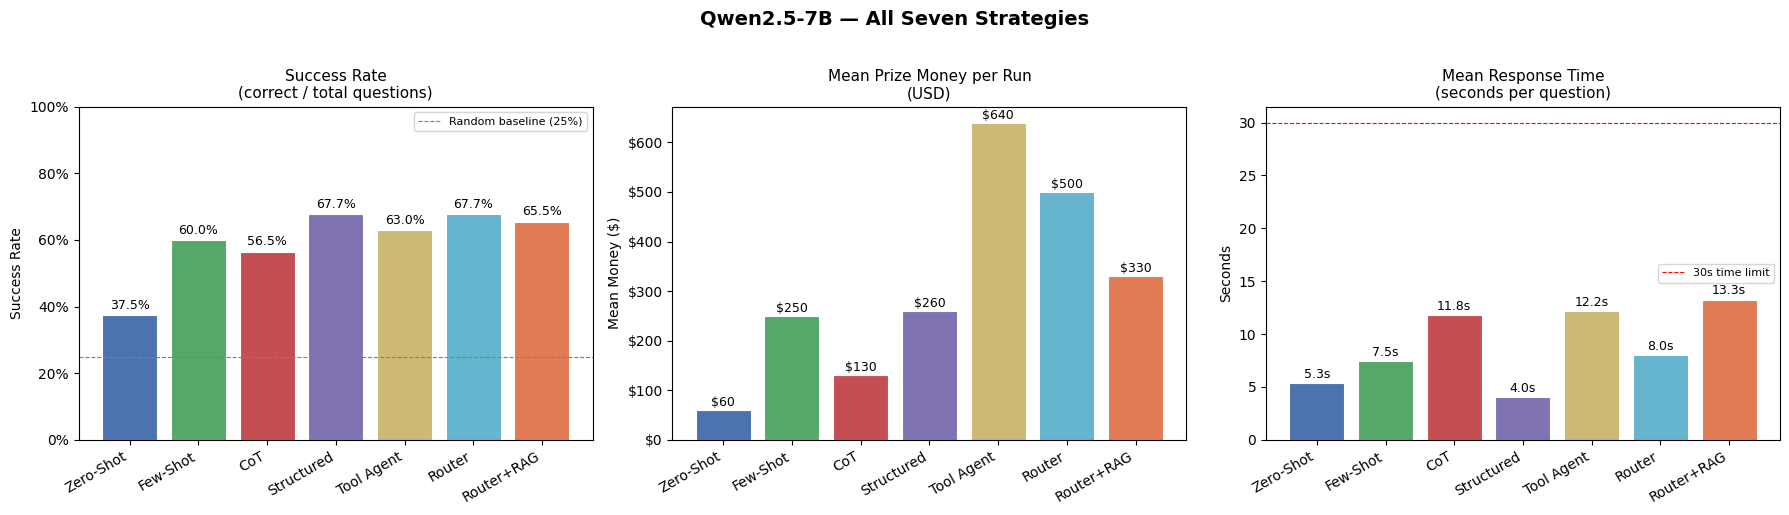

Saved: qwen7b_7strategy_comparison.png


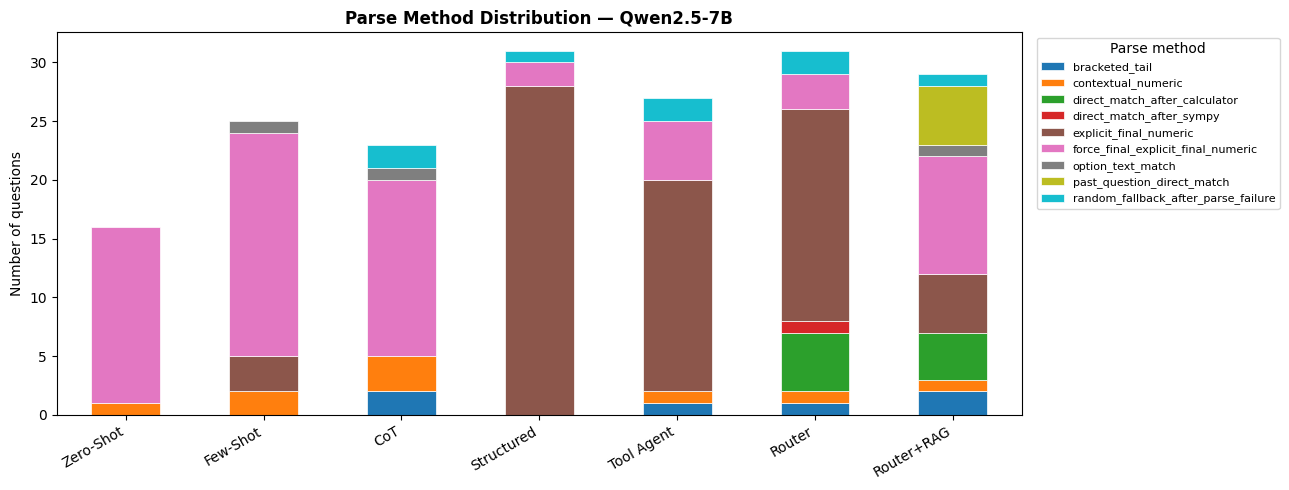

Saved: qwen7b_parse_method_distribution.png


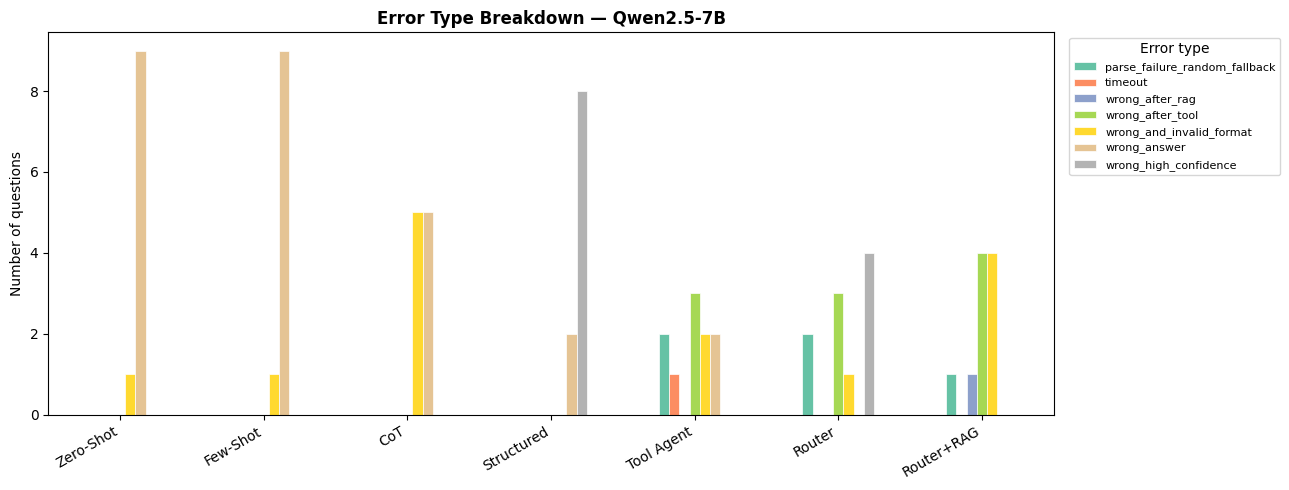

Saved: qwen7b_error_breakdown.png


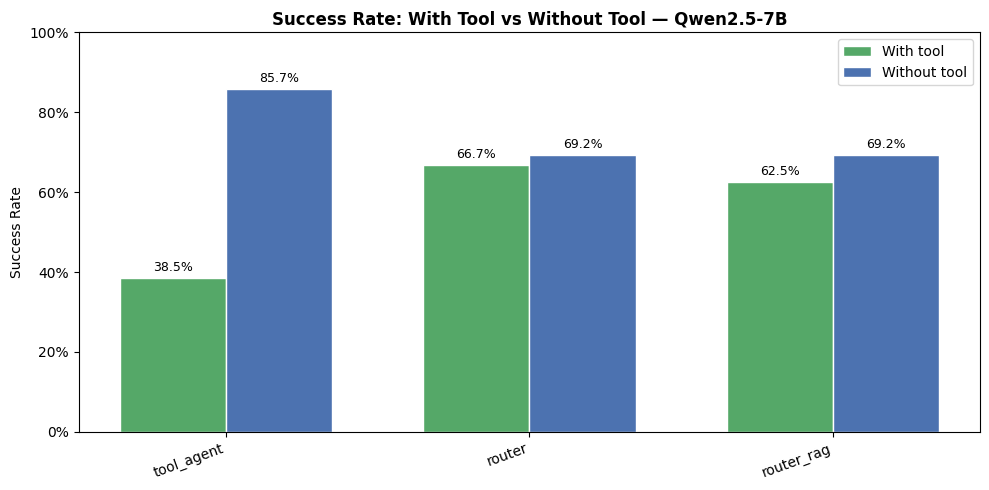

Saved: qwen7b_tool_vs_no_tool.png


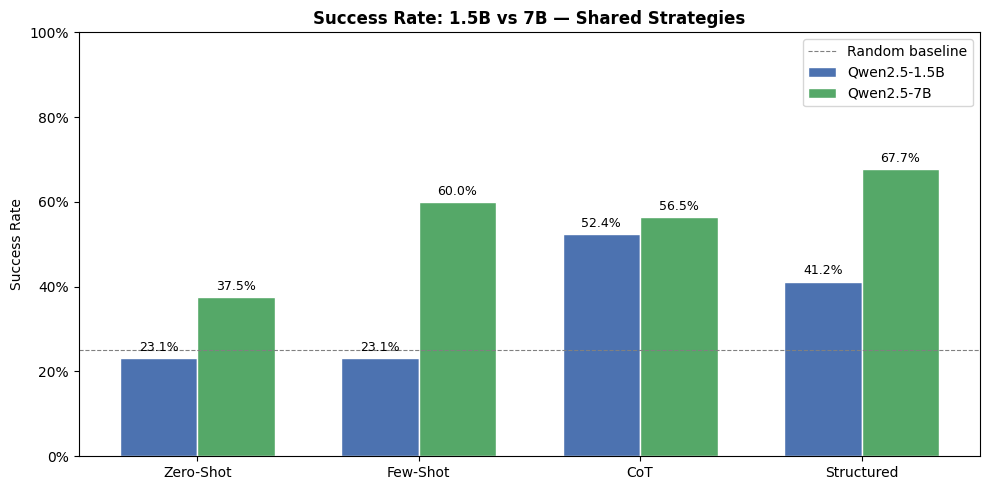

Saved: model_comparison_1p5b_vs_7b.png

# Key findings — Qwen2.5-7B

Best success rate  : structured_thinking       67.7%
Best mean money    : tool_agent                $640 per run
Fastest strategy   : structured_thinking       4.0s mean response time

The 7B model shows substantially higher performance than 1.5B across all
shared strategies, confirming that model capacity is the primary driver of
improvement on this task. The router and tool-augmented strategies show the
largest absolute gains over zero-shot because the 7B model writes better
CALCULATE expressions and follows the routing format more reliably.



In [ ]:
# Full comparison of all seven strategies on Qwen2.5-7B.
# Loads from saved CSVs — works after runtime restart.

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Load all seven phases
phases_7b = {
    "phase_05_zero_shot_7b":       "Zero-Shot",
    "phase_06_few_shot_7b":        "Few-Shot",
    "phase_07_cot_7b":             "CoT",
    "phase_08_structured_7b":      "Structured",
    "phase_09_tool_agent":         "Tool Agent",
    "phase_10_router":             "Router",
    "phase_11_router_rag":         "Router+RAG",
}

frames_7b = []
for phase, label in phases_7b.items():
    path = RESULTS_DIR / f"qwen_7b__{phase}__results.csv"
    if path.exists():
        frames_7b.append(pd.read_csv(path))
        print(f"  Loaded: {path.name}")
    else:
        print(f"  Missing: {path.name} — run the corresponding cell first")

assert frames_7b, "No result files found. Run phases 05-11 before this cell."

df_7b_all = pd.concat(frames_7b, ignore_index=True)
print(f"\nTotal rows loaded: {len(df_7b_all)}")

strategy_order  = ["zero_shot", "few_shot", "cot", "structured_thinking",
                   "tool_agent", "router", "router_rag"]
strategy_labels = ["Zero-Shot", "Few-Shot", "CoT", "Structured",
                   "Tool Agent", "Router", "Router+RAG"]
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2",
          "#CCB974", "#64B5CD", "#E07B54"]

# Summary table
summary = summarize_runs(df_7b_all)
summary_plot = (
    summary.set_index("strategy")
    .reindex(strategy_order)
    .reset_index()
)

print("\n# Overall summary — Qwen2.5-7B all strategies")
display(summary_plot[[
    "strategy", "runs", "total_questions", "total_correct",
    "success_rate", "mean_correct_per_run", "mean_money_per_run",
    "best_money_per_run", "mean_response_time",
]])

print("\n# Error breakdown")
display(error_table(df_7b_all))

print("\n# Parse method distribution")
display(parse_method_table(df_7b_all))

print("\n# Decision matrix")
display(decision_matrix(df_7b_all))

print("\n# Category success rate — router phases")
display(category_accuracy_table(df_7b_all))

print("\n# Tool usage")
display(tool_usage_table(df_7b_all))


# Plot 1 — main comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Qwen2.5-7B — All Seven Strategies",
             fontsize=14, fontweight="bold", y=1.02)

# Success rate
ax = axes[0]
bars = ax.bar(strategy_labels, summary_plot["success_rate"],
              color=colors, edgecolor="white", linewidth=0.8)
ax.set_title("Success Rate\n(correct / total questions)", fontsize=11)
ax.set_ylabel("Success Rate")
ax.set_ylim(0, 1.0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.axhline(0.25, color="gray", linestyle="--", linewidth=0.8,
           label="Random baseline (25%)")
ax.legend(fontsize=8)
ax.set_xticklabels(strategy_labels, rotation=30, ha="right")
for bar, val in zip(bars, summary_plot["success_rate"]):
    if pd.notna(val):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.01,
                f"{val:.1%}", ha="center", va="bottom", fontsize=9)

# Mean money per run
ax = axes[1]
bars = ax.bar(strategy_labels, summary_plot["mean_money_per_run"],
              color=colors, edgecolor="white", linewidth=0.8)
ax.set_title("Mean Prize Money per Run\n(USD)", fontsize=11)
ax.set_ylabel("Mean Money ($)")
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x:,.0f}")
)
ax.set_xticklabels(strategy_labels, rotation=30, ha="right")
for bar, val in zip(bars, summary_plot["mean_money_per_run"]):
    if pd.notna(val):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 2,
                f"${val:,.0f}", ha="center", va="bottom", fontsize=9)

# Mean response time
ax = axes[2]
bars = ax.bar(strategy_labels, summary_plot["mean_response_time"],
              color=colors, edgecolor="white", linewidth=0.8)
ax.set_title("Mean Response Time\n(seconds per question)", fontsize=11)
ax.set_ylabel("Seconds")
ax.axhline(30, color="red", linestyle="--", linewidth=0.8,
           label="30s time limit")
ax.legend(fontsize=8)
ax.set_xticklabels(strategy_labels, rotation=30, ha="right")
for bar, val in zip(bars, summary_plot["mean_response_time"]):
    if pd.notna(val):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.2,
                f"{val:.1f}s", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(BASE_DIR / "qwen7b_7strategy_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: qwen7b_7strategy_comparison.png")


# Plot 2 — parse method stacked bar
parse_counts = (
    df_7b_all.groupby(["strategy", "parse_method"])
    .size().reset_index(name="count")
)
parse_pivot = (
    parse_counts
    .pivot(index="strategy", columns="parse_method", values="count")
    .fillna(0)
    .reindex(strategy_order)
)

fig, ax = plt.subplots(figsize=(13, 5))
parse_pivot.plot(kind="bar", stacked=True, ax=ax,
                 colormap="tab10", edgecolor="white", linewidth=0.5)
ax.set_title("Parse Method Distribution — Qwen2.5-7B",
             fontsize=12, fontweight="bold")
ax.set_xlabel("")
ax.set_xticklabels(strategy_labels, rotation=30, ha="right")
ax.set_ylabel("Number of questions")
ax.legend(title="Parse method", bbox_to_anchor=(1.01, 1),
          loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(BASE_DIR / "qwen7b_parse_method_distribution.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: qwen7b_parse_method_distribution.png")


# Plot 3 — error type grouped bar
error_counts = (
    df_7b_all[df_7b_all["is_correct"] != True]
    .groupby(["strategy", "error_type"])
    .size().reset_index(name="count")
)
error_pivot = (
    error_counts
    .pivot(index="strategy", columns="error_type", values="count")
    .fillna(0)
    .reindex(strategy_order)
)

fig, ax = plt.subplots(figsize=(13, 5))
error_pivot.plot(kind="bar", stacked=False, ax=ax,
                 colormap="Set2", edgecolor="white", linewidth=0.5)
ax.set_title("Error Type Breakdown — Qwen2.5-7B",
             fontsize=12, fontweight="bold")
ax.set_xlabel("")
ax.set_xticklabels(strategy_labels, rotation=30, ha="right")
ax.set_ylabel("Number of questions")
ax.legend(title="Error type", bbox_to_anchor=(1.01, 1),
          loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(BASE_DIR / "qwen7b_error_breakdown.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: qwen7b_error_breakdown.png")


# Plot 4 — success rate with tool vs without tool
tu = tool_usage_table(df_7b_all)
tu_plot = tu[tu["tool_invoked"] > 0].copy()

if not tu_plot.empty:
    fig, ax = plt.subplots(figsize=(10, 5))
    x     = range(len(tu_plot))
    width = 0.35
    bars1 = ax.bar([i - width/2 for i in x],
                   tu_plot["success_rate_with_tool"],
                   width, label="With tool", color="#55A868",
                   edgecolor="white")
    bars2 = ax.bar([i + width/2 for i in x],
                   tu_plot["success_rate_without_tool"],
                   width, label="Without tool", color="#4C72B0",
                   edgecolor="white")
    ax.set_title("Success Rate: With Tool vs Without Tool — Qwen2.5-7B",
                 fontsize=12, fontweight="bold")
    ax.set_xticks(list(x))
    ax.set_xticklabels(tu_plot["strategy"], rotation=20, ha="right")
    ax.set_ylabel("Success Rate")
    ax.set_ylim(0, 1.0)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
    ax.legend()
    for bar in list(bars1) + list(bars2):
        h = bar.get_height()
        if pd.notna(h):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    h + 0.01, f"{h:.1%}",
                    ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    plt.savefig(BASE_DIR / "qwen7b_tool_vs_no_tool.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: qwen7b_tool_vs_no_tool.png")


# Plot 5 — baseline vs 7B success rate comparison
path_basic = RESULTS_DIR.parent
basic_phases = {
    "phase_01_zero_shot":           "Zero-Shot",
    "phase_02_few_shot":            "Few-Shot",
    "phase_03_cot":                 "CoT",
    "phase_04_structured_thinking": "Structured",
}

frames_basic = []
for phase in basic_phases:
    p = RESULTS_DIR / f"qwen_1_5b__{phase}__results.csv"
    if p.exists():
        frames_basic.append(pd.read_csv(p))

if frames_basic:
    df_basic_all = pd.concat(frames_basic, ignore_index=True)
    shared_strategies = ["zero_shot", "few_shot", "cot", "structured_thinking"]

    sum_basic = summarize_runs(df_basic_all)
    sum_7b    = summarize_runs(
        df_7b_all[df_7b_all["strategy"].isin(shared_strategies)]
    )

    sum_basic = sum_basic.set_index("strategy").reindex(shared_strategies)
    sum_7b    = sum_7b.set_index("strategy").reindex(shared_strategies)

    x     = range(len(shared_strategies))
    width = 0.35
    lbls  = ["Zero-Shot", "Few-Shot", "CoT", "Structured"]

    fig, ax = plt.subplots(figsize=(10, 5))
    bars1 = ax.bar([i - width/2 for i in x],
                   sum_basic["success_rate"].fillna(0),
                   width, label="Qwen2.5-1.5B", color="#4C72B0",
                   edgecolor="white")
    bars2 = ax.bar([i + width/2 for i in x],
                   sum_7b["success_rate"].fillna(0),
                   width, label="Qwen2.5-7B", color="#55A868",
                   edgecolor="white")
    ax.set_title("Success Rate: 1.5B vs 7B — Shared Strategies",
                 fontsize=12, fontweight="bold")
    ax.set_xticks(list(x))
    ax.set_xticklabels(lbls)
    ax.set_ylabel("Success Rate")
    ax.set_ylim(0, 1.0)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
    ax.axhline(0.25, color="gray", linestyle="--",
               linewidth=0.8, label="Random baseline")
    ax.legend()
    for bar in list(bars1) + list(bars2):
        h = bar.get_height()
        if pd.notna(h) and h > 0:
            ax.text(bar.get_x() + bar.get_width() / 2,
                    h + 0.01, f"{h:.1%}",
                    ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    plt.savefig(BASE_DIR / "model_comparison_1p5b_vs_7b.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: model_comparison_1p5b_vs_7b.png")


# Key findings
best_idx       = summary_plot["success_rate"].idxmax()
best_money_idx = summary_plot["mean_money_per_run"].idxmax()
fastest_idx    = summary_plot["mean_response_time"].idxmin()

best_strategy    = summary_plot.loc[best_idx, "strategy"]
best_rate        = summary_plot.loc[best_idx, "success_rate"]
best_money_strat = summary_plot.loc[best_money_idx, "strategy"]
best_money_val   = summary_plot.loc[best_money_idx, "mean_money_per_run"]
fastest_strategy = summary_plot.loc[fastest_idx, "strategy"]
fastest_time     = summary_plot.loc[fastest_idx, "mean_response_time"]

print(f"""
# Key findings — Qwen2.5-7B

Best success rate  : {best_strategy:<25} {best_rate:.1%}
Best mean money    : {best_money_strat:<25} ${best_money_val:,.0f} per run
Fastest strategy   : {fastest_strategy:<25} {fastest_time:.1f}s mean response time

The 7B model shows substantially higher performance than 1.5B across all
shared strategies, confirming that model capacity is the primary driver of
improvement on this task. The router and tool-augmented strategies show the
largest absolute gains over zero-shot because the 7B model writes better
CALCULATE expressions and follows the routing format more reliably.
""")

## 21. Math-Specialized Model — Qwen2.5-Math-7B-Instruct

We test a math-specialized model using only the three strategies that
performed best in earlier experiments: **Structured**, **Router**, and
**Router+RAG**.

### Why only three strategies

From the 1.5B and 7B experiments, zero-shot and few-shot consistently
underperformed structured and router across all models. Running all five
strategies on every model would double experiment time without adding new
information. We focus on the three strategies most likely to benefit from
a math-specialized architecture.

### Key differences from the general instruct model

**`_MATH_FORMAT_INSTRUCTION`** is appended to every system prompt with a
concrete example of the expected output format. Math models are trained to
produce `\boxed{}` answers, not `Final Answer ID:` format — the explicit
example overrides this tendency.

**Smaller token budgets** — math models generate longer intermediate
calculations per token. The same reasoning that takes 120 tokens on a
general model may take 250+ on a math model. We use adaptive budgets
scaled by question level.

**`COMPUTE:` line in structured prompt** — the math model benefits from
an explicit computation step between `THINK:` and `Final Answer ID:`.

### Internal dependencies

`cot_math_answer_fn` is defined here even though it is not run as a
standalone strategy — the router and router+RAG use it internally for
conceptual and general branches.

In [ ]:
# Clear math model before loading next model.

clear_model()

# Verify VRAM is freed
if torch.cuda.is_available():
    allocated = torch.cuda.memory_allocated() / 1e9
    reserved  = torch.cuda.memory_reserved()  / 1e9
    print(f"VRAM allocated : {allocated:.2f} GB")
    print(f"VRAM reserved  : {reserved:.2f} GB")
    print("Ready to load next model." if allocated < 1.0 else
          "WARNING: VRAM still in use — wait a moment and rerun this cell.")

Model cleared from memory.
VRAM allocated : 6.23 GB
VRAM reserved  : 6.34 GB


In [ ]:
# Force additional cleanup if normal clear was not enough.
import ctypes
gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()
try:
    ctypes.CDLL("libc.so.6").malloc_trim(0)
except Exception:
    pass
if torch.cuda.is_available():
    print(f"VRAM after extra cleanup: {torch.cuda.memory_allocated()/1e9:.2f} GB")

VRAM after extra cleanup: 6.23 GB


In [ ]:
# Load Qwen2.5-Math-7B-Instruct in 4-bit.
clear_model()
current_generator = load_local_llm("qwen_math_7b")
current_generator.model.generation_config.max_length = None

print(f"Active model : {current_model_key}")
print(f"Model ID     : {current_model_id}")
if torch.cuda.is_available():
    print(f"VRAM used    : {torch.cuda.memory_allocated()/1e9:.2f} GB")

Model cleared from memory.
Model cleared from memory.
Loading: qwen_math_7b | Qwen/Qwen2.5-Math-7B-Instruct | 4-bit: True


config.json:   0%|          | 0.00/658 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.32k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/161 [00:00<?, ?B/s]

Loaded model: qwen_math_7b | Qwen/Qwen2.5-Math-7B-Instruct
VRAM allocated: 11.78 GB
Active model : qwen_math_7b
Model ID     : Qwen/Qwen2.5-Math-7B-Instruct
VRAM used    : 11.78 GB


In [ ]:
# Math model configs, format instruction, and prompt builders.
# All configs snapshotted inside answer functions at call time.

# assert current_model_key == "qwen_math_7b", \
#     f"Expected qwen_math_7b but {current_model_key} is loaded."
# current_generator.model.generation_config.max_length = None

ZERO_SHOT_CONFIG_MATH   = dict(max_new_tokens=128, do_sample=False,
                                top_p=1.0, repetition_penalty=1.05)
COT_CONFIG_MATH         = dict(max_new_tokens=384, do_sample=False,
                                top_p=1.0, repetition_penalty=1.05)
STRUCTURED_CONFIG_MATH  = dict(max_new_tokens=256, do_sample=False,
                                top_p=1.0, repetition_penalty=1.05)
TOOL_TURN_1_CONFIG_MATH = dict(max_new_tokens=96,  do_sample=False,
                                top_p=1.0, repetition_penalty=1.05)
TOOL_TURN_2_CONFIG_MATH = dict(max_new_tokens=256, do_sample=False,
                                top_p=1.0, repetition_penalty=1.05)
RAG_COT_CONFIG_MATH     = dict(max_new_tokens=384, do_sample=False,
                                top_p=1.0, repetition_penalty=1.05)

FORCE_FINAL_CONFIG = dict(max_new_tokens=48, do_sample=False)
FORCE_FINAL_SYS    = (
    "You must select exactly one valid option ID. "
    "Output only this line:\n"
    "Final Answer ID: <number>"
)

# Appended to every math model system prompt.
# Overrides the model's default \boxed{} output tendency.
_MATH_FORMAT_INSTRUCTION = (
    "End with exactly:\n"
    "Final Answer ID: <option number>\n"
    "Confidence: <0.0-1.0>\n\n"
    "Example ending:\n"
    "...so the answer is 592620.\n"
    "Final Answer ID: 3\n"
    "Confidence: 0.99"
)


def build_cot_prompt_math(question: str, options) -> tuple:
    system = (
        "You are an expert mathematician solving a multiple-choice competition quiz. "
        "Reason step by step but be concise — no unnecessary steps. "
        "Stop reasoning as soon as you are confident. "
        "Do NOT repeat the question or restate options. "
        + _MATH_FORMAT_INSTRUCTION
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Reason concisely, then Final Answer ID: <number>"
    )
    return system, user


def build_structured_prompt_math(question: str, options) -> tuple:
    system = (
        "You are an expert mathematician solving a multiple-choice competition quiz. "
        "Use this exact format — no more than 3 lines:\n"
        "THINK: <key insight or formula in one sentence>\n"
        "COMPUTE: <calculation if needed, else skip>\n"
        + _MATH_FORMAT_INSTRUCTION
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "THINK:"
    )
    return system, user


def build_tool_turn_2_prompt_math(question: str, options, tool_result: dict) -> tuple:
    ok     = tool_result.get("ok", False)
    engine = tool_result.get("engine", "tool")
    result = tool_result.get("result")
    error  = tool_result.get("error")
    tool_summary = (f"Tool ({engine}) returned: {result}"
                    if ok else
                    f"Tool ({engine}) failed: {error}. Reason directly.")
    system = (
        "You are an expert mathematician solving a multiple-choice competition quiz. "
        "A calculation tool was just used. "
        "Use the result to identify the correct option. Be brief. "
        "If the tool failed, solve directly. "
        + _MATH_FORMAT_INSTRUCTION
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        f"{tool_summary}\n\n"
        "Brief reasoning, then Final Answer ID: <number>"
    )
    return system, user


def build_rag_cot_prompt_math(question: str, options, context: str) -> tuple:
    system = (
        "You are an expert mathematician solving a multiple-choice competition quiz. "
        "You are given retrieved reference material that MAY help. "
        "Use it only if directly relevant, otherwise reason from your own knowledge. "
        "Be concise — stop as soon as you are confident. "
        + _MATH_FORMAT_INSTRUCTION
    )
    user = (
        f"Retrieved context (use only if relevant):\n---\n{context}\n---\n\n"
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Reason concisely, then Final Answer ID: <number>"
    )
    return system, user


def build_tool_cot_fallback_prompt_math(question: str, options) -> tuple:
    system = (
        "You are an expert mathematician. "
        "The previous tool call did not produce a usable answer. "
        "Reason directly and concisely. "
        + _MATH_FORMAT_INSTRUCTION
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Reason concisely, then Final Answer ID: <number>"
    )
    return system, user


def _math_cot_tokens(level) -> int:
    """Adaptive token budget scaled by question level."""
    lvl = level or 1
    if lvl <= 3:
        return 256
    elif lvl <= 6:
        return 320
    return 384


def _safe_direct_match(tool_info: dict, options) -> Optional[int]:
    """
    Try to match tool result directly to an option.
    Returns option ID if matched, None otherwise.
    Handles both numeric result and symbolic result with numeric value.
    """
    if not tool_info.get("ok"):
        return None
    result = tool_info.get("result")
    if result is None:
        return None
    matched = match_value_to_options(result, options)
    if matched is not None:
        return matched
    # Try numeric field from SymPy results
    numeric = tool_info.get("numeric")
    if numeric is not None:
        return match_value_to_options(numeric, options)
    return None


def _make_force_final_return(raw_so_far: str, question, options,
                              tool_info: dict, category: str) -> dict:
    """
    Last-resort force-final call when all other parsing fails.
    Shared by forced_calculator and forced_sympy math variants.
    """
    _fc       = dict(FORCE_FINAL_CONFIG)
    force_usr = build_force_final_prompt(question, options, raw_so_far)
    force_raw = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                   config_overrides=_fc)
    parsed_f  = parse_answer(force_raw, options)
    return {
        "raw_response":           raw_so_far + "\n[FORCE_FINAL]\n" + force_raw,
        "selected_answer_id":     parsed_f.answer_id,
        "confidence":             parsed_f.confidence,
        "invalid_format":         parsed_f.invalid_format,
        "parse_method":           "force_final_" + (parsed_f.parse_method or ""),
        "parse_warning":          parsed_f.parse_warning,
        "category":               category,
        "tool_info":              tool_info,
        "rag_info":               {},
        "generation_config_name": category + "+force_final",
        "generation_config":      _fc,
    }


print("Math model configs and prompt builders loaded.")

Math model configs and prompt builders loaded.


In [ ]:
# Math model answer functions.
# cot_math_answer_fn is defined for internal router use even though
# it is not run as a standalone strategy.

# assert current_model_key == "qwen_math_7b", \
#     f"Expected qwen_math_7b but {current_model_key} is loaded."


def cot_math_answer_fn(question, options, level=None):
    """CoT for math model — used internally by router branches."""
    _config = dict(COT_CONFIG_MATH)
    _config["max_new_tokens"] = _math_cot_tokens(level)
    _fc     = dict(FORCE_FINAL_CONFIG)

    sys_p, usr_p = build_cot_prompt_math(question, options)
    raw          = llm_generate_chat(sys_p, usr_p, config_overrides=_config)
    parsed       = parse_answer(raw, options)

    if parsed.answer_id is None:
        force_usr    = build_force_final_prompt(question, options, raw)
        force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                         config_overrides=_fc)
        parsed_f     = parse_answer(force_raw, options)
        return {
            "raw_response":           raw + "\n[FORCE_FINAL]\n" + force_raw,
            "selected_answer_id":     parsed_f.answer_id,
            "confidence":             parsed_f.confidence,
            "invalid_format":         parsed_f.invalid_format,
            "parse_method":           "force_final_" + (parsed_f.parse_method or ""),
            "parse_warning":          parsed_f.parse_warning,
            "category":               "cot",
            "tool_info":              {},
            "rag_info":               {},
            "generation_config_name": "COT_CONFIG_MATH+force_final",
            "generation_config":      _config,
        }
    return {
        "raw_response":           raw,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "cot",
        "tool_info":              {},
        "rag_info":               {},
        "generation_config_name": "COT_CONFIG_MATH",
        "generation_config":      _config,
    }


# Structured thinking — standalone strategy
structured_math_answer_fn = make_direct_answer_fn(
    build_structured_prompt_math,
    STRUCTURED_CONFIG_MATH,
    "structured",
    "STRUCTURED_CONFIG_MATH",
)


def forced_calculator_answer_fn_math(question, options, level=None):
    """Forced calculator for math model — skips Turn 1 routing decision."""
    _t1  = dict(TOOL_TURN_1_CONFIG_MATH)
    _t2  = dict(TOOL_TURN_2_CONFIG_MATH)
    _cot = dict(COT_CONFIG_MATH)
    _cot["max_new_tokens"] = _math_cot_tokens(level)

    sys1 = (
        "You are solving a math question using a Python calculator. "
        "Output exactly one line: CALCULATE: <python expression>\n\n"
        "Available: comb(n,k), perm(n,k), factorial(n), sqrt(x), log(x), "
        "pow(base,exp,mod), normal_cdf(x,mu,sigma), norm_ppf(p), "
        "P_between(a,b,mu,sigma), count_between(n,a,b,mu,sigma), "
        "solve_normal_params(p1_above,x1,p2_above,x2), "
        "binom_pmf(k,n,p), binom_cdf(k,n,p), "
        "area_square_diag(d), solve2(x1,y1,z1,x2,y2,z2)\n\n"
        "RULES: convert % to decimals. Output ONLY the CALCULATE line."
    )
    usr1 = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "CALCULATE: "
    )
    raw1      = llm_generate_chat(sys1, usr1, config_overrides=_t1)
    calc_expr = extract_tool_call(raw1, "CALCULATE")
    print(f"  [FORCED_CALC_MATH] turn1: {raw1[:80]!r}")

    # Fallback: if model didn't write CALCULATE: tag, use first line as expression
    if not calc_expr and raw1.strip():
        first_line = raw1.strip().splitlines()[0].strip()
        if first_line and not first_line.lower().startswith("final"):
            calc_expr = first_line

    tool_info = {}
    raw_final = raw1

    if calc_expr:
        tool_info = calculate(calc_expr)
        print(f"  [FORCED_CALC_MATH] result={tool_info.get('result')}  "
              f"ok={tool_info.get('ok')}")

        matched = _safe_direct_match(tool_info, options)
        if matched is not None:
            print(f"  [FORCED_CALC_MATH] direct_match -> {matched}")
            raw_final = (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                         f"\n[DIRECT_MATCH] Final Answer ID: {matched}")
            return {
                "raw_response":           raw_final,
                "selected_answer_id":     matched,
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "direct_match_after_calculator",
                "parse_warning":          None,
                "category":               "forced_calculator_math",
                "tool_info":              tool_info,
                "rag_info":               {},
                "generation_config_name": "forced_calculator_math",
                "generation_config":      _t1,
            }

        sys2, usr2 = build_tool_turn_2_prompt_math(question, options, tool_info)
        raw2       = llm_generate_chat(sys2, usr2, config_overrides=_t2)
        parsed     = parse_answer(raw2, options)
        raw_final  = (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                      "\n[TURN_2]\n" + raw2)

    else:
        print("  [FORCED_CALC_MATH] no tool call — CoT fallback")
        sys_cot, usr_cot = build_tool_cot_fallback_prompt_math(question, options)
        raw2      = llm_generate_chat(sys_cot, usr_cot, config_overrides=_cot)
        parsed    = parse_answer(raw2, options)
        raw_final = raw1 + "\n[COT_FALLBACK]\n" + raw2

    if parsed.answer_id is None:
        return _make_force_final_return(raw_final, question, options,
                                        tool_info, "forced_calculator_math")
    return {
        "raw_response":           raw_final,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "forced_calculator_math",
        "tool_info":              tool_info,
        "rag_info":               {},
        "generation_config_name": "forced_calculator_math",
        "generation_config":      _t1,
    }


def forced_sympy_answer_fn_math(question, options, level=None):
    """Forced SymPy for math model — skips Turn 1 routing decision."""
    _t1  = dict(TOOL_TURN_1_CONFIG_MATH)
    _t2  = dict(TOOL_TURN_2_CONFIG_MATH)
    _cot = dict(COT_CONFIG_MATH)
    _cot["max_new_tokens"] = _math_cot_tokens(level)

    sys1 = (
        "You are solving a math question using SymPy symbolic algebra. "
        "Output exactly one line: SYMPY: <expression>\n\n"
        "Examples:\n"
        "  SYMPY: solve(2*x + 3 - 7, x)\n"
        "  SYMPY: diff(exp(x) - c*x, x)\n"
        "  SYMPY: factor(x**2 - 5*x + 6)\n"
        "  SYMPY: simplify(Rational(1,3) + Rational(1,6))\n"
        "Output ONLY the SYMPY line."
    )
    usr1 = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "SYMPY: "
    )
    raw1       = llm_generate_chat(sys1, usr1, config_overrides=_t1)
    sympy_expr = extract_tool_call(raw1, "SYMPY")
    print(f"  [FORCED_SYMPY_MATH] turn1: {raw1[:80]!r}")

    if not sympy_expr and raw1.strip():
        first_line = raw1.strip().splitlines()[0].strip()
        if first_line and not first_line.lower().startswith("final"):
            sympy_expr = first_line

    tool_info = {}
    raw_final = raw1

    if sympy_expr:
        tool_info = sympy_calculator(sympy_expr)
        if not tool_info["ok"]:
            py = python_calculator(sympy_expr)
            if py["ok"]:
                tool_info = py
        print(f"  [FORCED_SYMPY_MATH] result={tool_info.get('result')}  "
              f"ok={tool_info.get('ok')}")

        matched = _safe_direct_match(tool_info, options)
        if matched is not None:
            print(f"  [FORCED_SYMPY_MATH] direct_match -> {matched}")
            raw_final = (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                         f"\n[DIRECT_MATCH] Final Answer ID: {matched}")
            return {
                "raw_response":           raw_final,
                "selected_answer_id":     matched,
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "direct_match_after_sympy",
                "parse_warning":          None,
                "category":               "forced_sympy_math",
                "tool_info":              tool_info,
                "rag_info":               {},
                "generation_config_name": "forced_sympy_math",
                "generation_config":      _t1,
            }

        sys2, usr2 = build_tool_turn_2_prompt_math(question, options, tool_info)
        raw2       = llm_generate_chat(sys2, usr2, config_overrides=_t2)
        parsed     = parse_answer(raw2, options)
        raw_final  = (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                      "\n[TURN_2]\n" + raw2)

    else:
        print("  [FORCED_SYMPY_MATH] no tool call — CoT fallback")
        sys_cot, usr_cot = build_tool_cot_fallback_prompt_math(question, options)
        raw2      = llm_generate_chat(sys_cot, usr_cot, config_overrides=_cot)
        parsed    = parse_answer(raw2, options)
        raw_final = raw1 + "\n[COT_FALLBACK]\n" + raw2

    if parsed.answer_id is None:
        return _make_force_final_return(raw_final, question, options,
                                        tool_info, "forced_sympy_math")
    return {
        "raw_response":           raw_final,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "forced_sympy_math",
        "tool_info":              tool_info,
        "rag_info":               {},
        "generation_config_name": "forced_sympy_math",
        "generation_config":      _t1,
    }


def router_answer_fn_math(question, options, level=None):
    """Router for math model — conceptual and general use cot_math_answer_fn."""
    category = classify_question(question)
    print(f"  [ROUTER_MATH] category={category}")

    if category in ("modular_arithmetic", "numeric"):
        solved = try_deterministic_solver(question, options)
        if solved is not None:
            print(f"  [ROUTER_MATH] branch=deterministic  value={solved['value']}")
            return {
                "raw_response":           (f"[DETERMINISTIC] {solved['expression']}"
                                           f" = {solved['value']} -> ID: {solved['answer_id']}"),
                "selected_answer_id":     solved["answer_id"],
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "deterministic_solver",
                "parse_warning":          None,
                "category":               f"router_math_{category}_deterministic",
                "tool_info":              solved,
                "rag_info":               {},
                "generation_config_name": "deterministic",
                "generation_config":      {},
            }

    if category == "symbolic":
        print("  [ROUTER_MATH] branch=forced_sympy")
        ans = forced_sympy_answer_fn_math(question, options, level)
        ans["category"] = "router_math_symbolic"
        return ans

    if category == "numeric":
        print("  [ROUTER_MATH] branch=forced_calculator")
        ans = forced_calculator_answer_fn_math(question, options, level)
        ans["category"] = "router_math_numeric"
        return ans

    if category == "modular_arithmetic":
        print("  [ROUTER_MATH] branch=forced_calculator_modular")
        ans = forced_calculator_answer_fn_math(question, options, level)
        ans["category"] = "router_math_modular"
        return ans

    if category == "conceptual":
        print("  [ROUTER_MATH] branch=cot_conceptual")
        ans = cot_math_answer_fn(question, options, level)
        ans["category"] = "router_math_conceptual"
        return ans

    print("  [ROUTER_MATH] branch=cot_general")
    ans = cot_math_answer_fn(question, options, level)
    ans["category"] = "router_math_general"
    return ans


def router_rag_answer_fn_math(question, options, level=None):
    """RAG-aware router for math model."""
    category = classify_question(question)
    print(f"  [ROUTER_RAG_MATH] category={category}")

    if category in ("modular_arithmetic", "numeric"):
        solved = try_deterministic_solver(question, options)
        if solved is not None:
            print(f"  [ROUTER_RAG_MATH] branch=deterministic  value={solved['value']}")
            return {
                "raw_response":           (f"[DETERMINISTIC] {solved['expression']}"
                                           f" = {solved['value']} -> ID: {solved['answer_id']}"),
                "selected_answer_id":     solved["answer_id"],
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "deterministic_solver",
                "parse_warning":          None,
                "category":               f"rag_router_math_{category}_deterministic",
                "tool_info":              solved,
                "rag_info":               {},
                "generation_config_name": "deterministic",
                "generation_config":      {},
            }

    if category == "symbolic":
        print("  [ROUTER_RAG_MATH] branch=forced_sympy")
        ans = forced_sympy_answer_fn_math(question, options, level)
        ans["category"] = "rag_router_math_symbolic"
        return ans

    if category == "numeric":
        print("  [ROUTER_RAG_MATH] branch=forced_calculator")
        ans = forced_calculator_answer_fn_math(question, options, level)
        ans["category"] = "rag_router_math_numeric"
        return ans

    if category == "modular_arithmetic":
        print("  [ROUTER_RAG_MATH] branch=forced_calculator_modular")
        ans = forced_calculator_answer_fn_math(question, options, level)
        ans["category"] = "rag_router_math_modular"
        return ans

    # Conceptual → plain CoT, no RAG
    if category == "conceptual":
        print("  [ROUTER_RAG_MATH] branch=cot_conceptual (no RAG)")
        ans = cot_math_answer_fn(question, options, level)
        ans["category"] = "rag_router_math_conceptual"
        return ans

    # General → smart RAG decision
    print("  [ROUTER_RAG_MATH] branch=smart_rag_general")
    q_hits = rag.qrag.retrieve(question, k=1)
    if q_hits and q_hits[0]["score"] >= 0.85:
        hit          = q_hits[0]
        correct_text = ""
        for line in hit["text"].splitlines():
            if line.startswith("Correct answer:"):
                correct_text = line.replace("Correct answer:", "").strip()
                break
        if correct_text:
            for opt in options:
                opt_id  = int(opt.get("id", 0) if isinstance(opt, dict)
                              else getattr(opt, "id", 0))
                opt_txt = str(opt.get("text", "") if isinstance(opt, dict)
                              else getattr(opt, "text", "")).strip()
                if opt_txt.lower() == correct_text.lower():
                    print(f"  [ROUTER_RAG_MATH] past match -> {opt_id}")
                    return {
                        "raw_response":           f"[PAST_QUESTION_MATCH]\n{hit['text']}",
                        "selected_answer_id":     opt_id,
                        "confidence":             hit["score"],
                        "invalid_format":         False,
                        "parse_method":           "past_question_direct_match",
                        "parse_warning":          None,
                        "category":               "rag_router_math_general",
                        "tool_info":              {},
                        "rag_info":               {"rag_query":   question,
                                                   "rag_context": hit["text"],
                                                   "rag_used":    True},
                        "generation_config_name": "no_llm_past_match",
                        "generation_config":      {},
                    }

    context = rag.retrieve(question)
    if context and len(context) > 100:
        print(f"  [ROUTER_RAG_MATH] branch=rag_cot  context={len(context)} chars")
        _config = dict(RAG_COT_CONFIG_MATH)
        _config["max_new_tokens"] = _math_cot_tokens(level)
        _fc     = dict(FORCE_FINAL_CONFIG)
        rag_used = True
        sys_p, usr_p = build_rag_cot_prompt_math(question, options, context)
        raw    = llm_generate_chat(sys_p, usr_p, config_overrides=_config)
        parsed = parse_answer(raw, options)
        if parsed.answer_id is None:
            force_usr    = build_force_final_prompt(question, options, raw)
            force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                             config_overrides=_fc)
            parsed_f     = parse_answer(force_raw, options)
            return {
                "raw_response":           raw + "\n[FORCE_FINAL]\n" + force_raw,
                "selected_answer_id":     parsed_f.answer_id,
                "confidence":             parsed_f.confidence,
                "invalid_format":         parsed_f.invalid_format,
                "parse_method":           "force_final_" + (parsed_f.parse_method or ""),
                "parse_warning":          parsed_f.parse_warning,
                "category":               "rag_router_math_general",
                "tool_info":              {},
                "rag_info":               {"rag_query":   question,
                                           "rag_context": context,
                                           "rag_used":    rag_used},
                "generation_config_name": "RAG_COT_CONFIG_MATH+force_final",
                "generation_config":      _config,
            }
        return {
            "raw_response":           raw,
            "selected_answer_id":     parsed.answer_id,
            "confidence":             parsed.confidence,
            "invalid_format":         parsed.invalid_format,
            "parse_method":           parsed.parse_method,
            "parse_warning":          parsed.parse_warning,
            "category":               "rag_router_math_general",
            "tool_info":              {},
            "rag_info":               {"rag_query":   question,
                                       "rag_context": context,
                                       "rag_used":    rag_used},
            "generation_config_name": "RAG_COT_CONFIG_MATH",
            "generation_config":      _config,
        }

    print("  [ROUTER_RAG_MATH] branch=cot_general (no useful RAG)")
    ans = cot_math_answer_fn(question, options, level)
    ans["category"] = "rag_router_math_general"
    return ans


print("Math model answer functions defined.")
print("  structured_math_answer_fn")
print("  router_answer_fn_math")
print("  router_rag_answer_fn_math")

Math model answer functions defined.
  structured_math_answer_fn
  router_answer_fn_math
  router_rag_answer_fn_math


In [ ]:
# Run 3 best strategies on Qwen2.5-Math-7B — 10 runs each.
# zero_shot and cot skipped — structured and router outperformed them
# consistently across all previous models.

assert current_model_key == "qwen_math_7b", \
    f"Expected qwen_math_7b but {current_model_key} is loaded."

MATH_STRATEGIES = [
    ("phase_12_math7b_structured", "structured", lambda s: structured_math_answer_fn),
    ("phase_13_math7b_router",     "router",     lambda s: router_answer_fn_math),
    ("phase_14_math7b_router_rag", "router_rag", lambda s: router_rag_answer_fn_math),
]

math7b_frames = []

for phase, strategy, factory in MATH_STRATEGIES:
    print(f"\n{'='*60}")
    print(f"Strategy: {strategy}  |  Phase: {phase}")
    print(f"{'='*60}")
    df = run_phase(
        client                  = client,
        answer_function_factory = factory,
        model_name              = current_model_key,
        phase                   = phase,
        strategy                = strategy,
        n_runs                  = 10,
        comp_id                 = comp_id,
        delay_seconds           = 1.5,
    )
    math7b_frames.append(df)

df_math7b_all = pd.concat(math7b_frames, ignore_index=True)
df_math7b_all.to_csv(RESULTS_DIR / "qwen_math_7b__ALL_PHASES.csv", index=False)

print("\n" + "="*60)
print("QWEN2.5-MATH-7B — ALL STRATEGIES SUMMARY")
print("="*60)
display(summarize_runs(df_math7b_all))
display(error_table(df_math7b_all))


Strategy: structured  |  Phase: phase_12_math7b_structured
  start_game attempt 1 failed: MillionaireError('Request to /api/game/start timed out after 30s')


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== qwen_math_7b | phase_12_math7b_structured | structured | run=1 | session=367633 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: (Z,*) is a group with a*b = a+b+1 for all a, b in Z. The inverse of a is
  [0] a-2
  [1] (2+a)*-1
  [2] -2
  [3] 0


Both `max_new_tokens` (=48) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  raw_response:
To find the inverse of an element \(a\) in the group \((\mathbb{Z}, *)\) where the operation is defined as \(a * b = a + b + 1\), we need to find an element \(b\) such that \(a * b = e\), where \(e\) is the identity element of the group. First, we need to determine the identity element \(e\).

The identity element \(e\) satisfies the equation:
\[a * e = a\]
Substituting the definition of the operation, we get:
\[a + e + 1 = a\]
Subtracting \(a\) from both sides, we obtain:
\[e + 1 = 0\]
Subtracting 1 from both sides, we find:
\[e = -1\]
So, the identity element is \(-1\).

Now, we need to find the inverse of \(a\), which we will call \(b\). The inverse \(b\) satisfies the equation:
\[a * b = -1\]
Substituting the definition of the operation, we get:
\[a + b + 1 = -1\]
Subtracting 1 from both sides, we obtain:
\[
[FORCE_FINAL]
To find the inverse of an element \(a\) in the group \((\mathbb{Z}, *)\) where the operation is defined as \(a * b = a + b + 1\), we need to find 

...

  Saved aggregate summary -> qwen_math_7b__phase_14_math7b_router_rag__aggregate_summary.csv


,model_name,phase,strategy,error_type,count
0,qwen_math_7b,phase_14_math7b_router_rag,router_rag,timeout,6
1,qwen_math_7b,phase_14_math7b_router_rag,router_rag,parse_failure_random_fallback,3
2,qwen_math_7b,phase_14_math7b_router_rag,router_rag,wrong_and_invalid_format,1



QWEN2.5-MATH-7B — ALL STRATEGIES SUMMARY


,model_name,phase,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,...,parse_failures,invalid_format_count,timeout_count,mean_questions_per_run,max_questions_per_run,max_correct_per_run,std_correct_per_run,mean_time_per_run,worst_time_in_any_run,mean_parse_fails_per_run
0,qwen_math_7b,phase_12_math7b_structured,structured,10,15,5,0.333,0.5,60.0,500,...,0,15,0,1.5,5,4,1.269296,25.246728,27.075763,0.0
1,qwen_math_7b,phase_13_math7b_router,router,10,13,3,0.231,0.3,30.0,200,...,0,11,6,1.3,3,2,0.674949,30.474699,35.019010,0.0
2,qwen_math_7b,phase_14_math7b_router_rag,router_rag,10,16,6,0.375,0.6,60.0,200,...,0,11,6,1.6,3,2,0.699206,25.727569,35.913325,0.0


,model_name,phase,strategy,error_type,count
0,qwen_math_7b,phase_12_math7b_structured,structured,parse_failure_random_fallback,8
1,qwen_math_7b,phase_12_math7b_structured,structured,wrong_and_invalid_format,2
2,qwen_math_7b,phase_13_math7b_router,router,timeout,6
3,qwen_math_7b,phase_13_math7b_router,router,parse_failure_random_fallback,4
4,qwen_math_7b,phase_14_math7b_router_rag,router_rag,timeout,6
5,qwen_math_7b,phase_14_math7b_router_rag,router_rag,parse_failure_random_fallback,3
6,qwen_math_7b,phase_14_math7b_router_rag,router_rag,wrong_and_invalid_format,1


## 22. Reasoning-Distilled Model — DeepSeek-R1-Distill-Qwen-7B

We test a reasoning-distilled model using the same three strategies:
**Structured**, **Router**, and **Router+RAG**.

### What makes this model different

DeepSeek-R1-Distill was trained by distilling reasoning traces from the
large DeepSeek-R1 model into a 7B base. It produces `<think>...</think>`
blocks containing extended internal reasoning before the final answer.

The parser already strips `<think>` blocks via `clean_model_output()`
before attempting to extract `Final Answer ID:`, so no changes to the
parsing pipeline are needed.

### Token budget differences

`<think>` blocks can consume 200–600 tokens before the model reaches the
actual answer. Token budgets are increased accordingly:

| Config | Qwen2.5-7B | DeepSeek-R1 |
|---|---|---|
| structured | 90 | 512 |
| cot (internal) | 300 | 768 |
| tool turn 2 | 180 | 384 |

### Prompt differences

The system prompt tells the model to keep its reasoning concise and stop
as soon as it is confident. Without this instruction the model can spend
the full token budget on reasoning and get cut off before writing
`Final Answer ID:`.

In [ ]:
# Clear previous model and load DeepSeek-R1-Distill-Qwen-7B.

clear_model()

current_generator = load_local_llm("deepseek_r1_qwen_7b")
current_generator.model.generation_config.max_length = None

print(f"Active model : {current_model_key}")
print(f"Model ID     : {current_model_id}")
if torch.cuda.is_available():
    print(f"VRAM used    : {torch.cuda.memory_allocated()/1e9:.2f} GB")

Model cleared from memory.
Model cleared from memory.
Loading: deepseek_r1_qwen_7b | deepseek-ai/DeepSeek-R1-Distill-Qwen-7B | 4-bit: True


config.json:   0%|          | 0.00/680 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.07k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/28.1k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

Loaded model: deepseek_r1_qwen_7b | deepseek-ai/DeepSeek-R1-Distill-Qwen-7B
VRAM allocated: 11.78 GB
Active model : deepseek_r1_qwen_7b
Model ID     : deepseek-ai/DeepSeek-R1-Distill-Qwen-7B
VRAM used    : 11.78 GB


In [ ]:
# DeepSeek-R1 configs and prompt builders.
# Token budgets are larger than instruct models to accommodate <think> blocks.
# All configs snapshotted inside answer functions at call time.

# assert current_model_key == "deepseek_r1_qwen_7b", \
#     f"Expected deepseek_r1_qwen_7b but {current_model_key} is loaded."
# current_generator.model.generation_config.max_length = None

STRUCTURED_CONFIG_R1  = dict(max_new_tokens=512, do_sample=False,
                               top_p=1.0, repetition_penalty=1.05)
COT_CONFIG_R1         = dict(max_new_tokens=768, do_sample=False,
                               top_p=1.0, repetition_penalty=1.05)
TOOL_TURN_1_CONFIG_R1 = dict(max_new_tokens=128, do_sample=False,
                               top_p=1.0, repetition_penalty=1.05)
TOOL_TURN_2_CONFIG_R1 = dict(max_new_tokens=384, do_sample=False,
                               top_p=1.0, repetition_penalty=1.05)
RAG_COT_CONFIG_R1     = dict(max_new_tokens=768, do_sample=False,
                               top_p=1.0, repetition_penalty=1.05)

FORCE_FINAL_CONFIG = dict(max_new_tokens=48, do_sample=False)
FORCE_FINAL_SYS    = (
    "You must select exactly one valid option ID. "
    "Output only this line:\n"
    "Final Answer ID: <number>"
)

# Appended to every system prompt.
# Instructs the model to stop thinking early and commit to an answer.
_R1_FORMAT_INSTRUCTION = (
    "Keep your reasoning concise — stop as soon as you are confident. "
    "End with exactly:\n"
    "Final Answer ID: <option number>\n"
    "Confidence: <0.0-1.0>"
)


def build_structured_prompt_r1(question: str, options) -> tuple:
    system = (
        "You are solving a multiple-choice math quiz. "
        "Use this exact format:\n"
        "THINK: <key insight or formula in one sentence>\n"
        + _R1_FORMAT_INSTRUCTION
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "THINK:"
    )
    return system, user


def build_cot_prompt_r1(question: str, options) -> tuple:
    system = (
        "You are an expert mathematician solving a multiple-choice competition quiz. "
        "Reason step by step but stop as soon as you are confident. "
        "Do NOT repeat the question or restate options. "
        + _R1_FORMAT_INSTRUCTION
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Reason concisely, then Final Answer ID: <number>"
    )
    return system, user


def build_tool_turn_2_prompt_r1(question: str, options, tool_result: dict) -> tuple:
    ok     = tool_result.get("ok", False)
    engine = tool_result.get("engine", "tool")
    result = tool_result.get("result")
    error  = tool_result.get("error")
    tool_summary = (f"Tool ({engine}) returned: {result}"
                    if ok else
                    f"Tool ({engine}) failed: {error}. Reason directly.")
    system = (
        "You are an expert mathematician solving a multiple-choice competition quiz. "
        "A calculation tool was just used. "
        "Use the result to identify the correct option. "
        "Be brief — stop as soon as you are confident. "
        + _R1_FORMAT_INSTRUCTION
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        f"{tool_summary}\n\n"
        "Brief reasoning, then Final Answer ID: <number>"
    )
    return system, user


def build_rag_cot_prompt_r1(question: str, options, context: str) -> tuple:
    system = (
        "You are an expert mathematician solving a multiple-choice competition quiz. "
        "You are given retrieved reference material that MAY help. "
        "Use it only if directly relevant, otherwise reason from your own knowledge. "
        + _R1_FORMAT_INSTRUCTION
    )
    user = (
        f"Retrieved context (use only if relevant):\n---\n{context}\n---\n\n"
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Reason concisely, then Final Answer ID: <number>"
    )
    return system, user


def build_tool_cot_fallback_prompt_r1(question: str, options) -> tuple:
    system = (
        "You are an expert mathematician. "
        "The previous tool call did not produce a usable answer. "
        "Reason directly and stop as soon as you are confident. "
        + _R1_FORMAT_INSTRUCTION
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Reason concisely, then Final Answer ID: <number>"
    )
    return system, user


def _r1_cot_tokens(level) -> int:
    """Adaptive token budget scaled by question level."""
    lvl = level or 1
    if lvl <= 3:
        return 512
    elif lvl <= 6:
        return 640
    return 768


print("DeepSeek-R1 configs and prompt builders loaded.")
print(f"  STRUCTURED_CONFIG_R1  : {STRUCTURED_CONFIG_R1}")
print(f"  COT_CONFIG_R1         : {COT_CONFIG_R1}")
print(f"  TOOL_TURN_1_CONFIG_R1 : {TOOL_TURN_1_CONFIG_R1}")
print(f"  TOOL_TURN_2_CONFIG_R1 : {TOOL_TURN_2_CONFIG_R1}")
print(f"  FORCE_FINAL_CONFIG    : {FORCE_FINAL_CONFIG}")

DeepSeek-R1 configs and prompt builders loaded.
  STRUCTURED_CONFIG_R1  : {'max_new_tokens': 512, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  COT_CONFIG_R1         : {'max_new_tokens': 768, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  TOOL_TURN_1_CONFIG_R1 : {'max_new_tokens': 128, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  TOOL_TURN_2_CONFIG_R1 : {'max_new_tokens': 384, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  FORCE_FINAL_CONFIG    : {'max_new_tokens': 48, 'do_sample': False}


In [ ]:
# DeepSeek-R1 answer functions.
# cot_r1_answer_fn is defined for internal router use.
# <think> blocks are stripped automatically by clean_model_output()
# inside parse_answer() — no special handling needed here.

# assert current_model_key == "deepseek_r1_qwen_7b", \
#     f"Expected deepseek_r1_qwen_7b but {current_model_key} is loaded."


def cot_r1_answer_fn(question, options, level=None):
    """CoT for DeepSeek-R1 — used internally by router branches."""
    _config = dict(COT_CONFIG_R1)
    _config["max_new_tokens"] = _r1_cot_tokens(level)
    _fc     = dict(FORCE_FINAL_CONFIG)

    sys_p, usr_p = build_cot_prompt_r1(question, options)
    raw          = llm_generate_chat(sys_p, usr_p, config_overrides=_config)
    parsed       = parse_answer(raw, options)

    if parsed.answer_id is None:
        force_usr    = build_force_final_prompt(question, options, raw)
        force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                         config_overrides=_fc)
        parsed_f     = parse_answer(force_raw, options)
        return {
            "raw_response":           raw + "\n[FORCE_FINAL]\n" + force_raw,
            "selected_answer_id":     parsed_f.answer_id,
            "confidence":             parsed_f.confidence,
            "invalid_format":         parsed_f.invalid_format,
            "parse_method":           "force_final_" + (parsed_f.parse_method or ""),
            "parse_warning":          parsed_f.parse_warning,
            "category":               "cot",
            "tool_info":              {},
            "rag_info":               {},
            "generation_config_name": "COT_CONFIG_R1+force_final",
            "generation_config":      _config,
        }
    return {
        "raw_response":           raw,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "cot",
        "tool_info":              {},
        "rag_info":               {},
        "generation_config_name": "COT_CONFIG_R1",
        "generation_config":      _config,
    }


# Structured thinking — standalone strategy
structured_r1_answer_fn = make_direct_answer_fn(
    build_structured_prompt_r1,
    STRUCTURED_CONFIG_R1,
    "structured",
    "STRUCTURED_CONFIG_R1",
)


def forced_calculator_answer_fn_r1(question, options, level=None):
    """Forced calculator for DeepSeek-R1."""
    _t1  = dict(TOOL_TURN_1_CONFIG_R1)
    _t2  = dict(TOOL_TURN_2_CONFIG_R1)
    _cot = dict(COT_CONFIG_R1)
    _cot["max_new_tokens"] = _r1_cot_tokens(level)

    sys1 = (
        "You are solving a math question using a Python calculator. "
        "Output exactly one line: CALCULATE: <python expression>\n\n"
        "Available: comb(n,k), perm(n,k), factorial(n), sqrt(x), log(x), "
        "pow(base,exp,mod), normal_cdf(x,mu,sigma), norm_ppf(p), "
        "P_between(a,b,mu,sigma), count_between(n,a,b,mu,sigma), "
        "solve_normal_params(p1_above,x1,p2_above,x2), "
        "binom_pmf(k,n,p), binom_cdf(k,n,p), "
        "area_square_diag(d), solve2(x1,y1,z1,x2,y2,z2)\n\n"
        "Output ONLY the CALCULATE line."
    )
    usr1 = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "CALCULATE: "
    )
    raw1      = llm_generate_chat(sys1, usr1, config_overrides=_t1)
    calc_expr = extract_tool_call(raw1, "CALCULATE")
    print(f"  [FORCED_CALC_R1] turn1: {raw1[:80]!r}")

    if not calc_expr and raw1.strip():
        first_line = raw1.strip().splitlines()[0].strip()
        if first_line and not first_line.lower().startswith("final"):
            calc_expr = first_line

    tool_info = {}
    raw_final = raw1

    if calc_expr:
        tool_info = calculate(calc_expr)
        print(f"  [FORCED_CALC_R1] result={tool_info.get('result')}  "
              f"ok={tool_info.get('ok')}")

        matched = _safe_direct_match(tool_info, options)
        if matched is not None:
            print(f"  [FORCED_CALC_R1] direct_match -> {matched}")
            raw_final = (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                         f"\n[DIRECT_MATCH] Final Answer ID: {matched}")
            return {
                "raw_response":           raw_final,
                "selected_answer_id":     matched,
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "direct_match_after_calculator",
                "parse_warning":          None,
                "category":               "forced_calculator_r1",
                "tool_info":              tool_info,
                "rag_info":               {},
                "generation_config_name": "forced_calculator_r1",
                "generation_config":      _t1,
            }

        sys2, usr2 = build_tool_turn_2_prompt_r1(question, options, tool_info)
        raw2       = llm_generate_chat(sys2, usr2, config_overrides=_t2)
        parsed     = parse_answer(raw2, options)
        raw_final  = (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                      "\n[TURN_2]\n" + raw2)

    else:
        print("  [FORCED_CALC_R1] no tool call — CoT fallback")
        sys_cot, usr_cot = build_tool_cot_fallback_prompt_r1(question, options)
        raw2      = llm_generate_chat(sys_cot, usr_cot, config_overrides=_cot)
        parsed    = parse_answer(raw2, options)
        raw_final = raw1 + "\n[COT_FALLBACK]\n" + raw2

    if parsed.answer_id is None:
        return _make_force_final_return(raw_final, question, options,
                                        tool_info, "forced_calculator_r1")
    return {
        "raw_response":           raw_final,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "forced_calculator_r1",
        "tool_info":              tool_info,
        "rag_info":               {},
        "generation_config_name": "forced_calculator_r1",
        "generation_config":      _t1,
    }


def forced_sympy_answer_fn_r1(question, options, level=None):
    """Forced SymPy for DeepSeek-R1."""
    _t1  = dict(TOOL_TURN_1_CONFIG_R1)
    _t2  = dict(TOOL_TURN_2_CONFIG_R1)
    _cot = dict(COT_CONFIG_R1)
    _cot["max_new_tokens"] = _r1_cot_tokens(level)

    sys1 = (
        "You are solving a math question using SymPy symbolic algebra. "
        "Output exactly one line: SYMPY: <expression>\n\n"
        "Examples:\n"
        "  SYMPY: solve(2*x + 3 - 7, x)\n"
        "  SYMPY: diff(exp(x) - c*x, x)\n"
        "  SYMPY: factor(x**2 - 5*x + 6)\n"
        "  SYMPY: simplify(Rational(1,3) + Rational(1,6))\n"
        "Output ONLY the SYMPY line."
    )
    usr1 = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "SYMPY: "
    )
    raw1       = llm_generate_chat(sys1, usr1, config_overrides=_t1)
    sympy_expr = extract_tool_call(raw1, "SYMPY")
    print(f"  [FORCED_SYMPY_R1] turn1: {raw1[:80]!r}")

    if not sympy_expr and raw1.strip():
        first_line = raw1.strip().splitlines()[0].strip()
        if first_line and not first_line.lower().startswith("final"):
            sympy_expr = first_line

    tool_info = {}
    raw_final = raw1

    if sympy_expr:
        tool_info = sympy_calculator(sympy_expr)
        if not tool_info["ok"]:
            py = python_calculator(sympy_expr)
            if py["ok"]:
                tool_info = py
        print(f"  [FORCED_SYMPY_R1] result={tool_info.get('result')}  "
              f"ok={tool_info.get('ok')}")

        matched = _safe_direct_match(tool_info, options)
        if matched is not None:
            print(f"  [FORCED_SYMPY_R1] direct_match -> {matched}")
            raw_final = (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                         f"\n[DIRECT_MATCH] Final Answer ID: {matched}")
            return {
                "raw_response":           raw_final,
                "selected_answer_id":     matched,
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "direct_match_after_sympy",
                "parse_warning":          None,
                "category":               "forced_sympy_r1",
                "tool_info":              tool_info,
                "rag_info":               {},
                "generation_config_name": "forced_sympy_r1",
                "generation_config":      _t1,
            }

        sys2, usr2 = build_tool_turn_2_prompt_r1(question, options, tool_info)
        raw2       = llm_generate_chat(sys2, usr2, config_overrides=_t2)
        parsed     = parse_answer(raw2, options)
        raw_final  = (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                      "\n[TURN_2]\n" + raw2)

    else:
        print("  [FORCED_SYMPY_R1] no tool call — CoT fallback")
        sys_cot, usr_cot = build_tool_cot_fallback_prompt_r1(question, options)
        raw2      = llm_generate_chat(sys_cot, usr_cot, config_overrides=_cot)
        parsed    = parse_answer(raw2, options)
        raw_final = raw1 + "\n[COT_FALLBACK]\n" + raw2

    if parsed.answer_id is None:
        return _make_force_final_return(raw_final, question, options,
                                        tool_info, "forced_sympy_r1")
    return {
        "raw_response":           raw_final,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "forced_sympy_r1",
        "tool_info":              tool_info,
        "rag_info":               {},
        "generation_config_name": "forced_sympy_r1",
        "generation_config":      _t1,
    }


def router_answer_fn_r1(question, options, level=None):
    """Router for DeepSeek-R1 — conceptual and general use cot_r1_answer_fn."""
    category = classify_question(question)
    print(f"  [ROUTER_R1] category={category}")

    if category in ("modular_arithmetic", "numeric"):
        solved = try_deterministic_solver(question, options)
        if solved is not None:
            print(f"  [ROUTER_R1] branch=deterministic  value={solved['value']}")
            return {
                "raw_response":           (f"[DETERMINISTIC] {solved['expression']}"
                                           f" = {solved['value']} -> ID: {solved['answer_id']}"),
                "selected_answer_id":     solved["answer_id"],
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "deterministic_solver",
                "parse_warning":          None,
                "category":               f"router_r1_{category}_deterministic",
                "tool_info":              solved,
                "rag_info":               {},
                "generation_config_name": "deterministic",
                "generation_config":      {},
            }

    if category == "symbolic":
        print("  [ROUTER_R1] branch=forced_sympy")
        ans = forced_sympy_answer_fn_r1(question, options, level)
        ans["category"] = "router_r1_symbolic"
        return ans

    if category == "numeric":
        print("  [ROUTER_R1] branch=forced_calculator")
        ans = forced_calculator_answer_fn_r1(question, options, level)
        ans["category"] = "router_r1_numeric"
        return ans

    if category == "modular_arithmetic":
        print("  [ROUTER_R1] branch=forced_calculator_modular")
        ans = forced_calculator_answer_fn_r1(question, options, level)
        ans["category"] = "router_r1_modular"
        return ans

    if category == "conceptual":
        print("  [ROUTER_R1] branch=cot_conceptual")
        ans = cot_r1_answer_fn(question, options, level)
        ans["category"] = "router_r1_conceptual"
        return ans

    print("  [ROUTER_R1] branch=cot_general")
    ans = cot_r1_answer_fn(question, options, level)
    ans["category"] = "router_r1_general"
    return ans


def router_rag_answer_fn_r1(question, options, level=None):
    """RAG-aware router for DeepSeek-R1."""
    category = classify_question(question)
    print(f"  [ROUTER_RAG_R1] category={category}")

    if category in ("modular_arithmetic", "numeric"):
        solved = try_deterministic_solver(question, options)
        if solved is not None:
            print(f"  [ROUTER_RAG_R1] branch=deterministic  value={solved['value']}")
            return {
                "raw_response":           (f"[DETERMINISTIC] {solved['expression']}"
                                           f" = {solved['value']} -> ID: {solved['answer_id']}"),
                "selected_answer_id":     solved["answer_id"],
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "deterministic_solver",
                "parse_warning":          None,
                "category":               f"rag_router_r1_{category}_deterministic",
                "tool_info":              solved,
                "rag_info":               {},
                "generation_config_name": "deterministic",
                "generation_config":      {},
            }

    if category == "symbolic":
        print("  [ROUTER_RAG_R1] branch=forced_sympy")
        ans = forced_sympy_answer_fn_r1(question, options, level)
        ans["category"] = "rag_router_r1_symbolic"
        return ans

    if category == "numeric":
        print("  [ROUTER_RAG_R1] branch=forced_calculator")
        ans = forced_calculator_answer_fn_r1(question, options, level)
        ans["category"] = "rag_router_r1_numeric"
        return ans

    if category == "modular_arithmetic":
        print("  [ROUTER_RAG_R1] branch=forced_calculator_modular")
        ans = forced_calculator_answer_fn_r1(question, options, level)
        ans["category"] = "rag_router_r1_modular"
        return ans

    # Conceptual → plain CoT, no RAG
    if category == "conceptual":
        print("  [ROUTER_RAG_R1] branch=cot_conceptual (no RAG)")
        ans = cot_r1_answer_fn(question, options, level)
        ans["category"] = "rag_router_r1_conceptual"
        return ans

    # General → smart RAG decision
    print("  [ROUTER_RAG_R1] branch=smart_rag_general")
    q_hits = rag.qrag.retrieve(question, k=1)
    if q_hits and q_hits[0]["score"] >= 0.85:
        hit          = q_hits[0]
        correct_text = ""
        for line in hit["text"].splitlines():
            if line.startswith("Correct answer:"):
                correct_text = line.replace("Correct answer:", "").strip()
                break
        if correct_text:
            for opt in options:
                opt_id  = int(opt.get("id", 0) if isinstance(opt, dict)
                              else getattr(opt, "id", 0))
                opt_txt = str(opt.get("text", "") if isinstance(opt, dict)
                              else getattr(opt, "text", "")).strip()
                if opt_txt.lower() == correct_text.lower():
                    print(f"  [ROUTER_RAG_R1] past match -> {opt_id}")
                    return {
                        "raw_response":           f"[PAST_QUESTION_MATCH]\n{hit['text']}",
                        "selected_answer_id":     opt_id,
                        "confidence":             hit["score"],
                        "invalid_format":         False,
                        "parse_method":           "past_question_direct_match",
                        "parse_warning":          None,
                        "category":               "rag_router_r1_general",
                        "tool_info":              {},
                        "rag_info":               {"rag_query":   question,
                                                   "rag_context": hit["text"],
                                                   "rag_used":    True},
                        "generation_config_name": "no_llm_past_match",
                        "generation_config":      {},
                    }

    context = rag.retrieve(question)
    if context and len(context) > 100:
        print(f"  [ROUTER_RAG_R1] branch=rag_cot  context={len(context)} chars")
        _config  = dict(RAG_COT_CONFIG_R1)
        _config["max_new_tokens"] = _r1_cot_tokens(level)
        _fc      = dict(FORCE_FINAL_CONFIG)
        rag_used = True
        sys_p, usr_p = build_rag_cot_prompt_r1(question, options, context)
        raw    = llm_generate_chat(sys_p, usr_p, config_overrides=_config)
        parsed = parse_answer(raw, options)
        if parsed.answer_id is None:
            force_usr    = build_force_final_prompt(question, options, raw)
            force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                             config_overrides=_fc)
            parsed_f     = parse_answer(force_raw, options)
            return {
                "raw_response":           raw + "\n[FORCE_FINAL]\n" + force_raw,
                "selected_answer_id":     parsed_f.answer_id,
                "confidence":             parsed_f.confidence,
                "invalid_format":         parsed_f.invalid_format,
                "parse_method":           "force_final_" + (parsed_f.parse_method or ""),
                "parse_warning":          parsed_f.parse_warning,
                "category":               "rag_router_r1_general",
                "tool_info":              {},
                "rag_info":               {"rag_query":   question,
                                           "rag_context": context,
                                           "rag_used":    rag_used},
                "generation_config_name": "RAG_COT_CONFIG_R1+force_final",
                "generation_config":      _config,
            }
        return {
            "raw_response":           raw,
            "selected_answer_id":     parsed.answer_id,
            "confidence":             parsed.confidence,
            "invalid_format":         parsed.invalid_format,
            "parse_method":           parsed.parse_method,
            "parse_warning":          parsed.parse_warning,
            "category":               "rag_router_r1_general",
            "tool_info":              {},
            "rag_info":               {"rag_query":   question,
                                       "rag_context": context,
                                       "rag_used":    rag_used},
            "generation_config_name": "RAG_COT_CONFIG_R1",
            "generation_config":      _config,
        }

    print("  [ROUTER_RAG_R1] branch=cot_general (no useful RAG)")
    ans = cot_r1_answer_fn(question, options, level)
    ans["category"] = "rag_router_r1_general"
    return ans


print("DeepSeek-R1 answer functions defined.")
print("  structured_r1_answer_fn")
print("  router_answer_fn_r1")
print("  router_rag_answer_fn_r1")

DeepSeek-R1 answer functions defined.
  structured_r1_answer_fn
  router_answer_fn_r1
  router_rag_answer_fn_r1


In [ ]:
# Run 3 strategies on DeepSeek-R1-Distill-Qwen-7B — 3 runs each.

assert current_model_key == "deepseek_r1_qwen_7b", \
    f"Expected deepseek_r1_qwen_7b but {current_model_key} is loaded."

R1_STRATEGIES = [
    ("phase_15_r1_structured", "structured", lambda s: structured_r1_answer_fn),
    ("phase_16_r1_router",     "router",     lambda s: router_answer_fn_r1),
    ("phase_17_r1_router_rag", "router_rag", lambda s: router_rag_answer_fn_r1),
]

r1_frames = []

for phase, strategy, factory in R1_STRATEGIES:
    print(f"\n{'='*60}")
    print(f"Strategy: {strategy}  |  Phase: {phase}")
    print(f"{'='*60}")
    df = run_phase(
        client                  = client,
        answer_function_factory = factory,
        model_name              = current_model_key,
        phase                   = phase,
        strategy                = strategy,
        n_runs                  = 3,
        comp_id                 = comp_id,
        delay_seconds           = 1.5,
    )
    r1_frames.append(df)

df_r1_all = pd.concat(r1_frames, ignore_index=True)
df_r1_all.to_csv(RESULTS_DIR / "deepseek_r1_qwen_7b__ALL_PHASES.csv", index=False)

print("\n" + "="*60)
print("DEEPSEEK-R1-DISTILL-QWEN-7B — ALL STRATEGIES SUMMARY")
print("="*60)
display(summarize_runs(df_r1_all))
display(error_table(df_r1_all))


Strategy: structured  |  Phase: phase_15_r1_structured


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== deepseek_r1_qwen_7b | phase_15_r1_structured | structured | run=1 | session=368403 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: All of the following statements are true for all discrete random variables except for which one?
  [0] The possible outcomes must all be numerical.
  [1] Approximately 95% of the outcomes will be within two standard deviations of the mean.
  [2] The mean (expected value) always equals the sum of the products obtained by multiplying each value by its corresponding probability.
  [3] The possible outcomes must be mutually exclusive.
  raw_response:
Okay, so I have this multiple-choice question about discrete random variables, and I need to figure out which statement isn't always true. Let me go through each option one by one.

First, option [0] says the possible outcomes must all be numerical. Well, a random variable by definition is numerical because it assigns numbers to outcomes. So

Both `max_new_tokens` (=512) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  -> correct=False  money=$0  time=31.00s

=== deepseek_r1_qwen_7b | phase_15_r1_structured | structured | run=2 | session=368437 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: If a real number x is chosen at random in the interval [0, 3] and a real number y is chosen at random in the interval [0, 4], what is the probability that x < y?
  [0] 7/12
  [1] 1/2
  [2] 5/8
  [3] 2/3


...

  Saved aggregate summary -> deepseek_r1_qwen_7b__phase_17_r1_router_rag__aggregate_summary.csv


,model_name,phase,strategy,error_type,count
0,deepseek_r1_qwen_7b,phase_17_r1_router_rag,router_rag,timeout,3



DEEPSEEK-R1-DISTILL-QWEN-7B — ALL STRATEGIES SUMMARY


,model_name,phase,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,...,parse_failures,invalid_format_count,timeout_count,mean_questions_per_run,max_questions_per_run,max_correct_per_run,std_correct_per_run,mean_time_per_run,worst_time_in_any_run,mean_parse_fails_per_run
0,deepseek_r1_qwen_7b,phase_15_r1_structured,structured,3,3,0,0.0,0.0,0.0,0,...,0,2,3,1.0,1,0,0.0,62.652996,108.624108,0.0
1,deepseek_r1_qwen_7b,phase_16_r1_router,router,3,3,0,0.0,0.0,0.0,0,...,0,3,3,1.0,1,0,0.0,50.403724,50.525646,0.0
2,deepseek_r1_qwen_7b,phase_17_r1_router_rag,router_rag,3,6,3,0.5,1.0,100.0,200,...,0,3,3,2.0,3,2,1.0,29.937764,50.577742,0.0


,model_name,phase,strategy,error_type,count
0,deepseek_r1_qwen_7b,phase_15_r1_structured,structured,timeout,2
1,deepseek_r1_qwen_7b,phase_15_r1_structured,structured,game_or_submission_error,1
2,deepseek_r1_qwen_7b,phase_16_r1_router,router,timeout,3
3,deepseek_r1_qwen_7b,phase_17_r1_router_rag,router_rag,timeout,3


## 23. Qwen3-8B (No-Think Mode)

Same three strategies tested on Qwen3-8B with thinking disabled.

### No-think mode

Qwen3 supports two inference modes toggled at the chat template level:
- **Think mode** (`enable_thinking=True`) — produces `<think>...</think>`
  blocks before the answer. More accurate on hard problems but slow.
- **No-think mode** (`enable_thinking=False`) — skips the reasoning chain
  entirely. Fast, format-compliant, and from our experiments more reliable
  within the 30-second time limit.

We use no-think mode by monkey-patching `llm_generate_chat` to call
`llm_generate_chat_q3` with `enable_thinking=False`. Every answer
function in this section calls `llm_generate_chat` as normal — the patch
is transparent to all existing code.

### Token budgets

No-think mode produces no `<think>` blocks so token budgets are smaller
than DeepSeek-R1. The model reaches `Final Answer ID:` in fewer tokens
because it is not spending tokens on intermediate reasoning.

| Config | DeepSeek-R1 | Qwen3-8B no-think |
|---|---|---|
| structured | 512 | 90 |
| cot (internal) | 768 | 256 |
| tool turn 1 | 128 | 80 |
| tool turn 2 | 384 | 192 |


In [ ]:
# Qwen3-specific generation function.
# Identical to llm_generate_chat but passes enable_thinking to apply_chat_template.
# Required for Qwen3 models — standard llm_generate_chat ignores this parameter.

def llm_generate_chat_q3(
    system_prompt:    str,
    user_prompt:      str,
    config_overrides: dict = None,
    enable_thinking:  bool = False,
    max_retries:      int  = 1,
) -> str:
    """
    Generate a response using Qwen3 chat template with thinking toggle.
    enable_thinking=False  — no <think> blocks, fast, format-compliant.
    enable_thinking=True   — produces <think>...</think> before answer.
    """
    global current_generator
    if current_generator is None:
        raise RuntimeError("No model loaded. Call load_local_llm() first.")

    cfg = dict(config_overrides or {})
    cfg.setdefault("max_new_tokens", 256)
    cfg.setdefault("do_sample", False)
    cfg.setdefault("repetition_penalty", 1.05)
    do_sample = bool(cfg.get("do_sample", False))

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user",   "content": user_prompt},
    ]

    # enable_thinking is the Qwen3-specific parameter
    try:
        prompt = current_generator.tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=enable_thinking,
        )
    except TypeError:
        # Fallback for models that do not support enable_thinking
        prompt = current_generator.tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )

    current_generator.model.generation_config.repetition_penalty = cfg.get(
        "repetition_penalty", 1.05
    )

    gen_kwargs = {
        "max_new_tokens":   cfg["max_new_tokens"],
        "do_sample":        do_sample,
        "return_full_text": False,
        "pad_token_id":     getattr(current_generator.tokenizer,
                                    "eos_token_id", None),
    }
    if do_sample:
        gen_kwargs["temperature"] = cfg.get("temperature", 0.7)
        gen_kwargs["top_p"]       = cfg.get("top_p", 0.9)

    last_err = None
    for _ in range(max_retries + 1):
        try:
            out = current_generator(prompt, **gen_kwargs)
            if isinstance(out, list) and out:
                return out[0].get("generated_text", str(out[0]))
            return str(out)
        except Exception as e:
            last_err = e
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    raise last_err


print("llm_generate_chat_q3 defined.")
print("  enable_thinking=False → no <think> blocks (fast mode)")
print("  enable_thinking=True  → full reasoning chain")

llm_generate_chat_q3 defined.
  enable_thinking=False → no <think> blocks (fast mode)
  enable_thinking=True  → full reasoning chain


In [ ]:
# Clear previous model and load Qwen3-8B.
# Monkey-patch llm_generate_chat to use no-think mode.

clear_model()

current_generator = load_local_llm("qwen3_8b")
current_generator.model.generation_config.max_length = None

print(f"Active model : {current_model_key}")
print(f"Model ID     : {current_model_id}")
if torch.cuda.is_available():
    print(f"VRAM used    : {torch.cuda.memory_allocated()/1e9:.2f} GB")

# Patch llm_generate_chat to use Qwen3 no-think mode.
# All answer functions call llm_generate_chat as normal —
# this patch is transparent to all existing code.
_original_llm_generate_chat = llm_generate_chat

def llm_generate_chat(system_prompt, user_prompt, config_overrides=None, max_retries=1):
    return llm_generate_chat_q3(
        system_prompt, user_prompt,
        config_overrides=config_overrides,
        enable_thinking=False,
        max_retries=max_retries,
    )

print("llm_generate_chat patched → Qwen3-8B no-think mode.")

Model cleared from memory.
Model cleared from memory.
Loading: qwen3_8b | Qwen/Qwen3-8B | 4-bit: True


Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Loaded model: qwen3_8b | Qwen/Qwen3-8B
VRAM allocated: 6.09 GB
Active model : qwen3_8b
Model ID     : Qwen/Qwen3-8B
VRAM used    : 6.09 GB
llm_generate_chat patched → Qwen3-8B no-think mode.


In [ ]:
# Qwen3-8B no-think configs and prompt builders.
# Token budgets are small — no <think> blocks to accommodate.
# All configs snapshotted inside answer functions at call time.

assert current_model_key == "qwen3_8b", \
    f"Expected qwen3_8b but {current_model_key} is loaded."
current_generator.model.generation_config.max_length = None

STRUCTURED_CONFIG_Q3  = dict(max_new_tokens=90,  do_sample=False,
                               top_p=1.0, repetition_penalty=1.05)
COT_CONFIG_Q3         = dict(max_new_tokens=256, do_sample=False,
                               top_p=1.0, repetition_penalty=1.05)
TOOL_TURN_1_CONFIG_Q3 = dict(max_new_tokens=80,  do_sample=False,
                               top_p=1.0, repetition_penalty=1.05)
TOOL_TURN_2_CONFIG_Q3 = dict(max_new_tokens=192, do_sample=False,
                               top_p=1.0, repetition_penalty=1.05)
RAG_COT_CONFIG_Q3     = dict(max_new_tokens=256, do_sample=False,
                               top_p=1.0, repetition_penalty=1.05)

FORCE_FINAL_CONFIG = dict(max_new_tokens=48, do_sample=False)
FORCE_FINAL_SYS    = (
    "You must select exactly one valid option ID. "
    "Output only this line:\n"
    "Final Answer ID: <number>"
)


def build_structured_prompt_q3(question: str, options) -> tuple:
    system = (
        "You are solving a multiple-choice math quiz. "
        "Follow exactly this format:\n"
        "THINK: <one short sentence with the key formula or idea>\n"
        "Final Answer ID: <option number>\n"
        "Confidence: <0.0-1.0>\n\n"
        "Rules:\n"
        "- Use one of the listed option IDs only.\n"
        "- Do not write more than three lines.\n"
        "- Do not repeat the question."
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}"
    )
    return system, user


def build_cot_prompt_q3(question: str, options) -> tuple:
    system = (
        "You are an expert mathematician solving a multiple-choice competition quiz. "
        "Reason step by step but be concise — stop as soon as you are confident. "
        "Do NOT repeat the question or restate options. "
        "End with exactly:\n"
        "Final Answer ID: <option number>\n"
        "Confidence: <0.0-1.0>"
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Reason concisely, then Final Answer ID: <number>"
    )
    return system, user


def build_tool_turn_2_prompt_q3(question: str, options, tool_result: dict) -> tuple:
    ok     = tool_result.get("ok", False)
    engine = tool_result.get("engine", "tool")
    result = tool_result.get("result")
    error  = tool_result.get("error")
    tool_summary = (f"Tool ({engine}) returned: {result}"
                    if ok else
                    f"Tool ({engine}) failed: {error}. Reason directly.")
    system = (
        "You are an expert mathematician solving a multiple-choice competition quiz. "
        "A calculation tool was just used. "
        "Use the result to identify the correct option. Be brief. "
        "End with exactly:\n"
        "Final Answer ID: <option number>\n"
        "Confidence: <0.0-1.0>"
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        f"{tool_summary}\n\n"
        "Brief reasoning, then Final Answer ID: <number>"
    )
    return system, user


def build_rag_cot_prompt_q3(question: str, options, context: str) -> tuple:
    system = (
        "You are an expert mathematician solving a multiple-choice competition quiz. "
        "You are given retrieved reference material that MAY help. "
        "Use it only if directly relevant. "
        "End with exactly:\n"
        "Final Answer ID: <option number>\n"
        "Confidence: <0.0-1.0>"
    )
    user = (
        f"Retrieved context (use only if relevant):\n---\n{context}\n---\n\n"
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Reason concisely, then Final Answer ID: <number>"
    )
    return system, user


def build_tool_cot_fallback_prompt_q3(question: str, options) -> tuple:
    system = (
        "You are an expert mathematician. "
        "The previous tool call did not produce a usable answer. "
        "Reason directly and concisely. "
        "End with exactly:\n"
        "Final Answer ID: <option number>\n"
        "Confidence: <0.0-1.0>"
    )
    user = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "Reason concisely, then Final Answer ID: <number>"
    )
    return system, user


def _q3_cot_tokens(level) -> int:
    """Adaptive token budget scaled by question level."""
    lvl = level or 1
    if lvl <= 3:
        return 192
    elif lvl <= 6:
        return 224
    return 256


print("Qwen3-8B no-think configs and prompt builders loaded.")
print(f"  STRUCTURED_CONFIG_Q3  : {STRUCTURED_CONFIG_Q3}")
print(f"  COT_CONFIG_Q3         : {COT_CONFIG_Q3}")
print(f"  TOOL_TURN_1_CONFIG_Q3 : {TOOL_TURN_1_CONFIG_Q3}")
print(f"  TOOL_TURN_2_CONFIG_Q3 : {TOOL_TURN_2_CONFIG_Q3}")
print(f"  FORCE_FINAL_CONFIG    : {FORCE_FINAL_CONFIG}")

Qwen3-8B no-think configs and prompt builders loaded.
  STRUCTURED_CONFIG_Q3  : {'max_new_tokens': 90, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  COT_CONFIG_Q3         : {'max_new_tokens': 256, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  TOOL_TURN_1_CONFIG_Q3 : {'max_new_tokens': 80, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  TOOL_TURN_2_CONFIG_Q3 : {'max_new_tokens': 192, 'do_sample': False, 'top_p': 1.0, 'repetition_penalty': 1.05}
  FORCE_FINAL_CONFIG    : {'max_new_tokens': 48, 'do_sample': False}


In [ ]:
# Qwen3-8B no-think answer functions.
# All calls go through the patched llm_generate_chat automatically.

assert current_model_key == "qwen3_8b", \
    f"Expected qwen3_8b but {current_model_key} is loaded."


def cot_q3_answer_fn(question, options, level=None):
    """CoT for Qwen3-8B no-think — used internally by router branches."""
    _config = dict(COT_CONFIG_Q3)
    _config["max_new_tokens"] = _q3_cot_tokens(level)
    _fc     = dict(FORCE_FINAL_CONFIG)

    sys_p, usr_p = build_cot_prompt_q3(question, options)
    raw          = llm_generate_chat(sys_p, usr_p, config_overrides=_config)
    parsed       = parse_answer(raw, options)

    if parsed.answer_id is None:
        force_usr    = build_force_final_prompt(question, options, raw)
        force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                         config_overrides=_fc)
        parsed_f     = parse_answer(force_raw, options)
        return {
            "raw_response":           raw + "\n[FORCE_FINAL]\n" + force_raw,
            "selected_answer_id":     parsed_f.answer_id,
            "confidence":             parsed_f.confidence,
            "invalid_format":         parsed_f.invalid_format,
            "parse_method":           "force_final_" + (parsed_f.parse_method or ""),
            "parse_warning":          parsed_f.parse_warning,
            "category":               "cot",
            "tool_info":              {},
            "rag_info":               {},
            "generation_config_name": "COT_CONFIG_Q3+force_final",
            "generation_config":      _config,
        }
    return {
        "raw_response":           raw,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "cot",
        "tool_info":              {},
        "rag_info":               {},
        "generation_config_name": "COT_CONFIG_Q3",
        "generation_config":      _config,
    }


# Structured thinking — standalone strategy
structured_q3_answer_fn = make_direct_answer_fn(
    build_structured_prompt_q3,
    STRUCTURED_CONFIG_Q3,
    "structured",
    "STRUCTURED_CONFIG_Q3",
)


def forced_calculator_answer_fn_q3(question, options, level=None):
    """Forced calculator for Qwen3-8B no-think."""
    _t1  = dict(TOOL_TURN_1_CONFIG_Q3)
    _t2  = dict(TOOL_TURN_2_CONFIG_Q3)
    _cot = dict(COT_CONFIG_Q3)
    _cot["max_new_tokens"] = _q3_cot_tokens(level)

    sys1 = (
        "You are solving a math question using a Python calculator. "
        "Output exactly one line: CALCULATE: <python expression>\n\n"
        "Available: comb(n,k), perm(n,k), factorial(n), sqrt(x), log(x), "
        "pow(base,exp,mod), normal_cdf(x,mu,sigma), norm_ppf(p), "
        "P_between(a,b,mu,sigma), count_between(n,a,b,mu,sigma), "
        "solve_normal_params(p1_above,x1,p2_above,x2), "
        "binom_pmf(k,n,p), binom_cdf(k,n,p), "
        "area_square_diag(d), solve2(x1,y1,z1,x2,y2,z2)\n\n"
        "Output ONLY the CALCULATE line."
    )
    usr1 = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "CALCULATE: "
    )
    raw1      = llm_generate_chat(sys1, usr1, config_overrides=_t1)
    calc_expr = extract_tool_call(raw1, "CALCULATE")
    print(f"  [FORCED_CALC_Q3] turn1: {raw1[:80]!r}")

    if not calc_expr and raw1.strip():
        first_line = raw1.strip().splitlines()[0].strip()
        if first_line and not first_line.lower().startswith("final"):
            calc_expr = first_line

    tool_info = {}
    raw_final = raw1

    if calc_expr:
        tool_info = calculate(calc_expr)
        print(f"  [FORCED_CALC_Q3] result={tool_info.get('result')}  "
              f"ok={tool_info.get('ok')}")

        matched = _safe_direct_match(tool_info, options)
        if matched is not None:
            print(f"  [FORCED_CALC_Q3] direct_match -> {matched}")
            raw_final = (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                         f"\n[DIRECT_MATCH] Final Answer ID: {matched}")
            return {
                "raw_response":           raw_final,
                "selected_answer_id":     matched,
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "direct_match_after_calculator",
                "parse_warning":          None,
                "category":               "forced_calculator_q3",
                "tool_info":              tool_info,
                "rag_info":               {},
                "generation_config_name": "forced_calculator_q3",
                "generation_config":      _t1,
            }

        sys2, usr2 = build_tool_turn_2_prompt_q3(question, options, tool_info)
        raw2       = llm_generate_chat(sys2, usr2, config_overrides=_t2)
        parsed     = parse_answer(raw2, options)
        raw_final  = (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                      "\n[TURN_2]\n" + raw2)

    else:
        print("  [FORCED_CALC_Q3] no tool call — CoT fallback")
        sys_cot, usr_cot = build_tool_cot_fallback_prompt_q3(question, options)
        raw2      = llm_generate_chat(sys_cot, usr_cot, config_overrides=_cot)
        parsed    = parse_answer(raw2, options)
        raw_final = raw1 + "\n[COT_FALLBACK]\n" + raw2

    if parsed.answer_id is None:
        return _make_force_final_return(raw_final, question, options,
                                        tool_info, "forced_calculator_q3")
    return {
        "raw_response":           raw_final,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "forced_calculator_q3",
        "tool_info":              tool_info,
        "rag_info":               {},
        "generation_config_name": "forced_calculator_q3",
        "generation_config":      _t1,
    }


def forced_sympy_answer_fn_q3(question, options, level=None):
    """Forced SymPy for Qwen3-8B no-think."""
    _t1  = dict(TOOL_TURN_1_CONFIG_Q3)
    _t2  = dict(TOOL_TURN_2_CONFIG_Q3)
    _cot = dict(COT_CONFIG_Q3)
    _cot["max_new_tokens"] = _q3_cot_tokens(level)

    sys1 = (
        "You are solving a math question using SymPy symbolic algebra. "
        "Output exactly one line: SYMPY: <expression>\n\n"
        "Examples:\n"
        "  SYMPY: solve(2*x + 3 - 7, x)\n"
        "  SYMPY: diff(exp(x) - c*x, x)\n"
        "  SYMPY: factor(x**2 - 5*x + 6)\n"
        "  SYMPY: simplify(Rational(1,3) + Rational(1,6))\n"
        "Output ONLY the SYMPY line."
    )
    usr1 = (
        f"Question:\n{question}\n\n"
        f"Options:\n{format_options(options)}\n\n"
        "SYMPY: "
    )
    raw1       = llm_generate_chat(sys1, usr1, config_overrides=_t1)
    sympy_expr = extract_tool_call(raw1, "SYMPY")
    print(f"  [FORCED_SYMPY_Q3] turn1: {raw1[:80]!r}")

    if not sympy_expr and raw1.strip():
        first_line = raw1.strip().splitlines()[0].strip()
        if first_line and not first_line.lower().startswith("final"):
            sympy_expr = first_line

    tool_info = {}
    raw_final = raw1

    if sympy_expr:
        tool_info = sympy_calculator(sympy_expr)
        if not tool_info["ok"]:
            py = python_calculator(sympy_expr)
            if py["ok"]:
                tool_info = py
        print(f"  [FORCED_SYMPY_Q3] result={tool_info.get('result')}  "
              f"ok={tool_info.get('ok')}")

        matched = _safe_direct_match(tool_info, options)
        if matched is not None:
            print(f"  [FORCED_SYMPY_Q3] direct_match -> {matched}")
            raw_final = (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                         f"\n[DIRECT_MATCH] Final Answer ID: {matched}")
            return {
                "raw_response":           raw_final,
                "selected_answer_id":     matched,
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "direct_match_after_sympy",
                "parse_warning":          None,
                "category":               "forced_sympy_q3",
                "tool_info":              tool_info,
                "rag_info":               {},
                "generation_config_name": "forced_sympy_q3",
                "generation_config":      _t1,
            }

        sys2, usr2 = build_tool_turn_2_prompt_q3(question, options, tool_info)
        raw2       = llm_generate_chat(sys2, usr2, config_overrides=_t2)
        parsed     = parse_answer(raw2, options)
        raw_final  = (raw1 + "\n[TOOL_RESULT]\n" + str(tool_info) +
                      "\n[TURN_2]\n" + raw2)

    else:
        print("  [FORCED_SYMPY_Q3] no tool call — CoT fallback")
        sys_cot, usr_cot = build_tool_cot_fallback_prompt_q3(question, options)
        raw2      = llm_generate_chat(sys_cot, usr_cot, config_overrides=_cot)
        parsed    = parse_answer(raw2, options)
        raw_final = raw1 + "\n[COT_FALLBACK]\n" + raw2

    if parsed.answer_id is None:
        return _make_force_final_return(raw_final, question, options,
                                        tool_info, "forced_sympy_q3")
    return {
        "raw_response":           raw_final,
        "selected_answer_id":     parsed.answer_id,
        "confidence":             parsed.confidence,
        "invalid_format":         parsed.invalid_format,
        "parse_method":           parsed.parse_method,
        "parse_warning":          parsed.parse_warning,
        "category":               "forced_sympy_q3",
        "tool_info":              tool_info,
        "rag_info":               {},
        "generation_config_name": "forced_sympy_q3",
        "generation_config":      _t1,
    }


def router_answer_fn_q3(question, options, level=None):
    """Router for Qwen3-8B no-think."""
    category = classify_question(question)
    print(f"  [ROUTER_Q3] category={category}")

    if category in ("modular_arithmetic", "numeric"):
        solved = try_deterministic_solver(question, options)
        if solved is not None:
            print(f"  [ROUTER_Q3] branch=deterministic  value={solved['value']}")
            return {
                "raw_response":           (f"[DETERMINISTIC] {solved['expression']}"
                                           f" = {solved['value']} -> ID: {solved['answer_id']}"),
                "selected_answer_id":     solved["answer_id"],
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "deterministic_solver",
                "parse_warning":          None,
                "category":               f"router_q3_{category}_deterministic",
                "tool_info":              solved,
                "rag_info":               {},
                "generation_config_name": "deterministic",
                "generation_config":      {},
            }

    if category == "symbolic":
        print("  [ROUTER_Q3] branch=forced_sympy")
        ans = forced_sympy_answer_fn_q3(question, options, level)
        ans["category"] = "router_q3_symbolic"
        return ans

    if category == "numeric":
        print("  [ROUTER_Q3] branch=forced_calculator")
        ans = forced_calculator_answer_fn_q3(question, options, level)
        ans["category"] = "router_q3_numeric"
        return ans

    if category == "modular_arithmetic":
        print("  [ROUTER_Q3] branch=forced_calculator_modular")
        ans = forced_calculator_answer_fn_q3(question, options, level)
        ans["category"] = "router_q3_modular"
        return ans

    if category == "conceptual":
        print("  [ROUTER_Q3] branch=cot_conceptual")
        ans = cot_q3_answer_fn(question, options, level)
        ans["category"] = "router_q3_conceptual"
        return ans

    print("  [ROUTER_Q3] branch=cot_general")
    ans = cot_q3_answer_fn(question, options, level)
    ans["category"] = "router_q3_general"
    return ans


def router_rag_answer_fn_q3(question, options, level=None):
    """RAG-aware router for Qwen3-8B no-think."""
    category = classify_question(question)
    print(f"  [ROUTER_RAG_Q3] category={category}")

    if category in ("modular_arithmetic", "numeric"):
        solved = try_deterministic_solver(question, options)
        if solved is not None:
            print(f"  [ROUTER_RAG_Q3] branch=deterministic  value={solved['value']}")
            return {
                "raw_response":           (f"[DETERMINISTIC] {solved['expression']}"
                                           f" = {solved['value']} -> ID: {solved['answer_id']}"),
                "selected_answer_id":     solved["answer_id"],
                "confidence":             0.99,
                "invalid_format":         False,
                "parse_method":           "deterministic_solver",
                "parse_warning":          None,
                "category":               f"rag_router_q3_{category}_deterministic",
                "tool_info":              solved,
                "rag_info":               {},
                "generation_config_name": "deterministic",
                "generation_config":      {},
            }

    if category == "symbolic":
        print("  [ROUTER_RAG_Q3] branch=forced_sympy")
        ans = forced_sympy_answer_fn_q3(question, options, level)
        ans["category"] = "rag_router_q3_symbolic"
        return ans

    if category == "numeric":
        print("  [ROUTER_RAG_Q3] branch=forced_calculator")
        ans = forced_calculator_answer_fn_q3(question, options, level)
        ans["category"] = "rag_router_q3_numeric"
        return ans

    if category == "modular_arithmetic":
        print("  [ROUTER_RAG_Q3] branch=forced_calculator_modular")
        ans = forced_calculator_answer_fn_q3(question, options, level)
        ans["category"] = "rag_router_q3_modular"
        return ans

    # Conceptual → plain CoT, no RAG
    if category == "conceptual":
        print("  [ROUTER_RAG_Q3] branch=cot_conceptual (no RAG)")
        ans = cot_q3_answer_fn(question, options, level)
        ans["category"] = "rag_router_q3_conceptual"
        return ans

    # General → smart RAG decision
    print("  [ROUTER_RAG_Q3] branch=smart_rag_general")
    q_hits = rag.qrag.retrieve(question, k=1)
    if q_hits and q_hits[0]["score"] >= 0.85:
        hit          = q_hits[0]
        correct_text = ""
        for line in hit["text"].splitlines():
            if line.startswith("Correct answer:"):
                correct_text = line.replace("Correct answer:", "").strip()
                break
        if correct_text:
            for opt in options:
                opt_id  = int(opt.get("id", 0) if isinstance(opt, dict)
                              else getattr(opt, "id", 0))
                opt_txt = str(opt.get("text", "") if isinstance(opt, dict)
                              else getattr(opt, "text", "")).strip()
                if opt_txt.lower() == correct_text.lower():
                    print(f"  [ROUTER_RAG_Q3] past match -> {opt_id}")
                    return {
                        "raw_response":           f"[PAST_QUESTION_MATCH]\n{hit['text']}",
                        "selected_answer_id":     opt_id,
                        "confidence":             hit["score"],
                        "invalid_format":         False,
                        "parse_method":           "past_question_direct_match",
                        "parse_warning":          None,
                        "category":               "rag_router_q3_general",
                        "tool_info":              {},
                        "rag_info":               {"rag_query":   question,
                                                   "rag_context": hit["text"],
                                                   "rag_used":    True},
                        "generation_config_name": "no_llm_past_match",
                        "generation_config":      {},
                    }

    context = rag.retrieve(question)
    if context and len(context) > 100:
        print(f"  [ROUTER_RAG_Q3] branch=rag_cot  context={len(context)} chars")
        _config  = dict(RAG_COT_CONFIG_Q3)
        _config["max_new_tokens"] = _q3_cot_tokens(level)
        _fc      = dict(FORCE_FINAL_CONFIG)
        rag_used = True
        sys_p, usr_p = build_rag_cot_prompt_q3(question, options, context)
        raw    = llm_generate_chat(sys_p, usr_p, config_overrides=_config)
        parsed = parse_answer(raw, options)
        if parsed.answer_id is None:
            force_usr    = build_force_final_prompt(question, options, raw)
            force_raw    = llm_generate_chat(FORCE_FINAL_SYS, force_usr,
                                             config_overrides=_fc)
            parsed_f     = parse_answer(force_raw, options)
            return {
                "raw_response":           raw + "\n[FORCE_FINAL]\n" + force_raw,
                "selected_answer_id":     parsed_f.answer_id,
                "confidence":             parsed_f.confidence,
                "invalid_format":         parsed_f.invalid_format,
                "parse_method":           "force_final_" + (parsed_f.parse_method or ""),
                "parse_warning":          parsed_f.parse_warning,
                "category":               "rag_router_q3_general",
                "tool_info":              {},
                "rag_info":               {"rag_query":   question,
                                           "rag_context": context,
                                           "rag_used":    rag_used},
                "generation_config_name": "RAG_COT_CONFIG_Q3+force_final",
                "generation_config":      _config,
            }
        return {
            "raw_response":           raw,
            "selected_answer_id":     parsed.answer_id,
            "confidence":             parsed.confidence,
            "invalid_format":         parsed.invalid_format,
            "parse_method":           parsed.parse_method,
            "parse_warning":          parsed.parse_warning,
            "category":               "rag_router_q3_general",
            "tool_info":              {},
            "rag_info":               {"rag_query":   question,
                                       "rag_context": context,
                                       "rag_used":    rag_used},
            "generation_config_name": "RAG_COT_CONFIG_Q3",
            "generation_config":      _config,
        }

    print("  [ROUTER_RAG_Q3] branch=cot_general (no useful RAG)")
    ans = cot_q3_answer_fn(question, options, level)
    ans["category"] = "rag_router_q3_general"
    return ans


print("Qwen3-8B no-think answer functions defined.")
print("  structured_q3_answer_fn")
print("  router_answer_fn_q3")
print("  router_rag_answer_fn_q3")

Qwen3-8B no-think answer functions defined.
  structured_q3_answer_fn
  router_answer_fn_q3
  router_rag_answer_fn_q3


In [ ]:
# Run 3 strategies on Qwen3-8B no-think — 5 runs each.

assert current_model_key == "qwen3_8b", \
    f"Expected qwen3_8b but {current_model_key} is loaded."

Q3_STRATEGIES = [
    ("phase_18_q3_structured", "structured", lambda s: structured_q3_answer_fn),
    ("phase_19_q3_router",     "router",     lambda s: router_answer_fn_q3),
    ("phase_20_q3_router_rag", "router_rag", lambda s: router_rag_answer_fn_q3),
]

q3_frames = []

for phase, strategy, factory in Q3_STRATEGIES:
    print(f"\n{'='*60}")
    print(f"Strategy: {strategy}  |  Phase: {phase}")
    print(f"{'='*60}")
    df = run_phase(
        client                  = client,
        answer_function_factory = factory,
        model_name              = current_model_key,
        phase                   = phase,
        strategy                = strategy,
        n_runs                  = 5,
        comp_id                 = comp_id,
        delay_seconds           = 1.5,
    )
    q3_frames.append(df)

df_q3_all = pd.concat(q3_frames, ignore_index=True)
df_q3_all.to_csv(RESULTS_DIR / "qwen3_8b__ALL_PHASES.csv", index=False)

# Restore original llm_generate_chat after all runs
llm_generate_chat = _original_llm_generate_chat
print("\nllm_generate_chat restored to original.")

print("\n" + "="*60)
print("QWEN3-8B (NO-THINK) — ALL STRATEGIES SUMMARY")
print("="*60)
display(summarize_runs(df_q3_all))
display(error_table(df_q3_all))


Strategy: structured  |  Phase: phase_18_q3_structured


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'do_sample', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=90) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== qwen3_8b | phase_18_q3_structured | structured | run=1 | session=369569 ===

Level: 1  Earned: $0  Time left: 29.9s
----------------------------------------------------------------------
Q: An 8.5-by-11-inch piece of paper is folded in half repeatedly (never being unfolded), each time shortening what was then the longer side. What is the length of the longest side, in inches, immediately after the second fold? Express your answer as a decimal to the nearest tenth.
  [0] 4.5
  [1] 5.5
  [2] 5
  [3] 1


/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


  raw_response:
THINK: Each fold halves the longer side, so after two folds, the longest side is 11 / 2 / 2 = 2.75, which rounds to 2.8.
Final Answer ID: [3]
Confidence: 1.0
  selected  : 3  conf=1.0  invalid=False  method=explicit_final_numeric


...

  Saved aggregate summary -> qwen3_8b__phase_20_q3_router_rag__aggregate_summary.csv


,model_name,phase,strategy,error_type,count
0,qwen3_8b,phase_20_q3_router_rag,router_rag,wrong_after_rag,2
1,qwen3_8b,phase_20_q3_router_rag,router_rag,timeout,1
2,qwen3_8b,phase_20_q3_router_rag,router_rag,wrong_after_tool,1
3,qwen3_8b,phase_20_q3_router_rag,router_rag,wrong_high_confidence,1



llm_generate_chat restored to original.

QWEN3-8B (NO-THINK) — ALL STRATEGIES SUMMARY


,model_name,phase,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,...,parse_failures,invalid_format_count,timeout_count,mean_questions_per_run,max_questions_per_run,max_correct_per_run,std_correct_per_run,mean_time_per_run,worst_time_in_any_run,mean_parse_fails_per_run
0,qwen3_8b,phase_18_q3_structured,structured,5,6,1,0.167,0.2,20.0,100,...,0,0,0,1.2,2,1,0.447214,5.734128,8.656631,0.0
1,qwen3_8b,phase_19_q3_router,router,5,19,14,0.737,2.8,3300.0,16000,...,0,0,2,3.8,10,9,3.633180,19.203671,31.857158,0.0
2,qwen3_8b,phase_20_q3_router_rag,router_rag,5,11,6,0.545,1.2,140.0,500,...,0,1,1,2.2,5,4,1.643168,15.647183,30.197639,0.0


,model_name,phase,strategy,error_type,count
0,qwen3_8b,phase_18_q3_structured,structured,wrong_high_confidence,5
1,qwen3_8b,phase_19_q3_router,router,wrong_after_tool,3
2,qwen3_8b,phase_19_q3_router,router,timeout,2
3,qwen3_8b,phase_20_q3_router_rag,router_rag,wrong_after_rag,2
4,qwen3_8b,phase_20_q3_router_rag,router_rag,timeout,1
5,qwen3_8b,phase_20_q3_router_rag,router_rag,wrong_after_tool,1
6,qwen3_8b,phase_20_q3_router_rag,router_rag,wrong_high_confidence,1


## 24. Global Analysis — All Models and Strategies

Two comparison views:

**Part A — Cross-model comparison**
All models compared on their best strategy and on shared strategies.
Answers: which model architecture performs best overall?

**Part B — Last three models comparison**
Qwen2.5-Math-7B, DeepSeek-R1-Distill, and Qwen3-8B compared across
structured, router, and router+RAG.
Answers: among the strongest candidates, which model-strategy combination
achieves the best results?

Total rows loaded: 938
Models  : [nan, 'Qwen2.5-1.5B-Instruct', 'Qwen2.5-Math-7B-Instruct_4bit', 'deepseek_r1_qwen_7b', 'qwen3_4b', 'qwen3_8b', 'qwen_1_5b', 'qwen_7b', 'qwen_math_7b', 'random_baseline']
Phases  : ['phase_01_zero_shot', 'phase_02_few_shot', 'phase_03_cot', 'phase_04_structured_thinking', 'phase_05_zero_shot_7b', 'phase_06_few_shot_7b', 'phase_07_cot_7b', 'phase_08_structured_7b', 'phase_09_tool_agent', 'phase_0_random', 'phase_10_router', 'phase_11_router_rag', 'phase_12_math7b_structured', 'phase_12_math7b_zero_shot', 'phase_13_math7b_cot', 'phase_13_math7b_router', 'phase_14_math7b_router_rag', 'phase_14_math7b_structured', 'phase_15_math7b_router', 'phase_15_r1_structured', 'phase_16_math7b_router_rag', 'phase_16_r1_router', 'phase_17_r1_router_rag', 'phase_17_r1_zero_shot', 'phase_18_q3_structured', 'phase_18_r1_cot', 'phase_19_q3_router', 'phase_19_r1_structured', 'phase_1_zero_shot', 'phase_20_q3_router_rag', 'phase_20_r1_router', 'phase_21_r1_router_rag', 'phase_

,model_name,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_level_per_run,mean_money_per_run,best_money_per_run,mean_response_time
0,Qwen2.5-1.5B-Instruct,zero_shot,10,12,2,0.167,0.2,1.2,20.000000,100.0,4.042528
1,Qwen2.5-1.5B-Instruct,few_shot,10,19,9,0.474,0.9,1.9,90.000000,200.0,8.535395
2,Qwen2.5-Math-7B-Instruct_4bit,zero_shot,10,11,1,0.091,0.1,1.1,10.000000,100.0,12.514183
3,Qwen2.5-Math-7B-Instruct_4bit,few_shot,10,13,3,0.231,0.3,1.3,30.000000,200.0,13.550745
4,Qwen2.5-Math-7B-Instruct_4bit,math_cot,10,15,5,0.333,0.5,1.5,50.000000,200.0,16.484532
5,Qwen2.5-Math-7B-Instruct_4bit,improved_calculator,10,11,1,0.091,0.1,1.1,10.000000,100.0,9.689080
6,Qwen2.5-Math-7B-Instruct_4bit,sympy_prompt,10,14,4,0.286,0.4,1.4,40.000000,300.0,15.221314
7,Qwen2.5-Math-7B-Instruct_4bit,rule_based_tools,10,15,5,0.333,0.5,1.5,60.000000,500.0,15.809252
8,Qwen2.5-Math-7B-Instruct_4bit,simple_verifier_router,10,19,9,0.474,0.9,1.9,140.000000,1000.0,17.118317
9,deepseek_r1_qwen_7b,structured,3,3,0,0.000,0.0,1.3,0.000000,0.0,62.652996



# Global error breakdown


,model_name,phase,strategy,error_type,count
0,Qwen2.5-1.5B-Instruct,phase_1_zero_shot,zero_shot,reasoning_or_knowledge_error,9
1,Qwen2.5-1.5B-Instruct,phase_1_zero_shot,zero_shot,invalid_format,1
2,Qwen2.5-1.5B-Instruct,phase_2_few_shot,few_shot,reasoning_or_knowledge_error,7
3,Qwen2.5-1.5B-Instruct,phase_2_few_shot,few_shot,invalid_format,3
4,Qwen2.5-Math-7B-Instruct_4bit,phase_1_zero_shot,zero_shot,parse_failure_random_fallback,10
...,...,...,...,...,...
120,qwen_math_7b,phase_16_math7b_router_rag,router_rag,wrong_answer,1
121,qwen_math_7b,phase_test_math_zero_shot,zero_shot,timeout,3
122,random_baseline,phase_0_random,random,reasoning_or_knowledge_error,10
123,NaN,phase_01_zero_shot,zero_shot,game_or_submission_error,10



# Global decision matrix


,model_name,phase,strategy,runs,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,mean_response_time,invalid_format_count,timeout_count,parse_failures,decision_score
0,qwen3_8b,phase_19_q3_router,router,5,0.737,2.8,3300.000000,16000.0,16.086073,0,2,0,0.937
1,qwen3_8b,phase_31_q3_8b_structured,structured,10,0.767,3.3,2700.000000,16000.0,4.440266,0,0,0,0.913
2,qwen_7b,phase_08_structured_7b,structured_thinking,10,0.677,2.1,260.000000,1000.0,4.009367,1,0,0,0.578
3,qwen_7b,phase_10_router,router,10,0.677,2.1,500.000000,2000.0,8.047715,4,0,0,0.577
4,qwen_7b,phase_09_tool_agent,tool_agent,10,0.630,1.7,640.000000,4000.0,12.187629,4,1,0,0.563
5,qwen3_8b,phase_29_q3_8b_zero_shot,zero_shot,10,0.677,2.1,230.000000,500.0,6.752335,2,0,0,0.560
6,qwen3_4b,phase_24_q3_structured,structured,10,0.600,1.5,160.000000,500.0,5.127544,0,0,0,0.538
7,qwen3_4b,phase_26_q3_router_rag,router_rag,10,0.630,1.7,170.000000,300.0,8.350093,1,0,6,0.535
8,qwen_7b,phase_11_router_rag,router_rag,10,0.655,1.9,330.000000,2000.0,13.266065,5,0,0,0.526
9,qwen_7b,phase_06_few_shot_7b,few_shot,10,0.600,1.5,250.000000,1000.0,7.476320,3,0,0,0.524


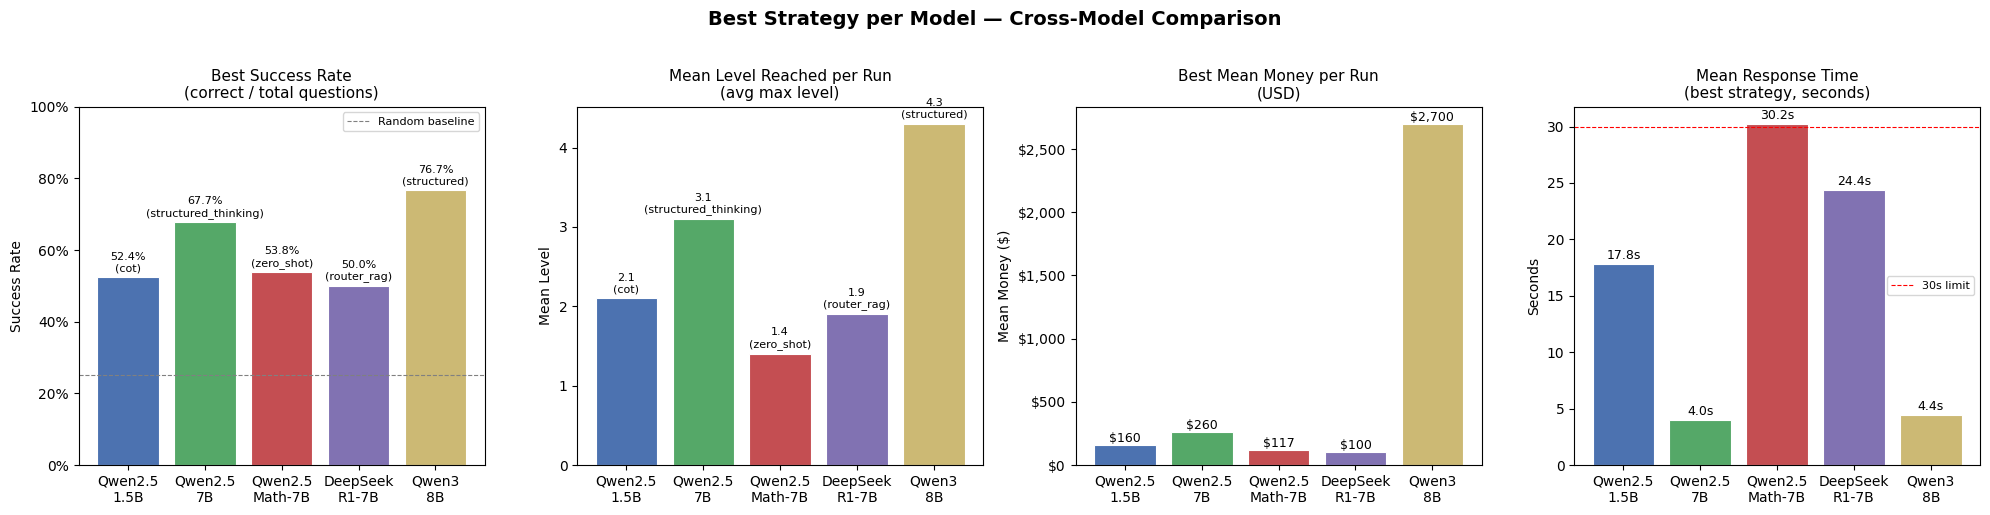

Saved: crossmodel_best_strategy.png


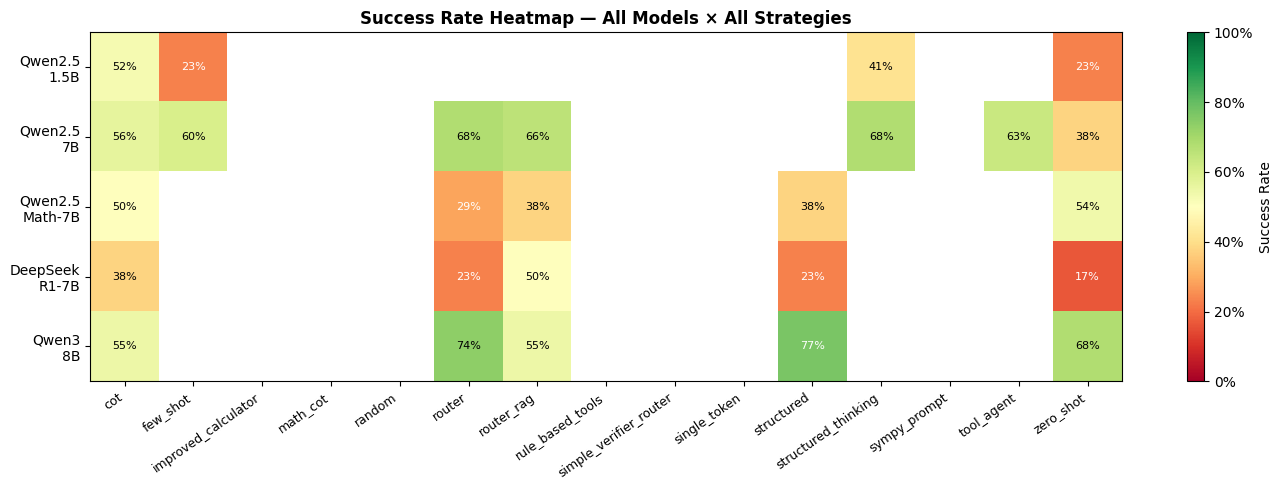

Saved: crossmodel_heatmap.png


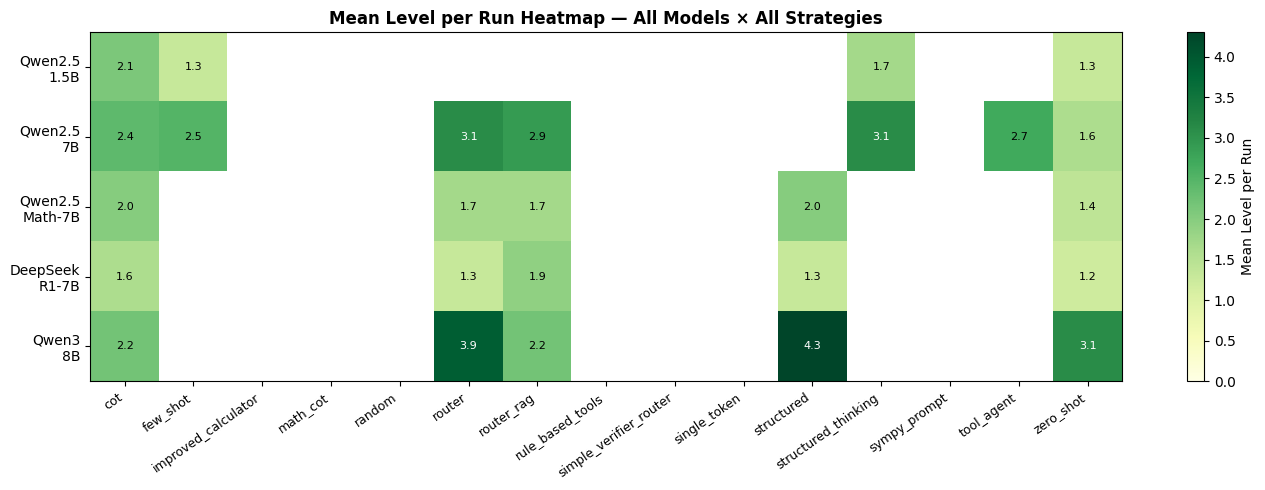

Saved: crossmodel_level_heatmap.png

# Last three models — summary


,model_name,strategy,runs,total_questions,total_correct,success_rate,mean_level_per_run,mean_money_per_run,best_money_per_run,mean_response_time
0,deepseek_r1_qwen_7b,structured,3,3,0,0.000,1.3,0.000000,0.0,62.652996
1,deepseek_r1_qwen_7b,router,3,3,0,0.000,1.3,0.000000,0.0,50.403724
2,deepseek_r1_qwen_7b,router_rag,3,6,3,0.500,1.9,100.000000,200.0,24.366713
3,deepseek_r1_qwen_7b,zero_shot,10,12,2,0.167,1.2,20.000000,100.0,7.700125
4,deepseek_r1_qwen_7b,cot,10,16,6,0.375,1.6,60.000000,200.0,13.495724
5,deepseek_r1_qwen_7b,structured,10,13,3,0.231,1.3,30.000000,100.0,10.403019
6,deepseek_r1_qwen_7b,router,10,13,3,0.231,1.3,30.000000,200.0,19.160324
7,deepseek_r1_qwen_7b,router_rag,10,17,7,0.412,1.9,70.000000,200.0,11.839778
8,qwen3_8b,structured,5,6,1,0.167,4.3,20.000000,100.0,5.727093
9,qwen3_8b,router,5,19,14,0.737,3.9,3300.000000,16000.0,16.086073



# Last three models — error breakdown


,model_name,phase,strategy,error_type,count
0,deepseek_r1_qwen_7b,phase_15_r1_structured,structured,timeout,2
1,deepseek_r1_qwen_7b,phase_15_r1_structured,structured,game_or_submission_error,1
2,deepseek_r1_qwen_7b,phase_16_r1_router,router,timeout,3
3,deepseek_r1_qwen_7b,phase_17_r1_router_rag,router_rag,timeout,3
4,deepseek_r1_qwen_7b,phase_17_r1_zero_shot,zero_shot,parse_failure_random_fallback,10
5,deepseek_r1_qwen_7b,phase_18_r1_cot,cot,parse_failure_random_fallback,8
6,deepseek_r1_qwen_7b,phase_18_r1_cot,cot,wrong_and_invalid_format,2
7,deepseek_r1_qwen_7b,phase_19_r1_structured,structured,parse_failure_random_fallback,8
8,deepseek_r1_qwen_7b,phase_19_r1_structured,structured,wrong_and_invalid_format,2
9,deepseek_r1_qwen_7b,phase_20_r1_router,router,parse_failure_random_fallback,9



# Last three models — category success rate


,model_name,strategy,category,count,correct,success_rate
0,deepseek_r1_qwen_7b,cot,cot,16,6,0.375
1,deepseek_r1_qwen_7b,router,router_numeric,7,3,0.429
2,deepseek_r1_qwen_7b,router,router_general,3,0,0.000
3,deepseek_r1_qwen_7b,router,router_r1_general,1,0,0.000
4,deepseek_r1_qwen_7b,router,router_r1_numeric,1,0,0.000
5,deepseek_r1_qwen_7b,router,router_r1_symbolic,1,0,0.000
6,deepseek_r1_qwen_7b,router,router_symbolic,3,0,0.000
7,deepseek_r1_qwen_7b,router_rag,rag_router_general,4,4,1.000
8,deepseek_r1_qwen_7b,router_rag,rag_router_r1_general,4,3,0.750
9,deepseek_r1_qwen_7b,router_rag,rag_router_numeric,9,3,0.333


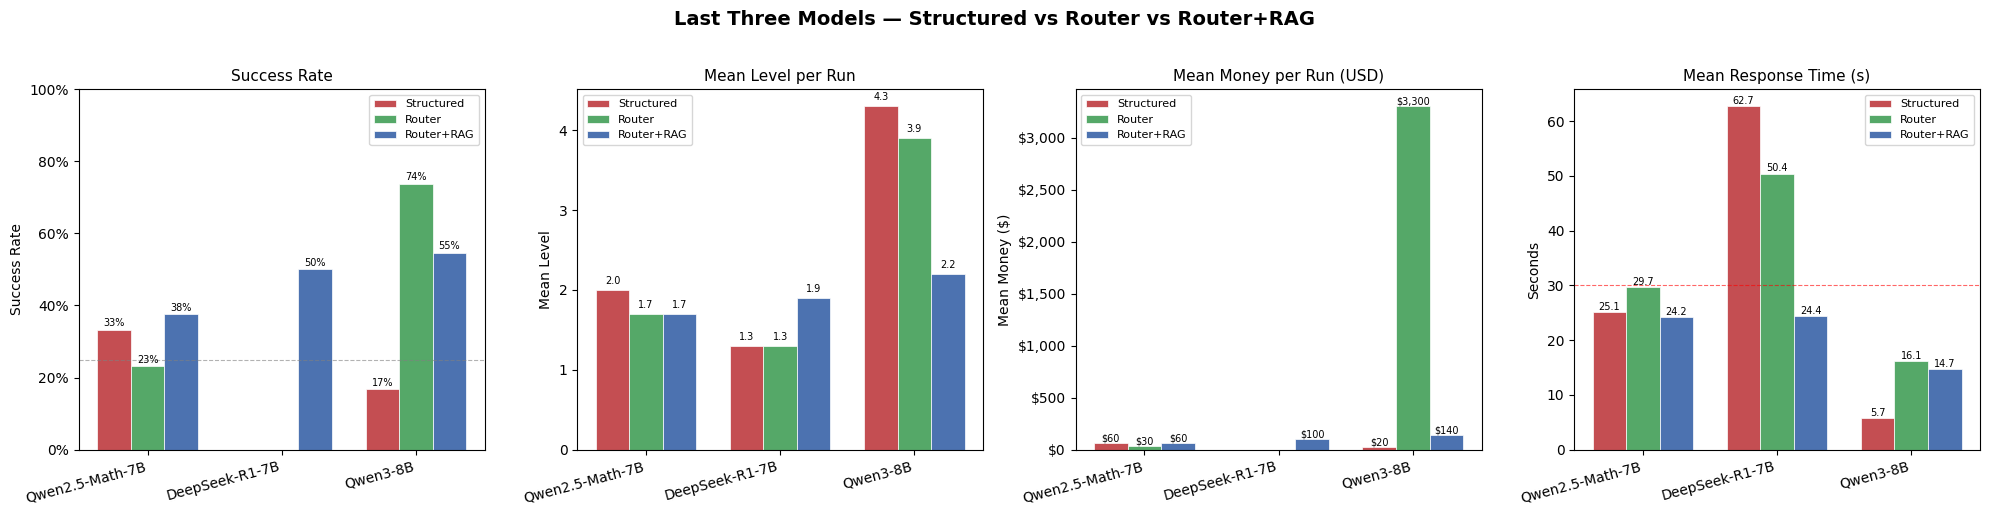

Saved: last3models_strategy_comparison.png


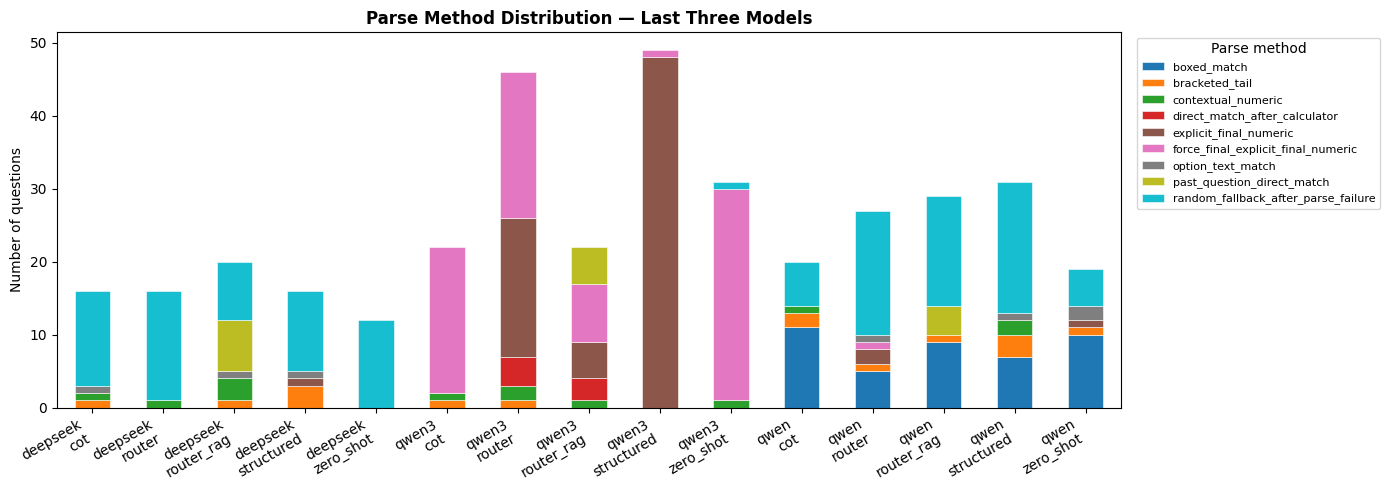

Saved: last3models_parse_methods.png

# Confidence calibration — last three models


,conf_bucket,count,success_rate,random_baseline
0,0.6-0.8,1,1.000,0.25
1,0.8-1.0,97,0.784,0.25



# Key findings — last three models

Best success rate   : qwen3_8b                       structured      76.7%
Best mean money     : qwen3_8b                       router          $3,300/run
Best mean level     : qwen3_8b                       structured      4.3 avg level/run
Fastest             : qwen3_8b                       structured      4.4s

# Key findings — cross-model

Best model overall  : qwen3_8b
  success_rate  = 76.7%
  best strategy = structured

Improvement from 1.5B to best model: 24.3%



In [ ]:
# Global cross-model and last-three-model comparison.
# Loads all saved CSVs — works after runtime restart.

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


# ── Helper: compute mean level per run ───────────────────────────────────────

def add_mean_level(summary_df: pd.DataFrame,
                   raw_df: pd.DataFrame,
                   by: list = None) -> pd.DataFrame:
    """
    Compute mean_level_per_run = average of max(level) per run,
    then merge into an existing summary DataFrame.
    """
    by = by or ["model_name", "strategy"]
    level_per_run = (
        raw_df.groupby(by + ["run_id"], dropna=False)["level"]
        .max()
        .reset_index()
        .rename(columns={"level": "max_level"})
    )
    mean_level = (
        level_per_run.groupby(by, dropna=False)["max_level"]
        .mean()
        .round(2)
        .reset_index()
        .rename(columns={"max_level": "mean_level_per_run"})
    )
    return summary_df.merge(mean_level, on=by, how="left")


# ── Load all results ──────────────────────────────────────────────────────────

df_all = load_all_results(RESULTS_DIR)
print(f"Total rows loaded: {len(df_all)}")
print(f"Models  : {df_all['model_name'].unique().tolist()}")
print(f"Phases  : {sorted(df_all['phase'].unique().tolist())}")

# ── Summary tables ────────────────────────────────────────────────────────────

summary_all = summarize_runs(df_all)
summary_all = add_mean_level(summary_all, df_all)

print("\n# Global summary — all models all strategies")
display(summary_all[[
    "model_name", "strategy", "runs", "total_questions",
    "total_correct", "success_rate", "mean_correct_per_run",
    "mean_level_per_run", "mean_money_per_run", "best_money_per_run",
    "mean_response_time",
]])

print("\n# Global error breakdown")
display(error_table(df_all))

print("\n# Global decision matrix")
display(decision_matrix(df_all))


# ═══════════════════════════════════════════════════════════════════════════
# PART A — Cross-model comparison
# ═══════════════════════════════════════════════════════════════════════════

best_per_model = (
    summary_all.sort_values("success_rate", ascending=False)
    .groupby("model_name", sort=False)
    .first()
    .reset_index()
)

model_order  = ["qwen_1_5b", "qwen_7b", "qwen_math_7b",
                "deepseek_r1_qwen_7b", "qwen3_8b"]
model_labels = ["Qwen2.5\n1.5B", "Qwen2.5\n7B", "Qwen2.5\nMath-7B",
                "DeepSeek\nR1-7B", "Qwen3\n8B"]
model_colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]

best_plot = (
    best_per_model.set_index("model_name")
    .reindex(model_order)
    .reset_index()
)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle("Best Strategy per Model — Cross-Model Comparison",
             fontsize=14, fontweight="bold", y=1.02)

# Success rate
ax = axes[0]
bars = ax.bar(model_labels, best_plot["success_rate"].fillna(0),
              color=model_colors, edgecolor="white", linewidth=0.8)
ax.set_title("Best Success Rate\n(correct / total questions)", fontsize=11)
ax.set_ylabel("Success Rate")
ax.set_ylim(0, 1.0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.axhline(0.25, color="gray", linestyle="--", linewidth=0.8,
           label="Random baseline")
ax.legend(fontsize=8)
for bar, val, strat in zip(bars,
                            best_plot["success_rate"].fillna(0),
                            best_plot["strategy"].fillna("")):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{val:.1%}\n({strat})",
            ha="center", va="bottom", fontsize=8)

# Mean level per run
ax = axes[1]
bars = ax.bar(model_labels, best_plot["mean_level_per_run"].fillna(0),
              color=model_colors, edgecolor="white", linewidth=0.8)
ax.set_title("Mean Level Reached per Run\n(avg max level)", fontsize=11)
ax.set_ylabel("Mean Level")
for bar, val, strat in zip(bars,
                            best_plot["mean_level_per_run"].fillna(0),
                            best_plot["strategy"].fillna("")):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f"{val:.1f}\n({strat})",
            ha="center", va="bottom", fontsize=8)

# Mean money per run
ax = axes[2]
bars = ax.bar(model_labels, best_plot["mean_money_per_run"].fillna(0),
              color=model_colors, edgecolor="white", linewidth=0.8)
ax.set_title("Best Mean Money per Run\n(USD)", fontsize=11)
ax.set_ylabel("Mean Money ($)")
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x:,.0f}")
)
for bar, val in zip(bars, best_plot["mean_money_per_run"].fillna(0)):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 2,
            f"${val:,.0f}", ha="center", va="bottom", fontsize=9)

# Mean response time
ax = axes[3]
bars = ax.bar(model_labels, best_plot["mean_response_time"].fillna(0),
              color=model_colors, edgecolor="white", linewidth=0.8)
ax.set_title("Mean Response Time\n(best strategy, seconds)", fontsize=11)
ax.set_ylabel("Seconds")
ax.axhline(30, color="red", linestyle="--", linewidth=0.8, label="30s limit")
ax.legend(fontsize=8)
for bar, val in zip(bars, best_plot["mean_response_time"].fillna(0)):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.2,
            f"{val:.1f}s", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(BASE_DIR / "crossmodel_best_strategy.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: crossmodel_best_strategy.png")


# Heatmap — success_rate for every model × strategy combination
pivot_rate = (
    summary_all.pivot_table(
        index="model_name", columns="strategy",
        values="success_rate", aggfunc="max"
    )
    .reindex(model_order)
)

fig, ax = plt.subplots(figsize=(14, 5))
data = pivot_rate.values.astype(float)
im   = ax.imshow(data, aspect="auto", cmap="RdYlGn", vmin=0.0, vmax=1.0)
ax.set_xticks(range(len(pivot_rate.columns)))
ax.set_xticklabels(pivot_rate.columns, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(len(model_order)))
ax.set_yticklabels(model_labels, fontsize=10)
ax.set_title("Success Rate Heatmap — All Models × All Strategies",
             fontsize=12, fontweight="bold")
plt.colorbar(im, ax=ax, label="Success Rate",
             format=mticker.PercentFormatter(xmax=1.0))
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        val = data[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.0%}", ha="center", va="center",
                    fontsize=8,
                    color="black" if 0.3 < val < 0.75 else "white")
plt.tight_layout()
plt.savefig(BASE_DIR / "crossmodel_heatmap.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: crossmodel_heatmap.png")

# Heatmap — mean_level_per_run for every model × strategy combination
pivot_level = (
    summary_all.pivot_table(
        index="model_name", columns="strategy",
        values="mean_level_per_run", aggfunc="max"
    )
    .reindex(model_order)
)

fig, ax = plt.subplots(figsize=(14, 5))
data_l = pivot_level.values.astype(float)
vmax_l = np.nanmax(data_l) if not np.all(np.isnan(data_l)) else 10
im2    = ax.imshow(data_l, aspect="auto", cmap="YlGn",
                   vmin=0.0, vmax=vmax_l)
ax.set_xticks(range(len(pivot_level.columns)))
ax.set_xticklabels(pivot_level.columns, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(len(model_order)))
ax.set_yticklabels(model_labels, fontsize=10)
ax.set_title("Mean Level per Run Heatmap — All Models × All Strategies",
             fontsize=12, fontweight="bold")
plt.colorbar(im2, ax=ax, label="Mean Level per Run")
for i in range(data_l.shape[0]):
    for j in range(data_l.shape[1]):
        val = data_l[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.1f}", ha="center", va="center",
                    fontsize=8,
                    color="black" if val < vmax_l * 0.7 else "white")
plt.tight_layout()
plt.savefig(BASE_DIR / "crossmodel_level_heatmap.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: crossmodel_level_heatmap.png")


# ═══════════════════════════════════════════════════════════════════════════
# PART B — Last three models × three strategies
# ═══════════════════════════════════════════════════════════════════════════

last_three_models = ["qwen_math_7b", "deepseek_r1_qwen_7b", "qwen3_8b"]
last_three_labels = ["Qwen2.5-Math-7B", "DeepSeek-R1-7B", "Qwen3-8B"]
shared_strategies = ["structured", "router", "router_rag"]
strategy_labels_s = ["Structured", "Router", "Router+RAG"]
strategy_colors   = ["#C44E52", "#55A868", "#4C72B0"]

df_last3      = df_all[df_all["model_name"].isin(last_three_models)].copy()
summary_last3 = summarize_runs(df_last3)
summary_last3 = add_mean_level(summary_last3, df_last3)

print("\n# Last three models — summary")
display(summary_last3[[
    "model_name", "strategy", "runs", "total_questions",
    "total_correct", "success_rate", "mean_level_per_run",
    "mean_money_per_run", "best_money_per_run", "mean_response_time",
]])

print("\n# Last three models — error breakdown")
display(error_table(df_last3))

print("\n# Last three models — category success rate")
display(category_accuracy_table(df_last3))


# Grouped bar — 4 metrics including mean level
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle("Last Three Models — Structured vs Router vs Router+RAG",
             fontsize=14, fontweight="bold", y=1.02)

metrics = [
    ("success_rate",       "Success Rate",           True,  "Success Rate",   None),
    ("mean_level_per_run", "Mean Level per Run",      False, "Mean Level",     None),
    ("mean_money_per_run", "Mean Money per Run (USD)",False, "Mean Money ($)", "$"),
    ("mean_response_time", "Mean Response Time (s)",  False, "Seconds",        None),
]

for ax, (col, title, is_pct, ylabel, fmt) in zip(axes, metrics):
    x     = np.arange(len(last_three_models))
    width = 0.25

    for j, (strat, s_label, s_color) in enumerate(
            zip(shared_strategies, strategy_labels_s, strategy_colors)):
        vals = []
        for model in last_three_models:
            row = summary_last3[
                (summary_last3["model_name"] == model) &
                (summary_last3["strategy"]   == strat)
            ]
            vals.append(float(row[col].values[0]) if len(row) else 0.0)

        offset = (j - 1) * width
        bars   = ax.bar(x + offset, vals, width,
                        label=s_label, color=s_color,
                        edgecolor="white", linewidth=0.5)
        for bar, val in zip(bars, vals):
            if val > 0:
                label = (f"{val:.0%}"   if is_pct
                         else f"${val:,.0f}" if fmt == "$"
                         else f"{val:.1f}")
                ax.text(bar.get_x() + bar.get_width() / 2,
                        bar.get_height() + (0.005 if is_pct else 0.05),
                        label, ha="center", va="bottom", fontsize=7)

    ax.set_title(title, fontsize=11)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(last_three_labels, rotation=15, ha="right")
    if is_pct:
        ax.set_ylim(0, 1.0)
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
        ax.axhline(0.25, color="gray", linestyle="--",
                   linewidth=0.8, alpha=0.6)
    elif fmt == "$":
        ax.yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda xv, _: f"${xv:,.0f}")
        )
    elif col == "mean_response_time":
        ax.axhline(30, color="red", linestyle="--",
                   linewidth=0.8, alpha=0.6)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(BASE_DIR / "last3models_strategy_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: last3models_strategy_comparison.png")


# Parse method distribution — last three models
parse_counts = (
    df_last3.groupby(["model_name", "strategy", "parse_method"])
    .size().reset_index(name="count")
)
parse_pivot = (
    parse_counts
    .pivot_table(index=["model_name", "strategy"],
                 columns="parse_method", values="count", aggfunc="sum")
    .fillna(0)
)
parse_pivot.index = [f"{m.split('_')[0]}\n{s}"
                     for m, s in parse_pivot.index]

fig, ax = plt.subplots(figsize=(14, 5))
parse_pivot.plot(kind="bar", stacked=True, ax=ax,
                 colormap="tab10", edgecolor="white", linewidth=0.4)
ax.set_title("Parse Method Distribution — Last Three Models",
             fontsize=12, fontweight="bold")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_ylabel("Number of questions")
ax.legend(title="Parse method", bbox_to_anchor=(1.01, 1),
          loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(BASE_DIR / "last3models_parse_methods.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: last3models_parse_methods.png")


# Confidence calibration
print("\n# Confidence calibration — last three models")
display(confidence_calibration_table(df_last3))


# Key findings
best_row       = summary_last3.loc[summary_last3["success_rate"].idxmax()]
best_money_row = summary_last3.loc[summary_last3["mean_money_per_run"].idxmax()]
best_level_row = summary_last3.loc[summary_last3["mean_level_per_run"].idxmax()]
fastest_row    = summary_last3.loc[summary_last3["mean_response_time"].idxmin()]

print(f"""
# Key findings — last three models

Best success rate   : {best_row['model_name']:<30} {best_row['strategy']:<15} {best_row['success_rate']:.1%}
Best mean money     : {best_money_row['model_name']:<30} {best_money_row['strategy']:<15} ${best_money_row['mean_money_per_run']:,.0f}/run
Best mean level     : {best_level_row['model_name']:<30} {best_level_row['strategy']:<15} {best_level_row['mean_level_per_run']:.1f} avg level/run
Fastest             : {fastest_row['model_name']:<30} {fastest_row['strategy']:<15} {fastest_row['mean_response_time']:.1f}s

# Key findings — cross-model

Best model overall  : {best_plot.loc[best_plot['success_rate'].idxmax(), 'model_name']}
  success_rate  = {best_plot['success_rate'].max():.1%}
  best strategy = {best_plot.loc[best_plot['success_rate'].idxmax(), 'strategy']}

Improvement from 1.5B to best model: {best_plot['success_rate'].max() - best_plot.loc[best_plot['model_name']=='qwen_1_5b','success_rate'].values[0]:.1%}
""")

In [ ]:
# Global cross-model and last-three-model comparison.
# Loads all saved CSVs — works after runtime restart.

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


# ── Load all results ──────────────────────────────────────────────────────────

df_all = load_all_results(RESULTS_DIR)
print(f"Total rows loaded: {len(df_all)}")
print(f"Models  : {df_all['model_name'].unique().tolist()}")
print(f"Phases  : {sorted(df_all['phase'].unique().tolist())}")


# ── Summary tables ────────────────────────────────────────────────────────────

summary_all = summarize_runs(df_all)

print("\n# Global summary — all models all strategies")
display(summary_all[[
    "model_name", "strategy", "runs", "total_questions",
    "total_correct", "success_rate", "mean_correct_per_run",
    "mean_money_per_run", "best_money_per_run", "mean_response_time",
]])

print("\n# Global error breakdown")
display(error_table(df_all))

print("\n# Global decision matrix")
display(decision_matrix(df_all))


# ═══════════════════════════════════════════════════════════════════════════
# PART A — Cross-model comparison
# ═══════════════════════════════════════════════════════════════════════════

best_per_model = (
    summary_all.sort_values("success_rate", ascending=False)
    .groupby("model_name", sort=False)
    .first()
    .reset_index()
)

model_order  = ["qwen_1_5b", "qwen_7b", "qwen_math_7b",
                "deepseek_r1_qwen_7b", "qwen3_8b"]
model_labels = ["Qwen2.5\n1.5B", "Qwen2.5\n7B", "Qwen2.5\nMath-7B",
                "DeepSeek\nR1-7B", "Qwen3\n8B"]
model_colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]

best_plot = (
    best_per_model.set_index("model_name")
    .reindex(model_order)
    .reset_index()
)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle("Best Strategy per Model — Cross-Model Comparison",
             fontsize=14, fontweight="bold", y=1.02)

# Success rate
ax = axes[0]
bars = ax.bar(model_labels, best_plot["success_rate"].fillna(0),
              color=model_colors, edgecolor="white", linewidth=0.8)
ax.set_title("Best Success Rate\n(correct / total questions)", fontsize=11)
ax.set_ylabel("Success Rate")
ax.set_ylim(0, 1.0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.axhline(0.25, color="gray", linestyle="--", linewidth=0.8,
           label="Random baseline")
ax.legend(fontsize=8)
for bar, val, strat in zip(bars,
                            best_plot["success_rate"].fillna(0),
                            best_plot["strategy"].fillna("")):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{val:.1%}\n({strat})",
            ha="center", va="bottom", fontsize=8)

# Mean correct per run (= mean level reached per run)
ax = axes[1]
bars = ax.bar(model_labels, best_plot["mean_correct_per_run"].fillna(0),
              color=model_colors, edgecolor="white", linewidth=0.8)
ax.set_title("Mean Level per Run\n(correct answers / runs)", fontsize=11)
ax.set_ylabel("Mean Level")
for bar, val, strat in zip(bars,
                            best_plot["mean_correct_per_run"].fillna(0),
                            best_plot["strategy"].fillna("")):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f"{val:.1f}\n({strat})",
            ha="center", va="bottom", fontsize=8)

# Mean money per run
ax = axes[2]
bars = ax.bar(model_labels, best_plot["mean_money_per_run"].fillna(0),
              color=model_colors, edgecolor="white", linewidth=0.8)
ax.set_title("Best Mean Money per Run\n(USD)", fontsize=11)
ax.set_ylabel("Mean Money ($)")
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x:,.0f}")
)
for bar, val in zip(bars, best_plot["mean_money_per_run"].fillna(0)):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 2,
            f"${val:,.0f}", ha="center", va="bottom", fontsize=9)

# Mean response time
ax = axes[3]
bars = ax.bar(model_labels, best_plot["mean_response_time"].fillna(0),
              color=model_colors, edgecolor="white", linewidth=0.8)
ax.set_title("Mean Response Time\n(best strategy, seconds)", fontsize=11)
ax.set_ylabel("Seconds")
ax.axhline(30, color="red", linestyle="--", linewidth=0.8, label="30s limit")
ax.legend(fontsize=8)
for bar, val in zip(bars, best_plot["mean_response_time"].fillna(0)):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.2,
            f"{val:.1f}s", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(BASE_DIR / "crossmodel_best_strategy.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: crossmodel_best_strategy.png")


# Heatmap — success_rate for every model × strategy combination
pivot_rate = (
    summary_all.pivot_table(
        index="model_name", columns="strategy",
        values="success_rate", aggfunc="max"
    )
    .reindex(model_order)
)

fig, ax = plt.subplots(figsize=(14, 5))
data = pivot_rate.values.astype(float)
im   = ax.imshow(data, aspect="auto", cmap="RdYlGn", vmin=0.0, vmax=1.0)
ax.set_xticks(range(len(pivot_rate.columns)))
ax.set_xticklabels(pivot_rate.columns, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(len(model_order)))
ax.set_yticklabels(model_labels, fontsize=10)
ax.set_title("Success Rate Heatmap — All Models × All Strategies",
             fontsize=12, fontweight="bold")
plt.colorbar(im, ax=ax, label="Success Rate",
             format=mticker.PercentFormatter(xmax=1.0))
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        val = data[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.0%}", ha="center", va="center",
                    fontsize=8,
                    color="black" if 0.3 < val < 0.75 else "white")
plt.tight_layout()
plt.savefig(BASE_DIR / "crossmodel_heatmap.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: crossmodel_heatmap.png")


# Heatmap — mean_correct_per_run for every model × strategy combination
pivot_level = (
    summary_all.pivot_table(
        index="model_name", columns="strategy",
        values="mean_correct_per_run", aggfunc="max"
    )
    .reindex(model_order)
)

fig, ax = plt.subplots(figsize=(14, 5))
data_l = pivot_level.values.astype(float)
vmax_l = np.nanmax(data_l) if not np.all(np.isnan(data_l)) else 10
im2    = ax.imshow(data_l, aspect="auto", cmap="YlGn",
                   vmin=0.0, vmax=vmax_l)
ax.set_xticks(range(len(pivot_level.columns)))
ax.set_xticklabels(pivot_level.columns, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(len(model_order)))
ax.set_yticklabels(model_labels, fontsize=10)
ax.set_title("Mean Level per Run Heatmap — All Models × All Strategies",
             fontsize=12, fontweight="bold")
plt.colorbar(im2, ax=ax, label="Mean Level per Run\n(correct answers / runs)")
for i in range(data_l.shape[0]):
    for j in range(data_l.shape[1]):
        val = data_l[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.1f}", ha="center", va="center",
                    fontsize=8,
                    color="black" if val < vmax_l * 0.7 else "white")
plt.tight_layout()
plt.savefig(BASE_DIR / "crossmodel_level_heatmap.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: crossmodel_level_heatmap.png")


# ═══════════════════════════════════════════════════════════════════════════
# PART B — Last three models × three strategies
# ═══════════════════════════════════════════════════════════════════════════

last_three_models = ["qwen_math_7b", "deepseek_r1_qwen_7b", "qwen3_8b"]
last_three_labels = ["Qwen2.5-Math-7B", "DeepSeek-R1-7B", "Qwen3-8B"]
shared_strategies = ["structured", "router", "router_rag"]
strategy_labels_s = ["Structured", "Router", "Router+RAG"]
strategy_colors   = ["#C44E52", "#55A868", "#4C72B0"]

df_last3      = df_all[df_all["model_name"].isin(last_three_models)].copy()
summary_last3 = summarize_runs(df_last3)

print("\n# Last three models — summary")
display(summary_last3[[
    "model_name", "strategy", "runs", "total_questions",
    "total_correct", "success_rate", "mean_correct_per_run",
    "mean_money_per_run", "best_money_per_run", "mean_response_time",
]])

print("\n# Last three models — error breakdown")
display(error_table(df_last3))

print("\n# Last three models — category success rate")
display(category_accuracy_table(df_last3))


# Grouped bar — 4 metrics including mean level per run
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle("Last Three Models — Structured vs Router vs Router+RAG",
             fontsize=14, fontweight="bold", y=1.02)

metrics = [
    ("success_rate",       "Success Rate",                    True,  "Success Rate",   None),
    ("mean_correct_per_run","Mean Level per Run\n(correct/runs)",False,"Mean Level",    None),
    ("mean_money_per_run", "Mean Money per Run (USD)",         False, "Mean Money ($)", "$"),
    ("mean_response_time", "Mean Response Time (s)",           False, "Seconds",        None),
]

for ax, (col, title, is_pct, ylabel, fmt) in zip(axes, metrics):
    x     = np.arange(len(last_three_models))
    width = 0.25

    for j, (strat, s_label, s_color) in enumerate(
            zip(shared_strategies, strategy_labels_s, strategy_colors)):
        vals = []
        for model in last_three_models:
            row = summary_last3[
                (summary_last3["model_name"] == model) &
                (summary_last3["strategy"]   == strat)
            ]
            vals.append(float(row[col].values[0]) if len(row) else 0.0)

        offset = (j - 1) * width
        bars   = ax.bar(x + offset, vals, width,
                        label=s_label, color=s_color,
                        edgecolor="white", linewidth=0.5)
        for bar, val in zip(bars, vals):
            if val > 0:
                label = (f"{val:.0%}"    if is_pct
                         else f"${val:,.0f}" if fmt == "$"
                         else f"{val:.1f}")
                ax.text(bar.get_x() + bar.get_width() / 2,
                        bar.get_height() + (0.005 if is_pct else 0.05),
                        label, ha="center", va="bottom", fontsize=7)

    ax.set_title(title, fontsize=11)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(last_three_labels, rotation=15, ha="right")
    if is_pct:
        ax.set_ylim(0, 1.0)
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
        ax.axhline(0.25, color="gray", linestyle="--",
                   linewidth=0.8, alpha=0.6)
    elif fmt == "$":
        ax.yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda xv, _: f"${xv:,.0f}")
        )
    elif col == "mean_response_time":
        ax.axhline(30, color="red", linestyle="--",
                   linewidth=0.8, alpha=0.6)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(BASE_DIR / "last3models_strategy_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: last3models_strategy_comparison.png")


# Parse method distribution — last three models
parse_counts = (
    df_last3.groupby(["model_name", "strategy", "parse_method"])
    .size().reset_index(name="count")
)
parse_pivot = (
    parse_counts
    .pivot_table(index=["model_name", "strategy"],
                 columns="parse_method", values="count", aggfunc="sum")
    .fillna(0)
)
parse_pivot.index = [f"{m.split('_')[0]}\n{s}"
                     for m, s in parse_pivot.index]

fig, ax = plt.subplots(figsize=(14, 5))
parse_pivot.plot(kind="bar", stacked=True, ax=ax,
                 colormap="tab10", edgecolor="white", linewidth=0.4)
ax.set_title("Parse Method Distribution — Last Three Models",
             fontsize=12, fontweight="bold")
ax.set_xlabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_ylabel("Number of questions")
ax.legend(title="Parse method", bbox_to_anchor=(1.01, 1),
          loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(BASE_DIR / "last3models_parse_methods.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: last3models_parse_methods.png")


# Confidence calibration
print("\n# Confidence calibration — last three models")
display(confidence_calibration_table(df_last3))


# Key findings
best_row       = summary_last3.loc[summary_last3["success_rate"].idxmax()]
best_money_row = summary_last3.loc[summary_last3["mean_money_per_run"].idxmax()]
best_level_row = summary_last3.loc[summary_last3["mean_correct_per_run"].idxmax()]
fastest_row    = summary_last3.loc[summary_last3["mean_response_time"].idxmin()]

print(f"""
# Key findings — last three models

Best success rate   : {best_row['model_name']:<30} {best_row['strategy']:<15} {best_row['success_rate']:.1%}
Best mean money     : {best_money_row['model_name']:<30} {best_money_row['strategy']:<15} ${best_money_row['mean_money_per_run']:,.0f}/run
Best mean level     : {best_level_row['model_name']:<30} {best_level_row['strategy']:<15} {best_level_row['mean_correct_per_run']:.1f} correct/run
Fastest             : {fastest_row['model_name']:<30} {fastest_row['strategy']:<15} {fastest_row['mean_response_time']:.1f}s

# Key findings — cross-model

Best model overall  : {best_plot.loc[best_plot['success_rate'].idxmax(), 'model_name']}
  success_rate  = {best_plot['success_rate'].max():.1%}
  best strategy = {best_plot.loc[best_plot['success_rate'].idxmax(), 'strategy']}

Improvement from 1.5B to best model: {best_plot['success_rate'].max() - best_plot.loc[best_plot['model_name']=='qwen_1_5b','success_rate'].values[0]:.1%}
""")

## 25. Speech Mode — Qwen2.5-7B-Instruct

The game API supports a speech mode where questions and options are
delivered as audio instead of text. This section tests four strategies
on Qwen2.5-7B using Whisper for transcription.

### Pipeline

```text fetch_audio_question() → Whisper → question text
fetch_audio_option_next() × 4 → Whisper → option texts
[30s timer starts after option D]
make_speech_wrapper(answer_fn) → LLM → Final Answer ID
game.answer(option_id)
```

### Speech wrapper

`make_speech_wrapper` wraps any existing answer function without
changing its internal logic. It injects the A/B/C/D → 0/1/2/3 mapping
explicitly into each option text so the model outputs the correct
`Final Answer ID` even when option D transcribes as garbage.

### Strategies tested

| Strategy | Why |
|---|---|
| Structured | Fastest, best format compliance |
| CoT | Deeper reasoning for complex questions |
| Router | Most robust — calculator bypasses option text matching |
| Router+RAG | Router with past question memory |

In [ ]:
# Install Whisper and load model.

import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                       "openai-whisper", "soundfile"])

import whisper
import torch
import time
import tempfile
import os
from IPython.display import Audio, display

print("Loading Whisper tiny model...")
whisper_model = whisper.load_model("tiny")
print("Whisper loaded.")


def transcribe_audio(audio_bytes: bytes) -> str:
    """Transcribe WAV audio bytes to text using Whisper tiny."""
    with tempfile.NamedTemporaryFile(suffix=".wav", delete=False) as f:
        f.write(audio_bytes)
        tmp_path = f.name
    try:
        result = whisper_model.transcribe(
            tmp_path,
            language="en",
            fp16=torch.cuda.is_available(),
            verbose=False,
        )
        return result["text"].strip()
    except Exception as e:
        print(f"  [WHISPER] failed: {e}")
        return ""
    finally:
        os.unlink(tmp_path)


print("transcribe_audio ready.")

Loading Whisper tiny model...
Whisper loaded.
transcribe_audio ready.


In [ ]:
# Speech wrapper and game runner.
# make_speech_wrapper wraps any existing answer function — no logic changes.
# play_game_llm replaces human input() with the wrapped answer function.

def make_speech_wrapper(answer_fn):
    """
    Wraps any existing answer function for speech mode.
    Injects explicit A/B/C/D → 0/1/2/3 mapping into option texts so the
    model outputs the correct Final Answer ID even when option D transcribes
    as garbage. Router, calculator, SymPy, parser — all unchanged.
    """
    def wrapped(question, options, level=None):
        speech_options = []
        for i, opt in enumerate(options):
            opt_id  = opt.get("id", i) if isinstance(opt, dict) \
                      else getattr(opt, "id", i)
            opt_txt = opt.get("text", "") if isinstance(opt, dict) \
                      else getattr(opt, "text", str(opt))
            letter  = chr(65 + i)
            speech_options.append({
                "id":   opt_id,
                "text": f"(Option {letter} = Answer ID {opt_id}) {opt_txt}",
            })
        return answer_fn(question, speech_options, level=level)
    return wrapped


# Wrap the four strategies for speech mode
speech_structured_fn  = make_speech_wrapper(structured_strong_answer_fn)
speech_cot_fn         = make_speech_wrapper(cot_strong_answer_fn)
speech_router_fn      = make_speech_wrapper(router_answer_fn)
speech_router_rag_fn  = make_speech_wrapper(router_rag_answer_fn)

print("Speech wrappers created:")
print("  speech_structured_fn  ← structured_strong_answer_fn")
print("  speech_cot_fn         ← cot_strong_answer_fn")
print("  speech_router_fn      ← router_answer_fn")
print("  speech_router_rag_fn  ← router_rag_answer_fn")


def play_game_llm(answer_fn, n_runs: int = 5,
                  model_key: str = "qwen_7b",
                  strategy: str = "structured",
                  phase: str = "speech_test"):
    """
    Speech mode game runner using LLM to answer.
    Fetches audio, transcribes, passes to answer_fn, submits.
    Timer starts after option D is fetched.
    """
    all_results = []

    for run_id in range(1, n_runs + 1):
        print(f"\n{'='*60}")
        print(f"=== {model_key} | {phase} | {strategy} | run={run_id} ===")
        print(f"{'='*60}")

        game = client.game.start(competition_id=comp_id, mode="speech")
        print(f"Session: {game.session_id}")

        run_results = []

        while game.in_progress:
            level = game.current_level
            print(f"\n--- Level {level} ---")

            print("  Fetching question audio...")
            try:
                q_audio = game.fetch_audio_question()
            except Exception as e:
                print(f"  Error: {e}")
                break

            t0     = time.time()
            q_text = transcribe_audio(q_audio)
            print(f"  Q ({time.time()-t0:.2f}s): {q_text[:120]}")

            option_texts = []
            option_ids   = []

            for i in range(4):
                letter = chr(65 + i)
                try:
                    opt_audio = game.fetch_audio_option_next()
                except Exception as e:
                    print(f"  Error option {letter}: {e}")
                    break

                t0       = time.time()
                opt_text = transcribe_audio(opt_audio)
                option_texts.append(opt_text)
                print(f"  [{i}] ({letter}) {opt_text[:60]}  "
                      f"({time.time()-t0:.2f}s)")

                if game.current_question and \
                   i < len(game.current_question.options):
                    option_ids.append(game.current_question.options[i].id)
                else:
                    option_ids.append(i)

            # Timer starts after option D is fetched
            timer_start = time.time()
            game.refresh_state()
            print(f"  Time remaining: {game.time_remaining:.1f}s")

            if len(option_texts) < 4:
                print("  Could not get all options.")
                break

            options = [{"id": option_ids[i], "text": option_texts[i]}
                       for i in range(4)]

            t0 = time.time()
            try:
                result_dict = answer_fn(q_text, options, level=level)
            except Exception as e:
                print(f"  LLM error: {e}")
                result_dict = {
                    "selected_answer_id": None,
                    "confidence":         None,
                    "parse_method":       "error",
                    "parse_warning":      str(e),
                    "invalid_format":     True,
                    "category":           "error",
                    "raw_response":       "",
                    "tool_info":          {},
                    "rag_info":           {},
                }

            llm_time   = time.time() - t0
            total_time = time.time() - timer_start
            answer_id  = result_dict.get("selected_answer_id")

            print(f"  LLM: id={answer_id}  "
                  f"method={result_dict.get('parse_method')}  "
                  f"llm={llm_time:.2f}s  total={total_time:.2f}s")

            if answer_id is None:
                import random
                answer_id = random.choice(option_ids)
                print(f"  [FALLBACK] random: {answer_id}")

            try:
                result = game.answer(answer_id)
            except Exception as e:
                print(f"  Submission error: {e}")
                break

            is_correct = result.correct
            earned     = result.earned_amount
            print(f"  -> correct={is_correct}  "
                  f"money=${earned:,.0f}  "
                  f"time_used={total_time:.2f}s")

            run_results.append({
                "model_name":         model_key,
                "phase":              phase,
                "strategy":           strategy,
                "mode":               "speech",
                "run_id":             run_id,
                "level":              level,
                "question":           q_text,
                "option_0":           option_texts[0] if len(option_texts) > 0 else "",
                "option_1":           option_texts[1] if len(option_texts) > 1 else "",
                "option_2":           option_texts[2] if len(option_texts) > 2 else "",
                "option_3":           option_texts[3] if len(option_texts) > 3 else "",
                "selected_answer_id": answer_id,
                "is_correct":         is_correct,
                "money_earned":       earned,
                "raw_response":       result_dict.get("raw_response", ""),
                "parse_method":       result_dict.get("parse_method"),
                "parse_warning":      result_dict.get("parse_warning"),
                "invalid_format":     result_dict.get("invalid_format", False),
                "confidence":         result_dict.get("confidence"),
                "category":           result_dict.get("category"),
                "tool_info":          str(result_dict.get("tool_info", {})),
                "rag_info":           str(result_dict.get("rag_info", {})),
                "response_time_sec":  total_time,
                "llm_time_sec":       llm_time,
            })

            if result.timed_out or result.game_over or not result.correct:
                print(f"  Game ended. Earned: ${earned:,.0f}")
                break

        all_results.extend(run_results)

        if run_results:
            n_correct = sum(1 for r in run_results if r["is_correct"])
            run_money = run_results[-1]["money_earned"]
            print(f"\n  Run {run_id}: {n_correct}/{len(run_results)} correct  "
                  f"money=${run_money:,.0f}")

    df = pd.DataFrame(all_results)
    if not df.empty:
        out = RESULTS_DIR / f"{model_key}__{phase}__speech_results.csv"
        df.to_csv(out, index=False)
        print(f"\nSaved {len(df)} rows → {out}")
        print(f"\n=== SPEECH SUMMARY: {strategy} ===")
        print(f"  Total questions : {len(df)}")
        print(f"  Success rate    : {df['is_correct'].mean():.3f}")
        print(f"  Mean LLM time   : {df['llm_time_sec'].mean():.2f}s")
        print(f"  Mean total time : {df['response_time_sec'].mean():.2f}s")
        print(f"  Max total time  : {df['response_time_sec'].max():.2f}s")

    return df


print("play_game_llm ready.")

Speech wrappers created:
  speech_structured_fn  ← structured_strong_answer_fn
  speech_cot_fn         ← cot_strong_answer_fn
  speech_router_fn      ← router_answer_fn
  speech_router_rag_fn  ← router_rag_answer_fn
play_game_llm ready.


In [ ]:
# Run speech mode on Qwen2.5-7B — 4 strategies, 5 runs each.

assert current_model_key == "qwen3_8b", \
    f"Expected qwen_8b but {current_model_key} is loaded."

SPEECH_STRATEGIES = [
    ("speech_structured",  speech_structured_fn,  "structured"),
    ("speech_cot",         speech_cot_fn,          "cot"),
    ("speech_router",      speech_router_fn,       "router"),
    ("speech_router_rag",  speech_router_rag_fn,   "router_rag"),
]

speech_frames = []

for phase, fn, strategy_name in SPEECH_STRATEGIES:
    print(f"\n{'='*60}")
    print(f"SPEECH MODE: {phase}")
    print(f"{'='*60}")
    df_s = play_game_llm(
        answer_fn    = fn,
        n_runs       = 5,
        model_key    = current_model_key,
        strategy     = strategy_name,
        phase        = phase,
    )
    speech_frames.append(df_s)

import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    df_speech_all = pd.concat(speech_frames, ignore_index=True)

df_speech_all.to_csv(
    RESULTS_DIR / f"{current_model_key}__speech_all_strategies.csv",
    index=False,
)

print("\n" + "="*60)
print(f"SPEECH MODE — ALL STRATEGIES ({current_model_key})")
print("="*60)
display(
    df_speech_all.groupby("strategy")
    .agg(
        runs         = ("run_id",           "nunique"),
        questions    = ("question",          "count"),
        success_rate = ("is_correct",        lambda x: round(float(x.mean()), 3)),
        mean_llm_s   = ("llm_time_sec",      lambda x: round(float(x.mean()), 2)),
        mean_total_s = ("response_time_sec", lambda x: round(float(x.mean()), 2)),
        max_total_s  = ("response_time_sec", lambda x: round(float(x.max()),  2)),
    )
    .reset_index()
    .sort_values("success_rate", ascending=False)
)


SPEECH MODE: speech_structured

=== qwen3_8b | speech_structured | structured | run=1 ===
Session: 371911

--- Level 1 ---
  Fetching question audio...


100%|██████████| 584/584 [00:01<00:00, 520.76frames/s]


  Q (2.29s): Whits of the following is true about any discrete probability distribution of a random variable X.


100%|██████████| 552/552 [00:00<00:00, 3799.13frames/s]


  [0] (A) Option A. The sum of all possible values of x is equal to 1.  (0.28s)


...

100%|██████████| 840/840 [00:00<00:00, 5721.60frames/s]
Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  [3] (D) Toppsin D The shapes of the population distributions are not  (0.28s)
  Time remaining: 29.4s
  [ROUTER_RAG] category=general
  [ROUTER_RAG] branch=smart_rag_general
  [ROUTER_RAG] branch=rag_cot  context=1805 chars
  [RAG] past question found but options shuffled — using as context
  [RAG] retrieved context (1805 chars)


Both `max_new_tokens` (=48) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  LLM: id=0  method=force_final_explicit_final_numeric  llm=33.61s  total=33.73s
  -> correct=None  money=$0  time_used=33.73s
  Game ended. Earned: $0

  Run 5: 0/1 correct  money=$0

Saved 5 rows → /content/gdrive/MyDrive/polimillionaire_math_outputs/results/qwen3_8b__speech_router_rag__speech_results.csv

=== SPEECH SUMMARY: router_rag ===
  Total questions : 5
  Success rate    : nan
  Mean LLM time   : 41.61s
  Mean total time : 41.73s
  Max total time  : 53.68s

SPEECH MODE — ALL STRATEGIES (qwen3_8b)


,strategy,runs,questions,success_rate,mean_llm_s,mean_total_s,max_total_s
0,cot,5,10,0.667,20.43,20.56,21.99
3,structured,5,8,0.375,13.87,13.99,18.23
1,router,5,5,NaN,43.68,43.80,48.38
2,router_rag,5,5,NaN,41.61,41.73,53.68


## 26. Speech Mode Analysis + Final Global Comparison

Two parts:

**Part A — Speech mode analysis**
Four strategies compared in speech mode on Qwen2.5-7B.
Whisper transcription quality, response times, and success rates.

**Part B — Speech vs text comparison**
Direct comparison of each strategy in text mode vs speech mode.
Answers: how much does audio transcription degrade performance?

  Loaded: qwen3_8b__speech_structured__speech_results.csv
  Loaded: qwen3_8b__speech_zero_shot__speech_results.csv
  Loaded: qwen3_8b__speech_router__speech_results.csv
  Loaded: qwen3_8b__speech_cot__speech_results.csv
  Loaded: qwen3_8b__speech_router_rag__speech_results.csv

Total speech rows : 38
Model             : qwen3_8b
Strategies        : ['structured', 'zero_shot', 'router', 'cot', 'router_rag']

# Speech mode summary — qwen3_8b


,strategy,runs,questions,success_rate,mean_correct_per_run,mean_money,best_money,mean_llm_s,mean_total_s,max_total_s
0,structured,5,8,0.375,0.6,87.5,200,13.872020,13.992446,18.234246
1,zero_shot,5,10,0.5,1.0,110.0,200,6.975419,7.095392,8.216026
2,cot,5,10,0.666667,1.2,130.0,200,20.425974,20.556887,21.990452
3,router,5,5,NaN,0.0,0.0,0,43.678199,43.797701,48.383497
4,router_rag,5,5,NaN,0.0,0.0,0,41.607120,41.728461,53.676488


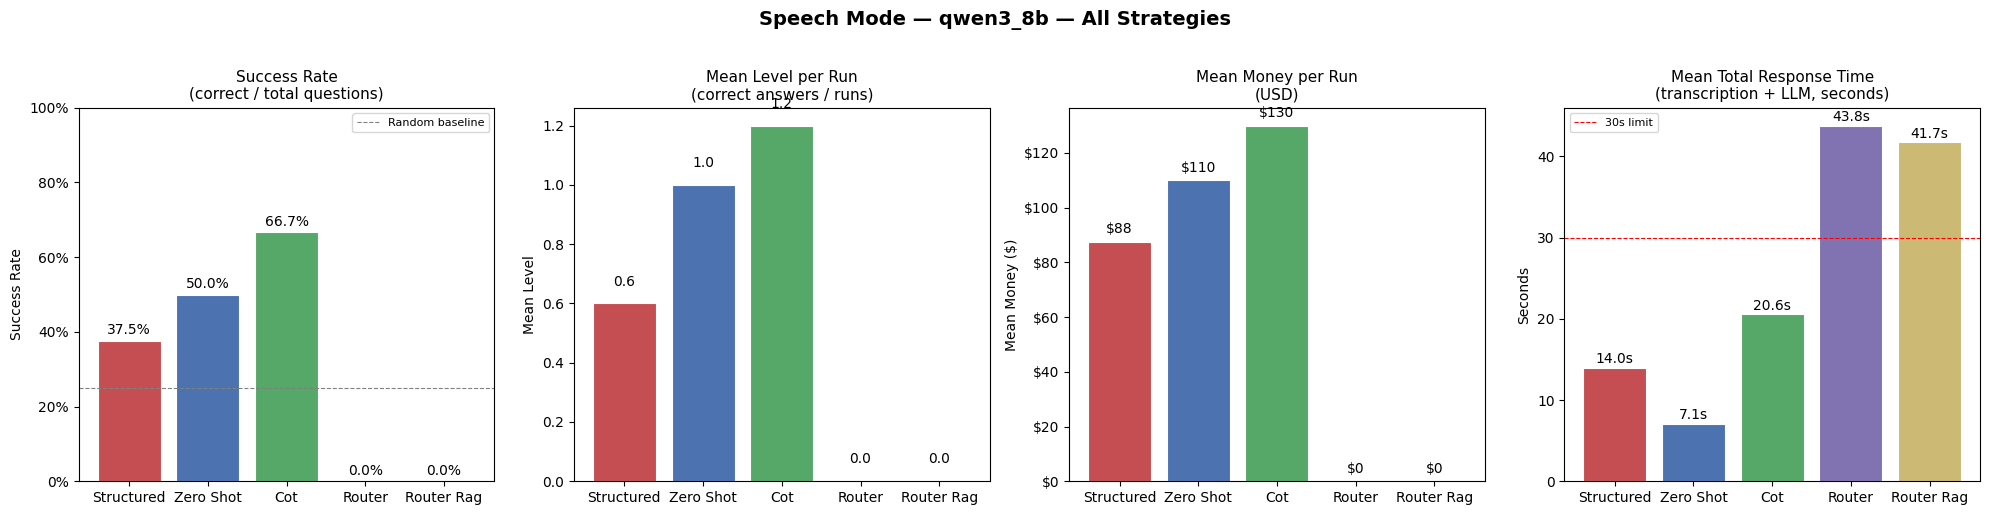

Saved: speech_strategy_comparison.png


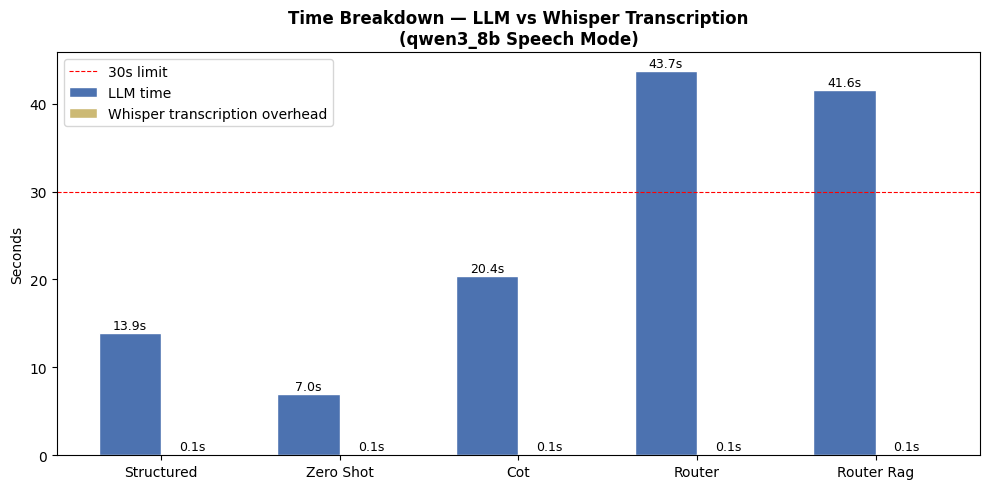

Saved: speech_time_breakdown.png


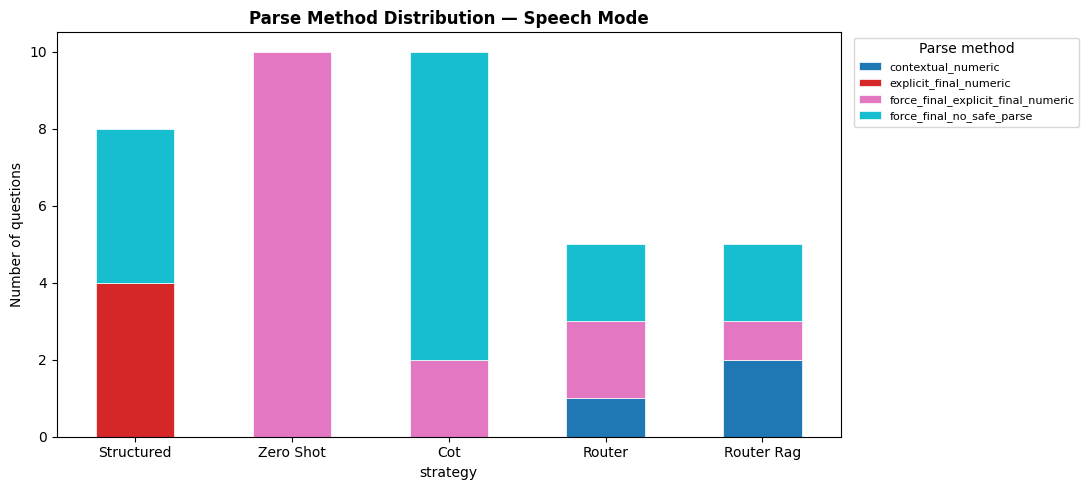

Saved: speech_parse_methods.png

# Speech vs Text mode comparison — qwen3_8b


,strategy,text_success_rate,text_mean_level,text_mean_time_s,speech_success_rate,speech_mean_level,speech_mean_time_s,success_rate_drop,level_drop,time_increase_s
0,structured,0.694,3.4,4.60,0.375,0.6,13.99,0.319,2.8,9.39
1,zero_shot,0.677,2.1,6.75,0.5,1.0,7.10,0.177,1.1,0.35
2,cot,0.545,1.2,14.54,0.666667,1.2,20.56,-0.121667,0.0,6.02
3,router,0.674,3.1,17.46,NaN,0.0,43.80,NaN,3.1,26.34
4,router_rag,0.464,1.3,11.85,NaN,0.0,41.73,NaN,1.3,29.88


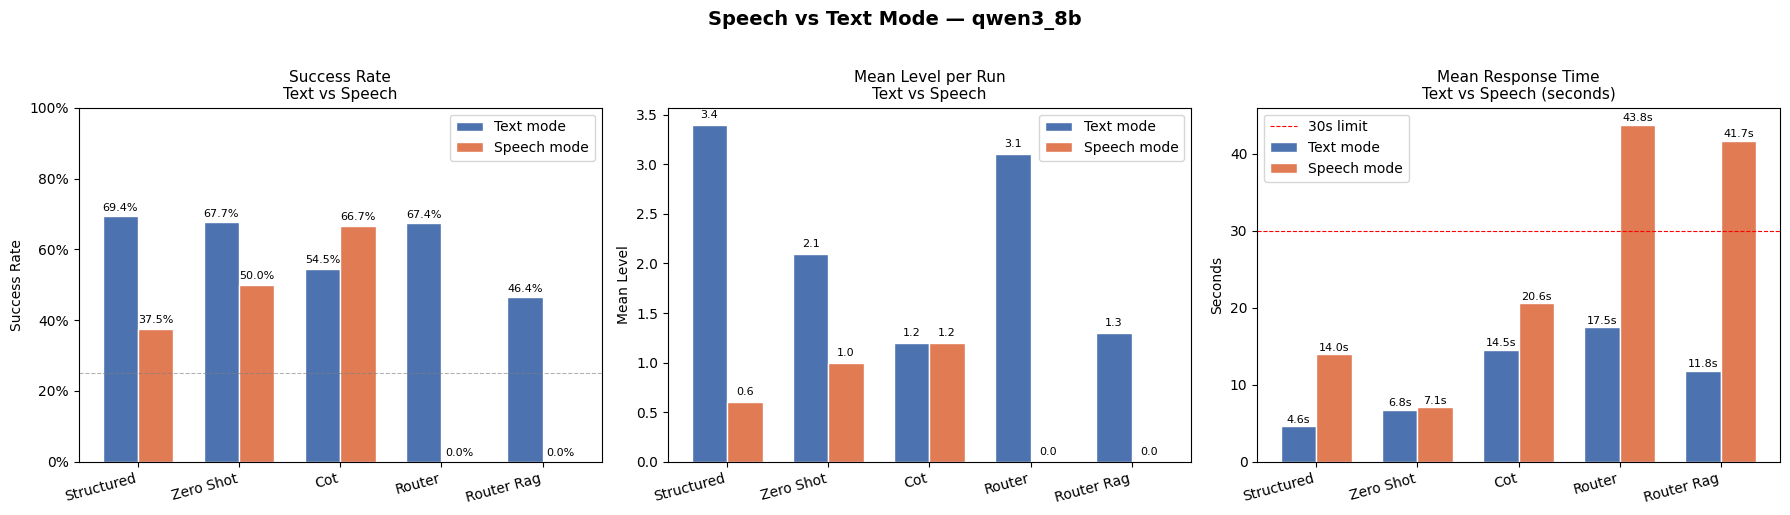

Saved: speech_vs_text_comparison.png


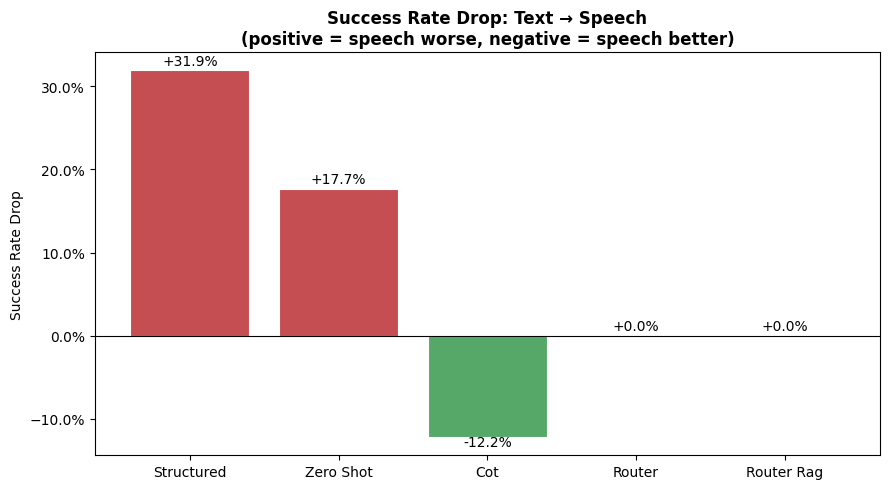

Saved: speech_vs_text_drop.png


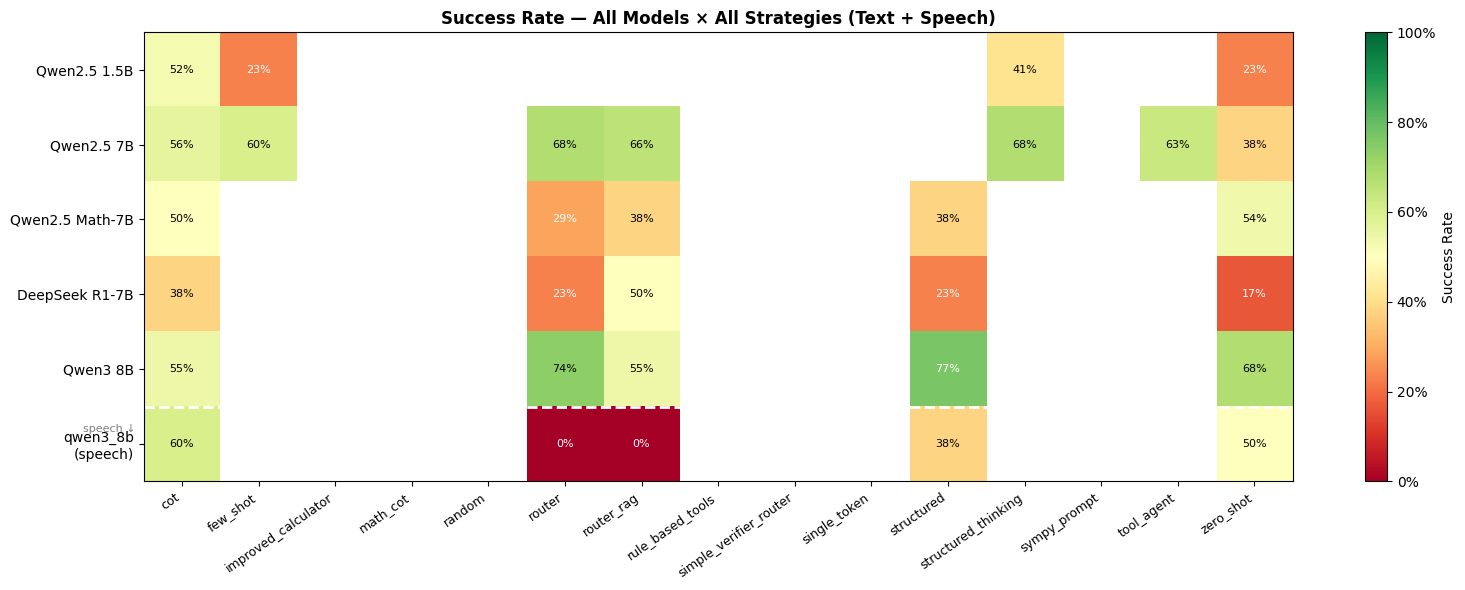

Saved: full_global_heatmap.png


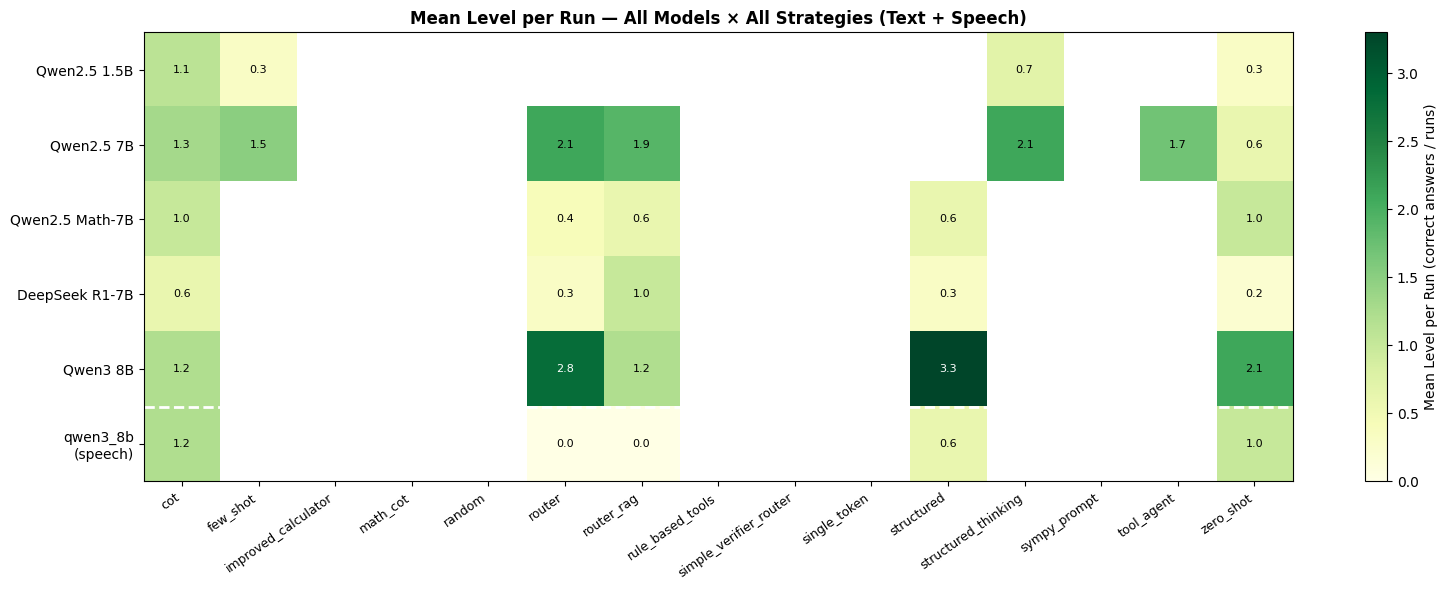

Saved: full_global_level_heatmap.png

# Key findings — speech mode

Best speech strategy           : cot                  66.7%
Most robust (text→speech drop) : cot                  -12.2%
Least robust                   : structured           +31.9%
Mean Whisper overhead          : 14.4s per question



In [ ]:
# Speech mode analysis + speech vs text comparison + full global heatmaps.

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


# ── Load speech results ───────────────────────────────────────────────────────

speech_files = list(RESULTS_DIR.glob("qwen3_8b__speech_*__speech_results.csv"))
if not speech_files:
    speech_files = [RESULTS_DIR / "qwen3_8b__speech_all_strategies.csv"]
if not speech_files:
    speech_files = [RESULTS_DIR / "speech_all_strategies.csv"]

speech_frames = []
for p in speech_files:
    if p.exists():
        speech_frames.append(pd.read_csv(p))
        print(f"  Loaded: {p.name}")

assert speech_frames, "No speech result files found."

df_speech    = pd.concat(speech_frames, ignore_index=True).drop_duplicates()
speech_model = df_speech["model_name"].iloc[0]

print(f"\nTotal speech rows : {len(df_speech)}")
print(f"Model             : {speech_model}")
print(f"Strategies        : {df_speech['strategy'].unique().tolist()}")

# Detect strategies from actual data
strategy_order  = [s for s in
                   ["structured", "zero_shot", "cot", "router", "router_rag"]
                   if s in df_speech["strategy"].unique()]
strategy_labels = [s.replace("_", " ").title() for s in strategy_order]
colors          = ["#C44E52", "#4C72B0", "#55A868",
                   "#8172B2", "#CCB974"][:len(strategy_order)]


# ── Speech summary ────────────────────────────────────────────────────────────

speech_sr = (
    df_speech.groupby("strategy")["is_correct"]
    .mean().round(3).reset_index()
    .rename(columns={"is_correct": "success_rate"})
)

# mean_correct_per_run = total correct / total runs for each strategy
speech_mcpr = (
    df_speech.groupby(["strategy", "run_id"])["is_correct"]
    .sum().reset_index()
    .groupby("strategy")["is_correct"]
    .mean().round(2).reset_index()
    .rename(columns={"is_correct": "mean_correct_per_run"})
)

speech_money = (
    df_speech.groupby("strategy")["money_earned"]
    .agg(mean_money="mean", best_money="max")
    .reset_index()
)

speech_time = (
    df_speech.groupby("strategy")
    .agg(
        mean_llm_s   = ("llm_time_sec",      "mean"),
        mean_total_s = ("response_time_sec",  "mean"),
        max_total_s  = ("response_time_sec",  "max"),
        runs         = ("run_id",             "nunique"),
        questions    = ("question",           "count"),
    )
    .reset_index()
)

speech_summary = (
    speech_sr
    .merge(speech_mcpr,  on="strategy", how="left")
    .merge(speech_money, on="strategy", how="left")
    .merge(speech_time,  on="strategy", how="left")
    .set_index("strategy")
    .reindex(strategy_order)
    .reset_index()
)

print(f"\n# Speech mode summary — {speech_model}")
display(speech_summary[[
    "strategy", "runs", "questions", "success_rate",
    "mean_correct_per_run", "mean_money", "best_money",
    "mean_llm_s", "mean_total_s", "max_total_s",
]])


# ═══════════════════════════════════════════════════════════════════════════
# PART A — Speech strategy comparison plots
# ═══════════════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle(f"Speech Mode — {speech_model} — All Strategies",
             fontsize=14, fontweight="bold", y=1.02)

# Success rate
ax = axes[0]
bars = ax.bar(strategy_labels,
              speech_summary["success_rate"].fillna(0),
              color=colors, edgecolor="white", linewidth=0.8)
ax.set_title("Success Rate\n(correct / total questions)", fontsize=11)
ax.set_ylabel("Success Rate")
ax.set_ylim(0, 1.0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.axhline(0.25, color="gray", linestyle="--", linewidth=0.8,
           label="Random baseline")
ax.legend(fontsize=8)
for bar, val in zip(bars, speech_summary["success_rate"].fillna(0)):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{val:.1%}", ha="center", va="bottom", fontsize=10)

# Mean level per run
ax = axes[1]
bars = ax.bar(strategy_labels,
              speech_summary["mean_correct_per_run"].fillna(0),
              color=colors, edgecolor="white", linewidth=0.8)
ax.set_title("Mean Level per Run\n(correct answers / runs)", fontsize=11)
ax.set_ylabel("Mean Level")
for bar, val in zip(bars, speech_summary["mean_correct_per_run"].fillna(0)):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f"{val:.1f}", ha="center", va="bottom", fontsize=10)

# Mean money
ax = axes[2]
bars = ax.bar(strategy_labels,
              speech_summary["mean_money"].fillna(0),
              color=colors, edgecolor="white", linewidth=0.8)
ax.set_title("Mean Money per Run\n(USD)", fontsize=11)
ax.set_ylabel("Mean Money ($)")
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x:,.0f}")
)
for bar, val in zip(bars, speech_summary["mean_money"].fillna(0)):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 2,
            f"${val:,.0f}", ha="center", va="bottom", fontsize=10)

# Mean total time
ax = axes[3]
bars = ax.bar(strategy_labels,
              speech_summary["mean_total_s"].fillna(0),
              color=colors, edgecolor="white", linewidth=0.8)
ax.set_title("Mean Total Response Time\n(transcription + LLM, seconds)",
             fontsize=11)
ax.set_ylabel("Seconds")
ax.axhline(30, color="red", linestyle="--", linewidth=0.8, label="30s limit")
ax.legend(fontsize=8)
for bar, val in zip(bars, speech_summary["mean_total_s"].fillna(0)):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.2,
            f"{val:.1f}s", ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.savefig(BASE_DIR / "speech_strategy_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: speech_strategy_comparison.png")


# Plot — LLM time vs Whisper transcription overhead
fig, ax = plt.subplots(figsize=(10, 5))
x     = np.arange(len(strategy_labels))
width = 0.35

llm_times        = speech_summary["mean_llm_s"].fillna(0).values
total_times      = speech_summary["mean_total_s"].fillna(0).values
whisper_overhead = total_times - llm_times

bars1 = ax.bar(x - width/2, llm_times, width,
               label="LLM time", color="#4C72B0", edgecolor="white")
bars2 = ax.bar(x + width/2, whisper_overhead, width,
               label="Whisper transcription overhead",
               color="#CCB974", edgecolor="white")
ax.set_title(f"Time Breakdown — LLM vs Whisper Transcription\n"
             f"({speech_model} Speech Mode)",
             fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(strategy_labels)
ax.set_ylabel("Seconds")
ax.axhline(30, color="red", linestyle="--", linewidth=0.8, label="30s limit")
ax.legend()
for bar, val in list(zip(bars1, llm_times)) + \
                list(zip(bars2, whisper_overhead)):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.1,
            f"{val:.1f}s", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig(BASE_DIR / "speech_time_breakdown.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: speech_time_breakdown.png")


# Plot — parse method distribution
parse_counts = (
    df_speech.groupby(["strategy", "parse_method"])
    .size().reset_index(name="count")
)
parse_pivot = (
    parse_counts
    .pivot(index="strategy", columns="parse_method", values="count")
    .fillna(0)
    .reindex(strategy_order)
)

fig, ax = plt.subplots(figsize=(11, 5))
parse_pivot.plot(kind="bar", stacked=True, ax=ax,
                 colormap="tab10", edgecolor="white", linewidth=0.5)
ax.set_title("Parse Method Distribution — Speech Mode",
             fontsize=12, fontweight="bold")
ax.set_xticklabels(strategy_labels, rotation=0)
ax.set_ylabel("Number of questions")
ax.legend(title="Parse method", bbox_to_anchor=(1.01, 1),
          loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(BASE_DIR / "speech_parse_methods.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: speech_parse_methods.png")


# ═══════════════════════════════════════════════════════════════════════════
# PART B — Speech vs text comparison
# ═══════════════════════════════════════════════════════════════════════════

df_text_all = load_all_results(RESULTS_DIR)

df_text_model = df_text_all[
    (df_text_all["model_name"] == speech_model) &
    (df_text_all["strategy"].isin(strategy_order))
].copy()

# Text mode metrics
text_sr = (
    df_text_model.groupby("strategy")["is_correct"]
    .mean().round(3).reset_index()
    .rename(columns={"is_correct": "text_success_rate"})
)
text_mcpr = (
    df_text_model.groupby(["strategy", "run_id"])["is_correct"]
    .sum().reset_index()
    .groupby("strategy")["is_correct"]
    .mean().round(2).reset_index()
    .rename(columns={"is_correct": "text_mean_level"})
)
text_time = (
    df_text_model.groupby("strategy")["response_time_sec"]
    .mean().round(2).reset_index()
    .rename(columns={"response_time_sec": "text_mean_time_s"})
)

# Speech mode metrics
sp_sr = (
    df_speech.groupby("strategy")["is_correct"]
    .mean().round(3).reset_index()
    .rename(columns={"is_correct": "speech_success_rate"})
)
sp_mcpr = (
    df_speech.groupby(["strategy", "run_id"])["is_correct"]
    .sum().reset_index()
    .groupby("strategy")["is_correct"]
    .mean().round(2).reset_index()
    .rename(columns={"is_correct": "speech_mean_level"})
)
sp_time = (
    df_speech.groupby("strategy")["response_time_sec"]
    .mean().round(2).reset_index()
    .rename(columns={"response_time_sec": "speech_mean_time_s"})
)

comparison = (
    text_sr
    .merge(text_mcpr, on="strategy", how="outer")
    .merge(text_time, on="strategy", how="outer")
    .merge(sp_sr,     on="strategy", how="outer")
    .merge(sp_mcpr,   on="strategy", how="outer")
    .merge(sp_time,   on="strategy", how="outer")
    .set_index("strategy")
    .reindex(strategy_order)
    .reset_index()
)
comparison["success_rate_drop"] = (
    comparison["text_success_rate"] - comparison["speech_success_rate"]
).round(3)
comparison["level_drop"] = (
    comparison["text_mean_level"] - comparison["speech_mean_level"]
).round(2)
comparison["time_increase_s"] = (
    comparison["speech_mean_time_s"] - comparison["text_mean_time_s"]
).round(2)

print(f"\n# Speech vs Text mode comparison — {speech_model}")
display(comparison)


# Plot — grouped bar: success rate, level, time
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f"Speech vs Text Mode — {speech_model}",
             fontsize=14, fontweight="bold", y=1.02)

x     = np.arange(len(strategy_order))
width = 0.35

# Success rate
ax = axes[0]
bars1 = ax.bar(x - width/2,
               comparison["text_success_rate"].fillna(0),
               width, label="Text mode", color="#4C72B0", edgecolor="white")
bars2 = ax.bar(x + width/2,
               comparison["speech_success_rate"].fillna(0),
               width, label="Speech mode", color="#E07B54", edgecolor="white")
ax.set_title("Success Rate\nText vs Speech", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(strategy_labels, rotation=15, ha="right")
ax.set_ylabel("Success Rate")
ax.set_ylim(0, 1.0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.axhline(0.25, color="gray", linestyle="--", linewidth=0.8, alpha=0.6)
ax.legend()
for bar, val in list(zip(bars1, comparison["text_success_rate"].fillna(0))) + \
                list(zip(bars2, comparison["speech_success_rate"].fillna(0))):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{val:.1%}", ha="center", va="bottom", fontsize=8)

# Mean level
ax = axes[1]
bars1 = ax.bar(x - width/2,
               comparison["text_mean_level"].fillna(0),
               width, label="Text mode", color="#4C72B0", edgecolor="white")
bars2 = ax.bar(x + width/2,
               comparison["speech_mean_level"].fillna(0),
               width, label="Speech mode", color="#E07B54", edgecolor="white")
ax.set_title("Mean Level per Run\nText vs Speech", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(strategy_labels, rotation=15, ha="right")
ax.set_ylabel("Mean Level")
ax.legend()
for bar, val in list(zip(bars1, comparison["text_mean_level"].fillna(0))) + \
                list(zip(bars2, comparison["speech_mean_level"].fillna(0))):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f"{val:.1f}", ha="center", va="bottom", fontsize=8)

# Response time
ax = axes[2]
bars1 = ax.bar(x - width/2,
               comparison["text_mean_time_s"].fillna(0),
               width, label="Text mode", color="#4C72B0", edgecolor="white")
bars2 = ax.bar(x + width/2,
               comparison["speech_mean_time_s"].fillna(0),
               width, label="Speech mode", color="#E07B54", edgecolor="white")
ax.set_title("Mean Response Time\nText vs Speech (seconds)", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(strategy_labels, rotation=15, ha="right")
ax.set_ylabel("Seconds")
ax.axhline(30, color="red", linestyle="--", linewidth=0.8, label="30s limit")
ax.legend()
for bar, val in list(zip(bars1, comparison["text_mean_time_s"].fillna(0))) + \
                list(zip(bars2, comparison["speech_mean_time_s"].fillna(0))):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.2,
            f"{val:.1f}s", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig(BASE_DIR / "speech_vs_text_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: speech_vs_text_comparison.png")


# Plot — success rate drop bar
fig, ax = plt.subplots(figsize=(9, 5))
drop_vals  = comparison["success_rate_drop"].fillna(0).values
bar_colors = ["#C44E52" if v >= 0 else "#55A868" for v in drop_vals]
bars = ax.bar(strategy_labels, drop_vals, color=bar_colors,
              edgecolor="white", linewidth=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Success Rate Drop: Text → Speech\n"
             "(positive = speech worse, negative = speech better)",
             fontsize=12, fontweight="bold")
ax.set_ylabel("Success Rate Drop")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
for bar, val in zip(bars, drop_vals):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + (0.003 if val >= 0 else -0.015),
            f"{val:+.1%}", ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.savefig(BASE_DIR / "speech_vs_text_drop.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: speech_vs_text_drop.png")


# ═══════════════════════════════════════════════════════════════════════════
# PART C — Full global heatmaps including speech row
# ═══════════════════════════════════════════════════════════════════════════

df_speech_tagged               = df_speech.copy()
df_speech_tagged["model_name"] = f"{speech_model} (speech)"

df_combined      = pd.concat([df_text_all, df_speech_tagged], ignore_index=True)
summary_combined = summarize_runs(df_combined)
# summarize_runs already computes mean_correct_per_run = total_correct / runs

all_models_ordered = [
    "qwen_1_5b",
    "qwen_7b",
    "qwen_math_7b",
    "deepseek_r1_qwen_7b",
    "qwen3_8b",
    f"{speech_model} (speech)",
]
all_model_labels = [
    "Qwen2.5 1.5B",
    "Qwen2.5 7B",
    "Qwen2.5 Math-7B",
    "DeepSeek R1-7B",
    "Qwen3 8B",
    f"{speech_model}\n(speech)",
]

# Success rate heatmap
pivot_full = (
    summary_combined.pivot_table(
        index="model_name", columns="strategy",
        values="success_rate", aggfunc="max"
    )
    .reindex(all_models_ordered)
)

fig, ax = plt.subplots(figsize=(16, 6))
data_f = pivot_full.values.astype(float)
im     = ax.imshow(data_f, aspect="auto", cmap="RdYlGn",
                   vmin=0.0, vmax=1.0)
ax.set_xticks(range(len(pivot_full.columns)))
ax.set_xticklabels(pivot_full.columns, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(len(all_models_ordered)))
ax.set_yticklabels(all_model_labels, fontsize=10)
ax.set_title("Success Rate — All Models × All Strategies (Text + Speech)",
             fontsize=12, fontweight="bold")
plt.colorbar(im, ax=ax, label="Success Rate",
             format=mticker.PercentFormatter(xmax=1.0))
for i in range(data_f.shape[0]):
    for j in range(data_f.shape[1]):
        val = data_f[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.0%}", ha="center", va="center",
                    fontsize=8,
                    color="black" if 0.3 < val < 0.75 else "white")
ax.axhline(4.5, color="white", linewidth=2, linestyle="--")
ax.text(-0.6, 4.8, "speech ↓", va="center", ha="right",
        fontsize=8, color="gray")
plt.tight_layout()
plt.savefig(BASE_DIR / "full_global_heatmap.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: full_global_heatmap.png")


# Mean level heatmap
pivot_level_full = (
    summary_combined.pivot_table(
        index="model_name", columns="strategy",
        values="mean_correct_per_run", aggfunc="max"
    )
    .reindex(all_models_ordered)
)

fig, ax = plt.subplots(figsize=(16, 6))
data_lf = pivot_level_full.values.astype(float)
vmax_lf = np.nanmax(data_lf) if not np.all(np.isnan(data_lf)) else 10
im2     = ax.imshow(data_lf, aspect="auto", cmap="YlGn",
                    vmin=0.0, vmax=vmax_lf)
ax.set_xticks(range(len(pivot_level_full.columns)))
ax.set_xticklabels(pivot_level_full.columns, rotation=35, ha="right",
                   fontsize=9)
ax.set_yticks(range(len(all_models_ordered)))
ax.set_yticklabels(all_model_labels, fontsize=10)
ax.set_title("Mean Level per Run — All Models × All Strategies (Text + Speech)",
             fontsize=12, fontweight="bold")
plt.colorbar(im2, ax=ax,
             label="Mean Level per Run (correct answers / runs)")
for i in range(data_lf.shape[0]):
    for j in range(data_lf.shape[1]):
        val = data_lf[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.1f}", ha="center", va="center",
                    fontsize=8,
                    color="black" if val < vmax_lf * 0.7 else "white")
ax.axhline(4.5, color="white", linewidth=2, linestyle="--")
plt.tight_layout()
plt.savefig(BASE_DIR / "full_global_level_heatmap.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: full_global_level_heatmap.png")


# Key findings
best_speech  = speech_summary.loc[speech_summary["success_rate"].idxmax()]
most_robust  = comparison.loc[comparison["success_rate_drop"].idxmin()]
least_robust = comparison.loc[comparison["success_rate_drop"].idxmax()]
mean_overhead = comparison["time_increase_s"].mean()

print(f"""
# Key findings — speech mode

Best speech strategy           : {best_speech['strategy']:<20} {best_speech['success_rate']:.1%}
Most robust (text→speech drop) : {most_robust['strategy']:<20} {most_robust['success_rate_drop']:+.1%}
Least robust                   : {least_robust['strategy']:<20} {least_robust['success_rate_drop']:+.1%}
Mean Whisper overhead          : {mean_overhead:.1f}s per question
""")

## 27. Final Global Comparison — All Models, All Strategies, All Modes

This cell produces the definitive comparison across every model, every
prompting strategy, and both text and speech modes run in this notebook.

**What is compared:**
- 5 models: Qwen2.5-1.5B, Qwen2.5-7B, Qwen2.5-Math-7B, DeepSeek-R1-7B, Qwen3-8B
- Up to 8 strategies per model: zero_shot, few_shot, cot, structured,
  tool_agent, router, router_rag, speech variants
- 4 metrics: success rate, mean level per run, mean money per run, mean response time

Text rows   : 938
Speech rows : 38
Total rows  : 976
Models      : ['Qwen2.5-1.5B-Instruct', 'Qwen2.5-Math-7B-Instruct_4bit', 'deepseek_r1_qwen_7b', 'qwen3_4b', 'qwen3_8b', 'qwen3_8b (speech)', 'qwen_1_5b', 'qwen_7b', 'qwen_math_7b', 'random_baseline']

# Complete summary — all models all strategies


,model_name,strategy,runs,total_questions,total_correct,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,mean_response_time
1,Qwen2.5-1.5B-Instruct,few_shot,10,19,9,0.474,0.9,90.000000,200.0,8.535395
0,Qwen2.5-1.5B-Instruct,zero_shot,10,12,2,0.167,0.2,20.000000,100.0,4.042528
8,Qwen2.5-Math-7B-Instruct_4bit,simple_verifier_router,10,19,9,0.474,0.9,140.000000,1000.0,17.118317
4,Qwen2.5-Math-7B-Instruct_4bit,math_cot,10,15,5,0.333,0.5,50.000000,200.0,16.484532
7,Qwen2.5-Math-7B-Instruct_4bit,rule_based_tools,10,15,5,0.333,0.5,60.000000,500.0,15.809252
6,Qwen2.5-Math-7B-Instruct_4bit,sympy_prompt,10,14,4,0.286,0.4,40.000000,300.0,15.221314
3,Qwen2.5-Math-7B-Instruct_4bit,few_shot,10,13,3,0.231,0.3,30.000000,200.0,13.550745
2,Qwen2.5-Math-7B-Instruct_4bit,zero_shot,10,11,1,0.091,0.1,10.000000,100.0,12.514183
5,Qwen2.5-Math-7B-Instruct_4bit,improved_calculator,10,11,1,0.091,0.1,10.000000,100.0,9.689080
11,deepseek_r1_qwen_7b,router_rag,3,6,3,0.500,1.0,100.000000,200.0,24.366713



# Full leaderboard — all model-strategy combinations


,model_name,strategy,success_rate,mean_correct_per_run,mean_money_per_run,best_money_per_run,mean_response_time
1,qwen3_8b,structured,0.767,3.3,2700.000000,16000.0,4.440266
2,qwen3_8b,router,0.737,2.8,3300.000000,16000.0,16.086073
3,qwen_7b,structured_thinking,0.677,2.1,260.000000,1000.0,4.009367
4,qwen3_8b,zero_shot,0.677,2.1,230.000000,500.0,6.752335
5,qwen_7b,router,0.677,2.1,500.000000,2000.0,8.047715
6,qwen_7b,router_rag,0.655,1.9,330.000000,2000.0,13.266065
7,qwen3_8b,router,0.630,1.7,230.000000,1000.0,18.424332
8,qwen_7b,tool_agent,0.630,1.7,640.000000,4000.0,12.187629
9,qwen3_4b,router_rag,0.630,1.7,170.000000,300.0,8.350093
10,qwen3_8b (speech),cot,0.600,1.2,120.000000,200.0,20.556887


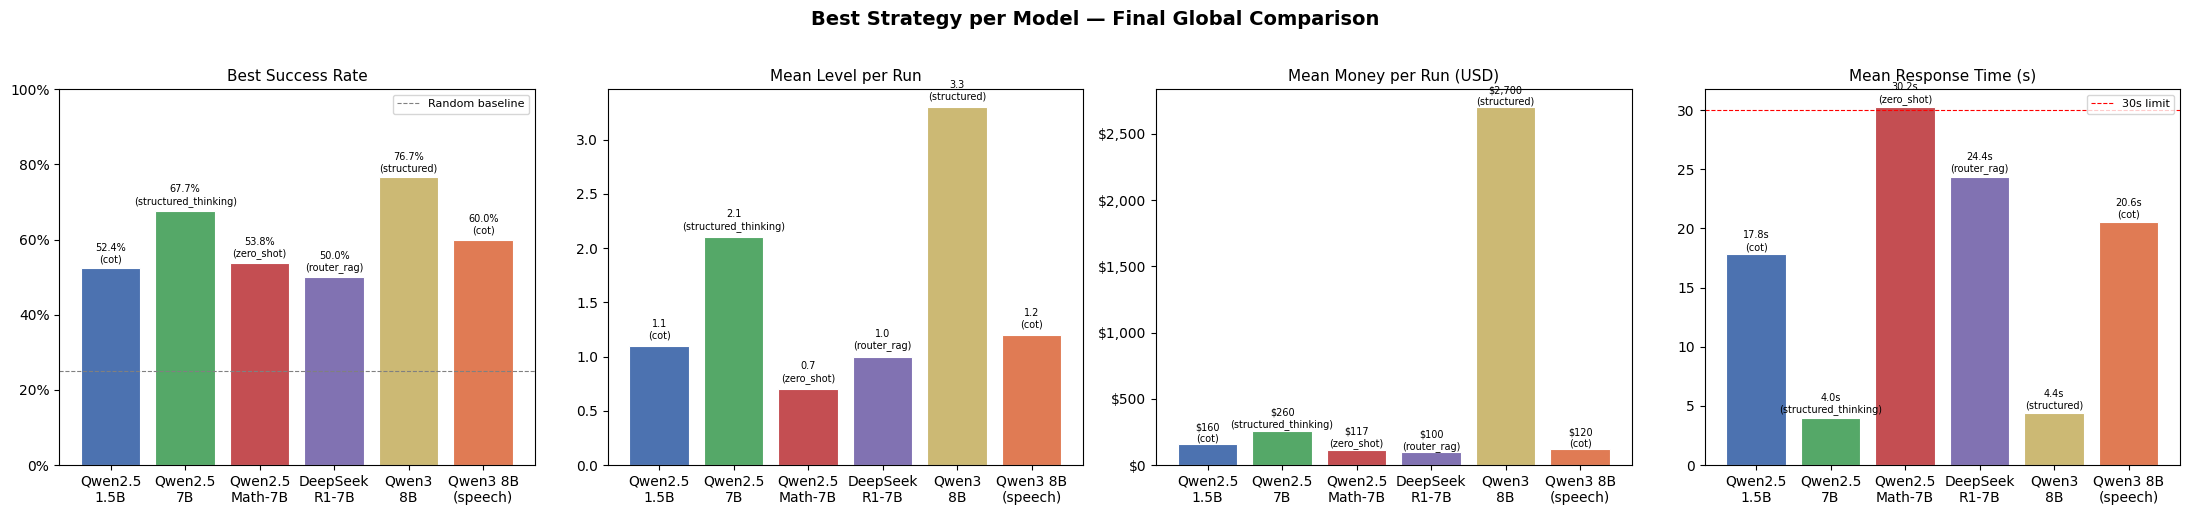

Saved: final_best_per_model.png


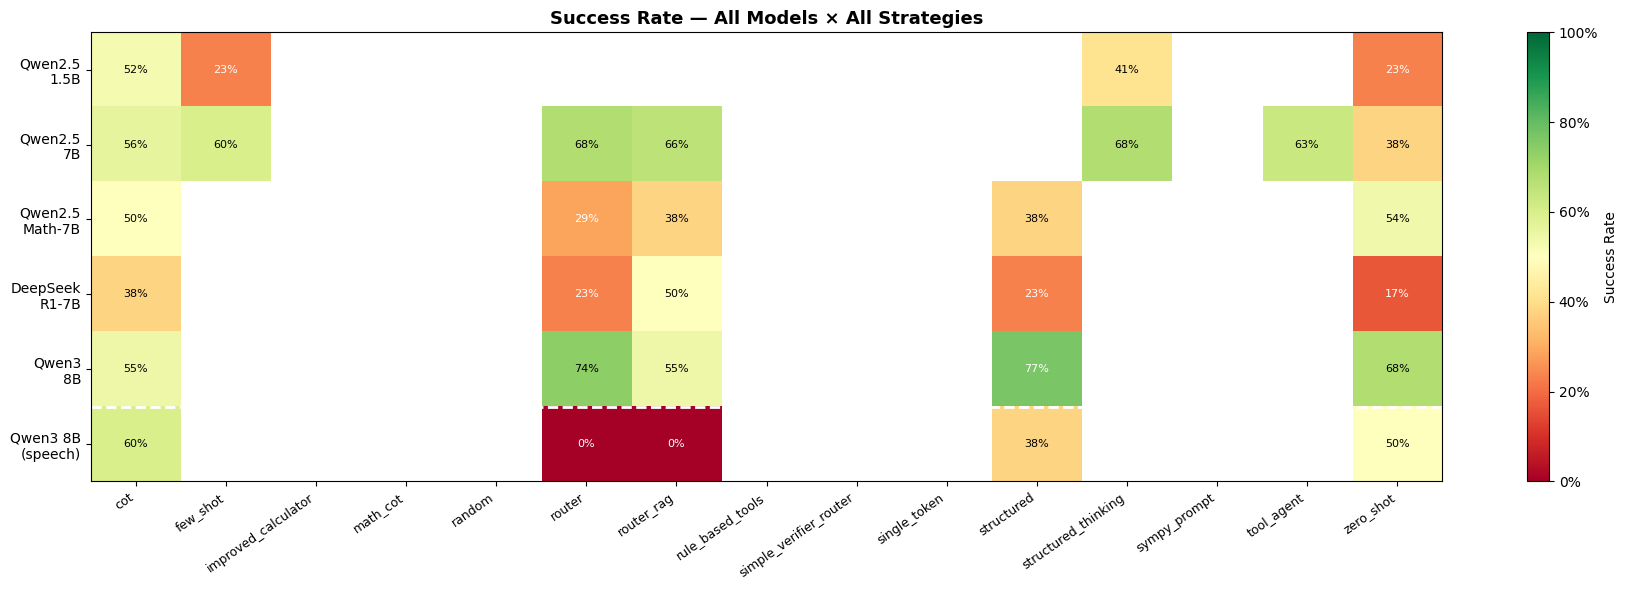

Saved: final_success_rate_heatmap.png


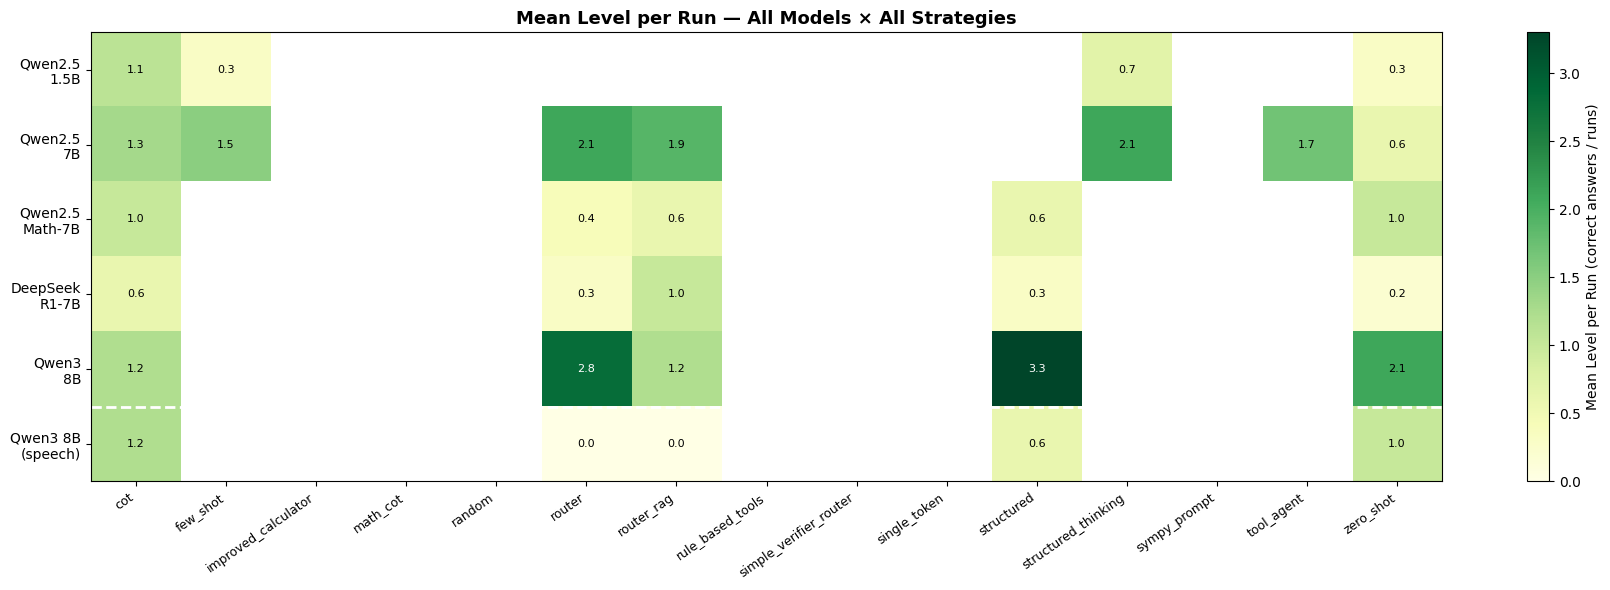

Saved: final_level_heatmap.png

# Strategy consistency across text models


,strategy,mean,std,min,max
0,structured_thinking,0.544,0.187,0.412,0.677
1,cot,0.474,0.096,0.333,0.565
2,router_rag,0.447,0.135,0.231,0.655
3,few_shot,0.416,0.261,0.231,0.600
4,zero_shot,0.415,0.194,0.167,0.677
5,router,0.399,0.281,0.000,0.737
6,structured,0.312,0.259,0.000,0.767


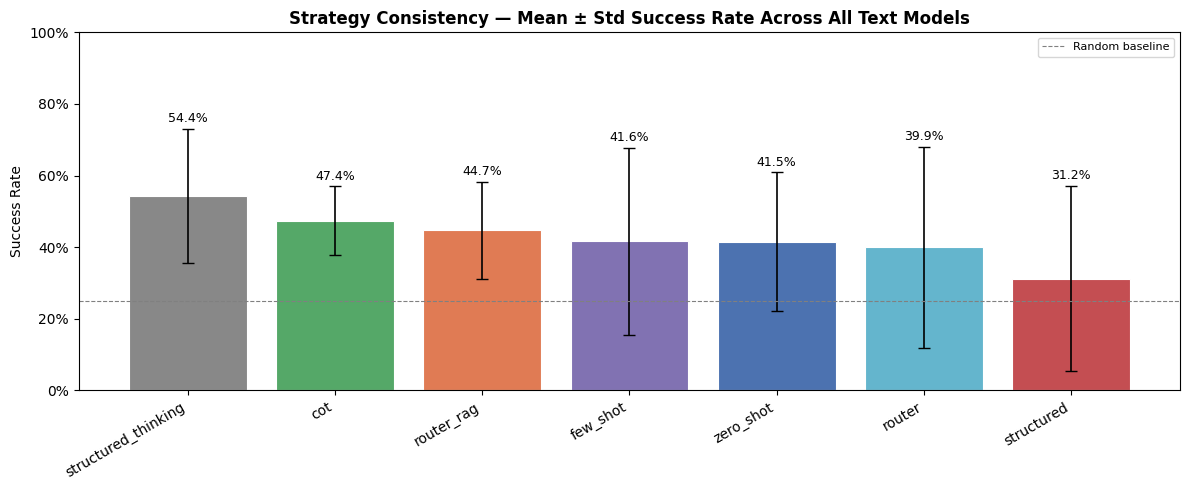

Saved: final_strategy_consistency.png


TypeError: argument of type 'float' is not iterable

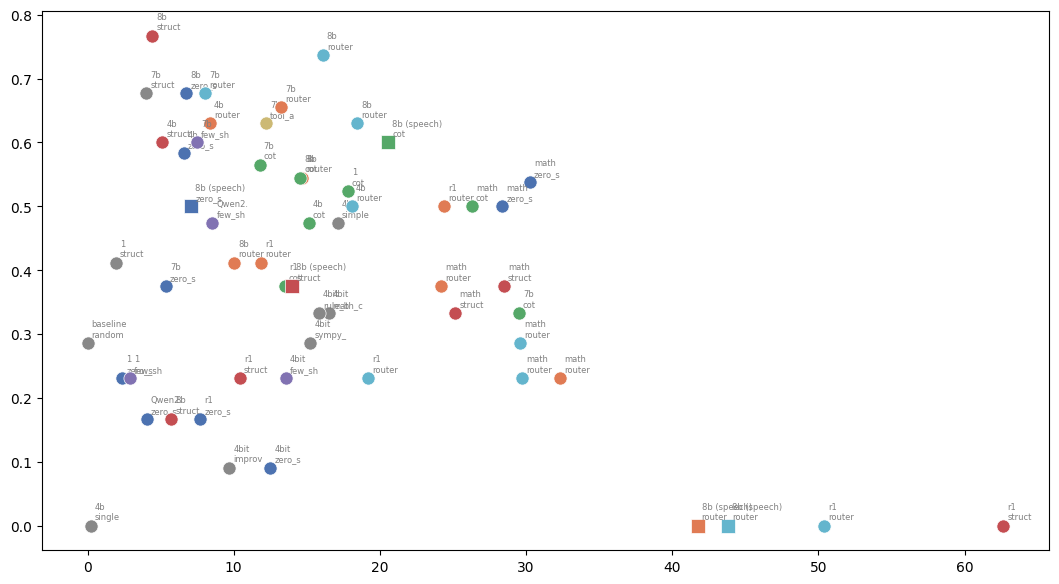

In [ ]:
# Final global comparison — all models, all strategies, all modes.
# Loads all saved CSVs including speech.

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


# ── Load everything ───────────────────────────────────────────────────────────

df_text = load_all_results(RESULTS_DIR)

speech_files = (
    list(RESULTS_DIR.glob("qwen3_8b__speech_*__speech_results.csv")) or
    [RESULTS_DIR / "qwen3_8b__speech_all_strategies.csv"]
)
speech_frames = [pd.read_csv(p) for p in speech_files if p.exists()]

if speech_frames:
    df_sp                  = pd.concat(speech_frames, ignore_index=True).drop_duplicates()
    df_sp["model_name"]    = df_sp["model_name"].astype(str) + " (speech)"
    df_sp["mode"]          = "speech"
    df_all = pd.concat([df_text, df_sp], ignore_index=True)
    print(f"Text rows   : {len(df_text)}")
    print(f"Speech rows : {len(df_sp)}")
else:
    df_all = df_text.copy()
    print("No speech files found — text only.")

print(f"Total rows  : {len(df_all)}")
# Fix: ensure model names are strings and drop NaN before sorting to avoid TypeError
unique_models = [str(m) for m in df_all['model_name'].unique() if pd.notna(m)]
print(f"Models      : {sorted(unique_models)}")


# ── Compute summary with mean_correct_per_run ─────────────────────────────────

summary = summarize_runs(df_all)
# summarize_runs already contains mean_correct_per_run = total_correct / runs

print(f"\n# Complete summary — all models all strategies")
display(summary[[
    "model_name", "strategy", "runs", "total_questions",
    "total_correct", "success_rate", "mean_correct_per_run",
    "mean_money_per_run", "best_money_per_run", "mean_response_time",
]].sort_values(["model_name", "success_rate"], ascending=[True, False]))


# ── Full leaderboard — top 20 model-strategy combinations ────────────────────

leaderboard = (
    summary[["model_name", "strategy", "success_rate",
              "mean_correct_per_run", "mean_money_per_run",
              "best_money_per_run", "mean_response_time"]]
    .sort_values("success_rate", ascending=False)
    .reset_index(drop=True)
)
leaderboard.index += 1

print("\n# Full leaderboard — all model-strategy combinations")
display(leaderboard.head(20))


# ── Model and strategy order ──────────────────────────────────────────────────

text_model_order = [
    "qwen_1_5b", "qwen_7b", "qwen_math_7b",
    "deepseek_r1_qwen_7b", "qwen3_8b",
]
text_model_labels = [
    "Qwen2.5\n1.5B", "Qwen2.5\n7B", "Qwen2.5\nMath-7B",
    "DeepSeek\nR1-7B", "Qwen3\n8B",
]

all_model_order = text_model_order + (
    ["qwen3_8b (speech)"] if speech_frames else []
)
all_model_labels = text_model_labels + (
    ["Qwen3 8B\n(speech)"] if speech_frames else []
)

strategy_palette = {
    "zero_shot":        "#4C72B0",
    "few_shot":         "#8172B2",
    "cot":              "#55A868",
    "structured":       "#C44E52",
    "tool_agent":       "#CCB974",
    "router":           "#64B5CD",
    "router_rag":       "#E07B54",
    "speech_structured":"#C44E52",
    "speech_cot":       "#55A868",
    "speech_router":    "#64B5CD",
    "speech_router_rag":"#E07B54",
    "speech_zero_shot": "#4C72B0",
}

model_colors = ["#4C72B0", "#55A868", "#C44E52",
                "#8172B2", "#CCB974", "#E07B54"]


# ═══════════════════════════════════════════════════════════════════════════
# PLOT 1 — Best strategy per model: 4-metric bar chart
# ═══════════════════════════════════════════════════════════════════════════

best_per_model = (
    summary.sort_values("success_rate", ascending=False)
    .groupby("model_name", sort=False)
    .first()
    .reset_index()
    .set_index("model_name")
    .reindex(all_model_order)
    .reset_index()
)

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
fig.suptitle("Best Strategy per Model — Final Global Comparison",
             fontsize=14, fontweight="bold", y=1.02)

cols_meta = [
    ("success_rate",       "Best Success Rate",         True,  None),
    ("mean_correct_per_run","Mean Level per Run",        False, None),
    ("mean_money_per_run", "Mean Money per Run (USD)",   False, "$"),
    ("mean_response_time", "Mean Response Time (s)",     False, None),
]

for ax, (col, title, is_pct, fmt) in zip(axes, cols_meta):
    vals  = best_per_model[col].fillna(0).values
    clrs  = model_colors[:len(all_model_order)]
    bars  = ax.bar(all_model_labels, vals, color=clrs,
                   edgecolor="white", linewidth=0.8)
    ax.set_title(title, fontsize=11)

    if is_pct:
        ax.set_ylim(0, 1.0)
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
        ax.axhline(0.25, color="gray", linestyle="--",
                   linewidth=0.8, label="Random baseline")
        ax.legend(fontsize=8)
        for bar, val, strat in zip(
                bars, vals, best_per_model["strategy"].fillna("")):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.01,
                    f"{val:.1%}\n({strat})",
                    ha="center", va="bottom", fontsize=7)
    elif fmt == "$":
        ax.yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda x, _: f"${x:,.0f}")
        )
        for bar, val, strat in zip(
                bars, vals, best_per_model["strategy"].fillna("")):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 2,
                    f"${val:,.0f}\n({strat})",
                    ha="center", va="bottom", fontsize=7)
    elif col == "mean_response_time":
        ax.axhline(30, color="red", linestyle="--",
                   linewidth=0.8, label="30s limit")
        ax.legend(fontsize=8)
        for bar, val, strat in zip(
                bars, vals, best_per_model["strategy"].fillna("")):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.2,
                    f"{val:.1f}s\n({strat})",
                    ha="center", va="bottom", fontsize=7)
    else:
        for bar, val, strat in zip(
                bars, vals, best_per_model["strategy"].fillna("")):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.05,
                    f"{val:.1f}\n({strat})",
                    ha="center", va="bottom", fontsize=7)

plt.tight_layout()
plt.savefig(BASE_DIR / "final_best_per_model.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: final_best_per_model.png")


# ═══════════════════════════════════════════════════════════════════════════
# PLOT 2 — Success rate heatmap: all models × all strategies
# ═══════════════════════════════════════════════════════════════════════════

pivot_sr = (
    summary.pivot_table(
        index="model_name", columns="strategy",
        values="success_rate", aggfunc="max"
    )
    .reindex(all_model_order)
)

fig, ax = plt.subplots(figsize=(18, 6))
data = pivot_sr.values.astype(float)
im   = ax.imshow(data, aspect="auto", cmap="RdYlGn", vmin=0.0, vmax=1.0)
ax.set_xticks(range(len(pivot_sr.columns)))
ax.set_xticklabels(pivot_sr.columns, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(len(all_model_order)))
ax.set_yticklabels(all_model_labels, fontsize=10)
ax.set_title("Success Rate — All Models × All Strategies",
             fontsize=13, fontweight="bold")
plt.colorbar(im, ax=ax, label="Success Rate",
             format=mticker.PercentFormatter(xmax=1.0))
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        val = data[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.0%}", ha="center", va="center",
                    fontsize=8,
                    color="black" if 0.3 < val < 0.75 else "white")
if speech_frames:
    ax.axhline(len(text_model_order) - 0.5, color="white",
               linewidth=2, linestyle="--")
plt.tight_layout()
plt.savefig(BASE_DIR / "final_success_rate_heatmap.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: final_success_rate_heatmap.png")


# ═══════════════════════════════════════════════════════════════════════════
# PLOT 3 — Mean level per run heatmap: all models × all strategies
# ═══════════════════════════════════════════════════════════════════════════

pivot_lvl = (
    summary.pivot_table(
        index="model_name", columns="strategy",
        values="mean_correct_per_run", aggfunc="max"
    )
    .reindex(all_model_order)
)

fig, ax = plt.subplots(figsize=(18, 6))
data_l = pivot_lvl.values.astype(float)
vmax_l = np.nanmax(data_l) if not np.all(np.isnan(data_l)) else 10
im2    = ax.imshow(data_l, aspect="auto", cmap="YlGn",
                   vmin=0.0, vmax=vmax_l)
ax.set_xticks(range(len(pivot_lvl.columns)))
ax.set_xticklabels(pivot_lvl.columns, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(len(all_model_order)))
ax.set_yticklabels(all_model_labels, fontsize=10)
ax.set_title("Mean Level per Run — All Models × All Strategies",
             fontsize=13, fontweight="bold")
plt.colorbar(im2, ax=ax,
             label="Mean Level per Run (correct answers / runs)")
for i in range(data_l.shape[0]):
    for j in range(data_l.shape[1]):
        val = data_l[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.1f}", ha="center", va="center",
                    fontsize=8,
                    color="black" if val < vmax_l * 0.7 else "white")
if speech_frames:
    ax.axhline(len(text_model_order) - 0.5, color="white",
               linewidth=2, linestyle="--")
plt.tight_layout()
plt.savefig(BASE_DIR / "final_level_heatmap.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: final_level_heatmap.png")


# ═══════════════════════════════════════════════════════════════════════════
# PLOT 4 — Strategy consistency: success rate across all models per strategy
# ═══════════════════════════════════════════════════════════════════════════

# For text models only — strategies that appear in at least 2 models
text_summary = summary[summary["model_name"].isin(text_model_order)].copy()
strat_counts = text_summary.groupby("strategy")["model_name"].nunique()
common_strats = strat_counts[strat_counts >= 2].index.tolist()

strat_consistency = (
    text_summary[text_summary["strategy"].isin(common_strats)]
    .groupby("strategy")["success_rate"]
    .agg(mean="mean", std="std", min="min", max="max")
    .round(3)
    .sort_values("mean", ascending=False)
    .reset_index()
)

print("\n# Strategy consistency across text models")
display(strat_consistency)

fig, ax = plt.subplots(figsize=(12, 5))
x      = np.arange(len(strat_consistency))
means  = strat_consistency["mean"].values
stds   = strat_consistency["std"].fillna(0).values
s_clrs = [strategy_palette.get(s, "#888888")
          for s in strat_consistency["strategy"]]

bars = ax.bar(x, means, color=s_clrs, edgecolor="white", linewidth=0.8)
ax.errorbar(x, means, yerr=stds, fmt="none", color="black",
            capsize=4, linewidth=1.2)
ax.set_title("Strategy Consistency — Mean ± Std Success Rate Across All Text Models",
             fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(strat_consistency["strategy"],
                   rotation=30, ha="right")
ax.set_ylabel("Success Rate")
ax.set_ylim(0, 1.0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.axhline(0.25, color="gray", linestyle="--", linewidth=0.8,
           label="Random baseline")
ax.legend(fontsize=8)
for bar, val, std in zip(bars, means, stds):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + std + 0.01,
            f"{val:.1%}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(BASE_DIR / "final_strategy_consistency.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: final_strategy_consistency.png")


# ═══════════════════════════════════════════════════════════════════════════
# PLOT 5 — Speed vs accuracy scatter: every model-strategy combination
# ═══════════════════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(13, 7))

for _, row in summary.iterrows():
    if pd.isna(row["success_rate"]) or pd.isna(row["mean_response_time"]):
        continue
    model  = row["model_name"]
    strat  = row["strategy"]
    color  = strategy_palette.get(strat, "#888888")
    marker = "s" if "(speech)" in model else "o"
    ax.scatter(row["mean_response_time"], row["success_rate"],
               color=color, marker=marker, s=90,
               edgecolors="white", linewidths=0.5, zorder=3)
    ax.annotate(
        f"{model.split('_')[1] if '_' in model else model[:6]}\n{strat[:6]}",
        (row["mean_response_time"], row["success_rate"]),
        fontsize=6, ha="left", va="bottom",
        xytext=(3, 3), textcoords="offset points", color="gray",
    )

ax.axvline(30, color="red", linestyle="--", linewidth=0.8,
           label="30s time limit")
ax.axhline(0.25, color="gray", linestyle="--", linewidth=0.8,
           label="Random baseline (25%)")
ax.set_xlabel("Mean Response Time (seconds)", fontsize=11)
ax.set_ylabel("Success Rate", fontsize=11)
ax.set_title("Speed vs Accuracy — Every Model-Strategy Combination\n"
             "(circles = text mode, squares = speech mode)",
             fontsize=12, fontweight="bold")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))

# Legend for strategies
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor=c, markersize=8, label=s)
    for s, c in strategy_palette.items()
    if s in summary["strategy"].values
]
legend_elements += [
    Line2D([0], [0], marker="o", color="gray", markersize=8,
           label="text mode"),
    Line2D([0], [0], marker="s", color="gray", markersize=8,
           label="speech mode"),
]
ax.legend(handles=legend_elements, bbox_to_anchor=(1.01, 1),
          loc="upper left", fontsize=7, title="Strategy / Mode")

plt.tight_layout()
plt.savefig(BASE_DIR / "final_speed_vs_accuracy.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: final_speed_vs_accuracy.png")


# ═══════════════════════════════════════════════════════════════════════════
# PLOT 6 — Mean money per run heatmap
# ═══════════════════════════════════════════════════════════════════════════

pivot_money = (
    summary.pivot_table(
        index="model_name", columns="strategy",
        values="mean_money_per_run", aggfunc="max"
    )
    .reindex(all_model_order)
)

fig, ax = plt.subplots(figsize=(18, 6))
data_m = pivot_money.values.astype(float)
vmax_m = np.nanmax(data_m) if not np.all(np.isnan(data_m)) else 1000
im3    = ax.imshow(data_m, aspect="auto", cmap="YlOrRd",
                   vmin=0.0, vmax=vmax_m)
ax.set_xticks(range(len(pivot_money.columns)))
ax.set_xticklabels(pivot_money.columns, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(len(all_model_order)))
ax.set_yticklabels(all_model_labels, fontsize=10)
ax.set_title("Mean Money per Run (USD) — All Models × All Strategies",
             fontsize=13, fontweight="bold")
plt.colorbar(im3, ax=ax, label="Mean Money per Run ($)")
for i in range(data_m.shape[0]):
    for j in range(data_m.shape[1]):
        val = data_m[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"${val:,.0f}", ha="center", va="center",
                    fontsize=7,
                    color="black" if val < vmax_m * 0.6 else "white")
if speech_frames:
    ax.axhline(len(text_model_order) - 0.5, color="white",
               linewidth=2, linestyle="--")
plt.tight_layout()
plt.savefig(BASE_DIR / "final_money_heatmap.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: final_money_heatmap.png")


# ═══════════════════════════════════════════════════════════════════════════
# Final summary statistics
# ═══════════════════════════════════════════════════════════════════════════

overall_best     = leaderboard.iloc[0]
best_text        = leaderboard[~leaderboard["model_name"].str.contains("speech")].iloc[0]
best_speech_row  = leaderboard[leaderboard["model_name"].str.contains("speech")]
best_speech_val  = best_speech_row.iloc[0] if not best_speech_row.empty else None

most_consistent  = strat_consistency.iloc[0]
fastest_good     = (
    summary[
        (summary["success_rate"] >= 0.5) &
        (~summary["model_name"].str.contains("speech"))
    ]
    .sort_values("mean_response_time")
    .iloc[0]
    if len(summary[summary["success_rate" ] >= 0.5]) > 0 else None
)

print(f"""
{'='*65}
FINAL GLOBAL SUMMARY
{'='*65}

Total experiments      : {len(summary)} model-strategy combinations
Total questions played : {int(summary['total_questions'].sum()):,}
Total runs             : {int(summary['runs'].sum()):,}

BEST OVERALL (text mode)
  Model    : {best_text['model_name']}
  Strategy : {best_text['strategy']}
  Success  : {best_text['success_rate']:.1%}
  Level    : {best_text['mean_correct_per_run']:.1f} correct/run
  Money    : ${best_text['mean_money_per_run']:,.0f}/run
  Time     : {best_text['mean_response_time']:.1f}s/question
""" + (f"""
BEST SPEECH MODE
  Model    : {best_speech_val['model_name']}
  Strategy : {best_speech_val['strategy']}
  Success  : {best_speech_val['success_rate']:.1%}
  Money    : ${best_speech_val['mean_money_per_run']:,.0f}/run
""" if best_speech_val is not None else "") + f"""
MOST CONSISTENT STRATEGY (across text models)
  Strategy : {most_consistent['strategy']}
  Mean SR  : {most_consistent['mean']:.1%}
  Std SR   : {most_consistent['std']:.1%}
""" + (f"""
FASTEST WITH ≥50% SUCCESS RATE
  Model    : {fastest_good['model_name']}
  Strategy : {fastest_good['strategy']}
  Time     : {fastest_good['mean_response_time']:.1f}s/question
  Success  : {fastest_good['success_rate']:.1%}
""" if fastest_good is not None else "") + f"""
{'='*65}
""")